# Assignment 2 - Gradient Boosting meets NZ Inflation



### Student Name: John Balint Lavack
### Student ID: 20001249

No artificial intelligence was used in this assignment for any purpose.

Note: I have some major errors with my python environment during this assessment causing me to have to reinstall it. Some of the code may throw errors if you run it. I haven't had the heart to re-run the whole book in case it fails. Luckily I used checkpoints to save the data into files.

In [12]:
%load_ext autoreload
%reload_ext autoreload
%autoreload

# %pip install fitter #for decay stuff
# !pip install seaborn --upgrade
# !pip install -U scikit-learn

In [6]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import time
import math as math
import seaborn as sns
import datetime as dt
import scipy.stats as st
from pylab import rcParams
import scipy.interpolate as inter
from sklearn.tree import DecisionTreeRegressor
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import sklearn.model_selection as modsel
import sklearn.metrics as metrics
from sklearn.preprocessing import OneHotEncoder
from scipy.optimize import minimize #for huber loss minimisation
import random as random
from sklearn.preprocessing import StandardScaler
import operator
# from scipy.integrate import simps
from tabulate import tabulate
import calendar
from calendar import monthrange
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.feature_selection import RFECV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from scipy import signal
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from scipy.signal import correlate, correlation_lags
import matplotlib.colors as mcolors
from statsmodels.tsa.filters.filtertools import convolution_filter
import matplotlib.dates as mdates
from sklearn.feature_selection import RFECV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from scipy.stats import rankdata, norm
from scipy import signal
from scipy.fft import fft, fftfreq, ifft
from scipy.signal import find_peaks
from sklearn.ensemble import RandomForestRegressor
from scipy import linalg
import matplotlib.dates as mdates
from scipy.cluster.vq import whiten
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
# from pmdarima.arima import auto_arima
from sklearn.base import BaseEstimator, RegressorMixin

# Index

[Functions](#Functions)
* [Gradient Boost Class](#Gradient-Boost-Class)
* [MLP Class](#MLP-Class)
* [XGBoost class](#XGBoost-tree-booster-class)
* [Feature selection](#Feature-Selection)
* [Feature Engineering](#Feature-Engineering)
* [Timeseries Validation](#Timeseries-Validation)
* [Plot Functions](#Plot-Functions)


[Task 1: GRADIENT BOOSTING IMPLEMENTATION.](#Task-1:-GRADIENT-BOOSTING-IMPLEMENTATION)
* [1.1. Implement Gradient Boosting Algorithm.](#Task-1.1:-Implement-Gradient-Boosting-Algorithm)  
* [1.2. Adjust the Loss Function.](#Task-1.2-Adjust-the-Loss-Function)
* [1.3. Adjust Weak Learner Type.](#Task-1.3-Adjust-Weak-Learner-Type)
    * [1.3.1. Decision Tree](#1.3.1-Decision-Tree:)  
    * [1.3.2. Multi Layered Perception](#1.3.2-Multi-Layered-Perception-(Neural-Network):)
    * [1.3.4. XG Boost](#1.3.3-XGBOOST:)
* [1.4. Modify the Learning Rate Schedule](#Task-1.4-Modify-the-Learning-Rate-Schedule)
* [1.5. Early stopping](#Task-1.5-Early-Stopping:)

[TASK 2: GRADIENT BOOSTING IN-CLASS FORECASTING COMPETITION](#TASK-2:-GRADIENT-BOOSTING-IN-CLASS-FORECASTING-COMPETITION)
* [2.1. Exploratory Data Analysis](#Task-2.1-Exploratory-Data-Analysis)
* [2.2. Feature Selection](#Task-2.2-Feature-Selection.)
* [2.3. Feature Engineering](#Task-2.3-Feature-Engineering.)
* [2.4. Model Fitting](#Task-2.4-Model-Fitting.)
* [2.4.1 Model Experiments](#2.4.1-Model-Experiments)
* [2.5. Grid Search](#Task-2.5.-Grid-Search)
* [2.6. Final Model](#Task-2.6.-Final-Model)
* [2.7. Walk Forward Validation](#Task-2.7.-Walk-Forward-Validation)
* [2.8. File output](#Task-2.8.-File-Output)
* [2.9. Forecast Q3 2025](#Task-2.9.-Forecast-Q3-2025)

[Task 3: EXPERIMENTATION USING A RANGE OF ALGORITHMS](#Task-3:-EXPERIMENTATION-USING-A-RANGE-OF-ALGORITHMS)
* [3.1. Model Comparison](#Task-3.1.-Model-Comparison)
* [3.2. Grid Search](#Task-3.2.-Grid-search)
* [3.3. Model Validation](#Task-3.3.-Model-Validation)
* [3.4 Other models](#Task-3.4-Other-models)

[Task 4: AWS TECHNOLOGY USAGE](#TASK-4:-AWS-TECHNOLOGY-USAGE)
* [4.1. Sage Maker](#Task-4.1.-Sage-Maker:)
* [4.2. S3 Bucket](#Task-4.2.-S3-Bucket:)
* [4.3. Model Hosting](#Task-4.3.-Model-Hosting:)

Task 5: Template completion
* [Task 1: Gradient boosting implementation](#Task-1:-Gradient-Boosting-Implementation-(25-Marks))
* [Task 2: Competition](#Task-2:-Gradient-Boosting-In-Class-NZ-Inflation-Forecasting-Competition-(35-Marks))
* [Task 3: Other algorithms](#Task-3:-NZ-Inflation-Forecasting-Competition-Using-a-Range-of-Algorithms-(10-Marks))
* [Task 4: AWS Tech](#Task-4:-AWS-Technology-Usage-(15-Marks))
* [Task 5: Reflection](#Task-5:-(15-Marks))

[Bibliography](#Bibliography)

## [Task 1: Gradient Boosting Implementation (25 Marks)](#Task-1:-GRADIENT-BOOSTING-IMPLEMENTATION)
[Back to top](#Index)

1. [Implement Gradient Boosting Algorithm: (5 marks)](#Task-1:-GRADIENT-BOOSTING-IMPLEMENTATION)
   - I managed to properly implement the simplified Gradient Boosting algorithm from class code and have demonstrated that it works by using it to fit and predict the data set on traffic usage and GDP from class. Shown by pairwise residual plots of the data, the residual fit plots, convergence plots and prediction fit plots showing the true y and the model predictions. In this question's answer I also show the fits in similar ways for different loss functions. 
   
   <a href="#TASK-1" >GB class implementation</a>
  

2. [Adjust the Loss Function: (5 marks)](#Task-1.2-Adjust-the-Loss-Function)
   - I adjusted the loss function by implementing at least TWO different types which were:
   1. Friedman MSE
   2. Mean Absolute Error
   3. Huber loss
   4. Smoothed Quantile loss
   
   - The effects vary by loss function. I viewed the loss function compared to the evaluation metric appropriate for the loss funciton. 
       1. MSE loss converges with the MSE score relatively fast. Around 10 iterations or so. With the data set used there is a suggested asymptote around 3.7 or so for both. 
       2. Friedman MSE quickly descends from on high to converge quickly around the same number as regular MSE. Albeit somewhat faster in terms of model fitting. Friedman MSE is a tad more efficient and can get to the MSE score faster, in principle, for more iterations. In my tests it dodn't work out that way over 20 iterations, but in later fits during Task 2 it did compute faster.
       3. MAE had lower initial loss and convereged quickly to 1. Seemingly asymptotic at 1. The MAE score and the MAE loss converged. MAE, perhaps because it is robust to outliers, is more stable and so looks to take longer for loss and score to converge. 
       4. Huber loss increased as the huber scoring metric decreases. They appear to need many more iterations. Being robust to outliers and piecewise about the $\gamma$ means that one can configure that $\gamma$ to perhaps find better convergence. 
       5. Quantile loss was linear. Doing poorly, neither loss nor score converging.        
   

3. [Adjust Weak Learner Type: (5 marks)](#Task-1.3-Adjust-Weak-Learner-Type)
   - I conducted an experiment with two different weak learner types within the Gradient Boosting ensemble
   - They were:
       1. [Decision Tree of adjustable depth](#1.3.1-Decision-Tree:) 
       2. [Multi Layered Perceptrons](#1.3.2-Multi-Layered-Perception-(Neural-Network):)
       3. [Xtreme Gradient boost](#1.3.3-XGBOOST:) as a bonus which I implemented out of curiosity. 
       
       
   - As a result of doing the above, I found:
       1. For decision trees, deeper trees performed very poorly. While shallower trees did better. Stump being the best. Just like with AdaBoost, more complex models result in poorer fits in the ensemble. They become 'expoert' learners. Or so it appears. Ith deep trees of 20 getting horendous fits and MSEs in the thousands. 
       2. MLP: having lots of customisability, it cna be tuned to fit better or worse. Hidden layers and epochs impactingt his the most. Again, making the model too 'clever' makes it fit worse. 
       3. Xtreme bonus: On the data set used, the XGBoost was worse than gradient boosting. It is faster to compute because the hessian is easier to work with. Mostly 1s or 0s usually. However, perhaps because of the data itself, the model was poor fitting

4. [Modify the Learning Rate Schedule: (5 marks)](#Task-1.4-Modify-the-Learning-Rate-Schedule)
   - I devised and implemented a dynamic learning rate schedule where the learning rate decreases as the number of iterations increases and found that this can be true in some cases. Usually a higher learning rate to start with, decaying to a floor does result in better fitting and faster converging models. Though this is not a given, nor can it be expected. I varies much by decay functions. 
   
   - I explored different schedules and provided a set of experiments as well as a discussion to report on my findings which were extensive. I went gang busters and implemented many decay functions. The shape of the decay function matters. This can be seen by viewing the eta history of the model. This is really a case of knowing the right tool for the job, although I did devise a novel decay function that works pretty well regardless of what one knows in advance. I'd like to call it 'PuntBoost' as in 'to take a punt' but it is perhaps more accurately called 'Adaptive Boost'.  
   
   - The trade-offs between starting with a higher learning rate versus a more conservative fixed learning rate in my experiments were primarily computational. YOu can learn faster and stop sooner if you use an aggressive decay function. Someimtes that model will stabilise it's scoring metric quickly, but this is not always a good thing. In some cases, like exponential decay or gradient decay, the model converges, but to a poor value. Meaning it may be better to more gradually decay the model from a starting point nearer the initial learning rate. Neither being too conservative nor too gung ho. 
   
5. [Implement Gradient-Based Early Stopping : (5 marks)](#Task-1.5-Early-Stopping:)
   - I managed to implement an early stopping mechanism by doing an orthodox approach of having a validation sub sample, tolerance and patience values. Wherein the model stops fitting once the loss funciton ceases to improve better than the tolerance of a period of iterations equal to the patience. Once the model stops, you then need to fit it again with the specified number of rounds, other wise the model trained and fit on less data than the full training set. 
      
   - My strategy resulted in early stopping, but the MSE was worse. around 4.04 to 3.85, and 3.9 to 3.85 when tuning the early stopping. Early stopping effectively means that we make a trade off decision on bias vs variance. It is not inherently good or bad. In fact, it is incredibly useful for Grid Search. However, what I found was that on the data I used, it was not much better than not having it. 
   
   - Since the whole point of early stopping is for regularisation, I decided to implement drop out (DARTS) and subsampling. These worked better than early stopping because they use randomness to force the model to fit differently each boosting round. As di sub sampling. Though not better than a vanilla model on the toy data set at hand. This changes in task 2, where DARTS is supreme. 
   
   
## [Task 2: Gradient Boosting In-Class NZ Inflation Forecasting Competition (35 Marks)](#TASK-2:-GRADIENT-BOOSTING-IN-CLASS-FORECASTING-COMPETITION)
[Back to top](#Index)

1. Competition Score Calculation: (20 marks)
   - I can confirm that I read the competition rules and I followed them completely.
   - I used the following datasets and original raw features from the following sources:
       * [MBIE Coal statistics](https://www.mbie.govt.nz/building-and-energy/energy-and-natural-resources/energy-statistics-and-modelling/energy-statistics/coal-statistics)
       * [MBIE Oil statistics](https://www.mbie.govt.nz/building-and-energy/energy-and-natural-resources/energy-statistics-and-modelling/energy-statistics/oil-statistics)
       * [MBIE Renewables statistics](https://www.mbie.govt.nz/building-and-energy/energy-and-natural-resources/energy-statistics-and-modelling/energy-statistics/gas-statistics)
       * [MBIE Electricity statistics](https://www.mbie.govt.nz/building-and-energy/energy-and-natural-resources/energy-statistics-and-modelling/energy-statistics/renewables-statistics)
       * [MBIE Energy prices statistics](https://www.mbie.govt.nz/building-and-energy/energy-and-natural-resources/energy-statistics-and-modelling/energy-statistics/energy-prices)
       * [MBIE Petroleum reserves data statistics](https://www.mbie.govt.nz/building-and-energy/energy-and-natural-resources/energy-statistics-and-modelling/energy-statistics/petroleum-reserves-data)
       * [RBNZ Credit card balances](https://www.rbnz.govt.nz/statistics/series/lending-and-monetary/credit-card-balances)
       * [RBNZ Credit Card Spending](https://www.rbnz.govt.nz/statistics/series/lending-and-monetary/credit-card-spending)
       * [RBNZ Prices](https://www.rbnz.govt.nz/statistics/series/economic-indicators/prices)
       * [RBNZ Consumption](https://www.rbnz.govt.nz/statistics/series/economic-indicators/consumption)
       * [RBNZ Investment](https://www.rbnz.govt.nz/statistics/series/economic-indicators/investment)
       * [RBNZ Domestic Trade](https://www.rbnz.govt.nz/statistics/series/economic-indicators/domestic-trade)
       * [RBNZ GDP](https://www.rbnz.govt.nz/statistics/series/economic-indicators/gross-domestic-product)
       * [RBNZ National Savings](https://www.rbnz.govt.nz/statistics/series/economic-indicators/national-saving)
       * [RBNZ BoPs](https://www.rbnz.govt.nz/statistics/series/economic-indicators/balance-of-payments-and-international-investment-position)
       * [RBNZ overseas trade](https://www.rbnz.govt.nz/statistics/series/economic-indicators/overseas-trade)
       * [RBNZ Housing](https://www.rbnz.govt.nz/statistics/series/economic-indicators/housing)
       * [RBNZ Population and Migrations](https://www.rbnz.govt.nz/statistics/series/economic-indicators/population-and-migration)
       * [RBNZ labour market](https://www.rbnz.govt.nz/statistics/series/economic-indicators/labour-market)
       * [RBNZ Govt bond turn over](https://www.rbnz.govt.nz/statistics/series/new-zealand-debt-securities/government-bond-turnover)
       * and pretty much all the other RBNZ ones, but they weren't worth it in the end so I won't list them. 
       
       
- [Feature Selection:](#Task-2.2-Feature-Selection.) 
    - I whittled these donw systematically. Removing those columns with no data, sparse data or only data in the test period.
    - implemented an automated Box - Jenking process ot select variables based on differenced residuals, which I repurposed to engineer lagged variables in the next section.

   
- [Feature Engineering](#Task-2.3-Feature-Engineering.)
   - I made sure that I did not cheat by accident in this competition through intentional or inadvertant data leakage by splitting the data and working in two parts when feture engineering. Hwoever, there was an issue in processing the test data as some of the transformations needed enough data to process with. So, here I first got the columns from the training data, then processesed the whole data set, then split off hte testing portion. This allowed me to have no data leakage in the test set.
   
   - I also made sure I understood what data leakage is and have discussed it in my findings as and when it came up. Mainly on feature engineering as that is when the data leakage would occur. To recap, data leakage is when training data incorporates influence from data that woulnd't be available to it under real conditions for prediction. Either data not published or available or influence from future data caused by engineering it with things such as rollling averages and back interpolation, etc. To avoid this I used data sets that are updated in a regular cadence accessible for future predictions and I split the varaibles, processing each separately. Resulting in two data sets with the same features, but where each was operated on independent of the other. During feature selection I also selected variables by only using the training data set.
 
   - To further demonstrate data leakage I had, by way of happy accident, an initial data set where I prewhitened via auto configured arima model residuals. This data set, however, had some data leakage in it. However, the ARIMA package cause a big conflict with my python environment, leading to to needing to be restarted. In short, I can't reproduce that until numpy and the ARIMA package sort out their differences. On the upside, this model shows really strong fits because of data leakage, and I have it stored as an image in the notebook as an example of what happens when there is data leakage. 
   
   - For engineering I performed the following procedures:
       - rolling mean 1 - 4 periods
       - rolling sum 1 - 4 periods
       - rolling standard deviation 1 - 4 periods
       - expanding mean 
       - expanding sum
       - expanding standard deviation
       - slope coefficiencts 1- 4 period shifts
       - percent change 1-4 periods shift
       - fourier transformation, signal, magnitude and frequency. 
       - differenced and lagged, each by 1 - 4 periods
       - All whitened using ARIMA. Some of these failed with LU decomposition, so I dropped them
       - Dropping any columns with too little variance. 
    
    - I was creative in conducting feature engineering/selection to identify the most relevant and informative features for the forecasting task. From 400+ initial variables I reduced the set to 30 important ones, then created around 760 features, selecting the 30 highest correlated to CPIyoy and then using RFE I selected the 21 most informative. It was a lengthy process, visualising them and checking their autocorrelation. Which I have not shown here do to the size the notebook would become. I did do a quick EDA and the resultant selected features were mostly from the features I thought they would be from: food, tradable inflation, petrol other variables that contribute to CPI: [Exploratory Data Analysis](#Task-2.1-Exploratory-Data-Analysis)
   
- [Model Validation](#Task-2.7.-Walk-Forward-Validation)

   - I can also confirm that I used the expanded window approach... not exaclty. My implementation can use expanding window, but I prefer walk forward sliding window. This is what I implemented and it works. 
   
   - The best MSE score generated by scikit-learn I achieved with Gradient Boosting implementation from Task 1 on the held-out test was 0.037 and this placed me first in class at the time of writing.
   
   - I entered my first MSE score on the Kaggle class Sheet by September 5 so as not to lose 5 marks and I have evidence for this... I didn't take a screen shot. Bugger. You will be able to insepct the logs to identify that I did indeed do this. 


**2. [Tuning Gradient Boosting and the Training Procedure: (15 marks)](#Task-2.4-Model-Fitting.)**

- [Model Fitting](#Task-2.4-Model-Fitting.)
    - I fit the model a few times. Trying each of the two data sets whitened under different conditions. The whitening using residuals from the seasonal decompse package provided the better features, resulting in a model with test mese of 0.037 when using the training variable residuals to predict the residuals of the test set, the recomposing them with seasonality and trend components. I noticed that the traininig MSE could be pushed down to an arbitrary small number by increaseing the iterations of the model, while the test MSE remained constant. I also noticed that having a smaller learning rate of 0.01 or smaller resulted in worse test MSE on this data set. The best being 0.3 with the huber loss function and drop out rate of 0.2.

    - I was initially sceptical of my seasonal decomposition approach. However, I re-watched the lecture and noticed that this is what was done for the toy data set on GDP and vehicle movements. This galvanised me to proceed with the approach. I have both test and train data sets, and in forecasting I will be usually predicting only a few time stpes ahead. So I see it as yusing train and test to produce the model which can predict forward one time step at a minimum.

- [Model Experiments](#2.4.1-Model-Experiments)

- 
    -  I experimented with different combinations of customisations of Gradient Boosting from Task 1 to optimise its performance with explanations and interpretations of what might be occurring. Trying out all the loss functions and visualising a number of decay functions - those that were of interest. Nothing beat the und ecayed model. The results are below:
    -  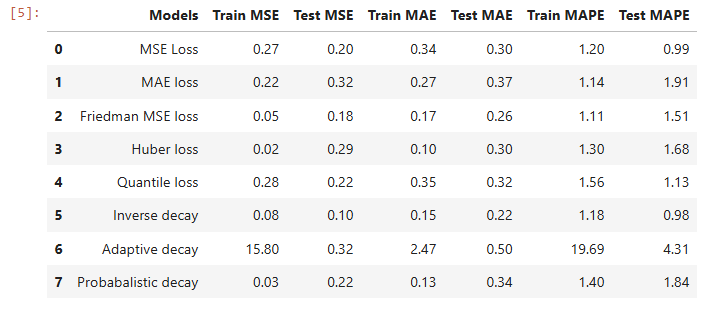
      
    - I was proactive in data acquisition and experimentation with different data inputs. I used a total of 18 features from the above listed sources. Primarily older prices data from RBNZ. 
        * 0                  CPIyoy_whitened_fourier_signal_resid
        * 1                     CPIyoy_1qrt_change_whitened_resid
        * 2                              CPIyoy_1qrt_change_resid
        * 3                              CPIyoy_3qrt_change_resid
        * 4                     CPIyoy_3qrt_change_whitened_resid
        * 5                               CPIyoy_roll_sum_2_resid
        * 6                      CPIyoy_roll_sum_2_whitened_resid
        * 7                     CPIyoy_2qrt_change_whitened_resid
        * 8                              CPIyoy_2qrt_change_resid
        * 9             Food (y/y%)_whitened_fourier_signal_resid
        * 10    Producers price index (PPI) inputs (y/y%)_whit...
        * 11                                      Oil LPG.2_resid
        * 12                          Transportation (y/y%)_resid
        * 13      Transportation (y/y%)_roll_sum_1_whitened_resid
        * 14               Transportation (y/y%)_roll_sum_1_resid
        * 15     Transportation (y/y%)_roll_mean_1_whitened_resid
        * 16                                    Food (y/y%)_resid
        * 17                      Tradable inflation (y/y%)_resid

 
    - I presented with clarity all my results by generating tables and charts, and provided lots of interpretations on how the performance of the models change with different adjustments, feature subsets problem formulations... well kind of. In the end I used two sets of data following the same engineering processes, only altering the pre-whitening. However, my conda environment crashed hard due to a bunch of package mismatches the day before submission (the jinja2 markupsafe) so I was cut off at the knees there. I was unable to reproduce earlier data sets for modelling and visualisation.
    Seen here:

    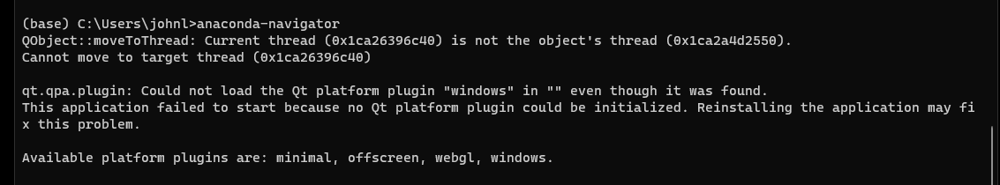

    However, I did do a lot more work and found that if I ddin't use the residuals to fit and predict the nature of the Gradient boosting algorithm removed the seasonal and trend components by being very 'either or' in the predictions. Due to the stump nature of the model. The seasonal and trend get mashed up with the reisiduals and the output is like a piecewies step function. Hence my approach to use decomposed residuals for fitting and prediction. 

    - While I used MSE as required, I also used of a variety of other performance metrics like MAE and MAPE. I found that MAPE was a more stable measure. Changing less as more estimators were added than MSE which, as I mentioned before, can be made arbitrarily small due to overfitting. 

    - I also tried to make a forecast for the NZ inflation for the third quarter in 2024 which I estimate to be 2.23. For this estimate I used all the data, both training and test to model the forecast, as this would be a real life situation - I'd have all prior data and be looking to predict only a few time steps in advance. Here I showed that my method of using seasonally decomposed data and reconstituting it can be applied to a real life situation, as one can cannibalise the seasonal and trend components of the model to predict them one step ahead. Seasonality is repeating, so is simple. Trrend a bit more difficult. With some more time I think I can make a hierarchical model that can apply more sophisticated modelling to generate trend and seasonality data many step in advance. Something like a regresson ensemble from darts. Perhaps I will leave this to a thesis. 

    - I believe I did some exceptional work like selecting 18 features from 760 engineered features, developing my own XGboost, MLP and novel decay functions, creating a model that fits very well and prediciting the Q3 CPI relatively close to a professional forecaster (Trading Econmics). I also am quite pleased with my whitening process. Which I would love to show the outputs of, but due to the aforementioned crash, I can't run any more code blocks on the fear that my whole assignment will crash. The process was the Box-Jenkins approach. First differencing the data, fitting a SARIMAX model to the residuals to find the best parameters by the BIC score of each fit, taking the best configuration to configure an ARIMA model, using those residuals and the ARIMA filter and apply it using convolution to the y variables, then running RFE with randomforest to find the most important time lags. Returning them as a data set. It takes a long time to run on 760 variables. That is for sure. And sometimes there are LU errors based on the feature. Like fourier features, due to them not being stationary. In which cases I applied another form of whitening, ZCA whitening. 
   

## [Task 3: NZ Inflation Forecasting Competition Using a Range of Algorithms (10 Marks)](#Task-3:-EXPERIMENTATION-USING-A-RANGE-OF-ALGORITHMS)
[Back to top](#Index)

1. I performed the following:
    - [Model Comparison](#Task-3.1.-Model-Comparison)
        - I compared my best GB algorithm customisation with the performance of XGBoost, LightGBM, CatBoost and the scikit-learn implementation and found SK learn GB was best with MSE of 0.01. XGB was second best with MSE of 0.02. My own implementation of XG was not far off though, MSE 0.04! 
    
    - [Grid Search](#Task-3.2.-Grid-search)
         - I used Hyperparameter Tuning where Necessary where I focused on tuning the above algorithms. They hyper parameters can be viewed under the grid search section. Generally speaking for the OOTB models deeper trees were helpful, while with my own a more shallow tree was better. The grid search improved some algortihsm, like CatBoost to MSE 0.05, and XGB to 0.07. While others worsened due to my constrained parameter space search.
         - My XGboost implementation only just managed to beat out my gradient boost implmentation by 0.01 after grid search. Hoorah!

    - [Other models](#Task-3.4-Other-models)
        - Tried some other forecasting algorithms from the darts library. Exponential smoothing, Naive forecast and regressionensemble. They performed much more poorly due to the fact that they use only the CPIyoy value to predict and because I was asking them to predict 38 periods out. Somethings they are not optimised for.

        - I thoroughly document the MSE performance over time with various tweaks and strategies and plotted them showing for the gradient boosting models on line charts under model validation: [Model Validation](#Task-3.3.-Model-Validation). Wherein you can observe the change to MSE as the model slides along the validation window. 

        - Instead of burying my MSE scores in text all over the notebook where it cannot be found and compared with other results, I instead a table at the top of the section for Task 3 to clearly display the MSE results from differnt experiments and algorithms.
     
        - 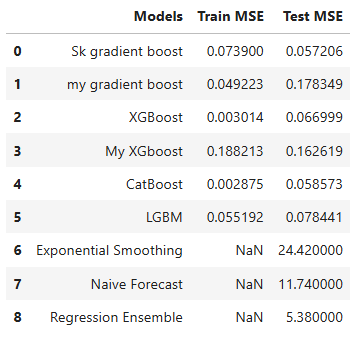
      

## [Task 4: AWS Technology Usage (15 Marks)](#TASK-4:-AWS-TECHNOLOGY-USAGE)
[Back to top](#Index)

1. I used the following AWS services in my assignment (10 Marks):
    * [4.1. Sage Maker](#Task-4.1.-Sage-Maker:)
    * [4.2. S3 Bucket](#Task-4.2.-S3-Bucket:)
    * [4.3. Model Hosting](#Task-4.3.-Model-Hosting:)

   - I wanted to use Glue, but was locked out due to the permission restrictions on the learning account
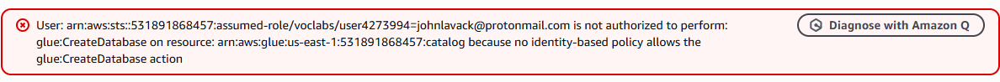


3. Below is a screenshot showing how far I have progressed in my AWS Academy set course (5 Marks):

   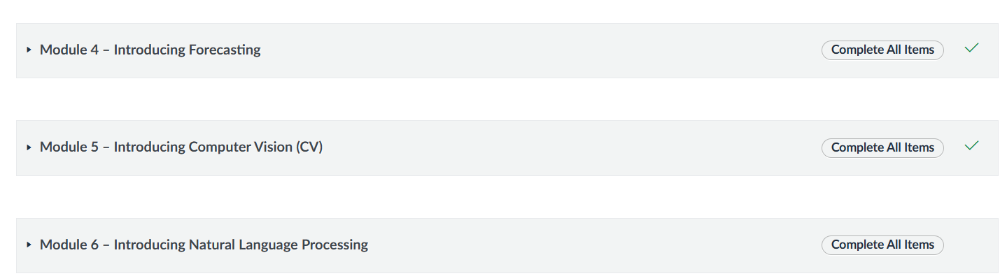

## Task 5: (15 Marks)
[Back to top](#Index)

1. List and discuss three most important things that you learned in this assignment:
    - Timeseries prediction is annoying. Date indexs are annoying. Seasonal and trend components are annoying. It's all just three times moreannoying than reugular data. I did find that using residuals only for the model and reconstituting it with trend and seasonality post fit was a very good way to get really good predictions. One must be careful here to avoid data leakage. Taking this approach means I can focus solely on residuals, which is somewhat is the vein of gradient booosting, I suppose. For the final part of the task 2 where I need to predict the next time step, this approach is on. I can use all the data at hand, so I can seasonally decompose all I want. I thought this was a novel idea again, but it turns out ThymeBoost bet me to the punch. 
       
    - A lot about loss functions and deacy and hessians. It was thanks to these that I came up with the idea to do the adaptive boost decay, which also led me to think about probabalistic decay, which led me to learn about BetaBoost which uses a beta dsitribution. I like Bayesian approaches to things because I find them more intuitive, if difficult to express to people who don't grasp probabilitiy distributions very well. Which I suppose is why I am not an educator. It was also learning about these that made me cotten onto the idea of Huber loss being good for timeseries data like the CPI with jagged outlies all over the place. And that seemed to work. I breifly entertained quantile loss as being good at this too, but it proved rubbish, being more about risk as I interpret it than prediction of actual values.
    I would like to explore the adaptive boost model further, perhaps find better ways to adapt the decay. 
    
    - Learning about graident boosting was useful. Thogh not as useful as implementing XGboost by myself and my MLPBoost. That was a lot of work, but helped. I haven't implemented a MLP from scratch in python before, only C++. My logic was that they both use trees of a kind. And trees can be stumps... Particularly MLPBoost. Although it wasn't used much it can be powerful as it can 'immitate' variability quite well. This though led me onto another few thoughs that I'd like to explore further, perhaps as part of a thesis or something. 
        1. can I create a model where each 'boost' evaluates the data on the each threshold by a series of different algorithms and picks the best one for that split, going at each round with a different select of models for each split of the threshold. Maybe KNN and MLP on one side, then tree and linear on the other and so on. I'd call this Frankenstien Boost when I get around to it.
        2. Timeseries data that is complex, like the economic ones, are difficult to predict far in advance because of shocks in the economy which do not come from the same processes that the data observed comes from. There are many processes at play, and at any given time the mix will vary. The data is only the measurement. We don't know what processes were ascendent and which not. Or if a new one unknonwn of is suddenly afoot. However, we can predict pretty well the time between events. For example in the UK a Poisson model can pretty accurately predict how many murders there will be and the time between them. This is due to the law of large numbers and the variability becoming so much, that we needn't know a lot about it to find a data space to encompase all of it. Provided we have data for it. We can to some extend predict shocks. So a good mdoel for this sort of thing would be hierarchical to some degree. Providing the likelihood of a shock and the range of probable values with their probability. Here I go sounding like a Bayesian again. A hierarchical model that could model to some degree shocks and apply them to the predictions may perform well. Or so my thinking goes. The model I fit is kind of cheating a more pure approach based on reasoning because it learns thsi variability moment by moment and cares not about the shocks. Which means it can never predict a shock. It is expecting things to be not so different from the previous step. This is because there is very little likelihood that the next big shock is going ot be captured in the features of the model. However, we don't need those feature to know there will be one. Some model like Poisson or extreme values theory models (EVT) may do better. So XG boost and its friends are good models, but they don't satisfy my itch
    

2. List and discuss three things that you did well in this assignment:
    - I definitely built a good model incorporating MLP decision tree and capable of doing xtreme gradient boosting. I think the work shows and the code is good. 
    - I am particularly stoked with the adaptive eta decay rate I created which alters the gradient descent decay of each data point, then provides a posterior distribution for the eta after the fitting has occured. This approach is entirely novel as far as I am aware, and yeilds pretty decent fits. 
    - Using seasonally decoposed data for training helped find good predictors and features. However, since many features are dropped, it was kind of pointelss in the end to do the fourier transforms. I spent a lot of time messing around with the tsfresh package, pytimetk and sf-forecast, none of which bore fruit. Meaning I had to figure this out myself. In the end this was helpful. 

3. List and discuss three most things that you think you could have done differently and imporved in this assignment:
    - This assignment was again massive. I am/was in the process of the final days of a massive software build which kept me stressed and occupied. I have an infant son. Ditto. I am organising my older son's rugby club trip to the Taupo rugby festival which makes me unable to submit on the 22nd. I am rennovating the house. I also have a wife to give attention to. And this assignment it the size of the Fat Man. It was all huge and I think again, about 50% was pointless work. In any case I had a lot of code to write and execute and debug which kept me up till past midnight every night for about a month and made me a stranger to my family. And a few bugs caused by package incompatabilities nearly led me to break down. This is partially due to me going whole hog on the MLP and Xtreme gradient boosting implementations, doing more than the required amount of work here.
     - Additionally, this assignment was again massive. The AWS portion is entirely pointless as an assignment. Task 3, I also think is too much. Doing task 2 again but with more models and for less marks? Why? And the reflection is pointless. I am not doing some social studies course. It is all a bit much. Task 1 is an assignment worht 20% on its own. Task 2 makes sense as another assignment, perhaps a capstone for the course after doing a few smaller assignments to get various custom model implementations to work.
     - The AWS environment is just a headache that needn't be. It blocked me from using Glue and S3 this time. I can't use the autopilot for the assignment... it's a bloody mess. Get this sorted out and buy a proper instance that can be used for this course. Otherwise I can't learn jack from it. 
    
    - I went about this using seasonally decomposed data, both test and train. I found when not doing so the predictions were a mess. However, there was lots of confusion when making the data splits and I had to retrace my steps to avoid data leakage. Due in part to my clumsy handling of dates. First time through I inadvertednly had data leakage because I processed the data as one set, bith X training and test data. Which I then had to re-do after splitting. By this time the whole assignment was pretty much written up. I had a bit of a melt down (see item 1). 
    
    - I had a bit of a crash with the pre-whitened data set. Which I deem to be OK because it wasn't the best data set, but which I am not sure if I managed to fix. The situation is that the auto_arima package uses Numpy of version <2.0, but all other packages (or most) use numpy version 2.0 or higher. So I can't do both and had to dance around the kernal to get it to work. Just as well it wasn't the better data set. This means that the notebook can't be run in a single go. You need to run it to a point. Then restart the kernal, change the packages and run it agin. If I had more time I would try figure out how to get the packages to work together. 

# Functions
[Back to top](#Index)

## Helper Function

In [7]:
colors = ['#FFD700', '#008080']  # Teal to Gold
pos = [0.0, 1.0]
cmap = mcolors.LinearSegmentedColormap.from_list("", list(zip(pos, colors))) 
# cmap = sns.diverging_palette(220, 10, as_cmap=True)

In [8]:
def conv_date(x):
    return dt.datetime.strptime(x, '%Y.%m') + pd.offsets.MonthEnd(1)

def slope_coeffs(x, s):
    slopes = (x - x.shift(s)) / s
    slopes = slopes.fillna(0)
    return slopes

def fit_spline(x_col, y_col, df, predict_col):
    df_res = pd.DataFrame(pd.date_range(df.quarter.iloc[0], df.quarter.iloc[len(df)-1], freq='M'), columns=['date'])
    df_res = df_res.reset_index().set_index('date')
    df_res.rename(columns={'index':x_col}, inplace=True)
    df_res['y'] = df.set_index('quarter')[y_col]
    sns.set_style("whitegrid")
    plt.figure(figsize=(6 * 10, 16))
    plt.xticks(fontsize=30)
    plt.yticks(fontsize=30)
    plt.ylabel('GDP Change',fontsize=50)
    plt.title('GDP Function Fit (Spline)',fontsize=50)
    df = df[[x_col, y_col]].dropna()
    spline_fit = inter.InterpolatedUnivariateSpline (df[x_col].iloc[1:].values, df[y_col].iloc[1:].values, k=5)
    df_res[predict_col] = spline_fit(df_res.x)
    plt.scatter(df_res['2001-03':].index, df_res['2001-03':].y, s=500)
    plt.plot(df_res['2001-03':][predict_col], 'r')

    return df_res[[predict_col]]

In [9]:
#for some reason, testing_preds is storing many times the predicitons in it. But they are duplicated. So we need to trim them back. 
def remove_duplicates_arrays(lst):
    filtered_list = [item for item in lst if len(item) ==35]
    seen = set()
    result = []
    for item in filtered_list:
        tupled = tuple(item)
        if tupled not in seen:
            seen.add(tupled)
            result.append(item)
    return result


## Gradient Boost Class
[Back to top](#Index)

I managed ot make some efficient code with list comprehension, newly learnt. Then read up on Sklearn's API and made the GBoost model work within it. This will save a lot of time using CV and Grid search. 

In [13]:
%autoreload
class GBoost(BaseEstimator, RegressorMixin):
    def __init__(self, learning_rate = 0.5, classifier = 'stump', n_estimators = 10, measure = 'MSE', subsample = 1, seed = None,
                 loss_function = 'MSE', gamma = 0.5, beta = 2, iota = 1, quantile = 0.5,  
                 decay = None, decay_function = None, distribution = None, decay_steps = 1, power = 1, epsilon3 = 1e-8, omega = 0.001,
                 validation_fraction = None, patience = None, tolerance = None,
                 max_depth = 1, min_samples_split = 0, min_samples_leaf = 0,
                 hidden_layer_sizes = (10,), n_epochs = 10, activation = 'relu', optimiser = None, batch_size = None,
                 alpha = 0.01, beta2 =0.9, beta3 = 0.999, epsilon2 = 1e-8,
                 base_prediction = 0.0, objective = None, delta = 1.0, tau = 1.0, reg_gamma = 0.0, reg_alpha = 0.0, reg_lambda = 0.0,
                 colsample_bynode = 1, min_child_weight = 1.0, 
                 drop_rate = 0, timeseries = False, periods = None ):
        
        self.score_history = []
        self.classifier = classifier
        self.models = []
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.gamma = gamma #for huber loss
        self.beta = beta #for huber loss
        self.min_samples_leaf = min_samples_leaf
        self.min_samples_split = min_samples_split
        self.subsample = subsample
        self.loss_function = loss_function
        self.seed = seed
        self.measure = measure
        self.loss_history = []  #records loss for plotting
        self.initial_pred = None
        self.current_pred = None
        self.residual_history = []
        self.root = None
        self.iota = iota #smoothing factor for sigmoid, needed for quantile loss
        self.quantile = quantile #for quantile loss, between 0 and 1, but not 0 nor 1
        self.feature_importances = []
        #subsample params
        self.validation_fraction = validation_fraction
        self.validation_scores = []
        self.best_val_score = float('inf')
        self.patience = patience #(no iteration change)
        self.tolerance = tolerance
        self.best_iteration = 0
        self.no_improvement_count = 0
        #learning schedule params
        self.distribution = distribution                  #a statistical distribution for decay schedule
        self.eta_history = []
        self.eta_testing_history = []
        self.decay = decay
        self.decay_steps = decay_steps
        self.power = power
        self.decay_function = decay_function
        self.estimator_preds = [] #training preds based on current estimator
        self.testing_preds = [] #round by round predictions on test data for post hoc analysis
        self.initial_learning_rate = self.learning_rate #for exponential decay
        self.eta = [] #store list of size y, with the learning rate. For adjusting learning rate dynamically on each sample
        self.G = [] #for adaptive decay
        self.epsilon3 = epsilon3 #modified adative gradient
        self.omega = omega #final decay rate for polynomial decay
        self.test_eta = []
        #MLP params
        self.hidden_layer_sizes = hidden_layer_sizes
        self.optimiser = optimiser
        self.activation = activation
        self.alpha = alpha
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.weights = []
        self.biases = []
        self.delta_history = []
        self.weights_history = []
        self.biases_history = []
        #MLP adam
        self.beta2 = beta2
        self.beta3 = beta3
        self.epsilon2 = epsilon2
        self.m_weights = []
        self.v_weights = []
        self.m_biases = []
        self.v_biases = [] 
        #XGB params
        self.base_prediction = base_prediction
        self.delta = delta
        self.tau = tau #in MAE objective
        self.reg_gamma = reg_gamma #controls tree pruning regularisation
        self.reg_lambda = reg_lambda #L2 regularisation
        self.reg_alpha = reg_alpha #L1 penalisation score
        self.min_child_weight = min_child_weight #controls tree splitting
        self.colsample_bynode = colsample_bynode
        self.objective = objective
        self.boosters = []
        self.gradient_history = []
        self.hessian_history = []
        #D.A.R.T params
        self.drop_rate = drop_rate
        self.DART_pred = None
        self.active_models = []
        self.DART_models = []
        self.model_name = f'{self.n_estimators} {self.classifier}, $\eta_0$ = {self.learning_rate}, {self.loss_function} loss'
        #Timeseriees variables
        self.timeseries = timeseries
        self.periods = periods
        self.y_trend, self.y_season, self.y_resid = None, None, None
        self.X_trend, self.X_season, self.X_resid = None, None, None
        
        # Set random seed if provided
        if self.seed is not None:
            np.random.seed(self.seed)
        
    def _compute_residuals(self, y, y_pred): 
#         print(f'_compute_residuals: len y: {len(y)}, len y_pred {len(y_pred)}')
        if self.loss_function is 'huber': return self._huber_gradient((y - y_pred))
        else: return y - y_pred
        
    def _get_subsample(self, y): #return indices of sub sampled data
        np.random.seed(self.seed)
        return np.array(np.random.choice(len(y), size=(round(len(y) * self.subsample)), replace=False))
    
    def _initialize_predictions(self, y): #also use for leaf value
        if self.loss_function is 'MAE': return np.median(y)
        elif self.loss_function is 'huber': return self._huber_initialise_predictions(y)
        else: return y.mean()   
    
    def _huber_initialise_predictions(self, y): #to start the preds
        best_loss = float('inf')
        ip = None
        for i in y:
            y_t = self._huber_loss(i) #loss at this point
            total_loss = self._huber_loss(y - y_t) #loss across all data using that point
            if total_loss < best_loss: #minimise loss over data
                best_loss = total_loss
                ip = i                 #get minimising initial prediction         
        return ip
    
    def _seasonal_decompose_df(self, df):   
        df_trend = pd.DataFrame()
        df_seasonal = pd.DataFrame()
        df_resid = pd.DataFrame()

        for col in df.columns:
            results = seasonal_decompose(df[col].dropna(), model = 'additive', period = self.periods, extrapolate_trend='freq')
            df_trend[f'{col}_trend'] = results.trend
            df_seasonal[f'{col}_seasonal'] = results.seasonal
            df_resid[f'{col}_resid'] = results.resid
    
        return df_trend, df_seasonal, df_resid
    
    #=======================================LOSS FUNCTIONS=======================================
    def _huber_gradient(self, residuals): #transforms residuals inot a huber gradient. #change epsilon to gamma
        abs_resid = np.abs(residuals)
        gradient = np.where(abs_resid <= self.gamma, -residuals, -self.gamma * np.sign(residuals))
        return gradient
    
    def _huber_loss(self, residuals): #to find leaf values with huber loss minimisation
        abs_resid = np.abs(residuals)
        quadratic = (1 / self.beta) * residuals**2
        linear = self.gamma * (abs_resid - 0.5 * (self.gamma**2))
        return (np.where(abs_resid <= self.gamma, quadratic, linear)).sum()
    
    def _mse_(self, residuals, left_mask, right_mask):
        left_value = residuals[left_mask].mean()
        right_value = residuals[right_mask].mean()
        
        left_mse = np.mean((residuals[left_mask] - left_value) ** 2) * np.sum(left_mask)
        right_mse = np.mean((residuals[right_mask] - right_value) ** 2) * np.sum(right_mask)
        
        importance = self._importance(residuals[left_mask], residuals[right_mask], left_mse, right_mse)
        mse = (left_mse + right_mse)/ len(residuals)
        return mse, left_value, right_value, importance

    def _abs_error(self, residuals, left_mask, right_mask): #note, residuals have to be median, not mean for abs_error: outliers
        sign_vector = np.sign(residuals)

        left_value = sign_vector[left_mask].mean()
        right_value = sign_vector[right_mask].mean()
        left_mae = np.mean((sign_vector[left_mask] - left_value) ** 2) * np.sum(left_mask)
        right_mae = np.mean((sign_vector[right_mask] - right_value) ** 2) * np.sum(right_mask)
        
        importance = self._importance(sign_vector[left_mask],sign_vector[right_mask], left_mae, right_mae)

        mae = left_mae + right_mae / len(residuals)

        return mae, left_value, right_value, importance

    def _friedman_MSE(self, residuals, left_mask, right_mask, weights = None):
        if weights is None:
            weights = np.ones(len(residuals))

        left_value = residuals[left_mask].mean()
        right_value = residuals[right_mask].mean()

        w_l = np.sum(weights[left_mask]) 
        w_r = np.sum(weights[right_mask])

        mean_l = np.mean(residuals[left_mask])
        mean_r = np.mean(residuals[right_mask])
        importance = self._importance(residuals[left_mask], residuals[right_mask], mean_l, mean_r)

        friedman_mse = ((w_l * w_r) / (w_l + w_r)) * ((mean_l - mean_r)**2)
        
        return friedman_mse, left_value, right_value, importance

    def _huber(self, residuals, left_mask, right_mask):
        huber_residuals = self._huber_gradient(residuals) #always huber-ise the residuals, even when already hubered from r-1 

        left_value = np.mean(huber_residuals[left_mask]) if np.any(left_mask) else 0
        right_value = np.mean(huber_residuals[right_mask]) if np.any(right_mask) else 0
        #need to figure out best huber loss over all predictions. 
        y_pred = np.full_like(huber_residuals, left_value)
        y_pred[right_mask] = right_value
        
        importance = self._importance(huber_residuals[left_mask], huber_residuals[right_mask], left_value, right_value)
        error = self._huber_loss(self._compute_residuals(huber_residuals, y_pred))
        
        return error, left_value, right_value, importance
    
    def _sigmoid(self, x):
        return 1 / (1 + np.exp(self.iota * x)) #iota is the sigmoid moothing parameter
    
    def _quantile_gradient(self, residuals): #y_pred will be residuals, use sigmoid to enable differentiation at zero
        gradients = (self.quantile - self._sigmoid(residuals)) - self.iota * residuals * self._sigmoid(residuals) * (1 - self._sigmoid(residuals))
        return gradients
    
    def _quantile_loss(self, residuals): return np.mean(np.where(residuals >=0, self.quantile*residuals, (self.quantile-1)*residuals))
    
    def _quantile(self, residuals, left_mask, right_mask):
        left_value = self._quantile_gradient(residuals[left_mask]).mean()
        right_value = self._quantile_gradient(residuals[right_mask]).mean()
        
        importance = self._importance(self._quantile_gradient(residuals[left_mask]), self._quantile_gradient(residuals[right_mask]), left_value, right_value)
        error = np.mean(np.where(residuals >=0, self.quantile*residuals, (self.quantile-1)*residuals))
        
        return error, left_value, right_value, importance
    
    def _set_loss_history(self, y, y_pred): #for MLP and Xtreme
        if self.loss_function is 'MSE' or 'friedmanMSE': self.loss_history.append(np.mean((y - y_pred)**2))
        elif self.loss_function is 'MAE': self.loss_history.append(np.mean(abs(y - y_pred)))
        elif self.loss_function is 'huber': self.loss_history.append(self._huber_loss(y - y_pred))
        elif self.loss_function is 'quantile': self.loss_history.append(self._quantile_loss(y - y_pred))
        return
    
    def _importance(self, left, right, lScore, rScore):
        importance = (lScore / len(left)) + (rScore / len(right))
        return importance
    #=======================================STUMP FUNCTIONS=======================================
    def _train_weak_learner(self, X, residuals):
        X = np.array(X)  # Ensure X is a NumPy array
        n_samples, n_features = X.shape
        best_feature_index = None
        best_threshold = None
        best_left_value = None
        best_right_value = None
        best_importance = None
        if self.loss_function is 'friedmanMSE': best_error = float('-inf')
        else: best_error = float('inf')

        # Iterate over each feature
        for feature_index in range(n_features):
            thresholds = np.unique(X[:, feature_index])

            # Test each threshold as a potential split point
            for threshold in thresholds:
                left_mask = X[:, feature_index] <= threshold
                right_mask = X[:, feature_index] > threshold

                if np.sum(left_mask) == 0 or np.sum(right_mask) == 0:
                    continue
                    
                #skip if either side has fewer samples than the specified minimum samples per leaf
                if (np.sum(left_mask) < self.min_samples_leaf or np.sum(right_mask) < self.min_samples_leaf): continue
                    
                #impurity calculation
                if self.loss_function is 'MSE': error, left_value, right_value, importance =  self._mse_(residuals, left_mask, right_mask)
                elif self.loss_function is 'friedmanMSE': error, left_value, right_value, importance =  self._friedman_MSE(residuals, left_mask, right_mask)
                elif self.loss_function is 'MAE': error, left_value, right_value, importance =  self._abs_error(residuals, left_mask, right_mask)
                elif self.loss_function is 'huber': error, left_value, right_value, importance = self._huber(residuals, left_mask, right_mask)
                elif self.loss_function is 'quantile': error, left_value, right_value, importance = self._quantile(residuals, left_mask, right_mask)
                    
    #             If this is the best split so far, store it. FreidmanMSE maximises, so we need a different approach
                if self.loss_function is 'friedmanMSE':
                    if error > best_error:
                        best_error = error
                        best_feature_index = feature_index
                        best_threshold = threshold
                        best_left_value = left_value
                        best_right_value = right_value
                        best_importance = importance
                else:
                    if error < best_error:
                        best_error = error
                        best_feature_index = feature_index
                        best_threshold = threshold
                        best_left_value = left_value
                        best_right_value = right_value
                        best_importance = importance

        return best_feature_index, best_threshold, best_left_value, best_right_value, best_error, best_importance
    
    def _fit_stump(self, t, X, residuals):
#         y_preds = []
        if self.subsample is not None:
            indices = self._get_subsample(residuals) #get indices
            resid_subsample = residuals[indices]
            stump = self._train_weak_learner(X[indices], resid_subsample)
            feature_index, threshold, left_value, right_value, best_error, importance = stump
            current_pred_subsample = self.current_pred[indices]
            updates = self._update_predictions(current_pred_subsample, feature_index, threshold, left_value, right_value, X[indices])       
            self.current_pred[indices] = updates
            #========================
        else: 
            stump = self._train_weak_learner(X, residuals)
            feature_index, threshold, left_value, right_value, best_error, importance = stump
            self.current_pred = self._update_predictions(self.current_pred, feature_index, threshold, left_value, right_value, X)
            #========================
        self.models.append(stump)
        self.estimator_preds.append(self.current_pred.copy())
        self.loss_history.append(best_error)
        self.feature_importances.append(importance)
        return self
    
    #=======================================TREE FUNCTIONS=======================================
    def _leaf_value(self, y): return np.mean(y) #y is residuals for GBoost, can use initialise because the prediction is the mean
    
    def _grow_tree(self, X, residuals, depth = 0): #recursively grow the decision tree up to the specified depth. Which is a stump if not specified
#       #we will recursively get subsamples of the branches to stop braodcasting error. If subsample =1, we use all data
        indices = self._get_subsample(residuals) #get indices
        residuals = residuals[indices]
        X = X[indices]
        n_samples, n_features = X.shape
        
        #check stopping criteria
        if (depth >= self.max_depth or n_samples < self.min_samples_split): 
            return {'value': self._leaf_value(residuals), 'is_leaf': True}
        
        #find best split
        best_feature, best_threshold, left_value, right_value, best_error = self._train_weak_learner(X, residuals)
        
        #if no split found, create a leaf
        if best_feature is None: 
            return {'value': self._leaf_value(residuals), 'is_leaf': True}
        
        y_pred =  self.current_pred[indices]
        y_pred = self._update_predictions(y_pred, best_feature, best_threshold, left_value, right_value, X, 'grow tree')
        self.current_pred[indices] = y_pred
#       self.current_pred = self._update_predictions(self.current_pred, best_feature, best_threshold, left_value, right_value, X)
        
        #split data
        left_mask = X[:, best_feature] <= best_threshold
        right_mask = X[:, best_feature] > best_threshold
        left_subtree = self._grow_tree(X[left_mask], residuals[left_mask], depth +1)
        right_subtree = self._grow_tree(X[right_mask], residuals[right_mask], depth +1)
                
        #track the tree stats
        return {
            'feature': best_feature,
            'threshold': best_threshold,
            'left value': left_value,
            'right value': right_value,
            'left': left_subtree,
            'right': right_subtree,
            'error': best_error,
            'is_leaf': False,
            'predictions': self.current_pred.copy()
        }
    
    def _fit_tree(self, t, X, residuals): #updates with learning rate are called in _grow_tree . _update_predictions
        self.root = self._grow_tree(X, residuals)
        self.loss_history.append(self.root['error'])
        self.models.append(self.root)
        self.estimator_preds.append(self.root['predictions'])
        return self
            
    #=====================================+==MLP FUNCTIONS=======================================                
    def _fit_MLP(self, X, y):
        mlp = MLP(self.optimiser, self.hidden_layer_sizes, self.activation, self.loss_function, 
                  self.beta2, self.beta3, self.alpha, self.epsilon2, self.n_epochs, self.batch_size,
                  self.beta, self.gamma, self.seed) #self.n_epochs
        mlp.fit(X, y)
        self.models.append(mlp)  
        self.current_pred = self.learning_rate * mlp.predict(X)
        self.estimator_preds.append(self.current_pred.copy())
        self._set_loss_history(y, self.current_pred.copy())
        return self        
    
    #=======================================XGB FUNCTIONS=======================================
    def _xg_MSE(self, y, y_pred):
        gradient = 2 * (y_pred - y)
        hessian = np.full_like(y, 2)
        return gradient, hessian
    
    def _xg_friedman(self, y, y_pred):
        gradient = (y_pred - y)
        hessian = np.ones_like(y_pred)
        return gradient, hessian
    
    def _xg_MAE(self, y, y_pred):
        x = y_pred - y
        gradient = np.sign(x)
        gradient[np.abs(x) < self.tau] = 2/self.tau * x[np.abs(x) < self.tau] #smooth with tau near zero
        hessian = np.zeros_like(y)
        hessian[np.abs(x) < self.tau] = 2/self.tau
        return gradient, hessian
    
    def _xg_huber(self, y, y_pred):
        scale = 1 + ((y-y_pred)/ self.delta)**2 
        scale_sqrt = np.sqrt(scale)
        gradient = (y - y_pred) / scale_sqrt
        hessian = 1.0 / scale / scale_sqrt
        return gradient, hessian
    
    def _xg_quantile(self, y, y_pred):
        gradient = np.where((y - y_pred) > 0, self.quantile, self.quantile - 1)
        hessian = np.ones_like(y - y_pred)
        return gradient, hessian
    
    def _objective(self, y, y_pred):
        if self.objective is None: self.objective = self.loss_function
            
        if self.objective is 'MSE': gradients, hessians = self._xg_MSE(y, y_pred)
        elif self.objective is 'friedmanMSE': gradients, hessians = self._xg_friedman(y, y_pred)
        elif self.objective is 'MAE': gradients, hessians = self._xg_MAE(y, y_pred)
        elif self.objective is 'huber': gradients, hessians = self._xg_huber(y, y_pred)
        elif self.objective is 'quantile': gradients, hessians = self._xg_quantile(y, y_pred)
        self.gradient_history.append(gradients)
        self.hessian_history.append(hessians)
        return gradients, hessians
    
    def _fit_xg(self, X, y):
        gradients, hessians = self._objective(y, self.current_pred)
        sample_idxs = None if self.subsample == 1.0 else self._get_subsample(y)
        booster = TreeBooster(X, gradients, hessians, self.min_child_weight, self.reg_gamma, self.reg_lambda, self.reg_alpha, self.colsample_bynode, self.max_depth, sample_idxs)    
        self.models.append(booster)
        self.current_pred = self.learning_rate * booster.predict(X)
        self.estimator_preds.append(self.current_pred.copy())
        self._set_loss_history(y, self.current_pred.copy())
        return self     
    
    #=======================================DECAY FUNCTIONS=======================================
    def _exponential_decay(self, t): return self.initial_learning_rate * (np.exp(-self.decay * t))

    def _expSchedule_decay(self, t): return self.decay * (self.initial_learning_rate ** t)#exponential decay from 0.1 to 0.01 over 100 rounds

    def _gradient_decay(self, gradients): return self.learning_rate / (np.sum(gradients**2))    

    def _prob_decay(self, t): return self.distribution[t]
    
    def _logistic_decay(self, t): return self.initial_learning_rate/(1+ np.exp(-self.decay * (t -(self.initial_learning_rate/2)))) #use high values of decay for a less than 0 eta
    
    def _linear_decay(self, t): return self.initial_learning_rate - (self.decay * t) #use low values of decay else whacky results ensue
    
    def _polynomial_decay(self, t): return (self.learning_rate - self.omega) * (1 - (t / (self.n_estimators * math.ceil(t/self.n_estimators)))**self.power) + self.omega
    
    def _inverse_time_decay(self, t): return self.initial_learning_rate / (1 + self.decay * math.floor(t/self.decay_steps))

    def _step_decay(self, t): return self.initial_learning_rate * self.decay**(math.floor((1+t)/self.decay_steps)) #higher decay, smaller schedule
    
    def _adaptive_decay(self, gradients): #gradients are residuals
        self.G += gradients**2
        self.eta = self.initial_learning_rate / (np.sqrt(self.G + self.epsilon3)) * gradients  #need new epsilon
        return self.eta
    
    def _eta_decay(self, t, residuals):
        if self.decay_function is 'adaptive': self.eta = self._adaptive_decay(residuals)
        elif t is 0: self.learning_rate = self.learning_rate #skip decay on round 1
        elif self.decay_function is 'exponential': self.learning_rate = self._exponential_decay(t)
        elif self.decay_function is 'exponential2': self.learning_rate = self._expSchedule_decay(t)
        elif self.decay_function is 'gradient': self.learning_rate = self._gradient_decay(residuals)
        elif self.decay_function is 'probabalistic': self.learning_rate = self._prob_decay(t)
        elif self.decay_function is 'logistic': self.learning_rate = self._logistic_decay(t)
        elif self.decay_function is 'linear': self.learning_rate = self._linear_decay(t)
        elif self.decay_function is 'polynomial': self.learning_rate = self._polynomial_decay(t)
        elif self.decay_function is 'inverse': self.learning_rate = self._inverse_time_decay(t)
        elif self.decay_function is 'step': self.learning_rate = self._step_decay(t)
            
        if self.learning_rate is 0: self.learning_rate += 0.00001  #to avoid zeroing out the learning. 
        return self
    
    def _get_best_distribution(self, data):
        dist_names = ["norm", "exponweib", "weibull_max", "weibull_min", "genextreme", "beta", "gamma", 'expon', 'cauchy', 'laplace']
        dist_results = []
        params = {}

        for dist_name in dist_names:
            dist = getattr(st, dist_name)
            param = dist.fit(data)
            params[dist_name] = param

            # Apply the Kolmogorov-Smirnov test
            D, p = st.kstest(data, dist_name, args=param)
            dist_results.append((dist_name, p))
        # Select the best fitting distribution based on the highest p-value
        best_dist, best_p = max(dist_results, key=lambda item: item)
        print(f"Best fitting distribution: {best_dist}")

        return best_dist, best_p, params[best_dist]

    def _set_distribution(self, best_dist, params):
        distribution = getattr(st, best_dist)
        dist = distribution(*params)
        self.distribution = dist
        return self.distribution
    
    #=======================================Fit FUNCTIONS=======================================
    def _early_stopping(self, X, y, t):
#         val_score = self.score(X, y)
        val_score = self.loss_history[-1]
        self.validation_scores.append(val_score)
        
        if val_score < self.best_val_score - self.tolerance:
            self.best_val_score = val_score
            self.validation_scores.append(val_score)
            self.best_iteration = t + 1 #iterations are 0 inclusive, so need an extra 1
            self.no_improvement_count = 0 #reset the clock
        else: self.no_improvement_count += 1 #if going badly, lose patience
        
        self.n_estimators = self.best_iteration #update number of estimators so the prediction doesn't go awry

        if self.no_improvement_count >= self.patience:
            print(f'Early stopping at iteration {t+1}. Best validation {self.measure}: {self.best_val_score}')
            self.n_estimators = self.best_iteration #update number of estimators so the prediction doesn't go awry
            return True          
        return False

    def _update_predictions(self, y_pred, feature_index, threshold, left_value, right_value, X):
#         print(f'{source}: {len(y_pred)}')
        return np.array([y_pred[i] + (self.eta[i] * left_value) if X[:,feature_index][i] <= threshold else y_pred[i] + (self.eta[i] * right_value) for i in range(len(X[:,feature_index]))])  
    
    def fit(self, X, y):
        if self.timeseries is True:
            self.y_trend, self.y_season, self.y_resid = self._seasonal_decompose_df(y)
            self.X_trend, self.X_season, self.X_resid = self._seasonal_decompose_df(X)
            y = np.array(self.y_resid)[:,0]
            X = np.array(self.X_resid)
            
        if self.validation_fraction is not None: #start early stopping
            X, X_val, y, y_val = modsel.train_test_split(X, y, test_size = self.validation_fraction, random_state = self.seed)
        
        self.initial_pred = self._initialize_predictions(y)
        self.G = np.zeros(len(y)) #for adative decay
        
        if self.classifier is 'Xtreme': self.current_pred= np.full(len(y), self.base_prediction) #if not set, will default to 0
        else: self.current_pred = np.full(len(y), np.float64(self.initial_pred))
        #=============================fitting algorithm==========================================       
        for t in range(self.n_estimators): #growing t trees... ba-dump, tiss
            if t is 0: self.eta = np.full(len(y), self.initial_learning_rate)
            if self.decay_function is not 'adaptive':
                self.eta = np.full(len(y), self.learning_rate)
            self.eta_history.append(self.eta) #storing for schedule analysis. it'll be a bit annoying to use later as array, but when fixed, can take any value
            #========================  
            residuals = self._compute_residuals(y, self.current_pred) # get residuals from the current predictions
            self.residual_history.append(residuals.copy())
            #========================
            if self.classifier is 'stump': self._fit_stump(t, X, residuals)
            elif self.classifier is 'tree': self._fit_tree(t, X, residuals)
            elif self.classifier is 'MLP': self._fit_MLP(np.asarray(StandardScaler().fit_transform(X)), residuals)
            elif self.classifier is 'Xtreme': self._fit_xg(X, residuals)       
#             self.score_history.append(self.score(X, y))
            self.score_history.append(self._get_score(y, self.estimator_preds[t]))
            
            #check early stopping criteria
            if self.validation_fraction is not None: 
                stop = self._early_stopping(X_val, y_val, t)
                if stop is True: break

              #now decay eta
            if self.decay_function is not None:
                self._eta_decay(t, residuals)
                
        self.feature_importances_ = np.array(self.feature_importances)#np.array(self.feature_importances / np.sum(self.feature_importances) if np.sum(self.feature_importances) != 0 else self.feature_importances)        
        #==============D.A.R.T start=============
        self.active_models = list(range(len(self.models))) #DART for stumps and trees
        if len(self.active_models) > 0 and self.drop_rate > 0:
            n_to_drop = int(len(self.active_models) * self.drop_rate)
            dropped_models = np.random.choice(self.active_models, n_to_drop, replace = False)
            self.active_models = [i for i in self.active_models if i not in dropped_models]
            
            #======Do the D.A.R.T=====# reset residuals. get the indexes and remove the models from the list. then refit the model so far
            if self.classifier is 'Xtreme': self.DART_pred= np.full(len(y), self.base_prediction) #if not set, will default to 0
            else: self.DART_pred = np.full(len(y), np.float64(self.initial_pred))
                
            self.DART_models = [self.models[i] for i in self.active_models] #saved for prediction
            for i in self.active_models:
#                 residuals = self._compute_residuals(y, self.DART_pred)
                self.DART_pred += self.eta_history[i] * self.estimator_preds[i]
        #==============D.A.R.T end ==============           
            
        #find best distributions for eta if using adaptive
        if self.decay_function is 'adaptive':
            best_dist, best_p, params = self._get_best_distribution(self.eta_history[-1])
            self.distribution = self._set_distribution(best_dist, params)
            #now, when predicting, consult the dist and get etas for each value
        
        return self
    
    def _timeseries_fit(self):
        if self.timeseries is None: return print('Whamp whamp. I am not predicting a time series')
        self.timeseries_pred_train = []
        
        for i in range(len(self.estimator_preds)):
            self.timeseries_pred_train.append(np.array(self.y_trend)[:,0] + np.array(self.estimator_preds[i].copy()) + np.array(self.y_season)[:,0])
        
        return
    
    #=======================================PREDICT FUNCTIONS=======================================
    #self.eta_testing_history =, self.testing_preds
    def _predict_sample(self, x, node): #goes to bottom of tree to get prediction, will need to do update_predictions
        if node['is_leaf']: return node['value']
        if x[node['feature']] <= node['threshold']:
            return self._predict_sample(x, node['left'])
        else: return self._predict_sample(x, node['right'])
    
    def _adaptive_update_preds(self, y_pred, feature_index, threshold, left_value, right_value, X):
        return np.array([y_pred[i] + (self.test_eta[i] * left_value) if X[:,feature_index][i] <= threshold else y_pred[i] + (self.test_eta[i] * right_value) for i in range(len(X[:,feature_index]))])  

    def _predict_train(self, X): #for adative decay, this avoids plotting doubleling the descent on training
        y_pred = np.full(len(X), self.initial_pred)
        if self.classifier is 'stump':
            if self.drop_rate > 0:
                for stump in self.DART_models:
                    y_pred = self._update_predictions(y_pred, stump[0], stump[1], stump[2], stump[3], X, 'predict_train')
            else: 
                for stump in self.models:
                    y_pred = self._update_predictions(y_pred, stump[0], stump[1], stump[2], stump[3], X, 'predict_train') #i managed to do this in one line because of list comprehension!
        
        elif self.classifier is 'tree': 
            if self.drop_rate > 0:
#                 print(self.active_models)
                for t in range(len(self.DART_models)): #if doing early stopping, n_estimators won't work here, so need number of trees
                    predictions = [] 
                    current_tree = self.DART_models[t]

                    for x in X: predictions.append(self._predict_sample(x, current_tree))
                    y_pred = self._predict(predictions, y_pred, self.learning_rate)
            else:   
                for t in range(len(self.models)): #if doing early stopping, n_estimators won't work here, so need number of trees
                    predictions = [] #np.zeros(len(X))
                    current_tree = self.models[t]#[f'tree {t}']

                    for x in X: predictions.append(self._predict_sample(x, current_tree))
                    y_pred = self._predict(predictions, y_pred, self.learning_rate)
        
        elif self.classifier is 'MLP': #update rthis for mlp, rmeove base_predictions
            X = np.asarray(StandardScaler().fit_transform(X))
            
            if self.drop_rate > 0:
                return (y_pred + self.learning_rate * np.sum([mlp.predict(X) for booster in self.DART_models], axis=0))
            else: return (y_pred + self.learning_rate * np.sum([mlp.predict(X) for booster in self.models], axis=0))

                
        elif self.classifier is 'Xtreme':
            if self.drop_rate > 0:
                return (self.base_prediction + self.learning_rate * np.sum([booster.predict(X) for booster in self.DART_models], axis=0))
            else: return (self.base_prediction + self.learning_rate * np.sum([booster.predict(X) for booster in self.models], axis=0))
        
        return y_pred
    
    def _predict(self, predictions, y_pred, eta):
        predictions = np.array(predictions) * eta  #self.learning_rate #will need to get indices and mask eta to work this out
        y_pred += predictions
        self.testing_preds.append(y_pred)
        return y_pred

    def predict(self, X): #if adaptive decay is being used, then calling predict on training data will fits it twice, pretty much
        y_pred = np.full(len(X), self.initial_pred)
        self.test_eta = np.full(len(X), self.initial_learning_rate)
#         pdf = self.distribution
            
        if self.classifier is 'stump':
            if self.drop_rate > 0:
                for stump in self.DART_models:
                    if self.decay_function is 'adaptive': #does adaptive decay on the stump
                        y_pred = self._adaptive_update_preds(y_pred, stump[0], stump[1], stump[2], stump[3], X) #i managed to do this in one line because of list comprehension!
                        self.testing_preds.append(y_pred)
                        self.test_eta = self.distribution.pdf(y_pred)
                    else: 
                        y_pred = self._update_predictions(y_pred, stump[0], stump[1], stump[2], stump[3], X)
                        self.testing_preds.append(y_pred)
                        
            else: #not DART
                for stump in self.models:
                    if self.decay_function is 'adaptive': #does adaptive decay on the stump
                        y_pred = self._adaptive_update_preds(y_pred, stump[0], stump[1], stump[2], stump[3], X) #i managed to do this in one line because of list comprehension!
                        self.testing_preds.append(y_pred)
                        self.test_eta = self.distribution.pdf(y_pred)  #need to use a different eta to avoid doubling the gradient descent
                    else: 
#                         stump = self.models[t]
                        y_pred = self._update_predictions(y_pred, stump[0], stump[1], stump[2], stump[3], X) #i managed to do this in one line because of list comprehension!
                        self.testing_preds.append(y_pred)
          
        #iterate through each tree, get predictsion, weight them by learning rate and add the tree predictions to the total prediction (weight by gamme later)
        elif self.classifier is 'tree': 
            if self.drop_rate > 0:
                for t in range(len(self.DART_models)):
                    predictions = [] #np.zeros(len(X))
                    current_tree = self.DART_models[t]#[f'tree {t}']
                
                    for x in X: predictions.append(self._predict_sample(x, current_tree))
                
                    if self.decay_function is 'adaptive': 
                        y_pred =self._predict(predictions, y_pred, self.test_eta)
                        self.test_eta = self.distribution.pdf(y_pred)
                    else: y_pred = self._predict(predictions, y_pred, self.learning_rate)
                        
            else: #not DART 
                for t in range(len(self.models)):
                    predictions = [] #np.zeros(len(X))
                    current_tree = self.models[t]#[f'tree {t}']

                    for x in X: predictions.append(self._predict_sample(x, current_tree))

                    if self.decay_function is 'adaptive': 
                        y_pred =self._predict(predictions, y_pred, self.test_eta)
                        self.test_eta = self.distribution.pdf(y_pred)
                    else: y_pred = self._predict(predictions, y_pred, self.learning_rate)
                    
        elif self.classifier is 'Xtreme' or 'MLP':
            if self.drop_rate > 0:
                for t in range(len(self.DART_models)):
                    predictions = self.DART_models[t].predict(X)
                
                    if self.decay_function is 'adaptive':
                        y_pred =self._predict(predictions, y_pred, self.test_eta)
                        self.test_eta = self.distribution.pdf(y_pred)
                    else: 
                        y_pred = self._predict(predictions, y_pred, self.learning_rate)
            else: #not dart
                for t in range(len(self.models)):
                    predictions = self.models[t].predict(X)

                    if self.decay_function is 'adaptive':
                        y_pred =self._predict(predictions, y_pred, self.test_eta)
                        self.test_eta = self.distribution.pdf(y_pred)
                    else: 
                        y_pred = self._predict(predictions, y_pred, self.learning_rate)
        
        return y_pred   
    
    def _timeseries_predict(self, y): #return timeseries recomposed predictions
        self.timeseries_pred_test = []
        if len(y) != len(self.testing_preds[-1]): return print(f'The model predicitons and the target variable are not the same length: X: len{len(self.testing_preds[-1])}, y: len{len(y)}')
#         dates = y.index
        self.y_trend_test, self.y_season_test, self.y_resid_test = seasonal_decompose_df(y, 'additive', self.periods)
        
        for i in range(len(self.testing_preds)):
            self.timeseries_pred_test.append(np.array(self.y_trend_test)[:,0] + np.array(self.testing_preds[i].copy()) + np.array(self.y_season_test)[:,0])
        
        preds = pd.DataFrame(self.timeseries_pred_test.copy()).T.set_index(y.index)
#         preds = pd.DataFrame((np.array(self.y_trend_test)[:,0] + np.array(self.testing_preds[-1]) + np.array(self.y_season_test)[:,0]), columns = ['prediction']).set_index(y.index)
        return preds
    
    
    #=======================================SCORE FUNCTION=======================================
    def _get_score(self, y, y_pred, score = False):
        if score is False:
            if self.measure is 'MSE': return np.mean((y - y_pred)**2)
            elif self.measure is 'RMSE': return np.sqrt(np.mean((y - y_pred) ** 2))
            elif self.measure is 'MAE': return np.mean(np.abs(y - y_pred))
            elif self.measure is 'MAPE': return np.mean(np.abs((y - y_pred) / y))
            elif self.measure is 'R2': return 1 - (np.sum((y - y_pred) ** 2) / np.sum((y - np.mean(y)) ** 2))
            elif self.measure is 'pinball': return np.mean(np.where(y >= y_pred, self.quantile * (y - y_pred), (self.quantile - 1) * (y - y_pred)))
            elif self.measure is 'huber': return self._huber_loss(y - y_pred)
        elif score is 'MSE': return np.mean((y - y_pred)**2)
        elif score is 'RMSE': return np.sqrt(np.mean((y - y_pred) ** 2))
        elif score is 'MAE': return np.mean(np.abs(y - y_pred))
        elif score is 'MAPE': return np.mean(np.abs((y - y_pred) / y))
        elif score is 'R2': return 1 - (np.sum((y - y_pred) ** 2) / np.sum((y - np.mean(y)) ** 2))
        elif score is 'pinball': return np.mean(np.where(y >= y_pred, self.quantile * (y - y_pred), (self.quantile - 1) * (y - y_pred)))
        elif score is 'huber': return self._huber_loss(y - y_pred)
    
    def score(self, X, y): #for grid search and CV etc
#         if self.decay_function is 'adaptive':
#             y_pred = self.estimator_preds[-1]
#         else: 
        y_pred = self.testing_preds[-1]
        score = self._get_score(y, y_pred)
            
        if self.measure is 'MSE': return np.mean((y - y_pred)**2)
        elif self.measure is 'RMSE': return np.sqrt(np.mean((y - y_pred) ** 2))
        elif self.measure is 'MAE': return np.mean(np.abs(y - y_pred))
        elif self.measure is 'MAPE': return np.mean(np.abs((y - y_pred) / y))
        elif self.measure is 'R2': return 1 - (np.sum((y - y_pred) ** 2) / np.sum((y - np.mean(y)) ** 2))
        elif self.measure is 'pinball': return np.mean(np.where(y >= y_pred, self.quantile * (y - y_pred), (self.quantile - 1) * (y - y_pred)))
        elif self.measure is 'huber': return self._huber_loss(y - y_pred) 
        #return score
    
    def _validate(self, X, y):
        self.validation_residuals = []
#         self.validation_preds = []
        self.validation_score = []
        
        for i in range(len(self.testing_preds)):
            #predict, calc residuals from prediction, store preds, get score, and score history
            y_pred = self.testing_preds[i]
            residuals = self._compute_residuals(y, y_pred)
            score = self._get_score(y, y_pred)      
            self.validation_residuals.append(residuals)
#             self.validation_preds.append(y_pred)
            self.validation_score.append(score)
        
        return 
    
    def _get_all_scores(self, y_train, y_test):
        self.MSE, self.RMSE, self.MAE, self.MAPE, self.R2, self.pinball, self.huber = [], [], [], [], [], [], []
        self.MSE_test, self.RMSE_test, self.MAE_test, self.MAPE_test, self.R2_test, self.pinball_test, self.huber_test = [], [], [], [], [], [], []
        
        if self.timeseries is True:
            y_train = np.array(self.y_resid)
            y_test = np.array(self.y_resid_test)
            if self.y_resid_test is None: return print('to get imeseries scores, you need to first call _timeseries_predict')
        
        for i in range(len(self.estimator_preds)):
            y_pred = self.estimator_preds[i].copy()
            self.MSE.append(np.mean((y_train - y_pred)**2))
            self.RMSE.append(np.sqrt(np.mean((y_train - y_pred) ** 2))) 
            self.MAE.append(np.mean(np.abs(y_train - y_pred))) 
            self.MAPE.append(np.mean(np.abs((y_train - y_pred) / y_train))) 
            self.R2.append(1 - (np.sum((y_train - y_pred) ** 2) / np.sum((y_train - np.mean(y_train)) ** 2))) 
            self.pinball.append(np.mean(np.where(y_train >= y_pred, self.quantile * (y_train - y_pred), (self.quantile - 1) * (y_train - y_pred)))) 
            self.huber.append(self._huber_loss(y_train - y_pred)) 
        
        for i in range(len(self.testing_preds)):
            y_pred = self.testing_preds[i].copy()
            self.MSE_test.append(np.mean((y_test - y_pred)**2))
            self.RMSE_test.append(np.sqrt(np.mean((y_test - y_pred) ** 2))) 
            self.MAE_test.append(np.mean(np.abs(y_test - y_pred))) 
            self.MAPE_test.append(np.mean(np.abs((y_test - y_pred) / y_test))) 
            self.R2_test.append(1 - (np.sum((y_test - y_pred) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2))) 
            self.pinball_test.append(np.mean(np.where(y_test >= y_pred, self.quantile * (y_test - y_pred), (self.quantile - 1) * (y_test - y_pred)))) 
            self.huber_test.append(self._huber_loss(y_test - y_pred)) 
        return
        

### MLP Class
[Back to top](#Index) | [To question](#1.3.2-Multi-Layered-Perception-(Neural-Network):)

In [14]:
class MLP():
    def __init__(self, optimiser, hidden_layer_sizes, 
                 activation, loss_function ,
                 beta2, beta3, alpha, epsilon2, 
                 n_epochs, batch_size, beta, gamma, seed):
  
        self.hidden_layer_sizes = hidden_layer_sizes   #hidden layer sizes: perceptrons per layers
        self.optimiser = optimiser #SGD, adam or None
        self.activation = activation #relu, tanh, sigmoid
        self.alpha = alpha #learning rate
        self.n_epochs = n_epochs #rounds per MLP
        self.batch_size = batch_size #for smaller training sets. Usefule to prevent overfitting
        self.seed = seed
        self.weights = []
        self.biases = []
        self.loss_history = []
        self.epsilon2 = epsilon2
        self.beta = beta #huber loss quadratic coefficient
        self.gamma = gamma #huber loss linear coefficient
        self.loss_function = loss_function #MSE, MAE, huber
        #adam
        self.beta2 = beta2 #coefficient for dW
        self.beta3 = beta3 #coefficeint for db
        self.m_weights = []
        self.v_weights = []
        self.m_biases = []
        self.v_biases = []
        
        self.weights_history = []
        self.biases_history = []
        self.delta_history = []
        self.estimator_preds = []
        
        # Set random seed if provided
        if self.seed:
            np.random.seed(self.seed)
    
    def _initialize_parameters(self, n_features):
        """Initialize weights and biases for each layer using He initialization."""
        layer_sizes = [n_features] + list(self.hidden_layer_sizes) +[1]  # Output layer has 1 neuron for regression
        self.weights = []
        self.biases = []
        
        #adam
        self.m_weights = []
        self.v_weights = []
        self.m_biases = []
        self.v_biases = []
        
        for i in range(len(layer_sizes) - 1):
            fan_in = layer_sizes[i]
            fan_out = layer_sizes[i+1]
            # He initialization for ReLU
            if self.activation == 'relu':
                limit = np.sqrt(2.0 / fan_in)
                W = np.random.normal(0, limit, (fan_in, fan_out))
            else:
                # Xavier/Glorot for other activations
                limit = np.sqrt(6.0 / (fan_in + fan_out))
                W = np.random.uniform(-limit, limit, (fan_in, fan_out))
            b = np.zeros((1, fan_out))
            self.weights.append(W)
            self.biases.append(b)
            
            #adam
            self.m_weights.append(np.zeros((fan_in, fan_out)))
            self.v_weights.append(np.zeros((fan_in, fan_out)))
            self.m_biases.append(np.zeros((1, fan_out)))
            self.v_biases.append(np.zeros((1, fan_out)))
    
    def _forward_pass(self, X):
        """Perform forward propagation through the network."""
        activations = [X]
        zs = []  # Linear combinations before activation
        
        # Forward pass through hidden layers
        for i in range(len(self.weights) - 1):
            z = np.dot(activations[-1], self.weights[i]) + self.biases[i]
            zs.append(z)
            # Apply activation function
            if self.activation == 'relu':
                a = np.maximum(0, z)
            elif self.activation == 'tanh':
                a = np.tanh(z)
            elif self.activation == 'sigmoid':
                a = 1 / (1 + np.exp(-np.clip(z, -500, 500)))
            else:
                raise ValueError(f"Unsupported activation function: {self.activation}")
            activations.append(a)
        
        # Output layer (no activation for regression)
        z_output = np.dot(activations[-1], self.weights[-1]) + self.biases[-1]
        zs.append(z_output)
        y_pred = z_output  # Linear output for regression
        activations.append(y_pred)
        
        return activations, zs
    
    def _huber_loss(self, y): #to find leaf values with huber loss minimisation
        abs_resid = np.abs(y)
        quadratic = self.beta * y**2
        linear = self.gamma * (abs_resid - 0.5 * self.gamma)
        return np.where(abs_resid <= self.gamma, quadratic, linear).sum()
    
    def _compute_loss(self, y, y_pred):
        residuals = y - y_pred
        if self.loss_function is 'MSE': return np.mean((y - residuals) ** 2)
        elif self.loss_function is 'MAE': return np.mean(abs(y - residuals))
        elif self.loss_function is 'huber': return self._huber_loss(residuals)        
    
    def _relu(self, x):
        return np.maximum(0, x)

    def _relu_derivative(self, x):
        return (x > 0).astype(float)
    
    def _get_delta_update(self, delta, weights, z):
        if self.activation == 'relu': return np.dot(delta, weights.T) * self._relu_derivative(z)
        elif self.activation == 'tanh': return np.dot(delta, weights.T) * (z > 0).astype(float)
        elif self.activation == 'sigmoid':
            s = 1 / (1 + np.exp(-np.clip(z, -500, 500)))
            return np.dot(delta, weights.T) * s * (1-s)
    
    def _backward_pass(self, X, y, activations, zs, time=None):
        """Perform backpropagation to compute gradients."""
        m = X.shape[0]  # Number of samples
        deltas = []
        
        if self.optimiser is None:
            # Output layer delta (for regression, derivative of MSE w.r.t. z)
            delta = (activations[-1] - y) / m
            deltas.append(delta)

            # Backpropagate through hidden layers
            for l in range(len(self.weights) - 2, -1, -1):
                delta = self._get_delta_update(delta, self.weights[l+1], zs[l]) #get delta activation for current layer
                deltas.append(delta)

            # Reverse deltas to match layer order
            deltas.reverse()
            self.delta_history.append(deltas)
            
            # Compute gradients for weights and biases
            for l in range(len(self.weights)):
                # Gradient of loss w.r.t. weights
                dW = np.dot(activations[l].T, deltas[l]) / m
                # Gradient of loss w.r.t. biases
                db = np.sum(deltas[l], axis=0, keepdims=True) / m
                # Update weights and biases
                self.weights[l] -= self.alpha * dW 
                self.biases[l] -= self.alpha * db
            
        elif self.optimiser is 'SGD':
            y_pred = activations[-1]

            delta = y_pred - y
#             dW = np.dot(activations[-2].T, delta) / X.shape[0]
#             db = np.sum(delta, axis=0) / X.shape[0]
#             self.weights[-1] -= self.alpha * dW
#             self.biases[-1] -= self.alpha * db

            for l in range(len(self.weights) - 2, -1, -1):
                delta = self._get_delta_update(delta, self.weights[l+1], zs[l]) #get delta activation for current layer
                deltas.append(delta)
                self.delta_history.append(deltas)
                dW = np.dot(activations[l].T, delta) / X.shape[0]
                db = np.sum(delta, axis=0) / X.shape[0]

                self.weights[l] -= self.alpha * dW
                self.biases[l] -= self.alpha * db
                
            self.weights_history.append([w.copy() for w in self.weights])
            self.biases_history.append([b.copy() for b in self.biases])
            
        elif self.optimiser is 'adam':
            y_pred = activations[-1] # Output of the network

            # 2. backpropagation (using Adam slightly different)
            delta = y_pred - y
            dW = np.dot(activations[-2].T, delta) / X.shape[0] # Average over batch
            db = np.sum(delta, axis=0) / X.shape[0]

            # apply Adam updates to weights
            self.m_weights[-1] = self.beta2 * self.m_weights[-1] + (1 - self.beta2) * dW
            self.v_weights[-1] = self.beta3 * self.v_weights[-1] + (1 - self.beta3) * (dW ** 2)
            m_w_hat = self.m_weights[-1] / (1 - self.beta2**time)
            v_w_hat = self.v_weights[-1] / (1 - self.beta3**time)
            self.weights[-1] -= (self.alpha * m_w_hat ) / (np.sqrt(v_w_hat) + self.epsilon2)

            # apply Adam updates to bias
            self.m_biases[-1] = self.beta2 * self.m_biases[-1] + (1 - self.beta2) * db
            self.v_biases[-1] = self.beta3 * self.v_biases[-1] + (1 - self.beta3) * (db ** 2)
            m_b_hat = self.m_biases[-1] / (1 - self.beta2**time)
            v_b_hat = self.v_biases[-1] / (1 - self.beta3**time)
            self.biases[-1] -= (self.alpha * m_b_hat) / (np.sqrt(v_b_hat) + self.epsilon2)

            # Propagate gradients backward through hidden layers
            for l in range(len(self.weights) - 2, -1, -1):
                delta = self._get_delta_update(delta, self.weights[l+1], zs[l]) #get delta activation for current layer
                deltas.append(delta)
                self.delta_history.append(deltas)
                dW_hidden = np.dot(activations[l].T, delta) / X.shape[0]
                db_hidden = np.sum(delta, axis=0) / X.shape[0]

                # apply Adam updates to weights
                self.m_weights[l] = self.beta2 * self.m_weights[l] + (1 - self.beta2) * dW_hidden
                self.v_weights[l] = self.beta3 * self.v_weights[l] + (1 - self.beta3) * (dW_hidden ** 2)
                m_w_hat = self.m_weights[l] / (1 - self.beta2**time)
                v_w_hat = self.v_weights[l] / (1 - self.beta3**time)
                self.weights[l] -= (self.alpha * m_w_hat) / (np.sqrt(v_w_hat) + self.epsilon2)

                # apply Adam updates to bias
                self.m_biases[l] = self.beta2 * self.m_biases[l] + (1 - self.beta2) * db_hidden
                self.v_biases[l] = self.beta3 * self.v_biases[l] + (1 - self.beta3) * (db_hidden ** 2)
                m_b_hat = self.m_biases[l] / (1 - self.beta2**time)
                v_b_hat = self.v_biases[l] / (1 - self.beta3**time)
                self.biases[l] -= (self.alpha * m_b_hat) / (np.sqrt(v_b_hat) + self.epsilon2)

            self.weights_history.append([w.copy() for w in self.weights])
            self.biases_history.append([b.copy() for b in self.biases])
            
        return self
        
    def _get_shuffled(self, n_samples, X, y):
        permutation = np.random.permutation(n_samples)
        X_shuffled = X[permutation]
        y_shuffled = y[permutation]
        return X_shuffled, y_shuffled
    
    def _set_epoch_loss(self, y, activation):
        epoch_loss = self._compute_loss(y, activation)
        self.loss_history.append(epoch_loss)
        return self
    
    def _store_preds(self, X, y, activations, epoch):
        preds = {}
        activations, _ = self._forward_pass(X)
        self._set_epoch_loss(y, activations[-1])
        preds[f'activation {epoch}'] = activations[-1].flatten()
        self.estimator_preds.append(preds) # store the preds
        return self
    
    def fit(self, X, y): #activations are multipled by learning rate and alpha
        X = np.asarray(X)
        y = np.asarray(y).reshape(-1, 1) #changing to y for easy coding
        n_samples, n_features = X.shape
        if self.batch_size is None: self.batch_size = n_samples #if no batch, set to number of samples
        
        # Initialize parameters
        self._initialize_parameters(n_features)
        
        self.weights_history.append([w.copy() for w in self.weights])
        self.biases_history.append([b.copy() for b in self.biases])
        activations, _ = self._forward_pass(X)
        initial_loss = self._compute_loss(y, activations[-1])
        self.loss_history.append(initial_loss)
        
        # global time step for Adam bias correction
        time = 0
        
        # Training loop
        if self.optimiser is None:
            for epoch in range(self.n_epochs):
            # Shuffle data: -------------------------------------------
                X_shuffled, y_shuffled = self._get_shuffled(n_samples, X, y)
                # Mini-batch loop
                for i in range(0, n_samples, self.batch_size):
                    X_batch = X_shuffled[i:i + self.batch_size]
                    y_batch = y_shuffled[i:i + self.batch_size]
                    # Forward pass
                    activations, zs = self._forward_pass(X_batch) #output for model prediction
                    # Backward pass
                    self._backward_pass(X_batch, y_batch, activations, zs)
                    self._store_preds(X_batch, y_batch, activations, epoch)
                #end loop---------------------------------------------------
        
        if self.optimiser is 'SGD':
            for epoch in range(self.n_epochs):
            # shuffle datasets
                X_shuffled, y_shuffled = self._get_shuffled(n_samples, X, y)

                # mini-batch loop
                for i in range(0, n_samples, self.batch_size):
                    X_batch = X_shuffled[i : i + self.batch_size]
                    y_batch = y_shuffled[i : i + self.batch_size]
                    #forward prop
                    activations, zs = self._forward_pass(X_batch)
                    #back prop
                    self._backward_pass(X_batch, y_batch, activations, zs)

                    #store results
                    self._store_preds(X_batch, y_batch, activations, epoch)

        if self.optimiser is 'adam':
             for epoch in range(self.n_epochs):
                # Shuffle data:  Gradient descent-----------------------------------
                X_shuffled, y_shuffled = self._get_shuffled(n_samples, X, y)
                
                #mini batch loop
                for i in range(0, n_samples, self.batch_size):
                    time += 1
                    X_batch = X_shuffled[i : i + self.batch_size]
                    y_batch = y_shuffled[i : i + self.batch_size]

                    # 1. forward prop
                    activations, zs = self._forward_pass(X_batch)
                    # Backward prop
                    self._backward_pass(X_batch, y_batch, activations, zs, time)
                    #store results
                    self._store_preds(X_batch, y_batch, activations, epoch)

        return self
    
    def predict(self, X): #if adaptive decay is being used, then calling predict on training data will fits it twice, pretty much        
        X = np.asarray(StandardScaler().fit_transform(X))
        activations, _ = self._forward_pass(X)
        y_pred = activations[-1].flatten()   
        
        return y_pred   
    

### XGBoost tree booster class
[Back to top](#Index)  | [To question](#1.3.3-XGBOOST:)

In [15]:
class TreeBooster:
    def __init__(self, X, g, h, min_child_weight, reg_gamma, reg_lambda, reg_alpha, colsample_bynode, max_depth, idxs=None):
#         self.params = params
        self.max_depth = max_depth
        assert self.max_depth >= 0, 'max_depth must be nonnegative'
        self.min_child_weight = min_child_weight
        self.reg_lambda = reg_lambda
        self.reg_gamma = reg_gamma
        self.reg_alpha = reg_alpha
        self.colsample_bynode = colsample_bynode
        if isinstance(g, pd.Series): g = g.values
        if isinstance(h, pd.Series): h = h.values
        if idxs is None: idxs = np.arange(len(g))
        self.X, self.g, self.h, self.idxs = X, g, h, idxs
#         self.feature_idxs = X.shape[1]
        self.n = len(idxs)
        self.c = X.shape[1]
        self.value = -g[idxs].sum() / (h[idxs].sum() + self.reg_lambda) # Eq (5)
        self.best_score_so_far = 0.
        if self.max_depth > 0:
            self._maybe_insert_child_nodes()
    
    def _maybe_insert_child_nodes(self):
        for i in range(self.c):
            self._find_better_split(i)
        if self.is_leaf:
            return
#         x = self.X.values[self.idxs, self.split_feature_idx]
        x = self.X[self.idxs, self.split_feature_idx]
        left_idx = np.nonzero(x <= self.threshold)
        right_idx = np.nonzero(x > self.threshold)
        self.left = TreeBooster(self.X, self.g, self.h, self.min_child_weight, self.reg_gamma, self.reg_lambda, 
                                self.reg_alpha, self.colsample_bynode, self.max_depth - 1, self.idxs[left_idx])
        self.right = TreeBooster(self.X, self.g, self.h, self.min_child_weight, self.reg_gamma, self.reg_lambda, 
                                 self.reg_alpha, self.colsample_bynode, self.max_depth - 1, self.idxs[right_idx])
    
    @property
    def is_leaf(self):
        return self.best_score_so_far == 0.
    
    def _find_better_split(self, feature_idxs):
#         x = self.X.values[self.idxs, feature_idx]
        x = self.X[self.idxs, feature_idxs]
        g, h = self.g[self.idxs], self.h[self.idxs]
        sort_idx = np.argsort(x)
        sort_g, sort_h, sort_x = g[sort_idx], h[sort_idx], x[sort_idx]
        sum_g, sum_h = g.sum(), h.sum()
        sum_g_right, sum_h_right = sum_g, sum_h
        sum_g_left, sum_h_left = 0., 0.
        
        for i in range(0, self.n - 1):
            g_i, h_i, x_i, x_i_next = sort_g[i], sort_h[i], sort_x[i], sort_x[i + 1]
            sum_g_left += g_i; sum_g_right -= g_i
            sum_h_left += h_i; sum_h_right -= h_i
            if sum_h_left < self.min_child_weight or x_i == x_i_next:
                continue
            if sum_h_right < self.min_child_weight:
                break
            gain = 0.5 * (((sum_g_left**2 / (sum_h_left + self.reg_lambda)) + (sum_g_right**2 / (sum_h_right + self.reg_lambda)) - (sum_g**2 / (sum_h + self.reg_lambda))) - self.reg_gamma/2) - self.reg_alpha# Eq(7) in the xgboost paper
            if gain > self.best_score_so_far:
                self.split_feature_idx = feature_idxs
                self.best_score_so_far = gain
                self.threshold = (x_i + x_i_next) / 2
    
    def predict(self, X):
        return np.array([self._predict_row(row) for row in X])
        #return np.array([self._predict_row(row) for i row in X.iterrows()])
    
    def _predict_row(self, row):
        if self.is_leaf:
            return self.value
        child = self.left if row[self.split_feature_idx] <= self.threshold else self.right
        return child._predict_row(row)

## Feature Selection
[Back to top](#Index) | [question](#Task-2.2.-Feature-Selection.)

In [16]:
def timeseries_feature_selection(data, y, difference, max_ar, max_ma, shifts, plot = False, verbose = False):
    #centralise data
    col_name = pd.DataFrame(data).columns[0]    
    data = data - data.mean()
    
    if plot is True: #plot ACF and PCAF
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4), dpi=80)
        plot_acf(data.tolist(), ax=ax1, lags=50)
        plot_pacf(data.tolist(), ax=ax2, lags=20)
        ax1.set_title(label = 'Autocorrelation', size = 20)
        ax2.set_title(label ='Partial Autocorrelation', size = 20)

        # Decorate the plots
        ax1.spines["top"].set_alpha(.3); ax2.spines["top"].set_alpha(.3)
        ax1.spines["bottom"].set_alpha(.3); ax2.spines["bottom"].set_alpha(.3)
        ax1.spines["right"].set_alpha(.3); ax2.spines["right"].set_alpha(.3)
        ax1.spines["left"].set_alpha(.3); ax2.spines["left"].set_alpha(.3)
        ax1.set_xticks(np.arange(0,52,2))
        ax2.set_xticks(np.arange(0,22,2))
        fig.suptitle(f'Feature selection for {col_name}', size = 22)
        fig.subplots_adjust(top=0.75)
        plt.show()
    
    #initialise results list
    results_list = []
    
    for p in range(max_ar + 1):
        for q in range(max_ma + 1):
            try:
                # Create and fit the SARIMAX model (ARMA(p, q) with no differencing)
                model = SARIMAX(data, order=(p, 0, q), trend='c')  # 'c' for constant term
                results = model.fit(disp=False)  # disp=False to suppress convergence messages

                # Append the results: p, q, BIC
                results_list.append((p, q, results.bic))

                # Optional: print progress
    #             print(f"ARMA({p},{q}) - BIC: {results.bic:.4f}")

            except Exception as e:
                # If model fails to converge or is invalid, append None
                print(f"ARMA({p},{q}) - Failed: {e}")
                results_list.append((p, q, None))
    
    results_df = pd.DataFrame(results_list, columns=['p', 'q', 'BIC'])

    # Filter out failed models
    results_df = results_df.dropna(subset=['BIC'])

    # Sort by BIC in ascending order to find the best model
    best_model = results_df.loc[results_df['BIC'].idxmin()]
    
    if verbose is True:
        print(f"\nBest ARMA model for {col_name} based on BIC: ARMA({best_model['p']},{best_model['q']}) with BIC = {best_model['BIC']:.4f}")
    
    p = best_model['p']
    q = best_model['q']
    #================================ARIMA==============================
    #Fit ARIMA to p, q
    model = ARIMA(np.array(data.diff(difference)), order=(p, 0, q))  # Example order
    fitted_model = model.fit()

    # Obtain the residuals
    residuals = fitted_model.resid
    x_white = residuals.copy()
    
    if plot is True: #plot ARIMA residuals
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 3))
        ax1.plot(residuals)
        ax1.set_title('Residuals from ARIMA Model', size = 20)

        # Plot ACF of residuals to check for autocorrelation
        lags = 40
        acf_values = acf(residuals, nlags=lags)
        ax2.stem(acf_values)
        ax2.set_title('ACF of Residuals', size = 20)
        plt.show()    
    
    #apply filter to y data
    ar_params = fitted_model.params
    y_filtered = convolution_filter(y, np.r_[1, -ar_params], nsides=1)
    
    y_white = np.squeeze(y_filtered) #np.squeeze(np.array(y_values.copy()))
    y_white = y_white[~np.isnan(y_white)]
    x_white =  x_white[~np.isnan(x_white)] #important to remove NANs
    # x_white.dropna(inplace=True)
    min_len = min(len(x_white), len(y_white))
    x_white = x_white[:min_len]
    y_white = y_white[:min_len]

    ccf = correlate(x_white, y_white)#, mode='full')
    lags = np.arange(-min_len+1, min_len)
    lags = np.arange(-len(x_white)+1, len(x_white))
    ##================================Plot correllogram================================
    if plot is True:
        plt.figure(figsize=(20, 6))
        plt.stem(lags, ccf)
        plt.title('Cross-Correlation between Whitened Data and Target Variable', size = 20)
        plt.xlabel('Lag')
        plt.ylabel('Cross-Correlation')
        plt.xlim(0, len(x_white))
        plt.xticks(np.arange(0,150, 2), size = 8)
        plt.grid(True)
        plt.show()
    
    #get lags
    dataframe = pd.DataFrame()
    for i in range(shifts,0,-1):
        dataframe['t-'+str(i)] = data.diff(difference).shift(i)
#     dataframe['t'] = np.array(X_vars['Food (y/y%)'].diff(difference))
#     print(dataframe.head(13))
    dataframe = dataframe[shifts+1:]
    
    ##================================RFE================================
    array = dataframe.values
    # split into input and output
    X = array[:,0:-1]
    y = array[:,-1]
    # fit random forest model
    model = RandomForestRegressor(n_estimators=500, random_state=1)
    model.fit(X, y)
    # show importance scores
#     print(model.feature_importances_)
    # plot importance scores
    names = dataframe.columns.values[0:-1]
    ticks = [i for i in range(len(names))]
    
    #=====================================================================
    #return the best variable column as df
    fimp = pd.DataFrame({'Feature':names, 'importance':model.feature_importances_})
#     fimp.nlargest(1, 'importance')
    fimp = fimp.nlargest(1, 'importance')
    res = dataframe[fimp['Feature']]
    name = col_name + ' ' + res.columns[0]
    res.rename(columns={res.columns[0]: name}, inplace=True)
    #================================Plot selected feature================================
    if plot is True:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 3))

        ax1.bar(ticks, model.feature_importances_)
        ax1.set_title('Feature importances for lagged features', size = 20)
        ax1.set_xticks(ticks, names)
    #     pyplot.show()

        ax2.plot(res, label = f'{name}', color = '#bf9b30')
        ax2.plot(y_values.diff(difference), label = f'{y_values.columns[0]}', color = 'teal')   
        ax2.set_title(f'Selected {name} vs {y_values.columns[0]}', size = 20)
        ax2.legend()
        plt.show()
    
    return res #np.as_array(fimp.nlargest(1, 'importance'))   

In [17]:
def crosscorr(x, y):
    correlation  = signal.correlate(x, y,'full') 
    lags = signal.correlation_lags(len(x), len(y), mode='full')

    max_corr_lag = lags[np.argmax(correlation)]
    max_corr_value = np.max(correlation)
    cor_tup = (max_corr_lag, max_corr_value)
    return cor_tup

def xicor(x, y, ties="auto"):
    x = np.asarray(x).flatten()
    y = np.asarray(y).flatten()
    n = len(y)

    if len(x) != n:
        raise IndexError(f"x, y length mismatch: {len(x)}, {len(y)}")

    if ties == "auto":
        ties = len(np.unique(y)) < n
    elif not isinstance(ties, bool):
        raise ValueError(f"expected ties either \"auto\" or boolean, got {ties} ({type(ties)}) instead")
    
    y = y[np.argsort(x)]
    r = rankdata(y, method="ordinal")
    nominator = np.sum(np.abs(np.diff(r)))

    if ties:
        l = rankdata(y, method="max")
        denominator = 2 * np.sum(l * (n - l))
        nominator *= n
    else:
        denominator = np.power(n, 2) - 1
        nominator *= 3

    statistic = 1 - nominator / denominator

    return statistic

In [18]:
def feature_selection(X, y, n):
    min_features_to_select = n
    cv = TimeSeriesSplit(n_splits=5)
    #couldn't get custom imlpementation to work
#     estimator = GBoost(classifier = 'stump', n_estimators = 50, learning_rate = 0.1, subsample= None, seed = 21, loss_function = 'MSE')
    estimator = GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, max_depth=1, random_state=21)

    rfecv = RFECV(estimator=estimator, min_features_to_select=min_features_to_select, cv=cv, scoring = 'neg_mean_squared_error')
    pipeline = Pipeline([
        ('feature_selection', rfecv),
        ('regressor', estimator)
    ])
    pipeline.fit(np.array(X), np.array(y))
    rfecv.fit(np.array(X), np.array(y))
    selected_features = X.columns[rfecv.support_]

    # # Print results
    print(f"Optimal number of features: {rfecv.n_features_}")
    print(f"Selected features: {selected_features.tolist()}")

    # Optionally, plot the cross-validation scores
    plt.figure(figsize=(10, 6))
    plt.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1), rfecv.cv_results_['mean_test_score'])
    plt.xlabel('Number of features selected')
    plt.ylabel('Cross-validation score (MSE)')
    plt.title('Recursive Feature Elimination with Cross-Validation')
    plt.show()
    return selected_features.tolist()

## Feature Engineering
[Back to top](#Index) | [Question](#Task-2.3-Feature-Engineering.)

In [19]:
from statsmodels.tsa.seasonal import seasonal_decompose

def seasonal_decompose_df(df, model, period):
#     name = pd.DataFrame(col).columns[0]
    
    df_trend = pd.DataFrame()
    df_seasonal = pd.DataFrame()
    df_resid = pd.DataFrame()
    
    for col in df.columns:
        results = seasonal_decompose(df[col].dropna(), model = model, period = period, extrapolate_trend='freq')
        df_trend[f'{col}_trend'] = results.trend
        df_seasonal[f'{col}_seasonal'] = results.seasonal
        df_resid[f'{col}_resid'] = results.resid
    
    return df_trend, df_seasonal, df_resid

In [20]:
def time_series_features(y, df, res, lag = None, roll = False):
    #returns 4 dfs, resampled mean, reasmpled sum and lagged
    df.columns = df.columns.str.strip()
    sum_df = df.resample(f'{res}').sum()
    mean_df = df.resample(f'{res}').mean()
    lag_1_df = df.shift(periods = lag)
    lag_2_df = df.shift(periods = lag*2)
    
    dfs = [sum_df, mean_df, lag_1_df, lag_2_df]
    
    for df in dfs:
        df.interpolate(method='time', limit_direction='both')
        df.fillna(method='bfill', inplace=True)
    
    sum_df = pd.merge(y, sum_df, left_index=True, right_index=True, how='left')
    mean_df = pd.merge(y, mean_df, left_index=True, right_index=True, how='left')
    lag_1_df = pd.merge(y, lag_1_df, left_index=True, right_index=True, how='left')
    lag_2_df = pd.merge(y, lag_2_df, left_index=True, right_index=True, how='left')

    sum_df.columns = [str(col) + f'_{res}_sum' for col in sum_df.columns]
    mean_df.columns = [str(col) + f'_{res}_mean' for col in mean_df.columns]
    lag_1_df.columns = [str(col) + f'_lag_{lag}' for col in lag_1_df.columns]
    lag_2_df.columns = [str(col) + f'_lag_{lag*2}' for col in lag_2_df.columns]
    
    if roll is True:
        sum_df = sum_df.rolling(6).sum().fillna(method='bfill').fillna(method='ffill')
        mean_df = mean_df.rolling(6).sum().fillna(method='bfill').fillna(method='ffill')
        lag_1_df = lag_1_df.rolling(6).sum().fillna(method='bfill').fillna(method='ffill')
        lag_2_df = lag_2_df.rolling(6).sum().fillna(method='bfill').fillna(method='ffill')
    else:
        sum_df = sum_df.interpolate(method='time', limit_direction='both')
        mean_df = mean_df.interpolate(method='time', limit_direction='both')
        lag_1_df = lag_1_df.interpolate(method='time', limit_direction='both')
        lag_2_df = lag_2_df.interpolate(method='time', limit_direction='both')

    if lag is None: return sum_df, mean_df
    else: return sum_df, mean_df, lag_1_df, lag_2_df
    

In [21]:
def roll_mean_features(data, period):
    df = data.copy()
    results = pd.DataFrame()
    for i in range(1, period+1):
        X_roll = df.rolling(window = i).mean()
        X_roll = X_roll.fillna(0)
        X_roll = X_roll.add_suffix(f'_roll_mean_{i}')
        results = pd.concat([results, X_roll], axis = 1)
    return results

def roll_sum_features(data, period):
    df = data.copy()
    results = pd.DataFrame()
    for i in range(1, period+1):
        X_roll = df.rolling(window = i).sum()
        X_roll = X_roll.fillna(0)
        X_roll = X_roll.add_suffix(f'_roll_sum_{i}')
        results = pd.concat([results, X_roll], axis = 1)
    return results

def roll_sd_features(data, period):
    df = data.copy()
    results = pd.DataFrame()
    for i in range(1, period+1):
        X_roll = df.rolling(window = i).std()
        X_roll = X_roll.fillna(0)
        X_roll = X_roll.add_suffix(f'_roll_sd_{i}')
        results = pd.concat([results, X_roll], axis = 1)
    return results

def expand_features(data):
    df = data.copy()
    #expanding mean
    df_mean = df.expanding().mean()
    df_mean = df_mean.add_suffix('_exp_mean')
    #expanding sum
    df_sum = df.expanding().sum()
    df_sum = df_sum.add_suffix('_exp_sum')
    #Expanding sd
    df_sd = df.expanding().std()
    df_sd = df_sd.add_suffix('_exp_sd')
    
    results = pd.concat([df_mean, df_sum, df_sd], axis = 1)
    results = results.fillna(0)
    return results

def percent_change_features(data, period):
    df = data.copy()
    results = pd.DataFrame()
    for i in range(1, period+1):
        change = df.pct_change(i) * 100
        change = change.add_suffix(f'_{i}qrt_change')
        results = pd.concat([results, change], axis = 1)
        results = results.fillna(0)
    return results

def slope_coeffs_features(data, period):
    df = data.copy()
    results = pd.DataFrame()
    for i in range(1, period + 1):
        slopes = slope_coeffs(df, i)
        slopes = slopes.add_suffix(f'_slope_{i}')
        results = pd.concat([results, slopes], axis = 1)
    return results

def fourier_features(data):
    sampling_rate = 1 #one sample per unit of time
    epsilon = 1e-8
    df = data.copy()
    results = pd.DataFrame()
    for col in df:
        col_name = col
        # Extract the time series data
        N = len(df[col].values)

        # Perform the Fast Fourier Transform (FFT)
        fft_values = fft(df[col].values) / N
        new_col_name = f"{col}_fourier_values"
        results[new_col_name] = fft_values
        
        fft_magnitude = np.abs(fft_values)  # Power spectral density (PSD)
        new_col_name = f"{col}_fourier_mag"
        results[new_col_name] = fft_magnitude
        
        fft_frequencies = fftfreq(N, d=1/sampling_rate)  # Frequency bins
        new_col_name = f"{col}_fourier_freq"
        results[new_col_name] = fft_frequencies
        
        power_spectrum = fft_magnitude**2
        whitened_X = fft_values / np.sqrt(power_spectrum + epsilon)
        whitened_signal = ifft(whitened_X).real
        new_col_name = f"{col}_whitened_fourier_signal"
        results[new_col_name] = whitened_signal

    return results

# def timeseries_feature_selection(data, y, difference, max_ar, max_ma, shifts, plot = False):
def create_whiten_lag(df, y, difference, max_ar, max_ma, shifts,):
    dataframe = pd.DataFrame()
    
    for col in df:
        result = timeseries_feature_selection(df[col], y, difference, max_ar, max_ma, shifts, plot = False)
        dataframe = pd.concat([dataframe, result], axis = 1)
    return dataframe

In [22]:
def engineer_features(df, y):
    #create a bunch of features, then remove features with low variance
    #get rolling average, srolling sum, slope coefficients for 1 year
    X_roll_mean = roll_mean_features(df, 4)
    X_roll_mean = variance_selector(X_roll_mean, 3)

    #rolling sum
    X_roll_sum = roll_sum_features(df, 4)
    X_roll_sum = variance_selector(X_roll_sum, 10)

    #rolling standard deviation
    X_roll_sd = roll_sd_features(df, 4)
    X_roll_sd = variance_selector(X_roll_sd, 0.1)

    #expanding mean, sum and std
    X_expand = expand_features(df)
    X_expand = variance_selector(X_expand, 0.2)

    #slope coeffs
    X_slopes = slope_coeffs_features(df, 4)
    X_slopes = variance_selector(X_slopes, 0.3)

    # #%percent difference
    X_change = percent_change_features(df, 4)
    X_change = variance_selector(X_change, 50)
    X_change.replace([-np.inf], np.nanmin(X_change[X_change != -np.inf]), inplace=True)
    X_change.replace([np.inf], np.nanmax(X_change[X_change != np.inf]), inplace=True)
    X_change_white = pd.DataFrame(whiten(X_change), columns = X_change.columns).add_suffix('_whitened').set_index(y.index)

    # #fourier series
    X_fourier = fourier_features(df)
    X_fourier = X_fourier.set_index(y.index)
    # X_fourier = variance_selector(X_fourier, 0.01)

    #prewhiten all the variables except change and fourier. This function returns the most important pre-whitened features in each df.
    #use 4 ma and 4 ar because 4 quarters in a year. difference by 1 to make staitonary the variables. 
    lagged_vars = create_whiten_lag(df, y, 1, 4, 4, 4)
    lagged_roll_mean = create_whiten_lag(X_roll_mean, y, 1, 4, 4, 4)
    lagged_roll_sum = create_whiten_lag(X_roll_sum, y, 1, 4, 4, 4)
    lagged_roll_sd = create_whiten_lag(X_roll_sd, y, 1, 4, 4, 4)
    lagged_expand = create_whiten_lag(X_expand, y, 1, 4, 4, 4)
    lagged_slopes = create_whiten_lag(X_slopes, y, 1, 4, 4, 4)

    # #all features 458 columns
    X_engineered = pd.concat([df, lagged_vars, X_roll_mean, lagged_roll_mean, X_roll_sum, lagged_roll_sum, 
                              X_roll_sd, lagged_roll_sd, X_expand, lagged_expand, X_slopes, lagged_slopes, 
                              X_change, X_change_white, X_fourier], axis = 1)
    X_engineered = X_engineered.fillna(0)
    
    return X_engineered

In [23]:
def variance_selector(df, variance):
    x_var = df.var()
    low_idx = x_var.index[x_var <= variance]
    reduced_df = df.drop(columns = low_idx)
    return reduced_df

In [24]:
def whiten(df):
    results = pd.DataFrame()
    for col in df:
        col_name = col
        model = auto_arima(df[col], 
                   start_p=1, start_q=1, 
                   max_p=4, max_q=4, 
                   d=None, 
                   seasonal=False, 
                   stepwise=True, 
                   trace=False, 
                   error_action='ignore', 
                   suppress_warnings=True)

        # Get the residuals
        residuals = pd.DataFrame(model.resid(), columns = [f'{col_name}_white_resid'])
        results = pd.concat([results, residuals], axis =1)
    return results

## Timeseries Validation
[Back to top](#Index)   |  [To Task 2](#Task-2.7.-Walk-Forward-Validation) | [To Task 3](#Task-3.3.-Model-Validation)

In [25]:
class TimeSeriesCV():
    def __init__(self, model, X, y, N, W, T):
        self.model = model
        self.y_trend, self.y_season, self.y_resid = [],[],[] # seasonal_decompose_df(y,  'additive', 4)
        self.CV_mse_train_list = []
        self.CV_mse_test_list = []
        self.CV_train = []
        self.CV_test = []
        self.windows_train = []
        self.windows_test = []
        self.timeseries_preds = []
        self.window_prediction = []

        self.W = W
        self.T = T
        self.N = N
        return 
    
    def CV_split(self, X, y):
        # self.__init__(model, X, y, N, W, T)
        self.y_trend, self.y_season, self.y_resid = seasonal_decompose_df(y,  'additive', 4)
        for i in range(0, self.N - self.W, self.T): #remove n-w to get expanding window
            train_X, train_y = X[i:i+self.W], y[i:i+self.W]
            test_X, test_y = X[i+self.W:i+self.W+self.T], y[i+self.W:i+self.W+self.T]
            y_validate = self.y_resid[i+self.W:i+self.W+self.T]
            self.windows_train.append(train_y.index)
            self.windows_test.append(test_y.index)
            self.model.fit(train_X, train_y)
            
            model_preds = self.model.predict(np.array(test_X))
            self.CV_train.append(self.model.estimator_preds) #appends all of them
            self.CV_test.append(self.model.testing_preds) # append all of them
#             model_preds = self.model.predict(np.array(test_X))
#             self.CV_test.append(model_preds)
#             self.CV_mse_test_list.append(metrics.mean_squared_error(y_validate, model_preds)) #will need to compute y

#             train_preds = self.model.predict(np.array(train_X))
#             self.CV_train.append(train_preds)
#             self.CV_mse_train_list.append(metrics.mean_squared_error(train_y, train_preds))
            timeseries_preds = self.y_season.loc[self.windows_train[-1]].CPIyoy_seasonal + self.CV_train[-1][-1] + self.y_trend.loc[self.windows_train[-1]].CPIyoy_trend
            self.timeseries_preds.append(timeseries_preds.copy())
        
            y_pred = np.mean(self.CV_test[-1]) 
            self.window_prediction.append(y_pred.copy())
            
            self.CV_mse_train_list.append(metrics.mean_squared_error(train_y, timeseries_preds))
            self.CV_mse_test_list.append(np.mean((test_y.CPIyoy - self.window_prediction[-1])**2))

            print(f'Window {i} complete: {train_y.index[0]} to {train_y.index[-1]}')
          
        return self
    
    def fit(self, X, y):
        self.CV_split(X, y)
        return 


In [26]:
class TimeSeriesCV_OOTB():
    def __init__(self, model, X, y, N, W, T):
        self.model = model
        self.y_trend, self.y_season, self.y_resid = seasonal_decompose_df(y,  'additive', 4)
        self.CV_mse_train_list = []
        self.CV_mse_test_list = []
        self.CV_train = []
        self.CV_test = []
        self.windows_train = []
        self.windows_test = []
        self.timeseries_preds = []
        self.window_prediction = []

        self.W = W
        self.T = T
        self.N = N
        return 
    
    def CV_split(self, X, y):
#         self.__init__(model, X, y, N, W, T)
        for i in range(0, self.N - self.W, self.T): #remove n-w to get expanding window
            train_X, train_y = X[i:i+self.W], self.y_resid[i:i+self.W]
            test_X, test_y = X[i+self.W:i+self.W+self.T], self.y_resid[i+self.W:i+self.W+self.T]
            y_validate = self.y_resid[i+self.W:i+self.W+self.T]
            self.windows_train.append(train_y.index)
            self.windows_test.append(test_y.index)
            
            self.model.fit(train_X, train_y) #fit resids.
            
            model_preds = self.model.predict(test_X)
            self.CV_train.append(model_preds) #appends all of them
            
            model_fit = self.model.predict(train_X)
            self.CV_test.append(model_fit) # append all of them

            timeseries_preds = self.y_season.loc[self.windows_train[-1]].CPIyoy_seasonal + model_fit + self.y_trend.loc[self.windows_train[-1]].CPIyoy_trend
            self.timeseries_preds.append(timeseries_preds.copy())
        
            y_pred = self.y_season.loc[self.windows_test[-1]].CPIyoy_seasonal + model_preds + self.y_trend.loc[self.windows_test[-1]].CPIyoy_trend
            self.window_prediction.append(y_pred)
            
            self.CV_mse_train_list.append(metrics.mean_squared_error(self.y_resid.loc[self.windows_train[-1]], model_fit))
            self.CV_mse_test_list.append(metrics.mean_squared_error(self.y_resid.loc[self.windows_test[-1]], model_preds))

            print(f'Window {i} complete: {train_y.index[0]} to {train_y.index[-1]}')
          
        return self
    
    def fit(self, X, y):
        self.CV_split(X, y)
        return 

## Plot Functions
[Back to top](#Index) 

### Simple plot for residuals fit

In [27]:
def plot_GB_res(X, y, title, model):
    preds = model.predict(X)
    score = model.score(X, y)
    fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize = (13,4))

    ax1.scatter(X[:, 0], y, label='y train', color='#bf9b30', s=10)
    ax1.scatter(X[:, 0], preds, label = 'predictions', color='teal', s =10)
    ax1.set_xlabel("Prediction", size = 10)
    ax1.tick_params(axis='x', labelsize=10)
    ax1.set_ylabel('y')
    ax1.set_title("X1 vs preds and y", fontsize = 15)
    ax1.legend(fontsize = 10, loc = 'upper left')

    ax2.scatter(X[:, 1], y, label='y train', color='#bf9b30', s =10)
    ax2.scatter(X[:, 1], preds, label = 'predictions', color='teal', s=10)
    ax2.set_xlabel("Prediction", size = 10)
    ax2.tick_params(axis='x', labelsize=10)
    ax2.set_ylabel('y')
    ax2.set_title("X2 vs preds and y", fontsize = 15)
    ax2.legend(fontsize = 10, loc = 'upper left')

    sns.residplot(x=preds, y=y, lowess=True, scatter_kws={'alpha': 0.5, 'color' : 'teal'}, line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8}, ax=ax3)
    # ax3.scatter(X_train[:, 1], prediction, label = 'predictions', color='teal', s=10)
    ax3.set_xlabel("Fitted", size = 10)
    ax3.set_ylabel("Residuals", size = 10)
    ax3.tick_params(axis='x', labelsize=10)
    ax3.set_title("Residuals vs fitted", fontsize = 15)
    
    fig.suptitle(f"{model.model_name} {title}, {model.measure}: {score: .4f}", fontsize=20, y=0.95)
    plt.tight_layout()
    plt.show()
    return

### Diagnostic plots

In [28]:
def model_test_plot(X, y, title, model):
    if title is 'Test':
        x = remove_duplicates_arrays(model.testing_preds)
    else: x = model.estimator_preds
        
    score = model.score(X, y)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))
    
    ax1.plot(y, lw = 0.5, color = 'red', label = 'Target data')
    for i in range(model.n_estimators):
        ax1.plot(x[i], lw = 0.5)
    ax1.set_title(f'{title}ing fits', size = 15)
    ax1.set_ylabel('y', size = 15)
    ax1.set_xlabel('X', size = 15)
    ax1.legend()

    ax2.plot(y, lw = 3, alpha = 0.5, label = 'Target data')
    ax2.plot(x[-1], lw = 2, color = '#ffbf00', label = 'Final fit')
    ax2.set_title('Final fit', size = 15)
    ax2.set_ylabel('y', size = 15)
    ax2.set_xlabel('X', size = 15)
    ax2.legend()
        
    plt.suptitle(f'{model.model_name} {title}ing performance, {model.measure}: {score: .4f}', size =25)
    plt.tight_layout
    plt.show()
    return

def standardised_residual_plot(model, y, ax = None):
    if ax is None:
        ax = plt.gca()
    n = len(model.models)
    for i in range(n):
        ax.plot((model.residual_history[i] - model.residual_history[i].mean())/model.residual_history[i].std())
    ax.plot((y-y.mean())/y.std(), color = 'black', lw = 2, linestyle = '--', alpha = 0.8, label = 'Target data')
    ax.set_ylabel('Standardised residuals', size= 15)
    ax.legend()
    ax.set_title(f'{model.model_name} training round residuals compared to target data', size = 20)

    return ax

def loss_convergence_plot(model, ax = None):
    if ax is None:
        ax = plt.gca()
        
    n = len(model.models)
    
    if math.ceil(max(model.loss_history)) > math.ceil(max(model.score_history)):
        y_max = math.ceil(max(model.loss_history))
    else: y_max = math.ceil(max(model.score_history))
    
    ax.plot(np.linspace(0, n, n), model.score_history, label = f'{model.measure} history')
    ax.plot(np.linspace(0, n, n), model.loss_history, color = 'coral', label = f'{model.loss_function} loss history')
    ax.set_xlabel('Training rounds', size = 15)
    ax.set_xticks(np.arange(0, n+1, step=1))
    ax.set_ylabel(f'{model.loss_function} Loss / {model.measure}', size = 15)
    ax.set_yticks(np.arange(0,y_max +0.5))
    ax.set_title(f'{model.model_name} convergence over time', size = 20)
    ax.legend()
    return ax

In [29]:
def model_pred_plot(X_train, y_train, X_test, y_test, model, ax =None):
    if ax is None:
        ax = plt.gca()
        
    n = model.n_estimators
    v_line = len(X_train)
    stop = v_line + len(X_test)
    
    test_list = model.testing_preds# [item for item in model.testing_preds if len(item) == len(X_test)]
    
    ax.axvline(x=v_line, color='red', linestyle='--', linewidth=2, label = 'prediction line')
    ax.plot(y_train, color = '#ffbf00')
    ax.plot(np.linspace(v_line, stop, (stop - v_line)), y_test, color = '#ffbf00', label = 'target value')
    
    for i in range(model.n_estimators):
        ax.plot(model.estimator_preds[i], lw=0.5)
    
    for i in range(len(test_list)):
        ax.plot(np.linspace(v_line, stop, (stop - v_line)), test_list[i], lw = 0.5)
    
    ax.set_xticks(np.arange(0, stop+1, step=10))

    ax.set_ylabel('y')
    ax.set_xlabel('X')
    if model.decay_function is None:
        ax.set_title(f'{model.model_name} performance. {model.measure}, training | test: {model.score_history[-1]: .4f} | {model._get_score(y_test, model.testing_preds[-1]): .4f}  ', size = 20)
    
    else: ax.set_title(f'{model.model_name} performance. {model.measure}, {model.decay_function} decay, training | test: {model.score_history[-1]: .4f} | {model._get_score(y_test, model.testing_preds[-1]): .4f}  ', size = 20)
    
    ax.legend()
    plt.tight_layout()
    return ax

In [30]:
def plot_pdf(dist, title, params, ax= None):
    if ax is None: ax = plt.gca()

    ax.plot(np.linspace(0, 1, 100), dist)
    ax.set_title(f'{title} Distribution, {params}')
    ax.set_xlabel('x')
    ax.set_ylabel('Probability Density Function')
    ax.grid(True)
    return ax

### Validation score convergence

In [31]:
def validation_score_plot(model, ax = None):
    if ax is None:
        ax = plt.gca()
        
    x = np.arange(0, model.n_estimators, 1)
    y1 = np.array(model.validation_score)
    y2 = np.array(model.score_history)
# x = np.arange(0, 20,1)

    area = simps(np.abs(y2 - y1), x)

    ax.plot(x, y1, color = '#A97142', label = 'Validation')
    ax.plot(x, y2, color = '#ffbf00', label = 'Training')

    ax.fill_between(x, y1, y2, where=y1 >= y1, facecolor='teal', interpolate=True, alpha = 0.2)
    ax.fill_between(x, y1, y2, where=y2 <= y1, facecolor='teal', interpolate=True, alpha = 0.2)
    ax.set_xlabel('Iterations')
    ax.set_xticks(np.arange(0,model.n_estimators))
    ax.set_ylabel(f'{model.measure}')
    ax.legend()
    ax.set_title(f'Training vs validation {model.measure} \n {model.model_name}, decay = {model.decay_function}: integral = {area:.2f}')

    return

### Early stopping

In [32]:
def early_stop_plot(model1, model2):   
#     if ax is None:  ax = plt.gca()
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))  
    ax1.plot(model1.loss_history, label = 'Early stopping')
    ax1.plot(model2.loss_history, label = 'Control')
    ax1.set_title(f'Early stopping {model2.loss_function} loss history comparison', size = 15)
    ax1.set_xlabel('iterations')
    ax1.set_xticks(np.arange(0, model2.n_estimators, 1))
    ax1.set_ylabel(f'{model2.measure}')
    ax1.legend()
    
    ax2.plot(model1.score_history, label = 'Early stopping')
    ax2.plot(model2.score_history, label = 'Control')
    ax2.set_title(f'Early stopping {model2.loss_function} loss history comparison', size = 15)
    ax2.set_xlabel('iterations')
    ax2.set_xticks(np.arange(0, model2.n_estimators, 1))
    ax2.set_ylabel(f'{model1.measure}')
    ax2.legend() 
    plt.suptitle(f'Early stopping comparison, {model2.model_name}\n Decay = {model1.decay_function}, Early stop {model1.measure}: {model1.score_history[-1]:.4f}, full model {model2.measure}: {model2.score_history[-1]:.4f}', size=20)
    plt.tight_layout()
    return fig, (ax1, ax2)

### Timeseries plots
[To question](#Task-2.1-Feature-Engineering.)
    

In [33]:
def compare_timeseries(y_train, y_test, dates, df):
    df = pd.DataFrame(df)
    x1 = np.linspace(0, len(y_train)-1, len(y_train))
    x2 = np.linspace(len(y_train), len(y_test)+len(y_train)-1, len(y_test))
    v_line = mdates.date2num(dt.datetime.strptime('2016-03-31', '%Y-%m-%d'))

    fig, ax1 = plt.subplots(figsize=(20, 6))

    # Plot first line on primary y-axis
    ax1.plot(y_train, label = 'training data')
    ax1.plot(y_test, label = 'test data')
    ax1.set_ylabel('CPI year on year', color='teal', size = 15)
    ax1.tick_params(axis='y', labelcolor='teal')
    ax1.tick_params(axis='x', rotation = 45)
    ax1.axvline(x=v_line, color='red', linestyle='--', linewidth=2, label = 'prediction line')    
#     ax1.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%d-%m-%Y'))

    # Create secondary y-axis
    ax2 = ax1.twinx()

    # Plot second line on secondary y-axis
    ax2.plot(df, '#B59410', label='Series 2')
    ax2.set_ylabel(f'{df.columns[0]}', color='#B59410', size = 15)
    ax2.tick_params(axis='y', labelcolor='#B59410')

    # Add title and adjust layout
    fig.suptitle(f'Comparison of CPI yoy Series {df.columns[0]}', size = 20)

    # Combine legends from both axes
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='lower left')
    # ax1.set_xticks(rotation = 45)

    fig.tight_layout()
    plt.xticks(dates[::3])
    plt.xticks(rotation = 45) #dates['date'])

    plt.show()
    return

In [34]:
def timeseries_pred_plot(X_train, y_train, X_test, y_test, model, ax =None):
    if ax is None:
        ax = plt.gca()
    
    y_tsTrend, y_tsSeason, y_tsResid = seasonal_decompose_df(y_test, 'additive', 4)
    
    n = model.n_estimators
    v_line = mdates.date2num(dt.datetime.strptime('2016-03-31', '%Y-%m-%d'))
    
    ax.axvline(x=v_line, color='red', linestyle='--', linewidth=2, label = 'prediction line')
    ax.plot(y_train, color = '#ffbf00', label = 'Target data')
    ax.plot(y_test, color = '#ffbf00')
    
    for i in range(len(model.timeseries_pred_train)):
        ax.plot(y_train.index, model.timeseries_pred_train[i], lw=0.5)
    
    for i in range(len(model.timeseries_pred_test)):
        ax.plot(y_test.index, model.timeseries_pred_test[i], lw = 0.5)
    
    ax.set_ylabel('CPIyoy')
    ax.set_xlabel('Date')
    if model.decay_function is None:
        ax.set_title(f'{model.model_name} performance. {model.measure}, training | test: {model.score_history[-1]: .4f} | {model._get_score(np.array(y_tsResid)[:,0], model.testing_preds[-1]): .4f}  ', size = 20)
    
    else: ax.set_title(f'{model.model_name} performance. {model.measure}, {model.decay_function} decay, training | test: {model.score_history[-1]: .4f} | {model._get_score(np.array(y_tsResid)[:,0], model.testing_preds[-1]): .4f}  ', size = 20)
    
    plt.legend()
    plt.tight_layout()
    return ax

In [35]:
def get_column_filter(df, top_n, seasonal = True):
    if seasonal is True: 
        trend, season, resid = seasonal_decompose_df(df, model = 'additive', period = 4)
    else: resid = df.copy()
    #new set using straight resids for everything
    resid_xicors = resid.corr(method = xicor).sort_values(by = 'CPIyoy_resid', ascending=False)

    # X_engineered_cors
    resid_cors = resid_xicors.head(top_n + 1)
    col_filt = resid_cors.index
    matrix = resid_cors[col_filt]

    # matrix = resid_cors.corr(method = xicor)
    mask = np.triu(np.ones_like(matrix, dtype=bool))

    plt.figure(figsize=(20, 12))
    sns.heatmap(matrix, mask = mask, annot=True, cmap=cmap, fmt=".2f", linewidths=0.5, annot_kws={"size": 8})
    plt.title("Xi Correlation Heatmap", size = 20)
    plt.show()
    return col_filt

### Validation Plot
[Back to top](#Index)   |  [To question](#Task-2.7.-Walk-Forward-Validation)

In [36]:
def validation_plot(CV, y_train, y_test, i, ax = None):
    if ax is None:
        ax = plt.gca()
        
    v_line = mdates.date2num(dt.datetime.strptime('2016-03-31', '%Y-%m-%d'))
    pr2 = CV.CV_train[i][-1]+ np.array(CV.y_trend.loc[CV.windows_train[i]]) + np.array(CV.y_season.loc[CV.windows_train[i]])

    ax.axvline(x=v_line, color='red', linestyle='--', linewidth=2, label = 'prediction line', alpha = 0.5)   
    ax.plot(y_train, color = '#D4AF37', label = 'Training Data')
    ax.plot(y_test, color = '#D4AF37', label = 'Training Data')
    ax.plot(CV.windows_train[i], pr2, alpha=0.1)
    ax.plot(CV.windows_train[i], CV.timeseries_preds[i], color = 'teal', label = 'Window predictions', linewidth = 2)
    ax.scatter(CV.windows_test[i], np.mean(CV.CV_test[i]), color = 'red', label = 'Next prediction')
    ax.scatter(CV.windows_test[i], y_train.loc[CV.windows_test[i]], color = 'black', label = 'Next true value')

    ax.set_xlabel('Date', size = 15)
    ax.set_ylabel('CPIyoy', size = 15)
    ax.set_title(f'Sliding Window Validation {i+1}: {CV.windows_train[i][0]} - {CV.windows_train[i][-1]} || Train MSE: {CV.CV_mse_train_list[i]:.4f} | Test MSE: {CV.CV_mse_test_list[i]:.4f}', size = 20)
    ax.legend()
    return

In [37]:
def timeseries_convergence_plot(model, name, ax = None):
    if ax is None:
        ax = plt.gca()
    
    ax.plot(model.CV_mse_train_list, label = 'Train MSE', color = 'teal')
    ax.plot(model.CV_mse_test_list, label = 'Test MSE', color = '#C5B358')
    ax.set_xlabel('Window', size = 12)
    ax.set_ylabel('MSE', size = 12)
    ax.set_title(f'Sliding Window Validation, {name} MSE scores', size =15)
    ax.set_xticks(np.arange(0,12,1))
    ax.legend()
    ax.grid()
#     plt.show()
    return
    

# Task 1: GRADIENT BOOSTING IMPLEMENTATION
[Back to top](#Index)   | [To Template section](#Task-1:-Gradient-Boosting-Implementation-(25-Marks))


* [Task 1.1: Implement Gradient Boosting Algorithm.](#Task-1.1:-Implement-Gradient-Boosting-Algorithm)  
* [Task 1.2 Adjust the Loss Function.](#Task-1.2-Adjust-the-Loss-Function)
* [Task 1.3 Adjust Weak Learner Type.](#Task-1.3-Adjust-Weak-Learner-Type)
* [Task 1.4 Modify the Learning Rate Schedule](#Task-1.4-Modify-the-Learning-Rate-Schedule)
* [Task 1.5 Early Stopping](#Task-1.5-Early-Stopping)

First, read in the data as per the class code:

,total_vehicles_r_sum_3,total_vehicles_r_sum_6_slope_6,estimated_quarterly_percent_change
date,,,
2010-12-31,208412.7,-680.633333,-0.571000
2011-01-31,212305.0,2566.650000,0.039165
2011-02-28,220686.0,8393.950000,0.693860
2011-03-31,234697.9,13528.466667,1.044700
2011-04-30,240224.8,15119.966667,0.949275
2011-05-31,231796.1,12886.683333,0.605251
2011-06-30,218038.5,11182.116667,0.370833
2011-07-31,208125.9,8331.566667,0.466405
2011-08-31,205100.1,2485.033333,0.794742


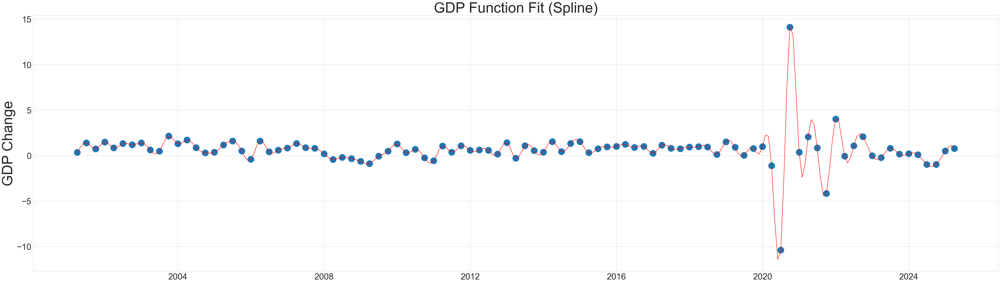

In [32]:
# GET NZTA DATA
nzta = pd.read_csv('nzta_heavy_vehicles_summary.csv')
nzta.columns = ['date', 'total']
nzta['date'] = pd.to_datetime(nzta['date'], format="%Y-%m-%d")
nzta = nzta.set_index('date')
df_sum = nzta.copy()
series = df_sum['total'].copy()
series.index = pd.to_datetime(series.index)
series = series.asfreq('M')
# Fill NaNs with the value from 12 months ago
filled_series = series.copy()
for i in range(12, len(series)):
    if pd.isna(filled_series.iloc[i]):
        filled_series.iloc[i] = filled_series.iloc[i - 12] 
df_sum = pd.DataFrame(filled_series)
df_sum


# GET GDP DATA
df = pd.read_csv('gross-domestic-product-march-2025-quarter.csv', usecols=['Series_reference','Period','Data_value','STATUS','Group','Series_title_1', 'Series_title_2'])
df.Period = df.Period.astype(str)
df[['Period']] = df[['Period']].applymap(conv_date)
df[['Series_reference']] = df[['Series_reference']].applymap(lambda x: x[5:])
df = df[df.Period > dt.datetime(year=2000, month=2, day=1)]
gdp = df[df.Series_reference == 'SG01RSC00B01'][['Period','Data_value']]
gdp.rename(columns={'Period':'quarter','Data_value':'national_gdp'}, inplace=True)
gdp = gdp.set_index('quarter')
gdp['quarterly_percent_change'] = (gdp.national_gdp - gdp.national_gdp.shift(1) ) / gdp.national_gdp.shift(1) * 100
gdp.head()


df2 = gdp.copy()
df2  = df2.reset_index()
df2['x'] = pd.to_timedelta((df2.quarter - df2.quarter.shift()).fillna(pd.NaT) / 30, unit='D')
df2.at[0, 'x'] = pd.Timedelta(0)
df2['x'].dt.days

df2[['x']] = np.round(df2[['x']].applymap(lambda x : x.days))
df2['x'] = np.cumsum(df2['x'])

df_gdp = fit_spline('x', 'quarterly_percent_change', df2, 'estimated_quarterly_percent_change')
# df_gdp['estimated_quarterly_percent_change'] = fit_spline('x', 'quarterly_percent_change', df2, 'estimated_quarterly_percent_change')
df_gdp = df_gdp['2010-12':]
df_sum['total_vehicles_r_sum_3'] = df_sum.total.rolling(3, 1).sum()
df_sum['total_vehicles_r_sum_6'] = df_sum.total.rolling(6, 1).sum() 
df_sum['total_vehicles_r_sum_12'] = df_sum.total.rolling(12, 1).sum() 
df_sum['total_vehicles_r_mean_3'] = df_sum.total.rolling(3, 1).mean()
df_sum['total_vehicles_r_mean_6'] = df_sum.total.rolling(6, 1).mean()
df_sum['total_vehicles_r_mean_12'] = df_sum.total.rolling(12, 1).mean()
df_sum['total_vehicles_diff_year'] = df_sum['total'] - df_sum['total'].shift(12)
df_sum['total_vehicles_r_sum_3_diff_year'] = df_sum['total_vehicles_r_sum_3'] - df_sum['total_vehicles_r_sum_3'].shift(12)
df_sum['total_vehicles_r_sum_3_percent_diff_year'] = df_sum['total_vehicles_r_sum_3_diff_year'] / df_sum['total_vehicles_r_sum_3'].shift(12) * 100 
df_sum['total_vehicles_r_sum_3_slope_3'] = (df_sum.total_vehicles_r_sum_3 - df_sum.total_vehicles_r_sum_3.shift(3)) / 3.0
df_sum['total_vehicles_r_sum_6_slope_6'] = (df_sum.total_vehicles_r_sum_6 - df_sum.total_vehicles_r_sum_6.shift(6)) / 6.0
df_sum.fillna(0, inplace=True)
df_sum = df_sum.join(df_gdp, how='outer')
df_train = df_sum.dropna()[[    'total_vehicles_r_sum_3',
    'total_vehicles_r_sum_6_slope_6','estimated_quarterly_percent_change']].copy()
df_train.head(10)

## Task 1.1: Implement Gradient Boosting Algorithm 
[Back to top](#Index)   |  [To section head](#Task-1:-GRADIENT-BOOSTING-IMPLEMENTATION) [To Template section](#Task-1:-Gradient-Boosting-Implementation-(25-Marks))

Here I am simply implementing and testing that it works, not testing it with timeseries prediction. That will come in Task 2.

There are lots of parameters in my implementation. Here I describe them all. The base model is the stump gradient booster from class:

**Base parameters**
* $\eta_0$: the learning rate is the penalty for each learning round. It helps in regularisation and preventing overfitting. default = 0.5.
* Classifier: string, defines a classifier to use in the model. Supported: stump, tree, MLP or Xtreme. Default = 'stump'.
* n_estimators: the number of boosting rounds. Default = 10.
* measure: the validation score. Supported: MSE, MAE, R2, MAPE, RMSE and pinball loss (for quantile loss). Default = 'MSE'.
* subsample: the ratio from 0 -> 1 of the original sample to be used at each boosting round. With replacement. default = 1.
* seed: the random seed for reproducibility. Default = None.

**Loss function parameters:**
* loss_function: string, defines the loss function to use. Supported: MSE, friedmandMSE, MAE, huber (huber loss), quantile loss.
    * $\beta$: the quadratic coefficient for huber loss. $\beta * (y - \hat{y})^2$. Default = 0.5.
    * $\gamma$: the linear coefficient for huber loss. $\gamma * |(y - \hat{y})^2| - \frac{1}{2 \gamma}$. Default = 2. i.e $\frac{1}{2}$
    * $\iota$: the sigmoid smoothing paramters for quantile loss. Default = 1.
    * quantile: the quantile for quantile loss, set between 0 and 1, but neither 0 nor 1. Default = 0.5.

**Decay parameters**
* decay ($\eta_n$): if this value is set, along with a decay function, the learning rate is adaptively modified at each boosting round by this value. defauls = None.
* decay_function: how the decay is applied. Supported: exponential, exponential2, gradient, probabalistic, logistic, linear, polynomial, inverse (inverse time), step and adaptive. Default = None.
    * For logistic decay, $\eta_n$ must be high if $\eta_0$ is less than 1. And vice versa.
    * For linear decay, $\eta_n$ must be low, less than 1. Else it gets strange. 
    * For step decay, a high \$eta_n$ results in a faster descent. 
    * For adaptive decay, only specify the function.
    * For probabalistic decay, only provide the pdf as a scipy.stats object: st.beta.pdf(np.linspace(0, 1, 50), 2, 3, loc= 0, scale = 1.5).
    
* distribution: holds the probability density function for probabalistic decay. Default = None.
* decay_steps: the number of steps between applications of decay for step and inverse time decay functions. Default = 1.
* power: the polynomial degree for polynomial decay Default = 1.
* $\omega$: the final decay rate to which polynomial decay deacys to
* $\epsilon_3$: penalty term for adaptive decay. Default = 1e-8. Smaller values make faster convergence.

**Early stopping parameters**
* validation_fraction: the proportion of the training data set aside for early stopping validation. Default = None. 
* patience: the number of consecutive rounds the model waits before stopping when no improvment is found. Default = None.
* tolerance: sets the threshold beneath the current best score within which new scores are considered 'not worse'. Default = None.

**Tree parameters**
* max_depth: the maximum depth the tree is allowed to grow to in each boosting round. Default = 1.
* min_samples_split: the minimum number of samples per branch required to form a split. Default = 0.
* min_samples_leaf: the minimum number of samples required to be at a leaf node. Default = 0.

**Multi Layered Perceptron parameters:**
* hidden_layer_sizes: a tuple containing a number of perceptrons per hidden layer. (10, 5, 2) is three layers with the specified perceptions each. 
* n_epochs: number of training rounds for the model at each boosting round. 
* activation: string containing the MLP activation function. Supported: relu, tanh, sigmoid. Default = 'relu'.
* optimiser: string containing the method ot refine weights and biases during training. Supported: SGD (stochastic gradient descent), adam (adaptive moment estimation). Defaaul = None.
* loss function: inherited from the model.
* batch_size: defines the absolute size of a random sample per epoch used for optimisation. Default = None (full sample). 
* $\alpha$: the learning rate for the MLP. Default 0.01. 
* $\beta_2$: coefficient for gradients of the weights. Default = 0.9.
* $\beta_3$: coefficients for gradients of the biases. Default is 0.999.
* $\epsilon_2$: regularisation term for adam optimisation. Default = 1e-8.

**XGBoost parameters**:
* base_prediction: the initial prediction for the model. Default = 0. 
* objective: string containing the objective function for calculating the XGBoost's gradietns and hessians. Supported: MSE, firedmanMSE, MAE, huber (huber loss).
* $\delta$: denominator for XGboost huber loss objective function. Default = 1.
* $\tau$: the smoothing term for the MAE objective to avoid discontinuity around 0. Default = 1
* reg_$\gamma$: the regularisation term on the boosting trees. The minimum loss reduction required to split a new leaf node. Default = 0.
* reg_$\alpha$: the L1 (lasso) regularisation term. Default = 0.
* reg_$\lambda$: the L2 (ridge) regularisation term. Default = 0.
* colsample_bynode: a value between 0 and 1 defining what proportion of the X features are selected in each node per tree. Deafult = 1 (all features).
* min_child_weight: controls the minimum sum of instance weight(hessians) needed in a child node before a split is made on the tree. Default = 1. 

**D.A.R.T parameters:**
* drop_rate: the proportion of models to drop from the finali fitted model, that are then used to re-fit the tree. 


In [33]:
X = df_train[['total_vehicles_r_sum_3','total_vehicles_r_sum_6_slope_6']].values
y = df_train[['estimated_quarterly_percent_change']].values

train_df = pd.DataFrame(X, columns=['Feature1', 'Feature2'])
train_df['Target'] = y

X_train, X_test, y_train, y_test = modsel.train_test_split(train_df[['Feature1', 'Feature2']].values, train_df['Target'].values, test_size=0.2, random_state=21)

Training the model does work, as seen from the belwo charts. These show, in order:
* a pair wise fit of the x variables ot the y variable along with a residuals vs fitted plot for both training and tessting data sets.
* Model convergence in terms of the loss and the evaluation measure, here both MSE. 
* the training predictions  for each round and separately, the final training round. Compared to the y variable. 
* the same for testing rounds.
* Standardised residuals against the standardised y values. 

Looking at these graphs we seen that the model fits rather closesly to the mean in the pair wise plots. The gold, target data points, have a few outliets and some large spread which the model hasn't picked up on fully. Though it appears to do better with X1. 

We see that after 20 boostig rounds the model seems to converge to an MSE around 3.8 both in terms of performance score and loss, but that the model generalises better to the data than the MSE suggests: 1.73 on test data vs 3.85 on training.

Looking at the training and testing fits for the ensemble and the final prediction we see that the model was not very good at large fitting negative spikes. Nor spikes at all, except the positive spike near x = 60. Over time the model converged to a pattern of being mostly around zero, with some negative spikes and the aforementioned positive spike. Successive rounds reinforced this pattern. 

One the testing data the model did better, being able to predict the big final spike, but otherwise more or less adhereing to a stable 'median'. 

Finally, we see that the residauls follow the real y values almost perfectly, following all the big outlier spikes. 

From these we see that the model works, and that the data is difficult for the model to fit well. 


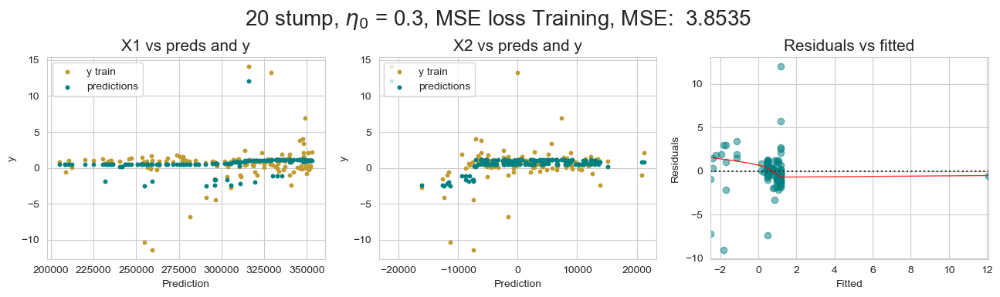

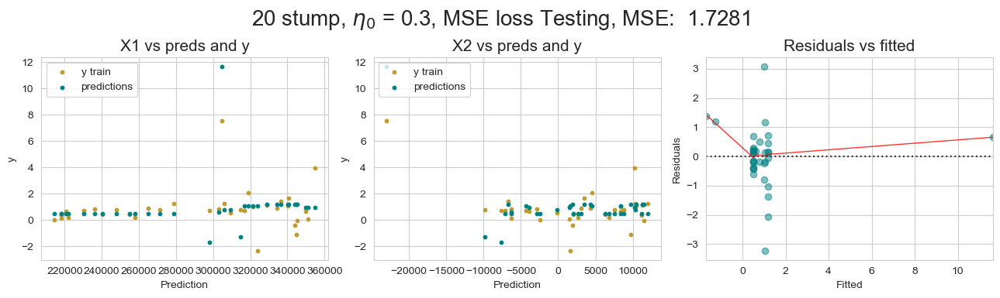

In [34]:
Grad_boost = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.3, subsample= None, seed = 21, loss_function = 'MSE')
Grad_boost.fit(X_train, y_train)
Grad_boost.predict(X_test)

plot_GB_res(X_train, y_train,  'Training', Grad_boost)
plot_GB_res(X_test, y_test,  "Testing", Grad_boost)

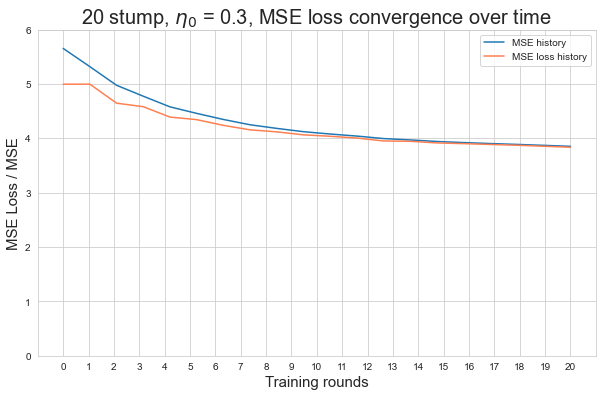

In [200]:
plt.figure(figsize=(10, 6))
plot = loss_convergence_plot(Grad_boost)

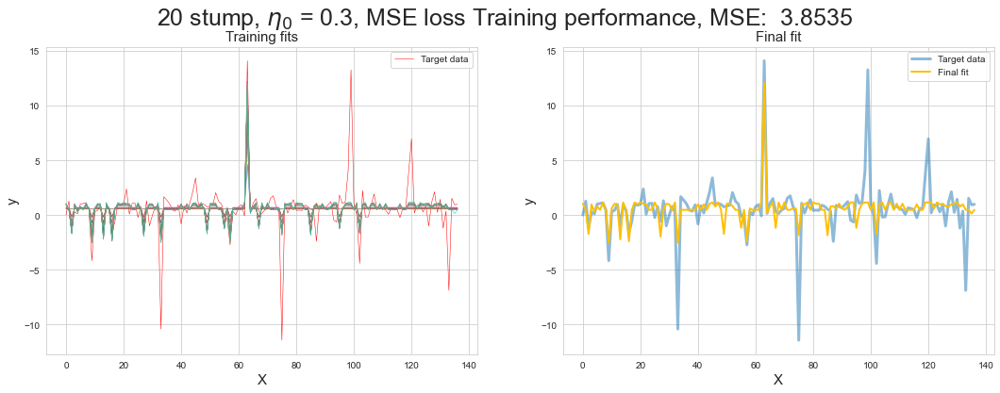

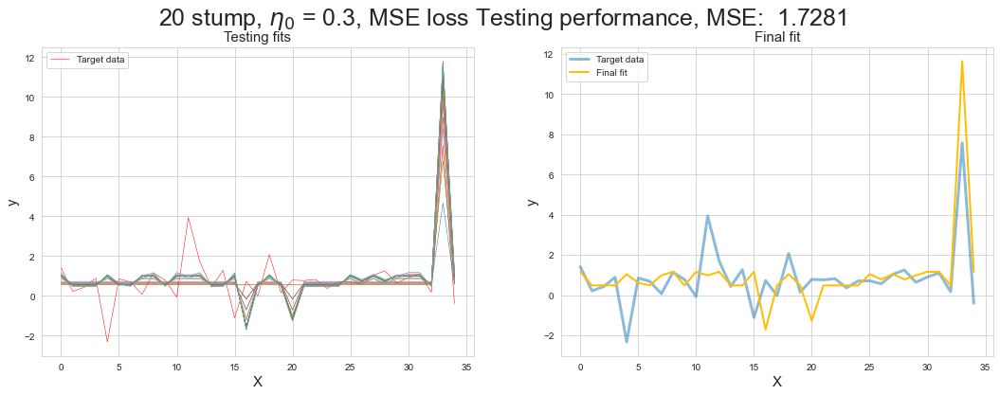

In [62]:
test_results = remove_duplicates_arrays(Grad_boost.testing_preds)

model_test_plot(X_train, y_train, 'Train', Grad_boost)
model_test_plot(X_test, y_test,'Test', Grad_boost)

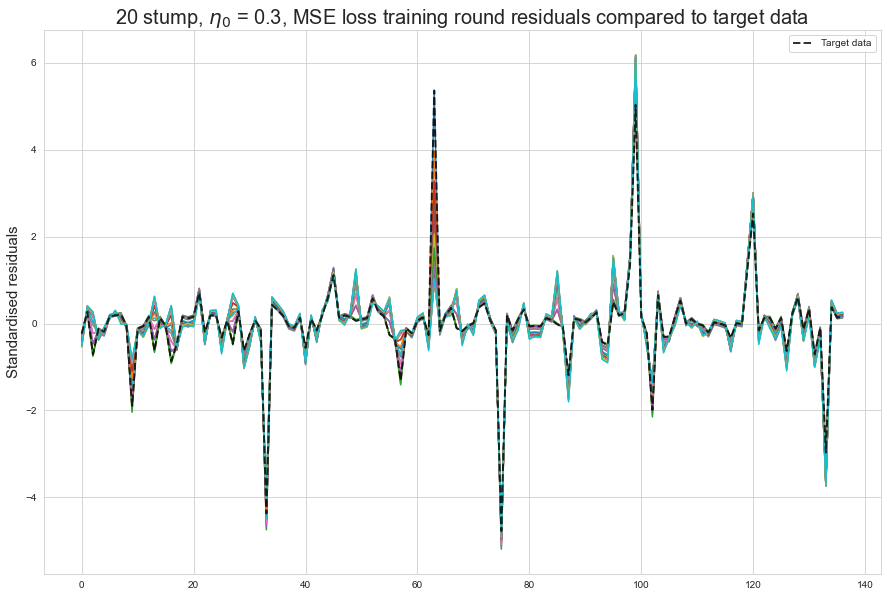

In [63]:
plt.figure(figsize=(15, 10))
plot = standardised_residual_plot(Grad_boost, y_train)

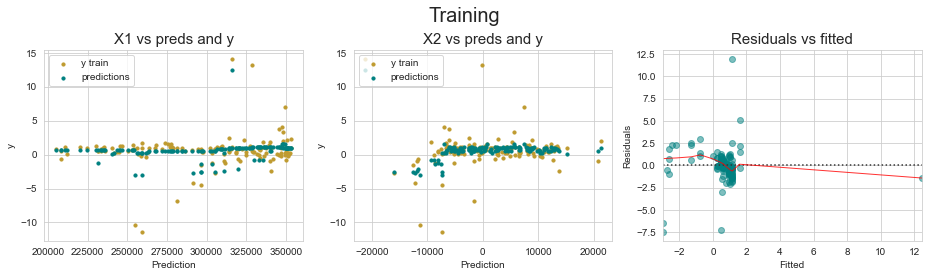

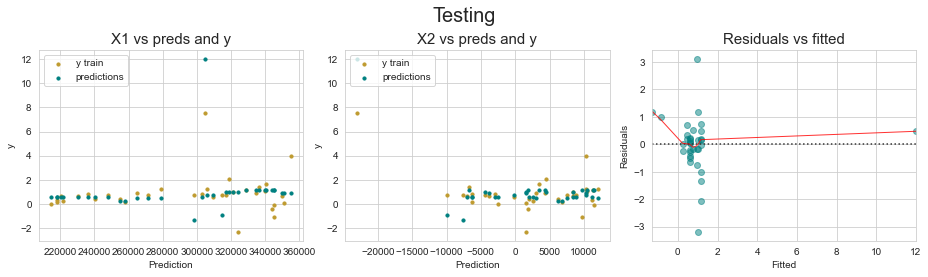

Training Mean squared Error: 3.4614
Testing Mean squared Error: 1.7299


In [12]:
Grad_boost = GBoost(classifier = 'stump', n_estimators = 50, learning_rate = 0.3, loss_function = 'friedmanMSE')
Grad_boost.fit(X_train, y_train)
prediction = Grad_boost.predict(X_test)

plot_GB_res(X_train, y_train, Grad_boost.predict(X_train), 'Training')
plot_GB_res(X_test, y_test, Grad_boost.predict(X_test), "Testing")

print(f"Training Mean squared Error: {metrics.mean_squared_error(y_train, Grad_boost.predict(X_train)):.4f}")
print(f"Testing Mean squared Error: {metrics.mean_squared_error(y_test, Grad_boost.predict(X_test)):.4f}")

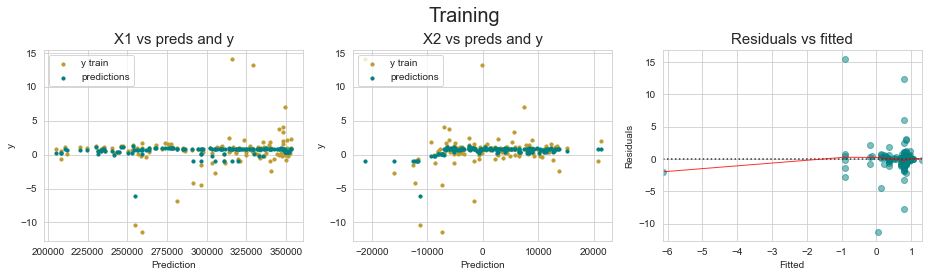

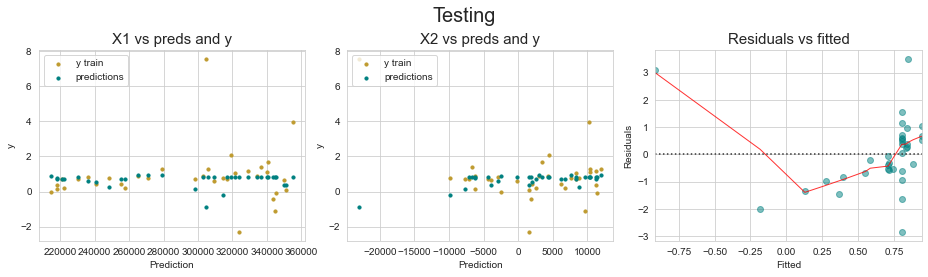

Training Mean squared Error: 0.9860
Testing Mean absolute Error: 0.8573


In [13]:
#MAE GBoost
Grad_boost = GBoost(n_estimators = 50, learning_rate = 0.5, loss_function = 'MAE')
Grad_boost.fit(X_train, y_train)

plot_GB_res(X_train, y_train, Grad_boost.predict(X_train), 'Training')
plot_GB_res(X_test, y_test, Grad_boost.predict(X_test), "Testing")

print(f"Training Mean squared Error: {metrics.mean_absolute_error(y_train, Grad_boost.predict(X_train)):.4f}")
print(f"Testing Mean absolute Error: {metrics.mean_absolute_error(y_test, Grad_boost.predict(X_test)):.4f}")

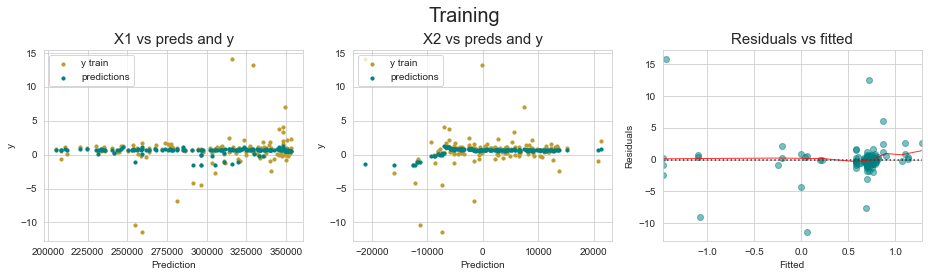

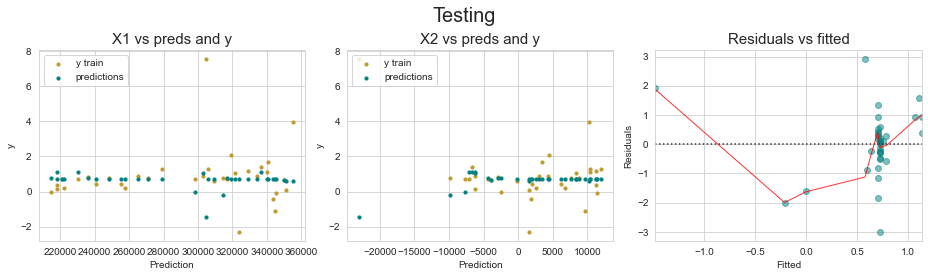

Training Mean squared Error: 1.0384
Testing Mean absolute Error: 0.8992


In [16]:
#huber GBoost
Grad_boost = GBoost(n_estimators = 50, learning_rate = 0.3, gamma = 1, beta = 0.5, loss_function = 'huber')
Grad_boost.fit(X_train, y_train)

plot_GB_res(X_train, y_train, Grad_boost.predict(X_train), 'Training')
plot_GB_res(X_test, y_test, Grad_boost.predict(X_test), "Testing")

print(f"Training Mean squared Error: {metrics.mean_absolute_error(y_train, Grad_boost.predict(X_train)):.4f}")
print(f"Testing Mean absolute Error: {metrics.mean_absolute_error(y_test, Grad_boost.predict(X_test)):.4f}")

## Task 1.2 Adjust the Loss Function
[Back to top](#Index)   |  [To section head](#Task-1:-GRADIENT-BOOSTING-IMPLEMENTATION)
 |[To Template section](#Task-1:-Gradient-Boosting-Implementation-(25-Marks))
 
The model has been enhanced to handle via the 'loss_function' paramter the following:

Mean squared error, which is standard.
$$MSE = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y_i})^2 $$

Friedman MSE, from Friedman (2000),
$$ i^2(R_l, R_r) = \frac{w_l * w_r}{w_l + w_r} * (\bar{y_l} - \bar{y_r})^2$$

Mean average error, to handle outliers better Firedman (2000),
$$MAE = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y_i}| $$

Huber loss which mixes MSE and MAE, Friedman (2000),
$$
  f(x)=\begin{cases}
    \frac{1}{\beta}(y-f(x))^2, & \text{if $|y-f(x)| \leq \gamma$}.\\
    \gamma \space \cdot \space (|y - f(x)|-\frac{1}{2}\gamma), & \text{otherwise}.
  \end{cases}
$$
For which the standard formation sets $\beta$ at 2, but I decided to let it be user definable, and for which $\gamma$ is typically expressed as $\delta$, but because I use an MLP later on I didn't want to have two $\delta$ parameters causing confusion. 

and quantile, or pinball loss, which has been implemented using the mean of quantile gradients. Because the quantile function is not differentiable at zero, I used the sigmoid function to smooth it out around zero. 
$$
  L_\alpha(y, \hat{y})=\begin{cases}
    \alpha(y-\hat{y}, & \text{if $y-\hat{y} > 0$}.\\
    (1-\alpha)(y-\hat{y}, & \text{if $y-\hat{y} \leq 0$}.
  \end{cases}
$$

Smoothed quantile loss:

$\mathcal{L} = \sum_i = (\Theta - \sigma(y_i - \hat{y}_i))(y_i - \hat{y}_i)$, where $\sigma(x) = \frac{1}{1+e^{\iota x}}$

The results of this adjustment do not alter the outcome of the model provided the loss function doesn't hit zero, however, including it means I don't need to worry about discontinuity at zero if I end up using many lagged variables which have imputed values of zero resulting in 0 gradients. 

In [624]:
Grad_boost_FMSE = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.3, subsample= None, seed = 21, loss_function = 'friedmanMSE')
Grad_boost_FMSE.fit(X_train, y_train)

Grad_boost_MAE = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.3, subsample= None, seed = 21, loss_function = 'MAE', measure = 'MAE')
Grad_boost_MAE.fit(X_train, y_train)

Grad_boost_huber = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.3, subsample= None, seed = 21, loss_function = 'huber', measure = 'huber')
Grad_boost_huber.fit(X_train, y_train)

Grad_boost_quantile = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.3, subsample= None, seed = 21, loss_function = 'quantile', quantile =0.9, iota = 30, measure = 'pinball')
Grad_boost_quantile.fit(X_train, y_train)


GBoost(iota=30, learning_rate=0.3, loss_function='quantile', measure='pinball',
       n_estimators=20, quantile=0.9, seed=21, subsample=None)

To test each, we will view the sample model as before with the different loss functions applied. The four graphs below show the loss functions in action over 20 estimators. 

* MSE converges quickly, around 10 estimators in. The curve looks asymptotic somewhere out in the triple digits. 
* quantil loss, compared to the quantile 
* MAE uses a median based loss function and is more resilient to outliers. This loss gets worse, after the first few iterations, but pans out quickly, never quicte reacing 1. While the MAE score seems to be monotonically decreasing towards it. 
* Huber loss increases with iterations. The upwards trend of huber loss observed is not a rule. It is specific to this data. It shows that at each boosting round the loss is getting larger - i.e. the difference between predicted and actual values is diverging. Yet, overall, the model's huber loss is decreasing. One can look at this as each new boosting round adding less than prior, but overall improving the model. Why this occurs is of interest. The within iterations loss goes up most likely because the splits are not representative of the data, perhaps due to the presence of outliers. Huber loss is designed to be more robust to outliers, switching to the MAE when there are many outliers afoot as defined by the $\beta$ and $\gamma$ coefficients. Which is to say, we could tune this out to some degree, but because we are measuring the loss in the data using the huber loss method, this is a consequnce. The within iteration loss goes up as a consequence of the left/right splitting process proving the measurement process with odd batches which cause it to change the linear or quadratic aproximation based on the $\gamma$ coefficient, which was set to 0.5 as default. So when an absolute residual is $\leq \gamma$, a quadratic loss function is applied, otherwise the linear one.
* Freidman MSE, which measures the quality of the split rapidly decreases towards the MSE metric, meeting it around 20 iterations. FMSE is not MSE, albeit it is similar. It measures improvement, hence the rapidly decreasing loss. 


<Figure size 1080x720 with 0 Axes>

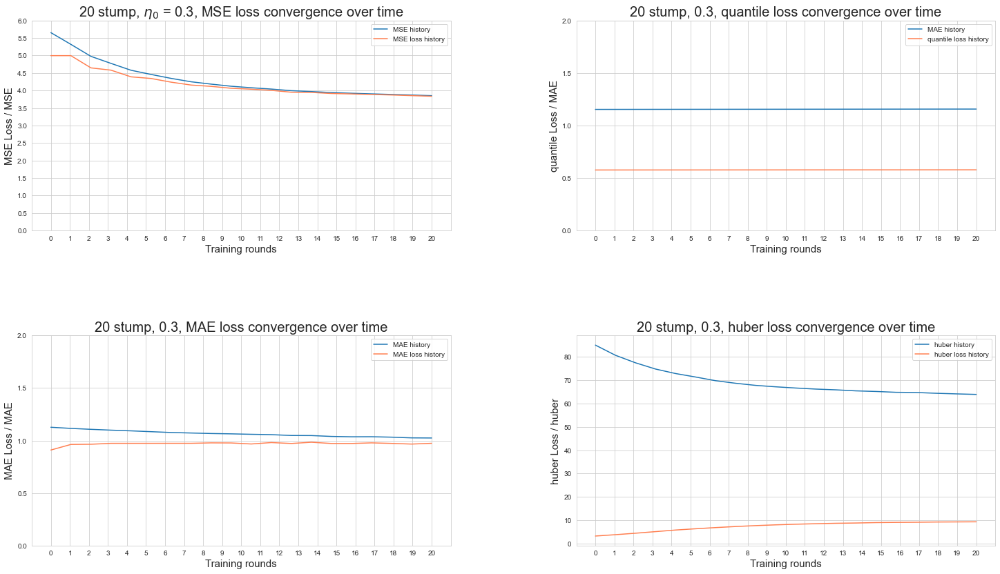

In [278]:
plt.figure(figsize=(15, 10))

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(25, 14))
ax1 = loss_convergence_plot(Grad_boost, ax = ax1)
ax2 = loss_convergence_plot(Grad_boost_quantile, ax = ax2)

ax3 = loss_convergence_plot(Grad_boost_MAE, ax = ax3)
ax4 = loss_convergence_plot(Grad_boost_huber, ax=ax4)
ax4.set_yticks(np.arange(0, max(Grad_boost_huber.score_history), step=10))

plt.subplots_adjust(hspace=0.5, wspace=0.3)
plt.show()

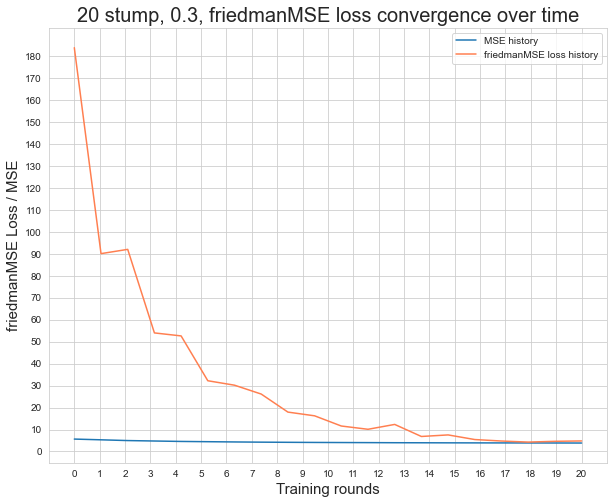

In [280]:
plt.figure(figsize=(10,8))
loss_convergence_plot(Grad_boost_FMSE)
plt.yticks(np.arange(0, max(Grad_boost_FMSE.loss_history), step=10))
plt.show()

One last thing to observe is the model performance on test and training data for each new loss function. We shall look at them each in turn.

Friedman MSE loss has the exact same performance as regular MSE. This means that for this data and set of model parameters, the calculation of impurity for the split (Friedman MSE) yielded the same as regular MSE. They both aim to minimise MSE, so this is not a surpirse. It just means that perhaps with the number of estimators at hand the two perfrom similarly. 

MAE, being robust ot outliers as it is, has not done a good job of fitting to them. It more or less ignores them. Which is what it is designed to do. Under this loss function, we see that the model fits minor negative spikes better than major  ones. Showing simply that with this loss function, there are less outlying negative spikes. We may say there tends ot be more toughs than peaks, were we to believe this model wholeheartedly. MAE has a lower overal score than MSE, gaain due to how it treats outliers. 1.02 on training and 0.85 on test. The magnitude of the difference is misleading as we aren't coparing apples to apples. What we could say is that, on average, this model's predictions are 0.85 units off the real value. Now, this average means diddly squat when we look at the data. This model, could is speak, would defend itself by saying "it is possible to be 'close enough' while being mostly wrong." 

Huber loss is similar to MAE in this regard. The huber loss score of 11 on test data and 63 on training data is hard to interpret, so beneath I show the MSE and MAE scores of the same model. Which are:
* 6.1 MSE on training data
* 2.5 MSE on test data
* 1.1 MAE on training data
* 0.81 MAE on test data

These show that the model is doing better in terms of MAE (more robust ot outliers) and this has a corresponding trade off on MSE which is not robust to outliers. This data, being full of outliers has a lot of information kept therein. Ignoring the outliers means that the model more or less predicts close to 0. It may be closer to right when there is nothing 'going on' in the outlier department, but it is verry wrong when there is. So here, huber loss leads to worse perfromance than MSE, at least with the threshold paramter set to 0.5. When we get to hyper tuning we can change this to find better fits. 

The same story goes for pinball loss. The pinball value of 0.3 is hard to interpret. On MSE and MAE it performed:
* 6.3 MSE on training data
* 2.3 MSE on test data
* 1.2 MAE on training data
* 0.80 MAE on test data

And is even latter than huber and MAE loss functions. Here the quantile was set to 0.9. So the model is calcualting the loss in terms of the probabalistic difference between the 0.9 quantile (90th percentile)  and the observed values. And it is doing a terrible job of fitting the data. Any marginal gain in performance is because the model has almost uniformly predicted a higher value due to the overbearing influence of the large spikes. However, I told it do this by setting the quantile value to 0.9. Making the model penalise any value below the 90th percentile, while rewarding over prediction. Resulting in something more akin to an interpretation of risk around the designated percentile. Looking at the chart above we see the lines are converging around 0.3 (30th percentile) indicating that belief in the prediction carried about a 30% risk being wrong. Not particularly useful for this data set, but perhaps useful if one were to think about what prediction to give the public. With this understanding, the interpretation of the model is such: use these predictions if you are happy to be wrong, on average, 30% of the time. 

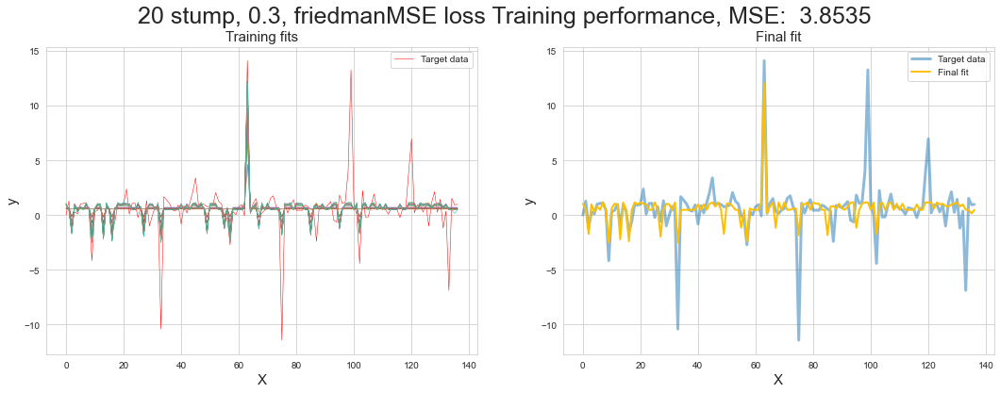

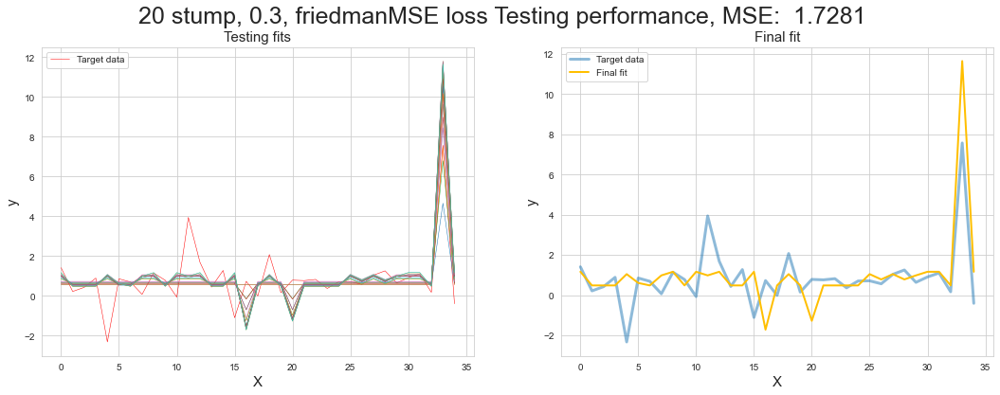

In [223]:
model_test_plot(X_train, y_train, 'Train', Grad_boost_FMSE)
model_test_plot(X_test, y_test, 'Test', Grad_boost_FMSE)

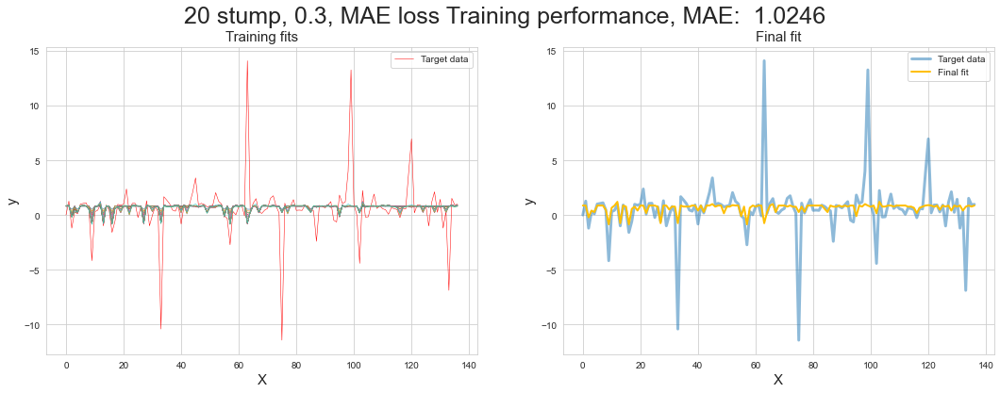

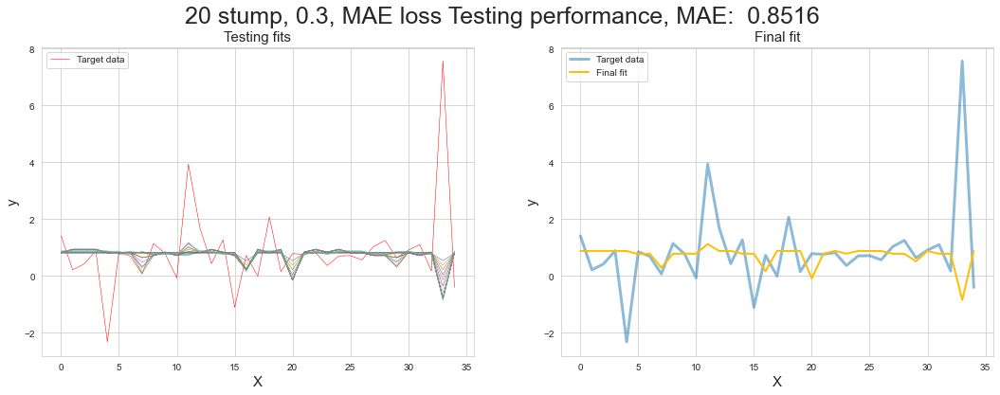

In [224]:
model_test_plot(X_train, y_train, 'Train', Grad_boost_MAE)
model_test_plot(X_test, y_test, 'Test', Grad_boost_MAE)

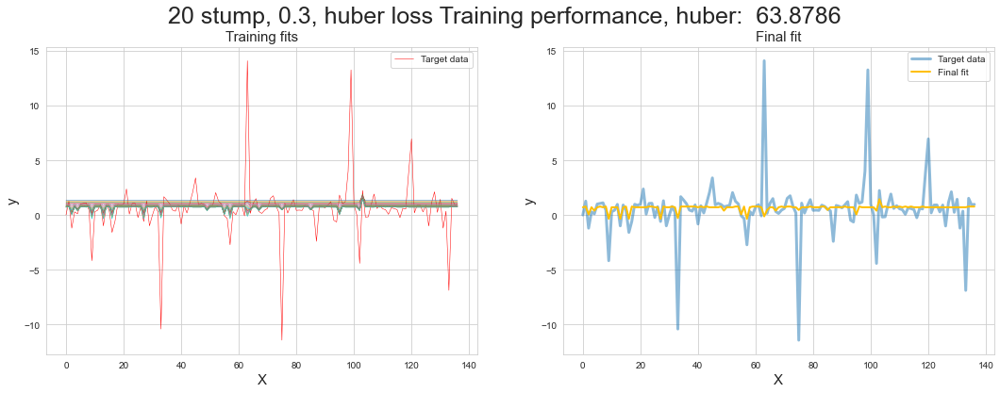

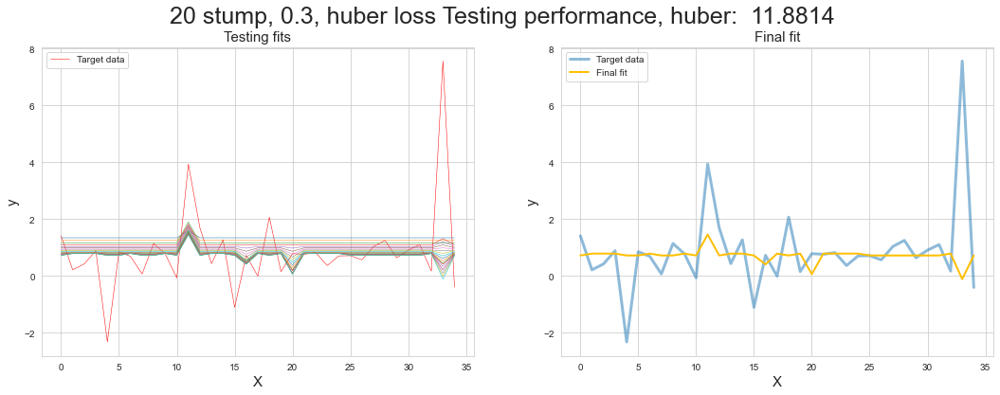

In [242]:
model_test_plot(X_train, y_train, 'Train', Grad_boost_huber)
model_test_plot(X_test, y_test, 'Test', Grad_boost_huber)

In [252]:
Grad_boost_huber = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.3, subsample= None, seed = 21, loss_function = 'huber', measure = 'MSE')
Grad_boost_huber.fit(X_train, y_train)
print(f'{Grad_boost_huber.model_name}, training {Grad_boost_huber.measure}: {Grad_boost_huber.score(X_train, y_train): .4f}')
print(f'{Grad_boost_huber.model_name}, testing {Grad_boost_huber.measure}: {Grad_boost_huber.score(X_test, y_test): .4f}')

Grad_boost_huber = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.3, subsample= None, seed = 21, loss_function = 'huber', measure = 'MAE')
Grad_boost_huber.fit(X_train, y_train)
print(f'{Grad_boost_huber.model_name}, training {Grad_boost_huber.measure}: {Grad_boost_huber.score(X_train, y_train): .4f}')
print(f'{Grad_boost_huber.model_name}, testing {Grad_boost_huber.measure}: {Grad_boost_huber.score(X_test, y_test): .4f}')

20 stump, 0.3, huber loss, training MSE:  6.1070
20 stump, 0.3, huber loss, testing MSE:  2.4865
20 stump, 0.3, huber loss, training MAE:  1.0834
20 stump, 0.3, huber loss, testing MAE:  0.8121


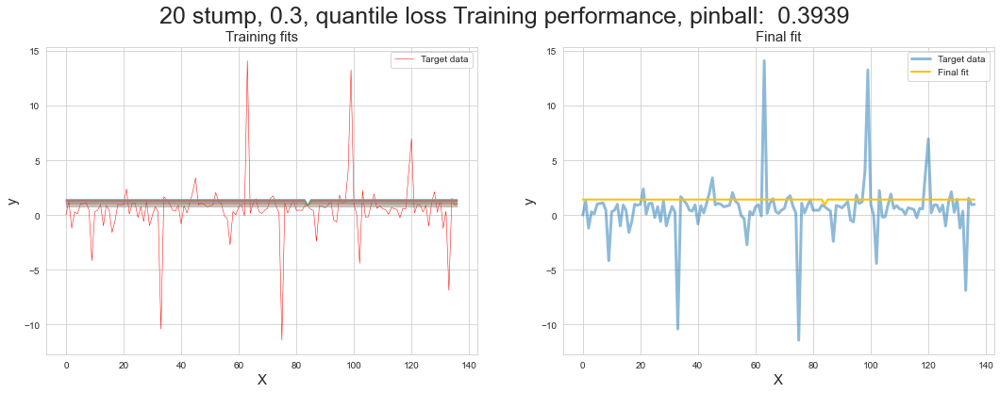

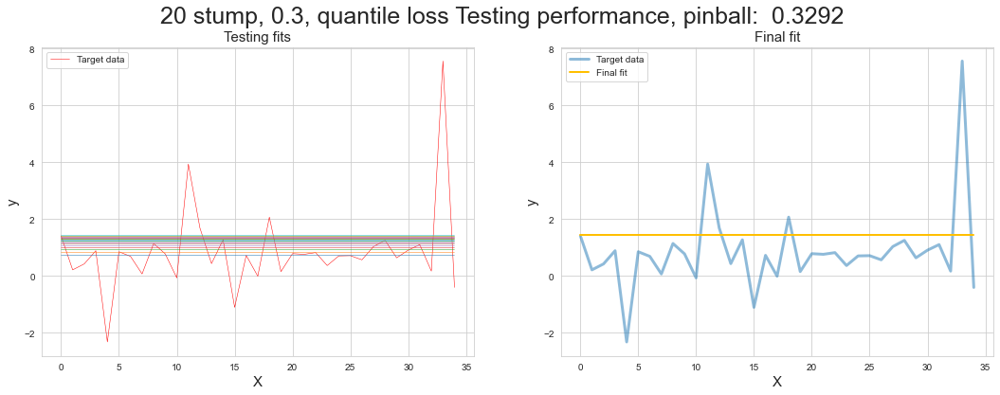

In [226]:
model_test_plot(X_train, y_train,'Train', Grad_boost_quantile)
model_test_plot(X_test, y_test, 'Test', Grad_boost_quantile)

In [257]:
Grad_boost_quantile = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.3, subsample= None, seed = 21, loss_function = 'quantile', measure = 'MSE')
Grad_boost_quantile.fit(X_train, y_train)
# preds = Grad_boost_huber.predict(X_test)
print(f'{Grad_boost_quantile.model_name}, training {Grad_boost_quantile.measure}: {Grad_boost_quantile.score(X_train, y_train): .4f}')
print(f'{Grad_boost_quantile.model_name}, testing {Grad_boost_quantile.measure}: {Grad_boost_quantile.score(X_test, y_test): .4f}')

Grad_boost_quantile = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.3, subsample= None, seed = 21, loss_function = 'quantile', measure = 'MAE')
Grad_boost_quantile.fit(X_train, y_train)
# preds = Grad_boost_huber.predict(X_test)
print(f'{Grad_boost_quantile.model_name}, training {Grad_boost_quantile.measure}: {Grad_boost_quantile.score(X_train, y_train): .4f}')
print(f'{Grad_boost_quantile.model_name}, testing {Grad_boost_quantile.measure}: {Grad_boost_quantile.score(X_test, y_test): .4f}')

20 stump, 0.3, quantile loss, training MSE:  6.3392
20 stump, 0.3, quantile loss, testing MSE:  2.3003
20 stump, 0.3, quantile loss, training MAE:  1.1569
20 stump, 0.3, quantile loss, testing MAE:  0.8040


## Task 1.3 Adjust Weak Learner Type
[Back to top](#Index)   |  [To section head](#Task-1:-GRADIENT-BOOSTING-IMPLEMENTATION) | [To Template section](#Task-1:-Gradient-Boosting-Implementation-(25-Marks))

[Decision Tree](#1.3.1-Decision-Tree:)  | [MLP](#1.3.2-Multi-Layered-Perception-(Neural-Network):) | [XGB](#1.3.3-XGBOOST:)

Two weak learners were used in thegradient boosting machine. Decision trees and a multi layered perceptrion.
For comparision, we will use the 20 iteration stump model with $\eta_0 = 0.3$. We will also hold the loss function and the scoring metric constant as 'MSE'. To help illustrate the point of model convergence, we will use a largeer $\eta_0$ and  ary this with the models based on their learner. 

Recall that our control model has an MSE of:
* 3.8535 on training data.
* 1.7281 on test data.

## 1.3.1 Decision Tree:
[Back to top](#Index)   |  [To section head](#Task-1:-GRADIENT-BOOSTING-IMPLEMENTATION)

A decision tree is an extension of the stump really. The model has parameters for depth, samples per split and samples per leaf. These paramters control complexity and hence help regularise overfitting.

* max_depth
* min_samples_split
* min_samples_leaf

For the first model, with $\eta_0 = 0.3$ the MSE gets worse as the model grows. HEre we have a depth of 3 with a minimum of 10 samples per split and 5 samples per leaf. Not only is the testing MSE worse than the training (16.47 to 15.73), the loss never converges. The MSE of this model seems to hit a minimum around 4 training rounds in near an MSE 0f 4.25. 
This is because the model is far too complex for the task. How this model wirks is by performing the stump split at every tree node. That is is iterates trhough all thresholds in the branch. Getting progressively more fit to the data. Then, the output of the tree's prediction is 'boosted' by the learning rate. Because the complexity of the tree has been controled to 10 and 5 samples per split and leaf respectively, the model is not generating a precise fit ove the 137 dat rows in the training set. This stops it from learning the data too well. In this case, because the data are small in number, the regularisation is too much, resulting in poor predictions. 


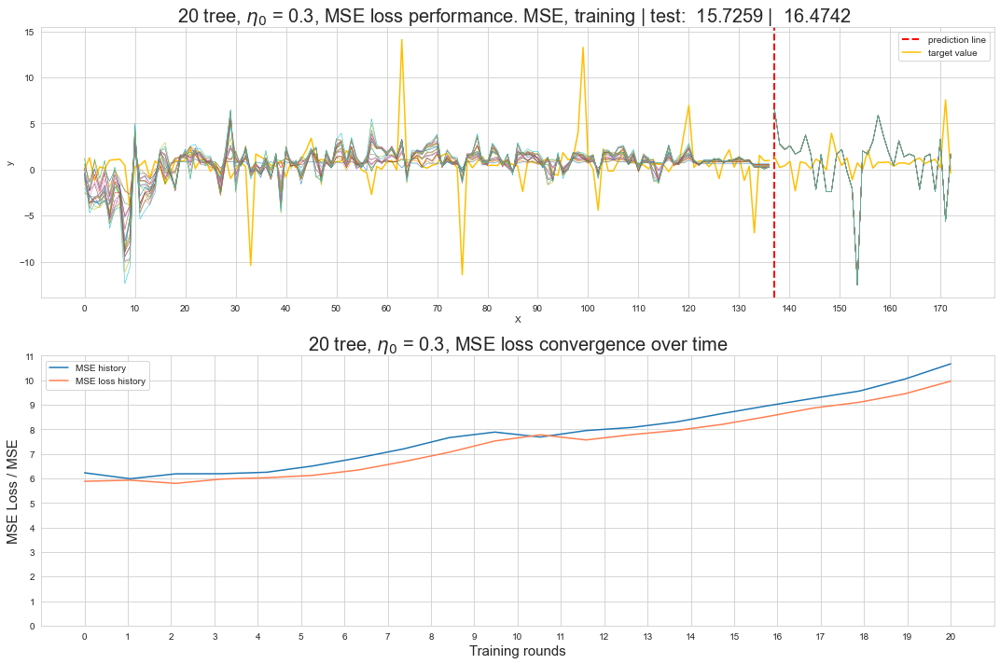

In [65]:
GradTree_boost = GBoost(classifier = 'tree', n_estimators = 20, learning_rate = 0.3, seed = 21, loss_function = 'MSE',
                       max_depth = 3, min_samples_split = 10, min_samples_leaf = 5)
GradTree_boost.fit(X_train, y_train)
GradTree_boost.predict(X_test)

fig, (ax1, ax2) = plt.subplots(2,1, figsize=(15, 10))
ax1 = model_pred_plot(X_train, y_train, X_test, y_test, GradTree_boost, ax = ax1)
ax2 = loss_convergence_plot(GradTree_boost, ax = ax2)
plt.tight_layout()

plt.show()

When we let the tree be more specific and reduce the depth we see very different behaviour. The tree fits remarkably better with a training and testing MSE of 8.38 vs 2.85. The error and loss are still both increasing, however the best amount of training rounds is now 6 and not 4. 

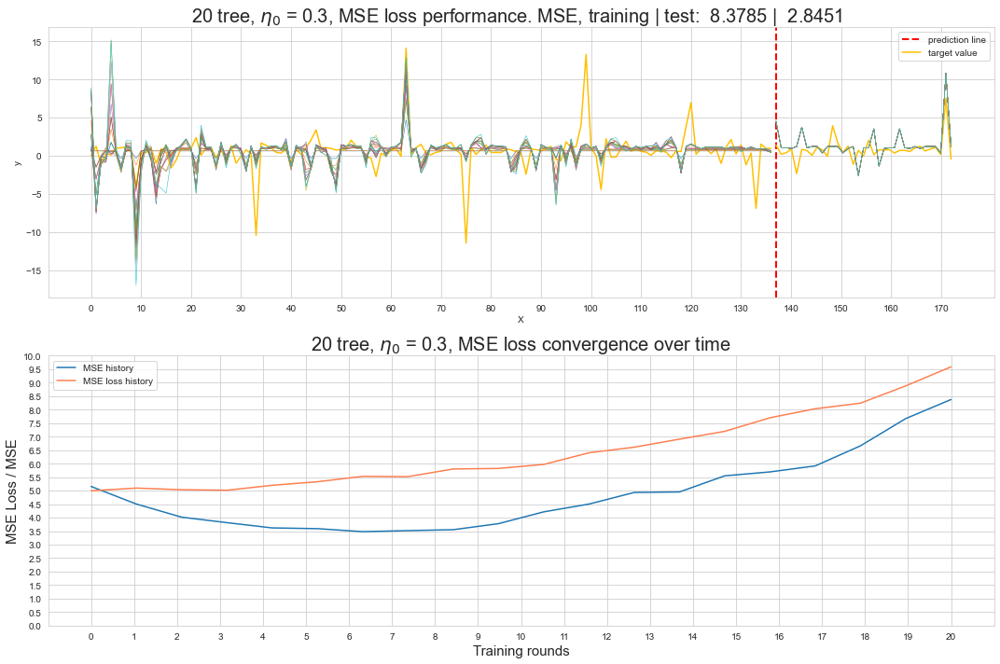

In [448]:
GradTree_boost = GBoost(classifier = 'tree', n_estimators = 20, learning_rate = 0.3, seed = 21, loss_function = 'MSE',
                       max_depth = 2)
GradTree_boost.fit(X_train, y_train)
GradTree_boost.predict(X_test)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))
ax1 = model_pred_plot(X_train, y_train, X_test, y_test, GradTree_boost, ax = ax1)
ax2 = loss_convergence_plot(GradTree_boost, ax = ax2)
plt.tight_layout()

plt.show()

When we let the depth increase to 10 we see that the model is about as wrong as could be. It has predcited values far beyond possibility and the error has sky rocketed to the 15,000s. Here it has delved too deep and too greedily, like the Dwarves of Moria. One can't even call this over fitting anymore. 

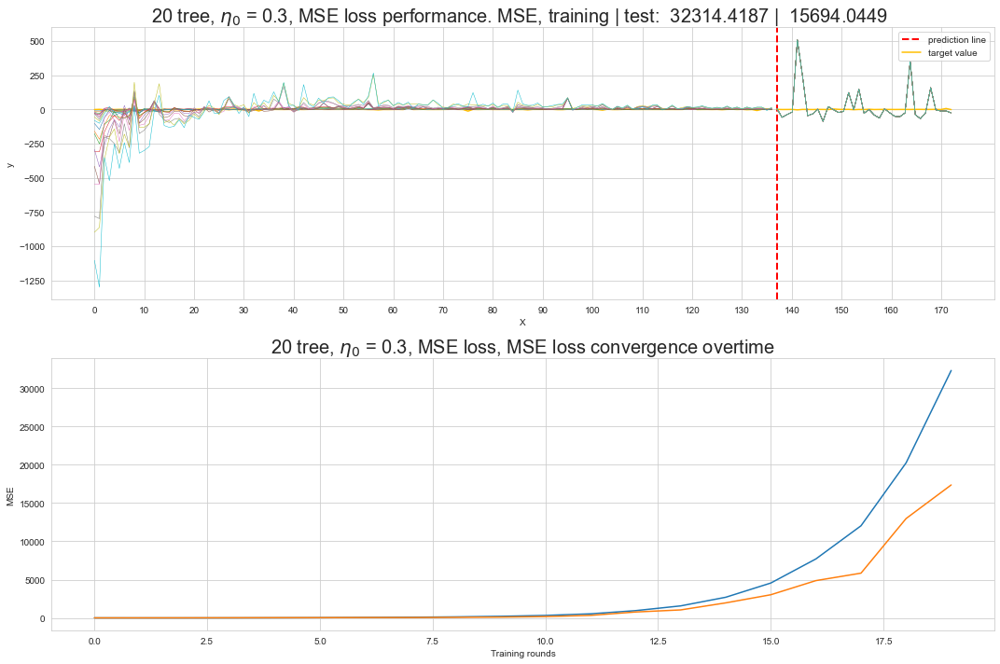

In [471]:
GradTree_boost = GBoost(classifier = 'tree', n_estimators = 20, learning_rate = 0.3, seed = 21, loss_function = 'MSE',
                       max_depth = 10)
GradTree_boost.fit(X_train, y_train)
GradTree_boost.predict(X_test)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))
ax1 = model_pred_plot(X_train, y_train, X_test, y_test, GradTree_boost, ax = ax1)
ax2.plot(GradTree_boost.score_history)
ax2.plot(GradTree_boost.loss_history)
ax2.set_title(f'{GradTree_boost.model_name}, {GradTree_boost.measure} loss convergence overtime', size = 20)
ax2.set_ylabel(f'{GradTree_boost.measure}')
ax2.set_xlabel(f'Training rounds')
# loss_convergence_plot(GradTree_boost, ax = ax2)
plt.tight_layout()

plt.show()

Going deep is why we need the regularisation on the branches and leaves. These paramters control the complexity of the tree. Yet, even so, a 10 deep tree model with 20 samples required for a split and 15 for a leaf, the MSE of 10.24 on test data vs a MSE of 6.28 on training data shows that the complex tree model greatly overfits the data. So far no tree model can beat a simple stump model. This is due to the added complexity of the trees. A deep tree, propoerly controlled can fit some of the training data very well, as below from $x = 0 to x = 60$. 
We may assume that the fitting would continue to be adequate if the cuases fo the outliers were predicatble. In this data, they aren't. We will come back to why this is so later. 

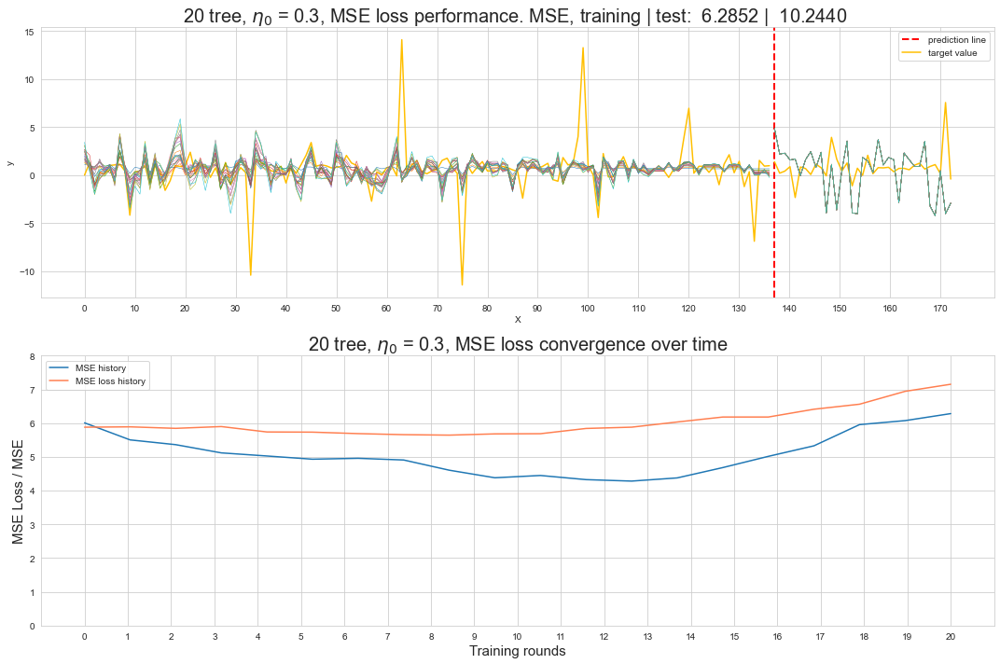

In [485]:
GradTree_boost = GBoost(classifier = 'tree', n_estimators = 20, learning_rate = 0.3, seed = 21, loss_function = 'MSE',
                        max_depth = 10, min_samples_split = 20, min_samples_leaf = 15)
GradTree_boost.fit(X_train, y_train)
GradTree_boost.predict(X_test)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))
ax1 = model_pred_plot(X_train, y_train, X_test, y_test, GradTree_boost, ax = ax1)
ax2 = loss_convergence_plot(GradTree_boost, ax = ax2)
plt.tight_layout()

plt.show()

## 1.3.2 Multi Layered Perception (Neural Network):
[Back to top](#Index)   |  [To section head](#Task-1:-GRADIENT-BOOSTING-IMPLEMENTATION)  |  [MLP class](#MLP-Class)

This implementation of the MLP model in gradient boosting is encapsualted in the MLP class. Trees work on splitting by threshold. MLPs do not work this way. Instead of doing a threshold search, this model fits an MLP to the residuals, return the prediction and boosts the prediction. Resulting in an enesmble of MLPs. Which can be ensembles themselves. This model is nice because once can greatly configure it. Which can lead to some laughs.

For the first model we will set three hidden layers with 10, 3 and 11 perceptons each. We will use the relu activtation function and optimise with stochastic gradient descent. When we set a realtively high $\eta_0$, we need to set a similarly high $\alpha$ for the MLP. Otherwise, when boosting, the two get multiplied in the mix, and since fraction multiplied by a fraction make a smaller number, and a larger number divided by a very small number results in a really big number, if we don't have larger values in each, we get very overblown predictions. 
 
Our first model, has a poor fit to the training data. It is more or less ignoring the data. However, it has vastyl different performance on the test data. In fact, it does pretty good at getting the spikes, because if one predicts a spike all the time, eventually one is right. This model has overall poor performance with an MSE of 9.42 on test data vs 13.31 on training data. Meanwhile the MSE loss is relatively stable while the model's MSE heads off into space. R2 is the measure to view of MLPs, not MSE, but here I want to keep things consistent for comparison purposes. We would find that R2 decreases over time, indicating a poor fit. Perhaps, given 1000s of iterations the model would get better.... it doesn't. The error will simply be magnified and we will get worse results. We need fewer. 

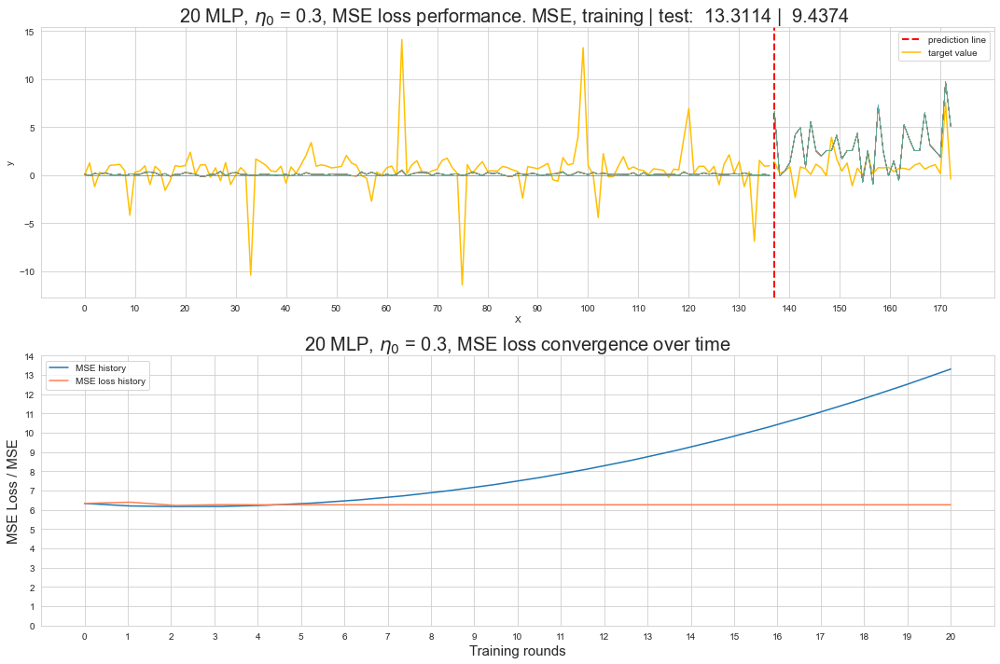

In [560]:
Gradboost_MLP = GBoost(classifier = 'MLP', loss_function = 'MSE', n_estimators = 20, learning_rate = 0.3, seed = 21, measure='MSE',
                       optimiser = 'SGD', hidden_layer_sizes = (10,3, 11), n_epochs = 10, activation = 'relu', 
                       alpha = 0.2, beta2 = 0.5, beta3 = 0.5)
Gradboost_MLP.fit(X_train, y_train)
Gradboost_MLP.predict(X_test)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))
ax1 = model_pred_plot(X_train, y_train, X_test, y_test, Gradboost_MLP, ax = ax1)
ax2 = loss_convergence_plot(Gradboost_MLP, ax = ax2)
plt.tight_layout()

MLPs are fragile things. If we set out parameters even slightly wrong the model begins predicting nothing right. Adding an extra hidden layer with 12 perceptons will result send the error off the scale. As is stands, the tuning now is pretty good. Reducing the epochs to 1 gets us much better results. As does reducing the hidden layers to 1 with 1 perceptron and $\alpha$ to 0.1. Which is just a linear model. This results in a testing MSE of 1.68. Better than the stump. 
By making each model learn less, we make it work better. We could have chosen to reduce the iterations, but for the purposes of comparing to the control model I kept the base paramteres constant. 

This behaviour is due to the central limit theorem. As more learners are added, their predictions tend towards noramlity, provided each new learner is independent of the rest (which, incidently, many epochs in the MLP at each boosting round aren't due t o the backwards propagation of MLPs). The average of the averages is... average. Allowing the ensemble prediction to be drawn from a normal distribution, while each new learner's contribution is to change the shape of that normal distribution, i.e. its mean and variance. 

All this is to say that the model gets better with weak learners that allow more variance. Not complex learners like a many layered MLP. 

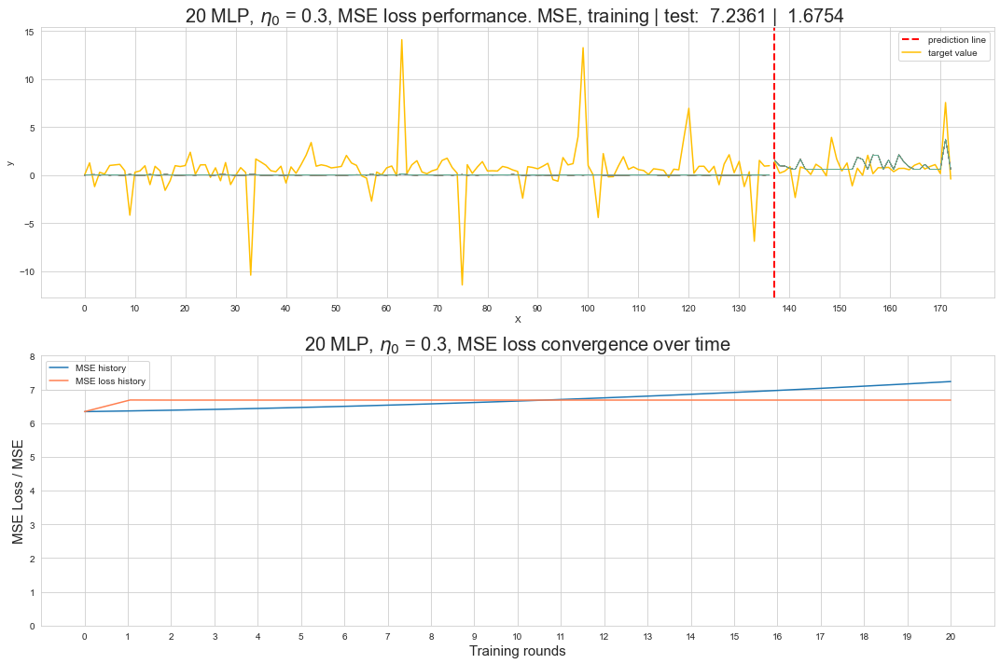

In [570]:
Gradboost_MLP = GBoost(classifier = 'MLP', loss_function = 'MSE', n_estimators = 20, learning_rate = 0.3, seed = 21, measure='MSE',
                       optimiser = 'SGD', hidden_layer_sizes = (1, ), n_epochs = 1, activation = 'relu', 
                       alpha = 0.1, beta2 = 0.5, beta3 = 0.5)
Gradboost_MLP.fit(X_train, y_train)
Gradboost_MLP.predict(X_test)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))
ax1 = model_pred_plot(X_train, y_train, X_test, y_test, Gradboost_MLP, ax = ax1)
ax2 = loss_convergence_plot(Gradboost_MLP, ax = ax2)
plt.tight_layout()

That being said, it is amusing to play with the MLP. So for fun let's look at one more using an 'adam' optimiser, hidden layers of 10 and 5 perceptrons, 100 epochs and the tanh activation funtion. 
Adam, adaptive moment estimation uses the first and second moments of the gradients for weights and biases to control the model's learning rate. Previously we used stochastic gradient descent which updates weights and biases by using a random batch of data points each epoch (bagging) leading to better generalisation. 
Which we see here... but I set it up this way.

In the below model the fit to test data is hilarious. The predictios follow the shape more or less, only magnified. The MLP has been reinforced through layers and perceptron 100 times. Generalising poorly. The tanh activation functions introduces non-linearity. In anycase, this model is only here to demonstrate that complexity is not helpful for the GBM. Yet, a complex MLP is better still than a complex tree. 

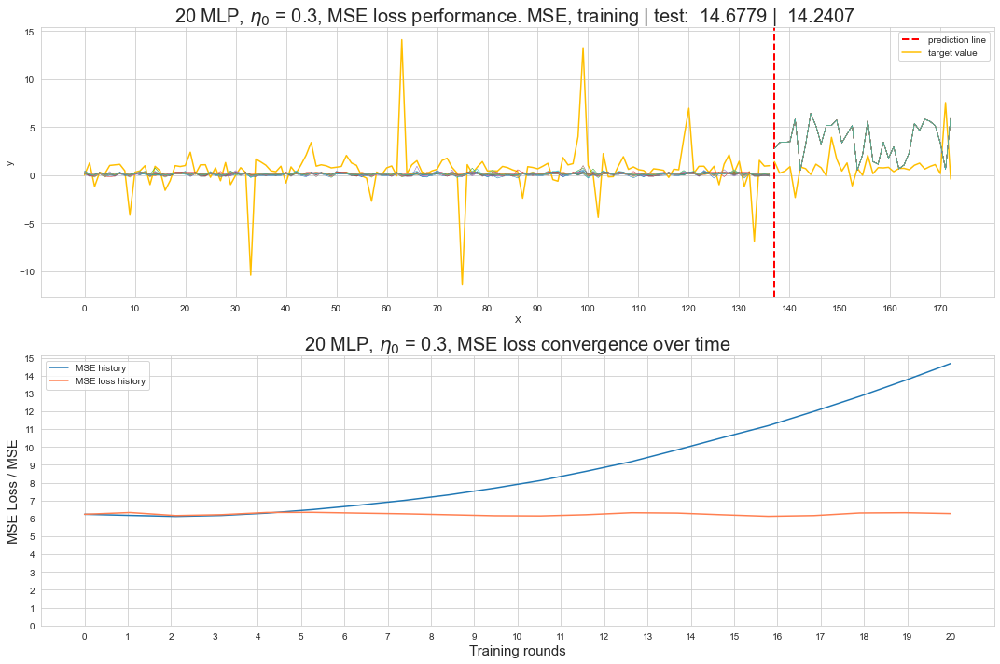

In [580]:
Gradboost_MLP = GBoost(classifier = 'MLP', loss_function = 'MSE', n_estimators = 20, learning_rate = 0.3, seed = 21, measure='MSE',
                       optimiser = 'adam', hidden_layer_sizes = (10, 5), n_epochs = 100, activation = 'tanh', 
                       alpha = 0.1, beta2 = 0.5, beta3 = 0.5, epsilon3 = 1e-8)
Gradboost_MLP.fit(X_train, y_train)
Gradboost_MLP.predict(X_test)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))
ax1 = model_pred_plot(X_train, y_train, X_test, y_test, Gradboost_MLP, ax = ax1)
ax2 = loss_convergence_plot(Gradboost_MLP, ax = ax2)
plt.tight_layout()

## 1.3.3 XGBOOST:
[Back to top](#Index)   |  [To section head](#Task-1:-GRADIENT-BOOSTING-IMPLEMENTATION)  |  [XGBoost class](#XGBoost-tree-booster-class)

Once one has done a decision tree and MLP (which uses gradient descent), it is only a hop, skip and a jump to XGBoost. So, as a bonus, I implemented XGboost. For this I borrowed the treebooster of Matt Bowers (2022) making minor adjustments to integrate it with my GBM.

I won't spend too much time on this, only t enough to point out that XGboost and gradient boost work very differently. Our earlier model of GBM had 20 estimators and a learning rate of 0.3. It did alright. More estimators probably means better predictions. So here we will look at 300 and copare GB< to XGB. 

XGB uses tree boosters, which are like a tree, but faster, using the second derivative (hessian) of the loss function with respect to the residuals. This makes it very fast and good with deep trees. With 300 iterations and trees of depth 10, the two models are coparable. Testing MSE of 1.15 for XGB vs 1.11 for GBM. 
One sees that the error of XGB falls faster than that of GBM, and perhaps somewhere out in the distance over takes it. Notice that with this many iterations each model more or less predicts a straight line and a apike at the end. This is curious. As iterations increase the models settle on predicting just above zero. This is due to the influence of outliers. The trainign data has pretty balalce outliers up and down, but the test data has only one decent one in the positive direction. Hence, the jump in the prediction line for the test data. Note that XGB is able to somewhat better fit the shape of the test data with two dips between $x = 150$ and $x =160$. 

Overall the two models are comparable, but the predictions do not fit the data shape well at all. 

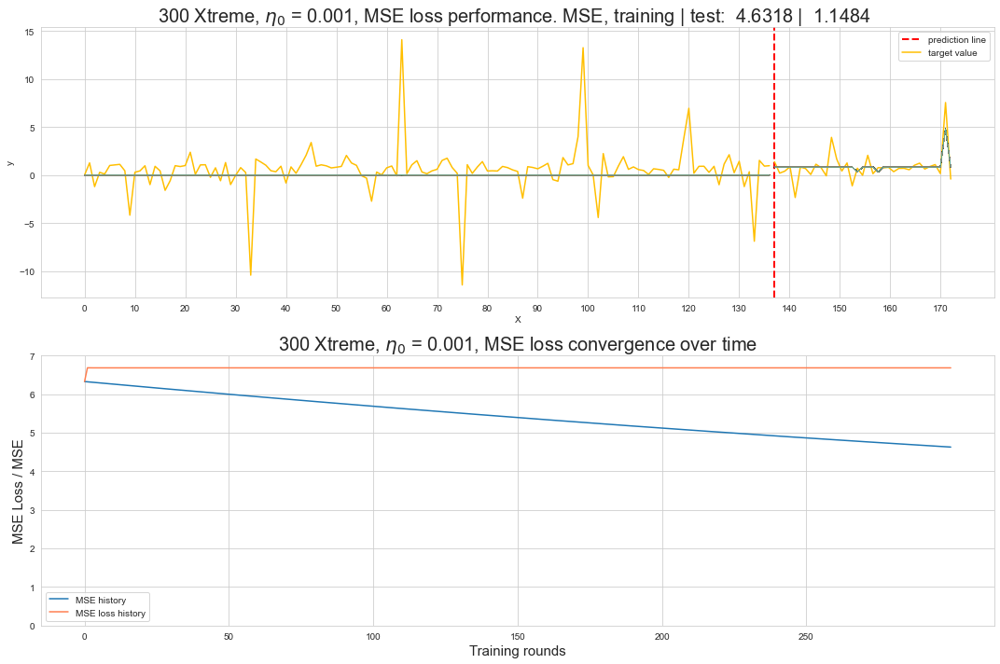

In [623]:
Grad_Xtreme = GBoost(classifier = 'Xtreme', n_estimators = 300, learning_rate = 0.001, seed = 21, loss_function = 'MSE',
                    max_depth = 10, delta = 0.1, tau = 1, reg_gamma = 30, reg_alpha = 30, reg_lambda = 0.00001,
                    colsample_bynode = 0.1, min_child_weight = 0.001, base_prediction = y_train.mean())
Grad_Xtreme.fit(X_train, y_train)
Grad_Xtreme.predict(X_test)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))
ax1 = model_pred_plot(X_train, y_train, X_test, y_test, Grad_Xtreme, ax = ax1)
ax2 = loss_convergence_plot(Grad_Xtreme, ax = ax2)
plt.xticks(np.arange(0, 300, step=50))
plt.tight_layout()

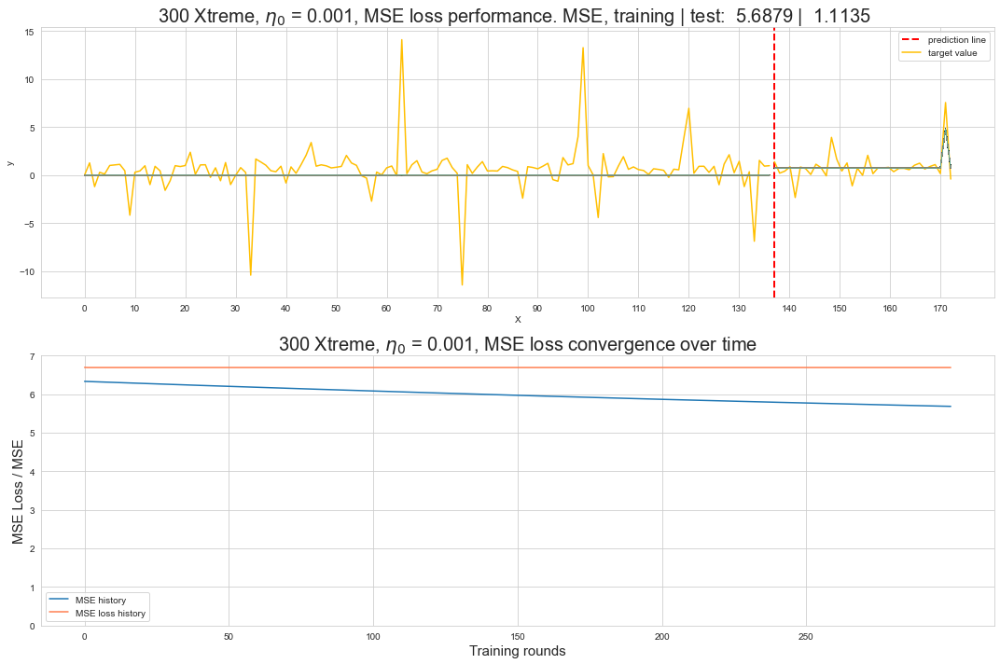

In [619]:
Grad_boost = GBoost(classifier = 'Xtreme', n_estimators = 300, learning_rate = 0.001, seed = 21, loss_function = 'MSE')
Grad_boost.fit(X_train, y_train)
Grad_boost.predict(X_test)
# Grad_boost_MLP.loss_history

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))
ax1 = model_pred_plot(X_train, y_train, X_test, y_test, Grad_boost, ax = ax1)
ax2 = loss_convergence_plot(Grad_boost, ax = ax2)
plt.xticks(np.arange(0, 300, step=50))
plt.tight_layout()

## Task 1.4 Modify the Learning Rate Schedule
[Back to top](#Index)   |  [To section head](#Task-1:-GRADIENT-BOOSTING-IMPLEMENTATION) |[To Template section](#Task-1:-Gradient-Boosting-Implementation-(25-Marks))


Modification of the learning rate can be done via Sklearn call back functions or via paramters such as decay. Either post hoc or prehoc. I do not much like post hoc alterations, so instead I have implemented a series of decay functions which alter the learning rate as the model trains. 

The whole purpose of decay is to have the model's first iterations capture most of the variation in the data, then to slow down. Later iterations add less variation to the model, and hence the model converges on the loss function faster. Or that is the plan. We will see how some methods work out. 

These are:

**Note**: in the below equations $t$ represents time (iterations). 

* **exponential decay** under two formulae, exponential and exponential2 respectively:
    * which lets larger decay adjustments decrease quickly to smaller ones so later training rounds add less new variance to the model's performance. 

$$H(t) = \eta * e^{-\lambda t}$$
and exponential2: $$\eta(t) = \lambda * \eta^t$$


* **Adagrad or gradient decay**: 
 * I adapted this from MLPs where the adaptive gradient decay is the sum of the residual squared errors as a ratio of the current learning rate. This gets small very fast if the errors are big, so it can hanlde a larger learning rate to begin with. I.e. it has a steep loss surface in the begining. 
 

$$H(t) = \frac{\eta}{\sum(\hat{y}_t-y_t)^2}$$
   

* **Probabalistic decay**, such as beta decay, picking the PDF value at time t:
    * For this I was inspired by beta decay and an implementation called BetaBoost by Bloom (2021). The beta distribution n can be swapped for any in my implementation. The benefit of this is that one can see the shape of the decay and alter it to be whatever they like. Having a low $\eta$ intially, then a large one then a small one or one that gently peeters off. It is quite fun. 
    
$$H(t) = \frac{t^{\alpha - 1}(1-t)^{\beta -1}}{B(\alpha, \beta)}  $$

* **Linear decay**
    * $\eta$ decays in a linear fashion as per the lambda coefficient. This si simple and easy ot understand. Higher lambda, faster decay. 
    
$$H(t) = \eta - \lambda * t $$

* **Polynomial decay**, where b is a polynomial degree:
    * Much like linear, but more controllable. A larger power leads to a slower decay, while a smaller one results in faster decay. The decay rate is gradually reduced based on the current iteration as the smallest multiple of the original number of iterations, or decay steps, that is greater than the current iteration number. 
    
$$H(t) = \eta_0 - \omega * (1 - \frac{t}{n * \lceil \frac{t}{n} \rceil})^b + \omega $$

where $\omega$ is the final decay rate, $n$ is the number of estimators and $b$ is the power of the polynomail

* **Inverse time decay**: n is number of iterators
    * ensures a continous step like decay over time. Where the decay rate is inversely proportional to the number of iteratsions.
$$H(t) = \frac{\eta}{1+\lambda \lfloor \frac{t}{step} \rfloor} $$

* **Step decay**: $\lambda$ becomes drop rate (decay)
    * very simply, holding the decay rate for some period of t, then decreasing it by a constat amount each period. A constant reduction, constantly. 

$$H(t) = \eta * \lambda ^{\lfloor (1+t / step) \rfloor } $$

* **Logisitic decay**
    * where the decay rate follows a logistic curve. Faster a first, then slowing down. Unlike exponential decay, logistic decay has a 'carrying capacity' where it will asymptote somewhere along the way. 
    
$$H(t) = \frac{\eta}{1+e^{-\lambda(t-t_0)}}  $$

* adaptive decay, which lacks a formula because I haven't figured it out yet. 
    * As far as I am aware, this is my own invention. For this method, the residuals gradients are calculated each round. The decay rate is variable for each observation, not the aggregation thereof. For this I used the Adagrad formula as it was handy. Then, at the end, then final 'boosted decay' is testing against a battery of distributions to find the one that best fits the gradient of the decay. Use a Kolmogorov-Smirnov test. This distribution is saved and used to adaptively decay $\eta$ for the test data. I have no idea how it will turn out, but we shall see!


Here again we shall keep a 20 iteration stump model as the base on which to experiment. 

decay ( 𝜂𝑛
 ): if this value is set, along with a decay function, the learning rate is adaptively modified at each boosting round by this value. defauls = None.

decay_function: how the decay is applied. Supported: exponential, exponential2, gradient, probabalistic, logistic, linear, polynomial, inverse (inverse time), step and adaptive. Default = None.

For logistic decay,  𝜂𝑛
  must be high if  𝜂0
  is less than 1. And vice versa.
For linear decay,  𝜂𝑛
  must be low, less than 1. Else it gets strange.
For step decay, a high  𝑒𝑡𝑎𝑛
  results in a faster descent.
For adaptive decay, only specify the function.
For probabalistic decay, only provide the pdf as a scipy.stats object: st.beta.pdf(np.linspace(0, 1, 50), 2, 3, loc= 0, scale = 1.5).
distribution: holds the probability density function for probabalistic decay. Default = None.

decay_steps: the number of steps between applications of decay for step and inverse time decay functions. Default = 1.

power: the polynomial degree for polynomial decay Default = 1.

𝜔
 : the final decay rate to which polynomial decay deacys to

𝜖3
 : penalty term for adaptive decay. Default = 1e-8. Smaller values make faster convergence.

For the probabilistic decay, the shapes of the two distributions we shall use, a beta and a normal, are:

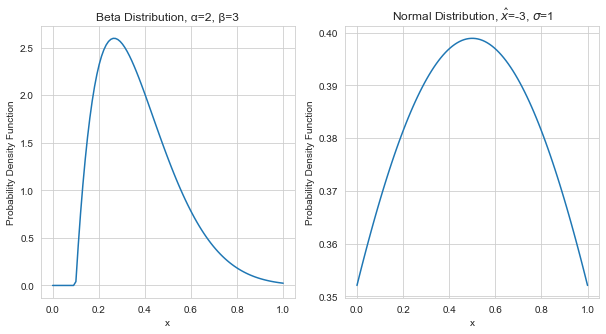

In [17]:
beta_dist = st.beta.pdf(np.linspace(0, 1, 100), 2, 9, loc= 0.1, scale = 1.5)
norm_dist = st.norm.pdf(np.linspace(0, 1, 100), 0.5, 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1 = plot_pdf(beta_dist, 'Beta', 'α=2, β=3', ax=ax1)
ax2 = plot_pdf(norm_dist, 'Normal', '$\hat{x}$=-3, $\sigma$=1', ax=ax2)

plt.show()

In [27]:
exp_decay1 = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.9, seed = 21, loss_function = 'MSE', 
                                decay_function = 'exponential', decay = 0.1, decay_steps = 1, power = 2, omega = 0.001, epsilon3 = 1e-8,
                                distribution = None)
exp_decay1.fit(X_train, y_train)

exp_decay2 = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.9, seed = 21, loss_function = 'MSE', 
                                decay_function = 'exponential2', decay = 0.1, decay_steps = 1, power = 2, omega = 0.001, epsilon3 = 1e-8,
                                distribution = None)
exp_decay2.fit(X_train, y_train)

adagrad_decay = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.9, seed = 21, loss_function = 'MSE', 
                                decay_function = 'gradient', decay = 0.1, decay_steps = 1, power = 2, omega = 0.001, epsilon3 = 1e-8,
                                distribution = None)
adagrad_decay.fit(X_train, y_train)

beta_decay = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.9, seed = 21, loss_function = 'MSE', 
                                decay_function = 'probabalistic', decay = 0.1, decay_steps = 1, power = 2, omega = 0.001, epsilon3 = 1e-8,
                                distribution = beta_dist)
beta_decay.fit(X_train, y_train)

norm_decay = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.9, seed = 21, loss_function = 'MSE', 
                                decay_function = 'probabalistic', decay = 0.1, decay_steps = 1, power = 2, omega = 0.001, epsilon3 = 1e-8,
                                distribution = norm_dist)
norm_decay.fit(X_train, y_train)

linear_decay = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.9, seed = 21, loss_function = 'MSE', 
                                decay_function = 'linear', decay = 0.045, decay_steps = 1, power = 2, omega = 0.001, epsilon3 = 1e-8,
                                distribution = None)
linear_decay.fit(X_train, y_train)

Polynomial_decay_2 = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.9, seed = 21, loss_function = 'MSE', 
                                decay_function = 'polynomial', decay = 0.1, decay_steps = 1, power = 2, omega = 0.001, epsilon3 = 1e-8,
                                distribution = None)
Polynomial_decay_2.fit(X_train, y_train)

Polynomial_decay_3 = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.9, seed = 21, loss_function = 'MSE', 
                                decay_function = 'polynomial', decay = 0.1, decay_steps = 1, power = 3, omega = 0.001, epsilon3 = 1e-8,
                                distribution = None)
Polynomial_decay_3.fit(X_train, y_train)

inverse_decay = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.9, seed = 21, loss_function = 'MSE', 
                                decay_function = 'inverse', decay = 0.1, decay_steps = 2, epsilon3 = 1e-8,
                                distribution = norm_dist)
inverse_decay.fit(X_train, y_train)

step_decay = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.9, seed = 21, loss_function = 'MSE', 
                                decay_function = 'step', decay = 0.1, decay_steps = 5, epsilon3 = 1e-8,
                                distribution = None)
step_decay.fit(X_train, y_train)

logistic_decay = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.9, seed = 21, loss_function = 'MSE', 
                                decay_function = 'logistic', decay = 0.1, decay_steps = 2, epsilon3 = 1e-8,
                                distribution = None)
logistic_decay.fit(X_train, y_train)

adaptive_decay = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.9, seed = 21, loss_function = 'MSE', 
                                decay_function = 'adaptive', epsilon3 = 1e-8)
adaptive_decay.fit(X_train, y_train);



Best fitting distribution: weibull_min


After fitting each model with its decay schedule we can see the shape of their decay curves. Mostly, they are what we expect, though in some instances they aren't exactly. Our beta and normal distribution decays are not the exact shape of the distributions in their inputs. This is because at each t, the model took the corresponding value on the distribution's curve. So when the normal distribution is at t = 1, the curve is ascending steepy, which corresponds to a steep drop in $\eta$. At the elbow is that hit the minimum learning rate, and from there it rises slightly. We can interpret the logstic curve the same way. The decay curve follows the rate of change of the deacy with respect to the probability curve. 

Then there is the adaptive decay curve(s). A lovely post modernist art piece. This shows each iterations gradients for each observation. They start off with a large variation and realtive range, but begin to converge as t increases to some as yet unkonwn value. Looks like it could be 0. 

All this is well and good, but the real question is how did these models perform on the test data?

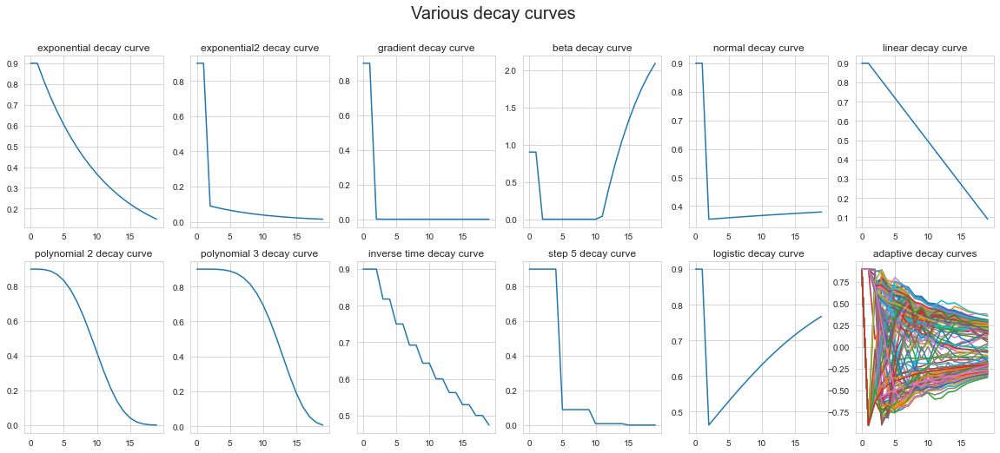

In [257]:
models = [exp_decay1, exp_decay2, adagrad_decay, beta_decay, norm_decay, linear_decay, Polynomial_decay_2, 
         Polynomial_decay_3, inverse_decay, step_decay, logistic_decay] #11 models
labels = ['exponential', 'exponential2', 'gradient', 'beta', 'normal', 'linear', 'polynomial 2', 'polynomial 3', 'inverse time',
         'step 5', 'logistic']
# colors = ['blue', 'green', 'gold', 'olive', 'coral']

fig, axes = plt.subplots(nrows = 2, ncols = 6, figsize=(20, 8))
for ax, model, l in zip(axes.flat, models, labels):
    lst = []
    for i in range(20):
        lst.append(model.eta_history[i][0])
    ax.plot(lst, label = l)
    ax.set_title(f'{l} decay curve')
axes[1][5].plot(adaptive_decay.eta_history)
# axes[1][5].set_xlim(0, 19)
axes[1][5].set_title('adaptive decay curves')

plt.suptitle('Various decay curves', size = 20)
plt.show()

Incidently, the adaptive decay model's posterior distribution for decay was a minimum weibull distribution shaped like this:

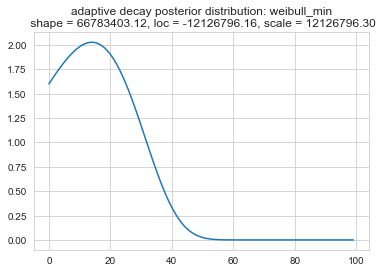

In [129]:
plt.plot(adaptive_decay.distribution.pdf(np.linspace(0,1,100)))
plt.title(f'adaptive decay posterior distribution: {adaptive_decay.distribution.dist.name}\n shape = {adaptive_decay.distribution.args[0]:.2f}, loc = {adaptive_decay.distribution.args[1]:.2f}, scale = {adaptive_decay.distribution.args[2]:.2f}' )
plt.show()

In the below charts and table we compare the training MSE vs the validation MSE for each of the decay rates.
The control is a thte top. This is a model with $eta_0$ set to 0.3. 
We need some way to compare these different configurations, so I decided to use, as a heuristic, the integral between the two curves over the interval defined by the number of iterators. This provides a area value that is larger if the difference is large between the training and validation scores, and small otherwise. 
It needs ot be considered alongside the graphs, because the size will be dependent on the data set and the shape. It is heuristic because the area can be large if, at one end of the area there is a large istance while at another the distance is small, but the curves are converging while also having a better MSE than the control. However, you can get an idea. Areas that are wildly large have no business being considered, like the beta decay model using the input distribution. 

What we see is mixed results. Our best decay schedule is the normal distribution curve, which, if we recall, had a rate of change which increased until 0.5 and then decreased. Resulting in a validation MSE of 0.97 to the control's 1.73. The adaptive decay is also marginally better with MSE of 1.72, for which I am quitely stoked about. Inverse time and exponential also did better, but only marginally so. 

Looking at the shape of the curves is revealing as it shows that we can obtain some very stable validation MSE scores. All those with more or less horizontal validation score lines. Though, these are only stable realtive to the training scores. So I included these alone at the bottom next to the table, splitting the beta curve out so as not to flatten the others. 

We see that adagrad decay (gradient), both polynomials and step 5 decay are very linear, either indicating an early descent to robustness or overfitting. 

What we see more generally is that by using a decay function, we can find convergence to a small MSE (perhaps as best as the model can do) much quicker than without. Decay function dependant. Sometimes as early as two iterations. Such early convergence means we could stop there, taking high bias in model predictions with faster computation, but less variance. As we will see below, this does not translate to better predictions, as the domain of the data may need variance. The economy is a very complex domain. So perhaps a bit more variance is necessary.


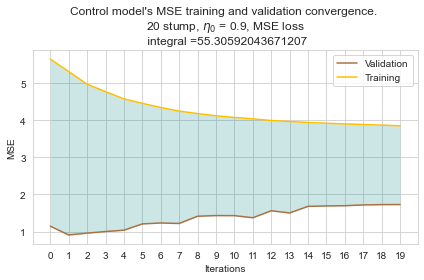

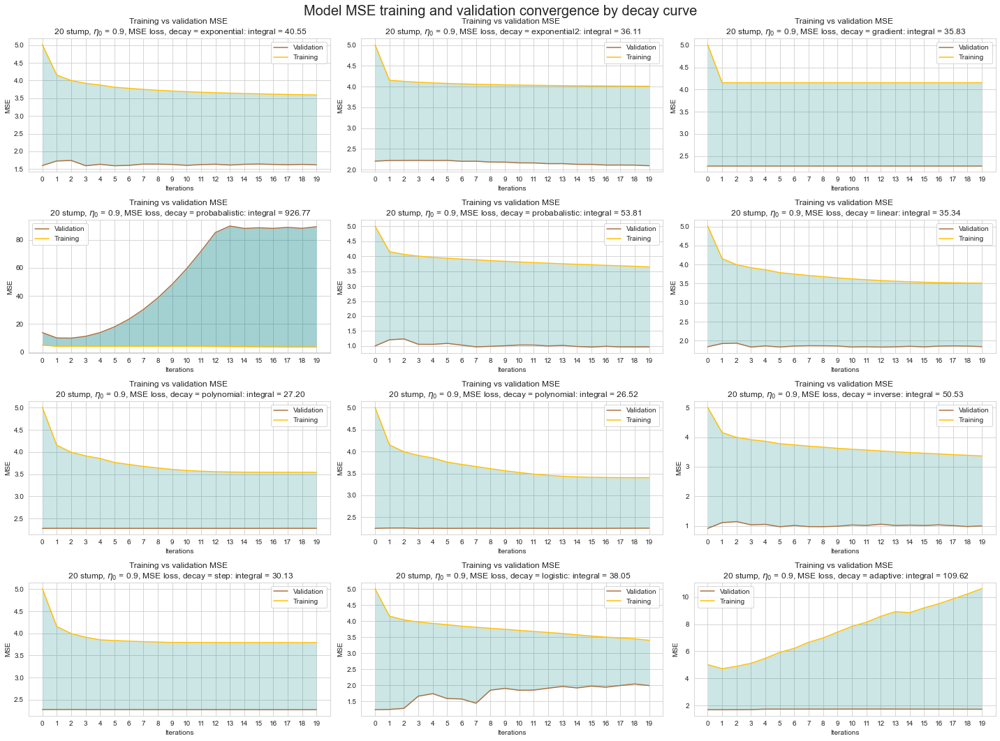

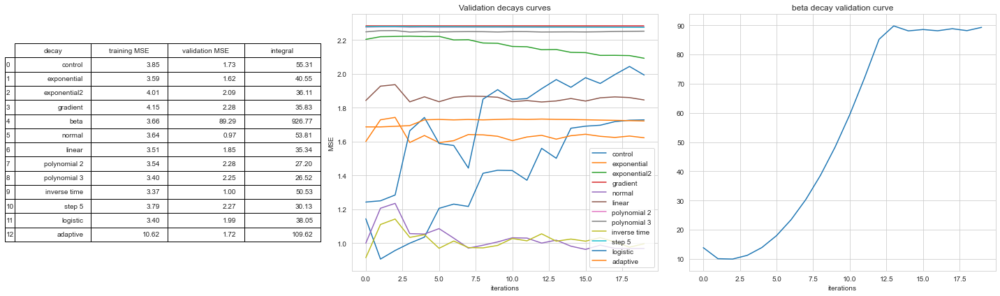

In [320]:
# Grad_boost.predict(X_test)
Grad_boost._validate(X_test, y_test)

models = [exp_decay1, exp_decay2, adagrad_decay, beta_decay, norm_decay, linear_decay, Polynomial_decay_2, 
         Polynomial_decay_3, inverse_decay, step_decay, logistic_decay, adaptive_decay]
for model in models:
    model.predict(X_test)
    model._validate(X_test, y_test)

plot = validation_score_plot(Grad_boost)
plt.title(f"Control model's MSE training and validation convergence. \n{model.model_name}\n integral ={simps(np.abs(np.array(Grad_boost.score_history) -  np.array(Grad_boost.validation_score)), np.arange(0, Grad_boost.n_estimators, 1))}")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(nrows = 4, ncols = 3, figsize=(20,15))
for ax, model in zip(axes.flat, models):
    ax = validation_score_plot(model, ax = ax)

plt.suptitle('Model MSE training and validation convergence by decay curve', size = 20)
plt.tight_layout()
plt.show()

models = [Grad_boost, exp_decay1, exp_decay2, adagrad_decay, beta_decay, norm_decay, linear_decay, Polynomial_decay_2, 
         Polynomial_decay_3, inverse_decay, step_decay, logistic_decay, adaptive_decay] #11 models
labels = ['control', 'exponential', 'exponential2', 'gradient', 'beta', 'normal', 'linear', 'polynomial 2', 'polynomial 3', 'inverse time',
         'step 5', 'logistic', 'adaptive']
area = []
train = []
val = []

for model in models:
    train.append(model.score_history[-1])
    val.append(model.validation_score[-1])
    area.append(simps(np.abs(np.array(model.score_history) -  np.array(model.validation_score)), np.arange(0, model.n_estimators, 1)))


# df[['training MSE', 'validation MSE', 'integral']] = df[['training MSE', 'validation MSE', 'integral']].applymap('{:.2f}'.format)

fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(20, 6))

models.remove(beta_decay) 
labels.remove('beta')
for model, l in zip(models, labels):
    ax2.plot(model.validation_score, label = f'{l}')
    ax2.legend()
    ax2.set_title('Validation decays curves')
    ax2.set_ylabel('MSE')
    ax2.set_xlabel('iterations')
ax3.plot(beta_decay.validation_score)
ax3.set_title('beta decay validation curve')
ax3.set_xlabel('iterations')

table = ax1.table(cellText=df.values, colLabels=df.columns, rowLabels=df.index, loc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.5)
ax1.set_axis_off()
fig.tight_layout()
plt.show()

Looking at the three best models, we can see how the training and the testing fits worked out. In third place we have adaptive decay, which is not over fit at all, nor is it settling on predictions in training. Hence the increase we saw in the training line and the large integral area. This alone doesn't mean much as it work completely differently from the other decay models. Generating a posterior probability from the moment-wise deacy of each prediction, which in turn is used to fit moment-wise decay during the fitting process. This leads to slightly better performance than the control model. 

Inverse time and the normal distribution have differnt ways to arrive at similar results. Their fits to training and test data are almost identical. 

Despite each mode being very similar in the final fit, we can see that despite the score they don't really fit the data well at all. This data set is beset with extreme events and outliers. The model has found that the best way to minimise the gradient of the loss function with respect to the residuals is to predict close to the mean. Resulting in predictions biased towards the mean. Which is not wrong. They have minimised the residuals as per the inputs. We can't simply trust the MSE score. What we need is a model that has more variance or can account somehow for extreme events. 

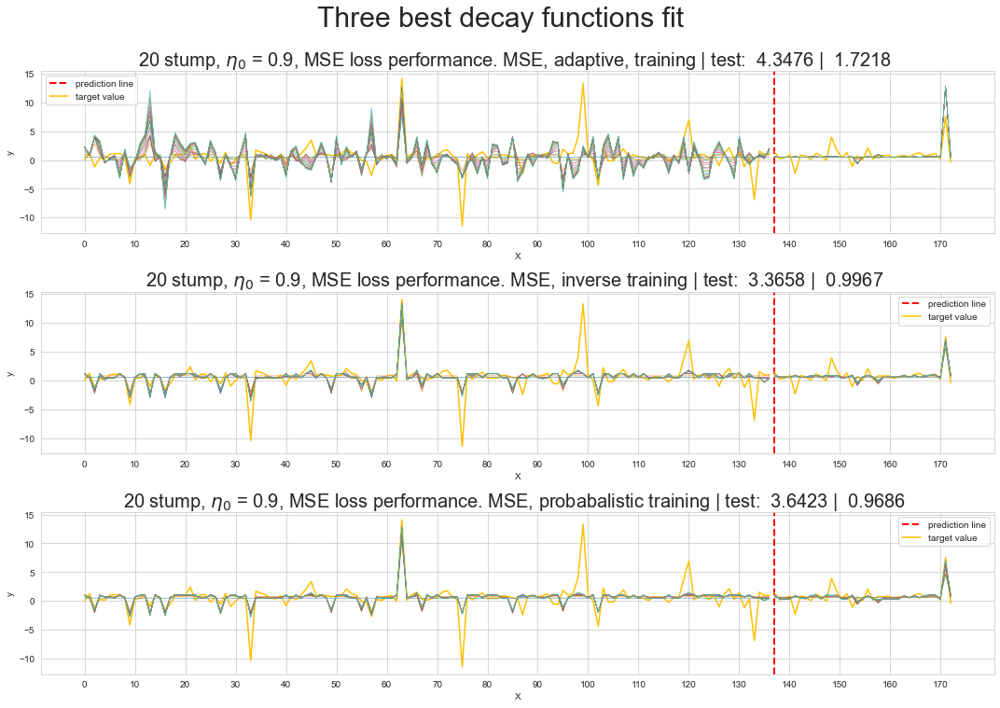

In [32]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 10))
ax1 = model_pred_plot(X_train, y_train, X_test, y_test, adaptive_decay, ax = ax1)
ax2 = model_pred_plot(X_train, y_train, X_test, y_test, inverse_decay, ax = ax2)
ax3 = model_pred_plot(X_train, y_train, X_test, y_test, norm_decay, ax = ax3)
plt.tight_layout()
plt.suptitle('Three best decay functions fit', size = 30, y=1.05)
plt.show()

## Task 1.5 Early Stopping:
[Back to top](#Index)   |  [To section head](#Task-1:-GRADIENT-BOOSTING-IMPLEMENTATION)

Gradient boosting is in the business of gradient descent. The whole point to to find a minima of the gradient and thereby achieve a stable model. My thoughts we to stopping when no improvement on the gradient of the loss function with respect to the residuals was achieved within some tolerance, and with some allowance to hopfully get out of local minima. 
Like Waldo, I found others had been there before me. 
That is how I have implemented early stopping. The model validates itself after each fit on a validation set of the trianing data, checks if the new gradient loss is less thanbefore minus some tolerance and if not it stops. Or more correctly, it counts and if there is a series of no increases up to the patience score, it stops. 

The only draw back with this is that you then need to fit the reduced model as a new model object in order to plot the full training data as some proportion is kept out. 

The technical trade off is that the model can possibly get caught in a local minima, or stop too soon, thereby not gaining enough variance and being too biased. As an upshot the model can acoid iterations that add useless variance, compute faster and perhaps give better predictions. 

Below I fit the control model and the normal decay model to early stopping regimes. They stopped at 12 and 14 iterations respectively and had test MSEs of 1.37 and 2.2 respectively. 

Which is nice because I get to talk about two different results. For the control model early stopping results in an approximate 0.4 improvement to the testing MSE. Indicating the model has improved perhaps due to being allowed more variance. Which can be seen to some extent with the subtly more varied prediciton lines on the test data. Here we have a happy medium in terms of bais and variance.

While the normal decay model did about 1.2 worse than the full model. Indicating the model hasn't quite learned enough. Primarily due to an overestimation of the final spike in the test data. This model has perhaps too much of variance or bias and needs a bit more one way or the other. Early stopping, therefore, is useful once a decent model has been found to trim off unnecessary iterations. A kind of variance/bias balancing act. 

Now, this spike has been the proverbial thorn in the side of these models. Regardless of how well the training data are fit, the models are able to predict that spike in the test data, and pretty much nothing else. Excepting the MLP which was capable, if prone to be whacky. 

The shape of the data influences the model. Here the shape is very spikey. Full of extreme events. Which is part and parcel of the economic processes that led to the data. So to some degree this is inevtiable, because the spikes are not necessarily caused by the same underlying processes, and so aren't reliably represented in the data set used to fit the model. Despite this, it is interesting that the models are able to predict the spike reliably. That one, and the one lone spike in the training data. Which implies that the underlying processes of these two spikes are similar, if not the same. Likewise for the many negative dips. 

In [163]:
Early_stop = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.3, subsample= None, seed = 21, 
                                 loss_function = 'MSE', validation_fraction=0.2, tolerance=0.1, patience= 2)
Early_stop.fit(X_train, y_train)
Early_stop.predict(X_test);


Early_stopped = GBoost(classifier = 'stump', n_estimators = 12, learning_rate = 0.3, subsample= None, seed = 21, 
                                 loss_function = 'MSE')
Early_stopped.fit(X_train, y_train)
Early_stopped.predict(X_test);

Early_stop_norm = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.3, subsample= None, seed = 21, 
                                 loss_function = 'MSE', validation_fraction=0.2, tolerance=0.1, patience= 2,
                                 decay_function = 'probabalistic', distribution = norm_dist)
Early_stop_norm.fit(X_train, y_train)
Early_stop_norm.predict(X_test);

Early_stopped_norm = GBoost(classifier = 'stump', n_estimators = 14, learning_rate = 0.3, subsample= None, seed = 21, 
                                 loss_function = 'MSE', decay_function = 'probabalistic', distribution = norm_dist)
Early_stopped_norm.fit(X_train, y_train)
Early_stopped_norm.predict(X_test);

Early stopping at iteration 12. Best validation MSE: 4.70561899227925
Early stopping at iteration 14. Best validation MSE: 4.52150039376623


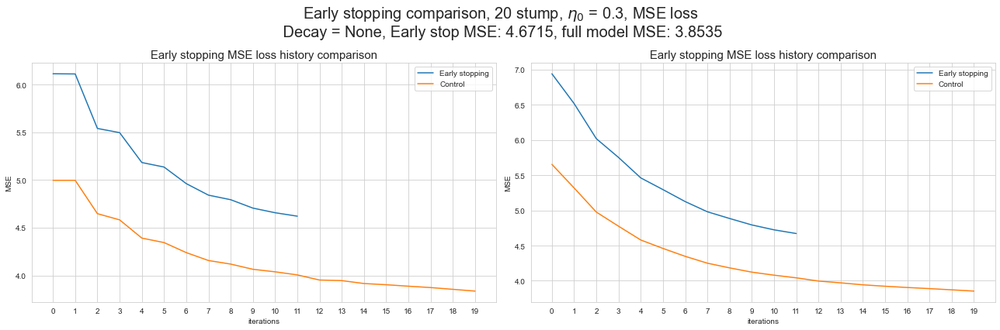

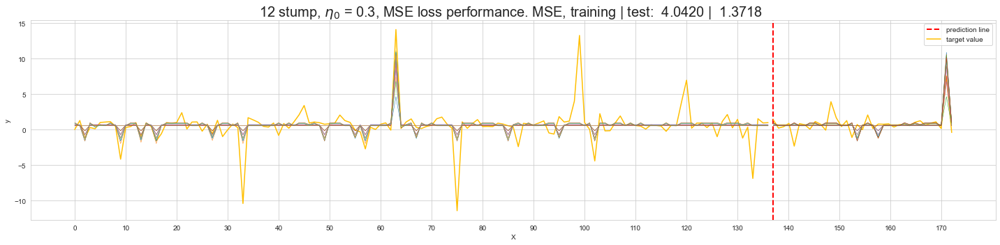

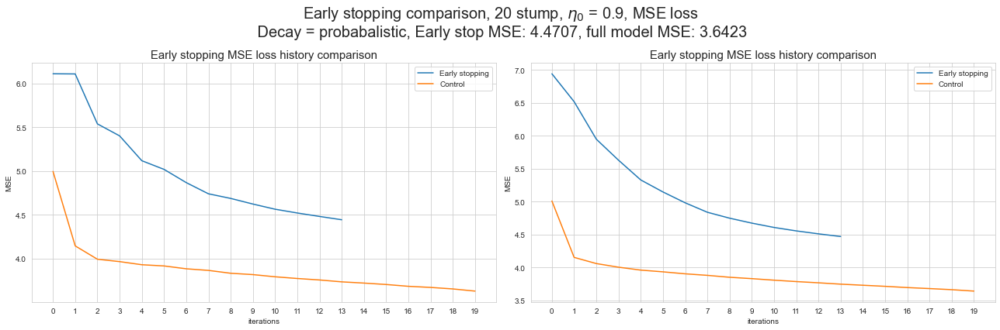

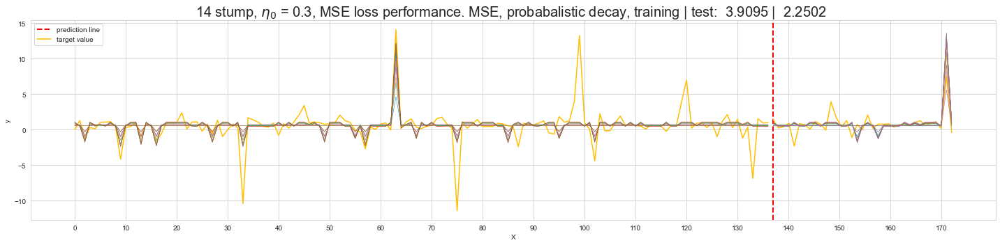

In [164]:
# fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(18, 6))  
fig, axes = early_stop_plot(Early_stop, Grad_boost)
plt.show()

plt.figure(figsize=(20, 5))
model_pred_plot(X_train, y_train, X_test, y_test, Early_stopped)
plt.show()

fig, axes = early_stop_plot(Early_stop_norm, norm_decay)
plt.show()

plt.figure(figsize=(20, 5))
model_pred_plot(X_train, y_train, X_test, y_test, Early_stopped_norm)
plt.show()

I then went on to implement DART boosting (Dropouts meet Multiple Additive Regression Trees). This strategy for model regularisation worked better than early stopping, albeit with this toy model the training MSE of 1.8 is marginlly worse than the unaltered model of 1.7. DARTS is useful later on when fitting the model, because it helps regularise the model when the data is complex, thereby reducing the impact of overfitting, by makign teh model fit a diffferent set of trees/stumps each boosting round. 

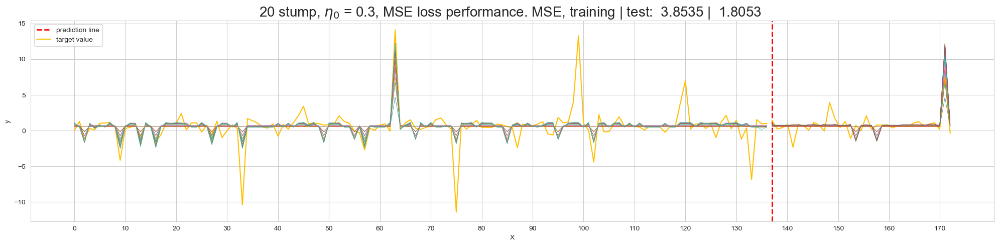

In [43]:
DART = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.3, subsample= None, seed = 21, 
                                 loss_function = 'MSE', drop_rate = 0.2)
DART.fit(X_train, y_train)
DART.predict(X_test);

plt.figure(figsize=(20, 5))
model_pred_plot(X_train, y_train, X_test, y_test, DART)
plt.show()

In the same spirit I implemented subsampling. Using a subsample rate of 0.8 shows that the model regularises better than DARTS in this case, and better than early stopping. Similar reasoning is at play here. The model has to learn on a different random set of the data each boostig round, forcing it to adapt and thereby reducing the overfitting potential. 

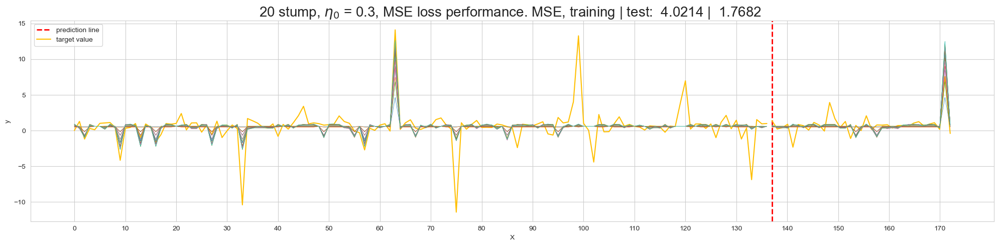

In [45]:
Subs = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.3, subsample= 0.8, seed = 21, 
                                 loss_function = 'MSE')
Subs.fit(X_train, y_train)
Subs.predict(X_test);

plt.figure(figsize=(20, 5))
model_pred_plot(X_train, y_train, X_test, y_test, Subs)
plt.show()

# TASK 2: GRADIENT BOOSTING IN-CLASS FORECASTING COMPETITION
[Back to top](#Index) | [To Template section](#Task-2:-Gradient-Boosting-In-Class-NZ-Inflation-Forecasting-Competition-(35-Marks))

* [2.1. Exploratory Data Analysis](#Task-2.1-Exploratory-Data-Analysis)
* [2.2. Feature Selection](#Task-2.2-Feature-Selection.)
* [2.3. Feature Engineering](#Task-2.3-Feature-Engineering.)
* [2.4. Model Fitting](#Task-2.4-Model-Fitting.)
* [2.4.1 Model Experiments](#2.4.1-Model-Experiments)
* [2.5. Grid Search](#Task-2.5.-Grid-Search)
* [2.6. Final Model](#Task-2.6.-Final-Model)
* [2.7. Walk Forward Validation](#Task-2.7.-Walk-Forward-Validation)
* [2.8. File output](#Task-2.8.-File-Output)
* [2.9. Forecast Q3 2025](#Task-2.9.-Forecast-Q3-2025)

Predicting the consumer price index year on year is going to be interesting. It is a lagging indicator of inflation and is used to calculate it (in non monetarist circles like NZ, althogh it is a microeconomic measure masquerading as a macro one, which makes it at least superior to macros econoic indicators). CPI measures an increase in the cost of a fixed basket of goods collected by data collection specialists employed by Statistics NZ across the country going into shops and surveying the price tags. I know this because I consulted and contracted to Statistics NZ and designed the newer optimised processes and technology system by which these people collect these data. I'll reference myself... (Lavack, 2025). 

The equation for CPI is:

$$ CPI = \frac{updated \space cost}{base \space period \space cost} * 100  $$

Now, given it is a composite score from across the country, and prices vary across the country and even within a single suburb for the prices of the basket goods (dairy milk is about 1.5 to 2 dollars to  more than at the supermarket), the CPI score is already a composite score that gets engineered to a catchey percentage for aggregate analysis and media reporting. 
Like McDonalds, it is highly processed. There is some level of Keynesian absurdity in trying to predict it. The contents of the basket is not fixed either. It contains apparel, food, transport, medical care, recrations, education, sometimes even tolls. There are always about 598 goods in the basket averaged from around 100,000 individual measurement of the same or similar items from abot 2,800 outlets. Every 3 years the contents are updated ostensibly to reflect society spending. The measure being reported is not based on a fixed measuring tool. This is very important to stress. The variability that is hidden due to many aggregation processes is unretrievable from the CPI itself. 

I will once more stress this. The CPI is an aggregate measure of goods across the country (price and location variability caused by local contexts) which changes every three years (has lots of inherent variability) and has a non-standard measuring tool through time meaning that most correlations based on good and services will only be valid for three year time periods. It is a horrible measure and I have a great many problems with. Nevertheless, this is the task at hand. 

From the outset then, one cannot look to the price of good through the years because there is no guarantee that that good or serivce will be in the next basket three years later. Rather, one must look at the aggregate price of things that determine the prices of other things (yuck!). Things like oil, petrol at the pump, transport, the infaltion on traded goods (tradable inflation) and the money supply. I am not partial to the latter because in NZ we calculate inflation using this formula:

$$Inflation Rate = \frac{CPI_{current \space year}-CPI_{previous \space year}}{CPI \space in \space the \space past} * 100 $$

Not the monetary theory equation:

$$\%Change \space in \space P = \%Change \space in \space M - \%Change \space in \space Y $$
Where P is the price level (inflation), M is the money supply and Y is the real GDP
$P = \frac{MV}{y}$ where V is the velocity of money entering and leaving the market.

NZ therefore has no real robust measure of our money supply that is publicly available. 
That we use the CPI measure is a shame. 
In anycase, the strategy will be to use the component parts of CPI to predict it. These are published on the Reserve Bank of NZ website, but are collected by Statistics NZ on their behalf. It is just easier ot get them from the bank because Stats has a horrible data cataloguing standard which I want to stay away from.

## Task 2.1 Exploratory Data Analysis
[Back to top](#Index) | [To section head](#TASK-2:-GRADIENT-BOOSTING-IN-CLASS-FORECASTING-COMPETITION) | [To Template section](#Task-2:-Gradient-Boosting-In-Class-NZ-Inflation-Forecasting-Competition-(35-Marks))

In this section I will only show the variables that I found to be the best fits. They align with my prior theory for the most part. Looking at the the raw dataa and their sesonally decomposed components. Interesting and of note is that the residuals of oil energy prices do not trend well with CPI, but the residauls are very close. Tradable inflation is a dead ringer to CPI. Food, petrol prices and transportationa re also similar. This is because CPI is a composite and contains them. And in NZ, tradable inflation is a big part of our daily costs due to us being at the tail end of global logistic paths where we can be forced to pay extra premiums for low quality imported goods. These values all eventually do make it past feature selection. 

To avoid inadvertent data leakage I split the test data into its seasonal decomposed parts as two data sets. Therefore ensuring that the train data doesn't include information from the future test data


In [40]:
y_train = pd.read_csv('y_train.csv')#.set_index('date')
y_test = pd.read_csv('y_test.csv')#.set_index('date')
y_train['date'] = pd.to_datetime(y_train['date']).dt.strftime('%Y-%m-%d')
y_train['date'] = pd.to_datetime(y_train['date'])
y_test['date'] = pd.to_datetime(y_test['date']).dt.strftime('%Y-%m-%d')
y_test['date'] = pd.to_datetime(y_test['date'])
dates = pd.concat([y_train['date'], y_test['date']])
y_train.set_index('date', inplace=True)
y_test.set_index('date', inplace = True)
y_values = pd.concat([y_train, y_test]) 

#decomposed data as separate sets here to avoid data leakage
y_trTrend, y_trSeason, y_trResid = seasonal_decompose_df(y_train, 'additive', 4)
y_tsTrend, y_tsSeason, y_tsResid = seasonal_decompose_df(y_test, 'additive', 4)
y_trend, y_season, y_resid = seasonal_decompose_df(y_values, 'additive',4)

quarterly = pd.read_csv('CPI.csv')#.set_index('date')
monthly = pd.read_csv('eco_monthly.csv').iloc[::3]#.set_index('date')
X_vars = pd.merge(quarterly, monthly, on = 'date')
X_vars['date'] = pd.to_datetime(X_vars['date'])

X_vars = X_vars.set_index('date')
X_vars = pd.merge(y_values, X_vars, on = 'date')
X_vars = X_vars.replace(',', '', regex=True)
X_vars = X_vars.replace('-', '', regex=True)
X_vars = X_vars.apply(pd.to_numeric, errors='coerce')
X_vars.columns = X_vars.columns.str.strip()
X_vars_trend, X_vars_season, X_vars_resid = seasonal_decompose_df(X_vars, 'additive', 4)

In [41]:
# split to avoid data leakage
X_vars_test = X_vars.loc['2016-03-31':]
X_vars_train = X_vars.loc[:'2015-12-31']

X_vars_train = X_vars_train.interpolate(method='time', limit_direction='both')
X_vars_test = X_vars_test.interpolate(method='time', limit_direction='both')

X_vars_train_trend, X_vars_train_season, X_vars_train_resid = seasonal_decompose_df(X_vars_train, 'additive', 4)
X_vars_test_trend, X_vars_test_season, X_vars_test_resid = seasonal_decompose_df(X_vars_test, 'additive', 4)

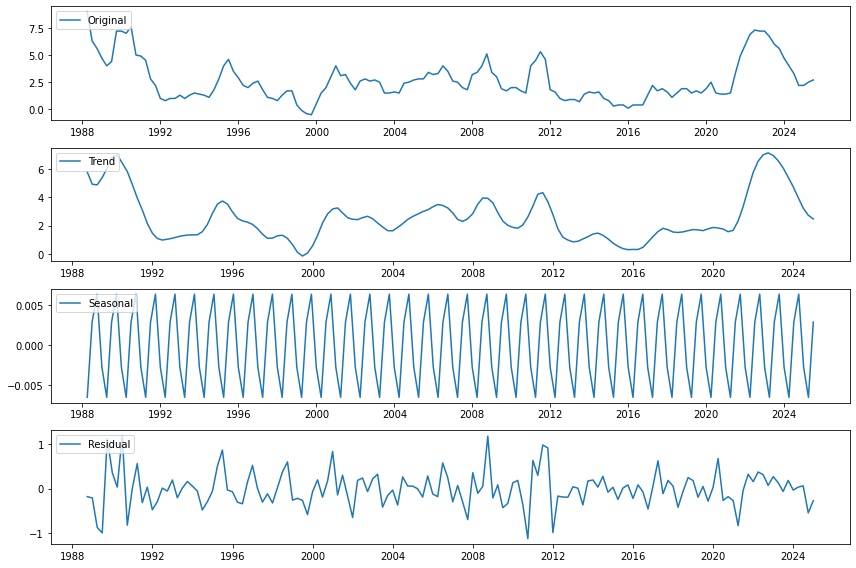

In [23]:
decomposition = seasonal_decompose(y_values.dropna(), model = 'additive', period = 4)

plt.figure(figsize=(12, 8))
plt.subplot(411)
plt.plot(y_values.dropna(), label='Original')
plt.legend(loc='upper left')
plt.subplot(412)
plt.plot(decomposition.trend, label='Trend')
plt.legend(loc='upper left')
plt.subplot(413)
plt.plot(decomposition.seasonal, label='Seasonal')
plt.legend(loc='upper left')
plt.subplot(414)
plt.plot(decomposition.resid, label='Residual')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

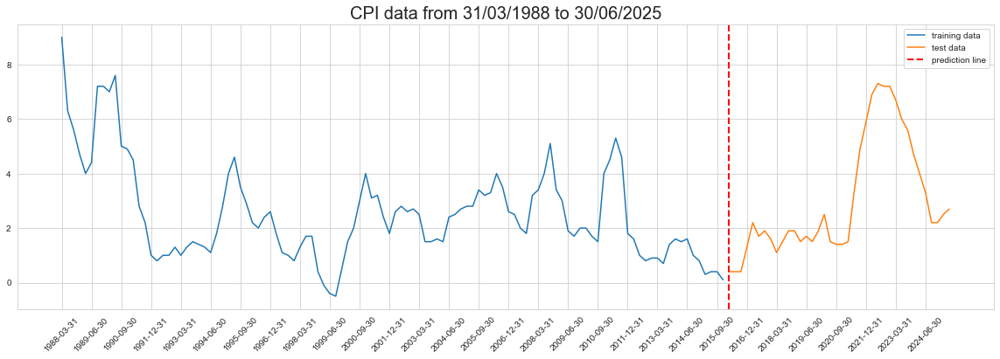

In [23]:
v_line = mdates.date2num(datetime.strptime('2016-03-31', '%Y-%m-%d'))

plt.figure(figsize=(20, 6)) 
plt.plot(y_train['CPIyoy'], label = 'training data')
plt.plot(y_test['CPIyoy'], label = 'test data')
plt.axvline(x=v_line, color='red', linestyle='--', linewidth=2, label = 'prediction line')
plt.xticks(rotation = 45) #dates['date'])
plt.xticks(dates[::5])
plt.title('CPI data from 31/03/1988 to 30/06/2025', size = 20)
plt.legend()
plt.show()

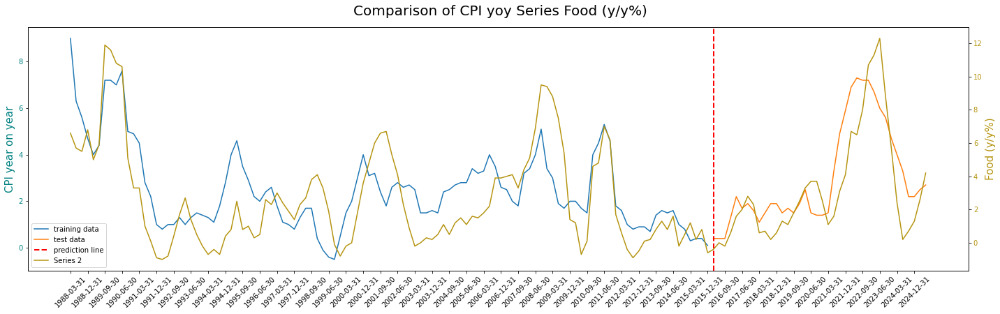

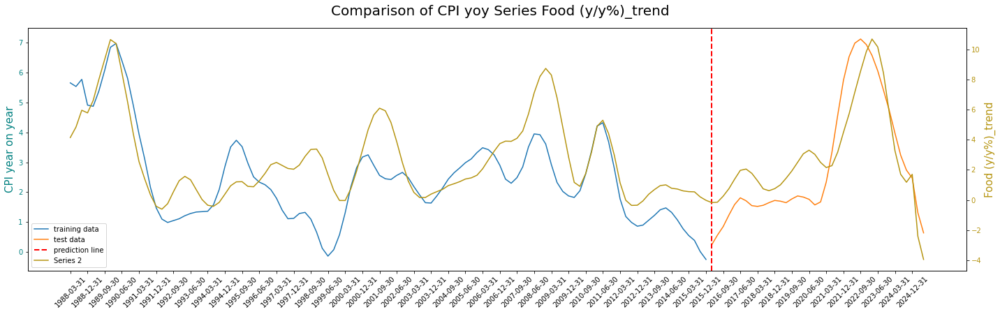

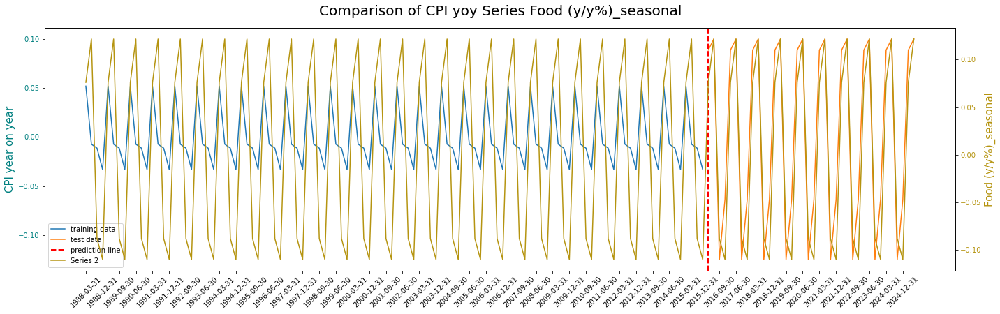

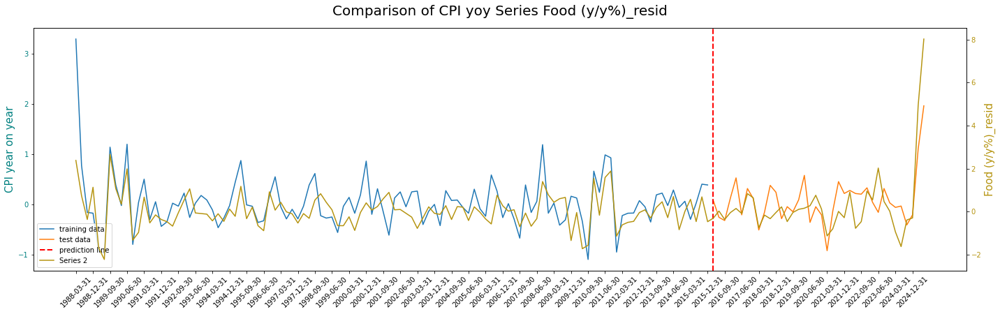

In [198]:
compare_timeseries(y_train, y_test, dates, X_vars['Food (y/y%)'])
compare_timeseries(y_trTrend, y_tsTrend, dates, X_vars_trend['Food (y/y%)_trend'])
compare_timeseries(y_trSeason, y_tsSeason, dates, X_vars_season['Food (y/y%)_seasonal'])
compare_timeseries(y_trResid, y_tsResid, dates, X_vars_resid['Food (y/y%)_resid'])

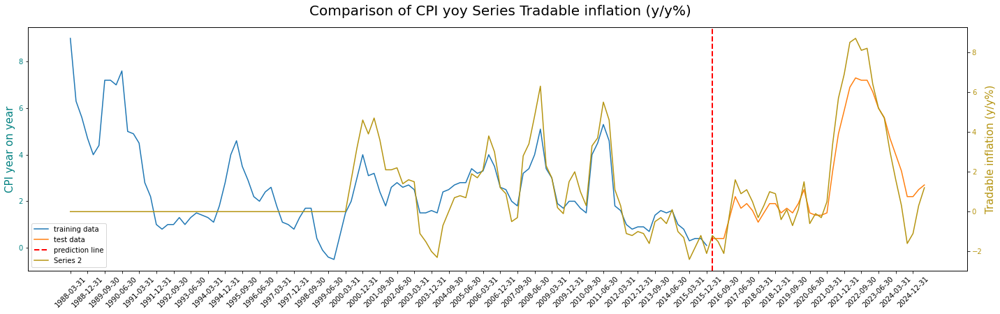

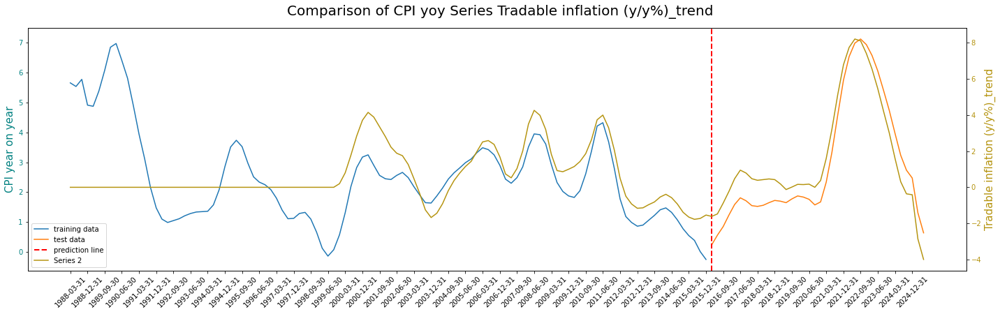

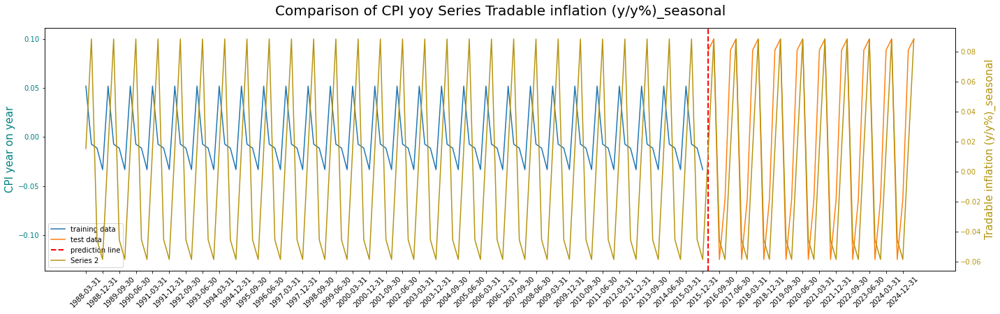

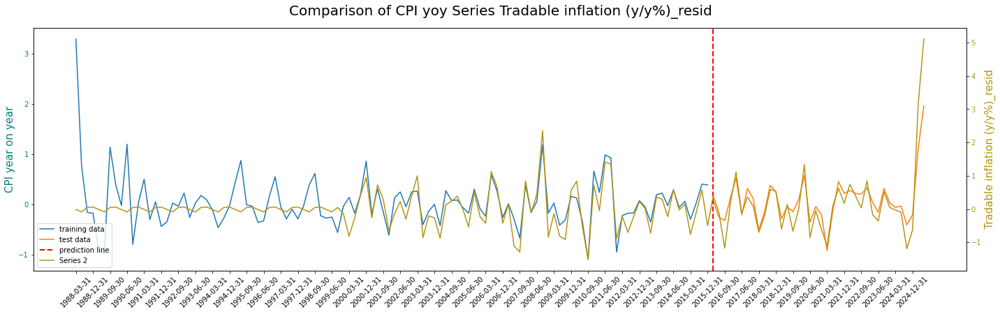

In [197]:
compare_timeseries(y_train, y_test, dates, X_vars['Tradable inflation (y/y%)'])
compare_timeseries(y_trTrend, y_tsTrend, dates, X_vars_trend['Tradable inflation (y/y%)_trend'])
compare_timeseries(y_trSeason, y_tsSeason, dates, X_vars_season['Tradable inflation (y/y%)_seasonal'])
compare_timeseries(y_trResid, y_tsResid, dates, X_vars_resid['Tradable inflation (y/y%)_resid'])

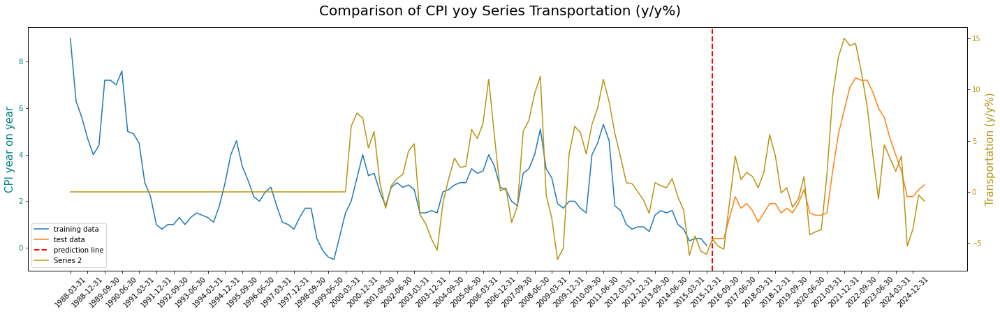

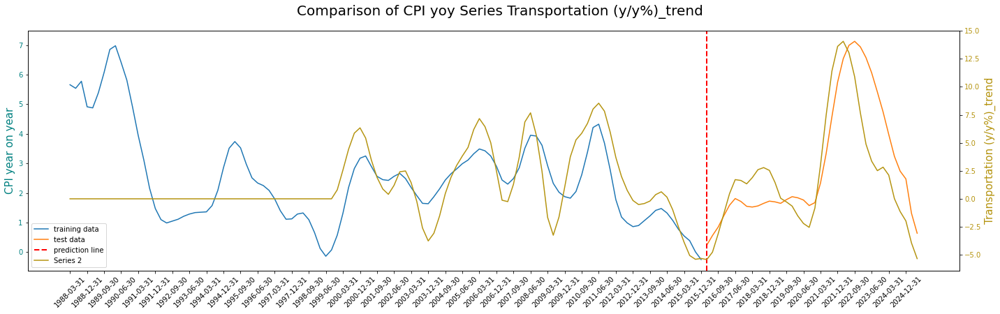

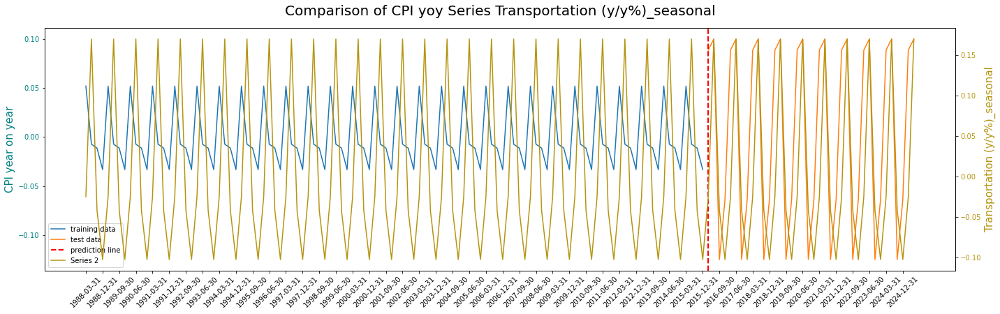

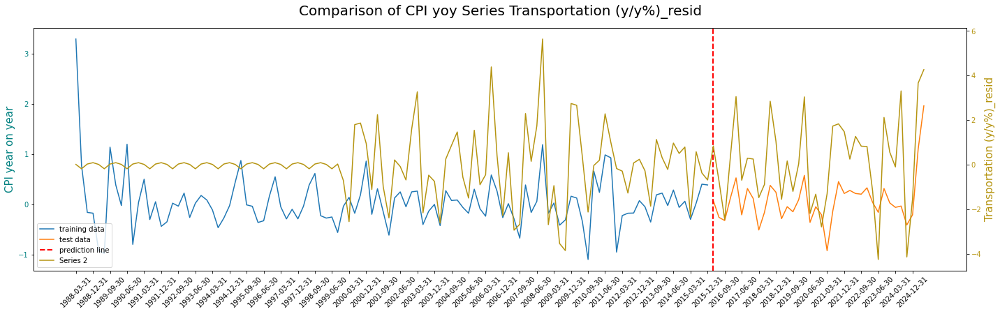

In [196]:
compare_timeseries(y_train, y_test, dates, X_vars['Transportation (y/y%)'])
compare_timeseries(y_trTrend, y_tsTrend, dates, X_vars_trend['Transportation (y/y%)_trend'])
compare_timeseries(y_trSeason, y_tsSeason, dates, X_vars_season['Transportation (y/y%)_seasonal'])
compare_timeseries(y_trResid, y_tsResid, dates, X_vars_resid['Transportation (y/y%)_resid'])

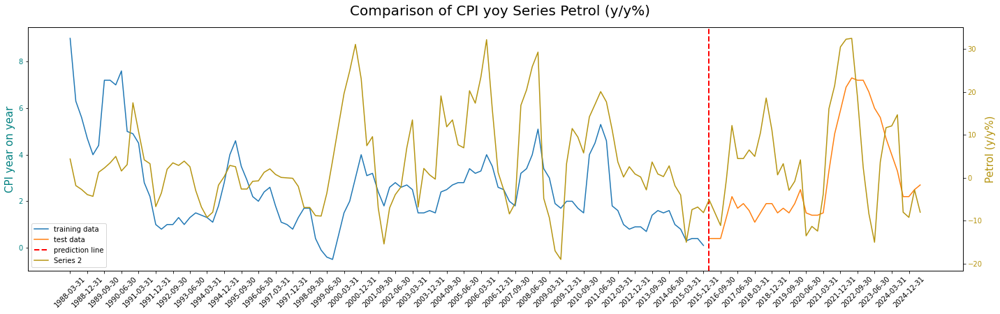

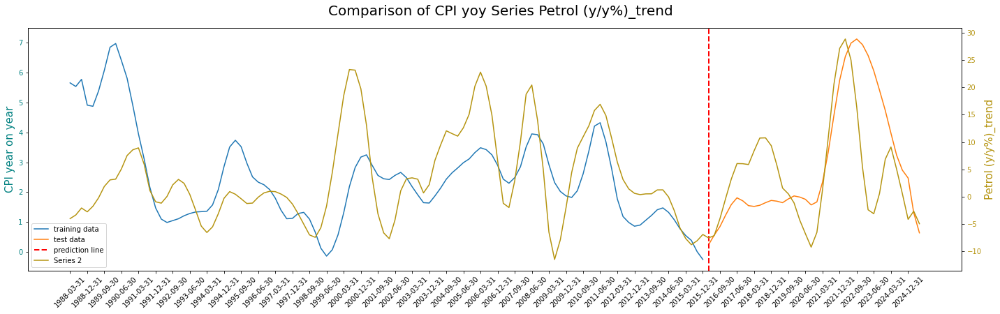

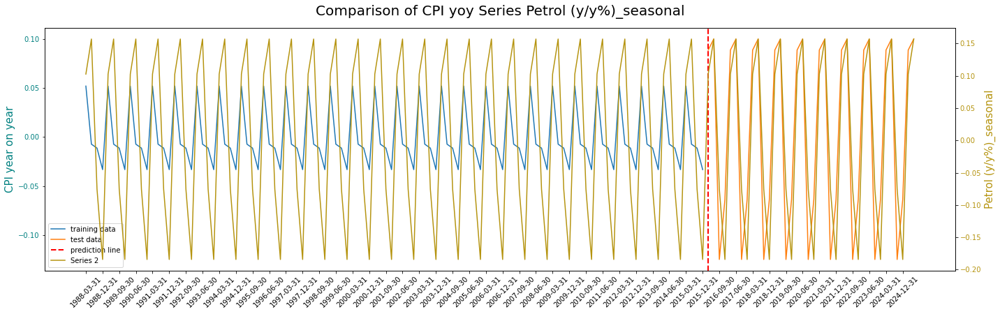

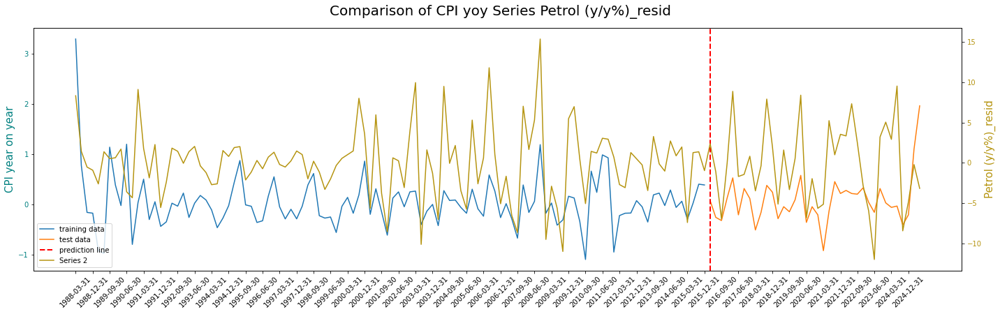

In [195]:
compare_timeseries(y_train, y_test, dates, X_vars['Petrol (y/y%)'])
compare_timeseries(y_trTrend, y_tsTrend, dates, X_vars_trend['Petrol (y/y%)_trend'])
compare_timeseries(y_trSeason, y_tsSeason, dates, X_vars_season['Petrol (y/y%)_seasonal'])
compare_timeseries(y_trResid, y_tsResid, dates, X_vars_resid['Petrol (y/y%)_resid'])

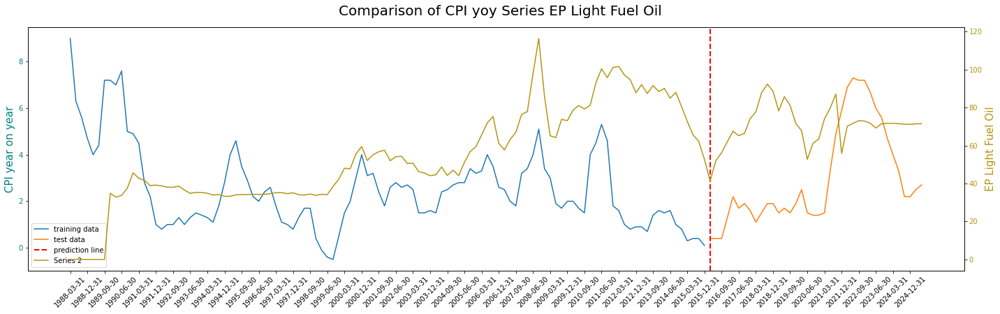

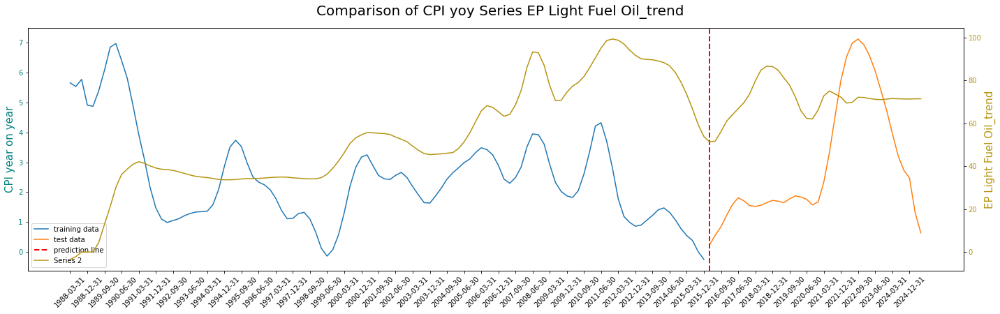

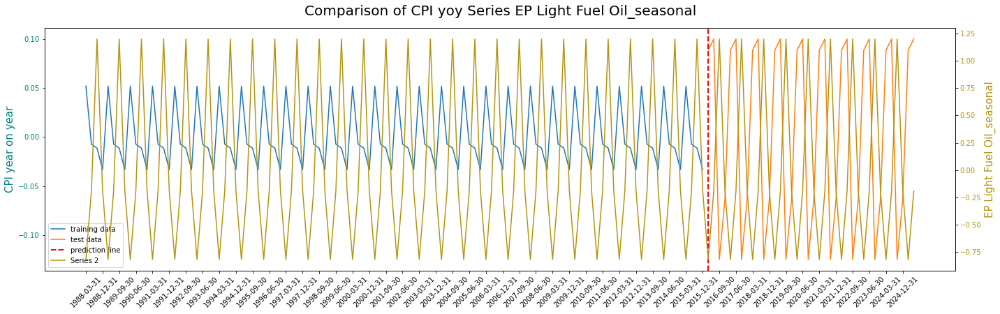

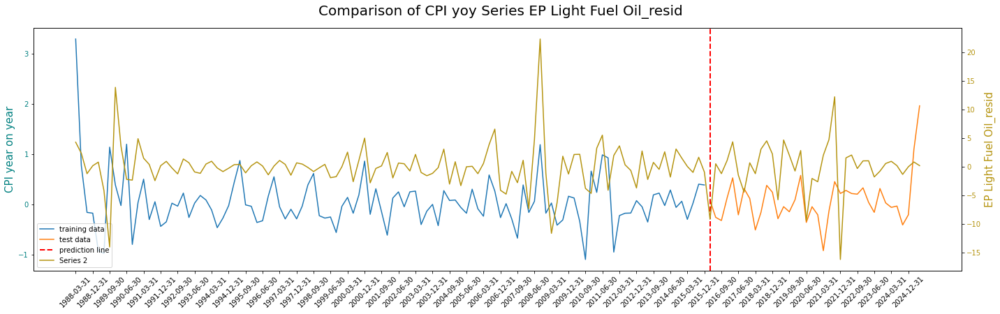

In [194]:
compare_timeseries(y_train, y_test, dates, X_vars['EP Light Fuel Oil'])
compare_timeseries(y_trTrend, y_tsTrend, dates, X_vars_trend['EP Light Fuel Oil_trend'])
compare_timeseries(y_trSeason, y_tsSeason, dates, X_vars_season['EP Light Fuel Oil_seasonal'])
compare_timeseries(y_trResid, y_tsResid, dates, X_vars_resid['EP Light Fuel Oil_resid'])

## Task 2.2. Feature Selection.
[Back to top](#Index) | [To section head](#TASK-2:-GRADIENT-BOOSTING-IN-CLASS-FORECASTING-COMPETITION) | [Code](#Feature-Selection) |[To Template section](#Task-2:-Gradient-Boosting-In-Class-NZ-Inflation-Forecasting-Competition-(35-Marks))

I collected all data sets from the Reserve bank which were timeseries (all these come from Stats NZ anyway, but are easier to get from RNZ) and all energy price and production data from MBIE. These I stitched into two data sets using Google sheets as it was easier to see the data in a tabular form. One contained all data that was measure monthly, the other all data measured quarterly. I trimmed off all data which was pree 1988 and removed columns contianing all 0s pre 2016. These became the X variables, all 420 of them. Not shown here, I computed 2270 variables and correlated them all against CPIyoy. From these and found that most were not useful at all. Here I show the process, labeit much faster. 
Because I can enginerr variables out of CPIyoy I also joined that to the X variables for feature engineering.

In order to select X variables I took the decomposed residuals from both the X variables and the target y variable. Performing Xi correlation on the initial 420 X variable residuals. Viewing the top 20 in the correlation plot below. 
I did this twice. Once following an auto-configureed ARIMA model to pre-whiten the variables then correlate their residuals to the residuals of the CPIyoy, and once using the more simple seasonally deocmposed residuals. 
The latter resulted in a better model, but as we shall see, not by much at all. 0.01 level of difference. 

It is clear that few variables have strong correlations with CPIyoy. The strength of the correlations quickly decreases.
Of these I took only the top ten, excluding 'EP Premium petrol' and 'EP Regular Petrol' on account of its their correlation with 'EP Petrol (cl)'. On account of not wanting the two variables providing the same infromation, and hence being redundant for the model. Instead I subbed in 'Producer's price index outputs y/y%' and 'Import Prices y/y%'.
Why twelve? Why not? During feature engineering I will create hundreds of features, and processing them takes time. I in fact did run the process with every feature initially, and to avoid the ungodly run time each day I whitteld it down ot only those variables that had any use to the fitted models. This smaller set here demonstrates the whole process I undertook well enough. 

Unsurprisingly, the selected variables are very close to my initial hypothesis. Tradable inflation, transportation, food, petrol price (at the pump) and the energy price of oil. It is no mystery that the component parts of CPI can tell us about CPI. The measures not part CPI are the energy prices, domestic billings and any bank or bond related data. And this is no surprise given tha tall things take energy and so the rpice of energy has an impact in their shelf price. 


For the sake of brevity I will not show the plots for all the engineerered variables, shifting, rolling means, expanding means, lagged variables and so on. Instead, in the next section I use correlation only. The end result is the same.

### Top 50 variables, residual correlations

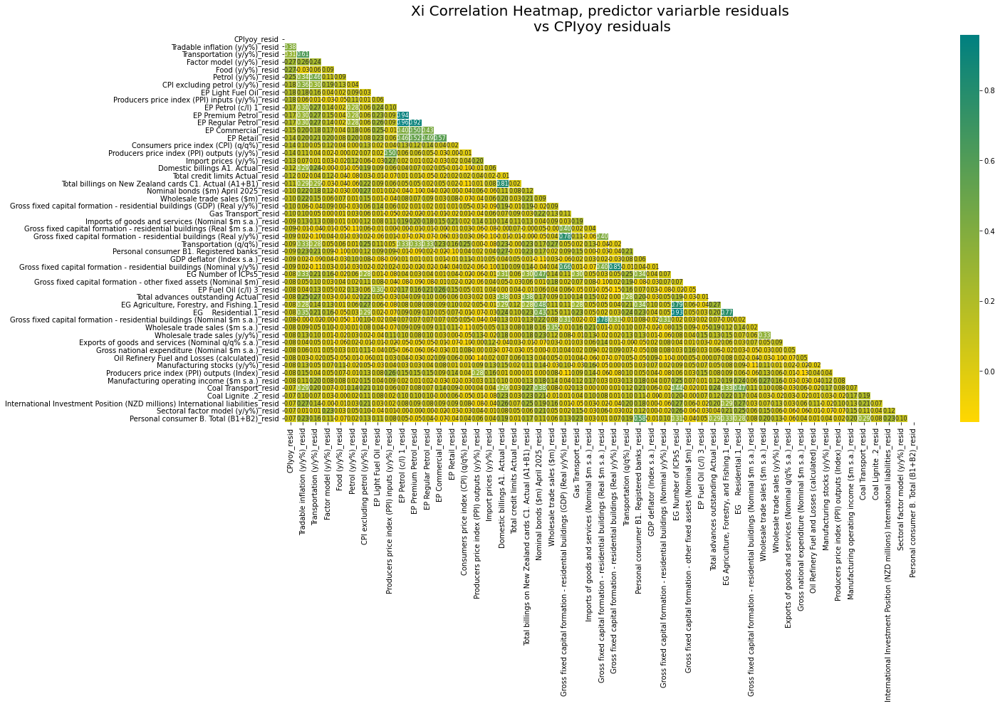

In [523]:
#try again with pre-whitening using ARIMA model
matrix = X_vars_train_resid.corr(method = xicor)

matrix = matrix.sort_values(by = 'CPIyoy_resid', ascending=False).head(51)
col_filt = matrix.index
matrix = matrix[col_filt]

# matrix = resid_cors.corr(method = xicor)
mask = np.triu(np.ones_like(matrix, dtype=bool))

plt.figure(figsize=(20, 10))
sns.heatmap(matrix, mask = mask, annot=True, cmap=cmap, fmt=".2f", linewidths=0.5, annot_kws={"size": 8})
plt.title("Xi Correlation Heatmap, predictor variarble residuals \nvs CPIyoy residuals", size = 20)
plt.show()

### Top 20 seasonally decomposed variable residuals correlations

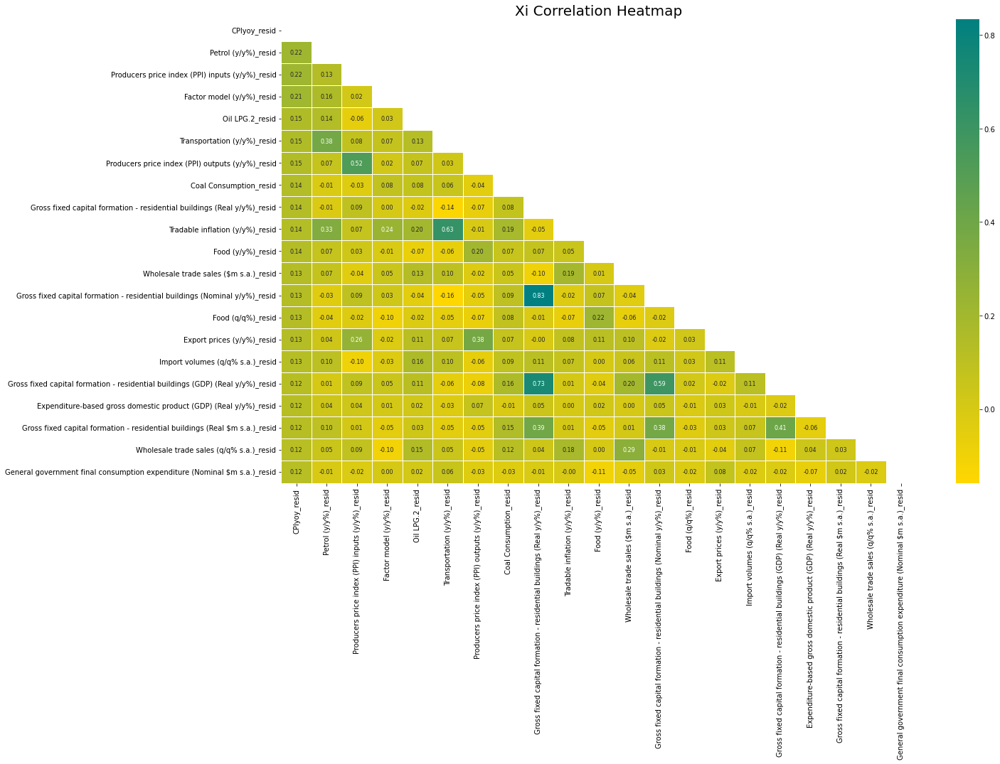

In [704]:
col_filt = get_column_filter(X_vars_train, 20)

In the end, the selected features for engineering are:

In [714]:
col_filt1 = list(col_filt)
# to_remove = ['CPIyoy_resid'] #keep it in for feature engineering
# col_filt1 = [item for item in col_filt2 if item not in to_remove]
col_filt1 = [s.replace("_resid", "") for s in col_filt1]
# col_filt2.extend(['Food (y/y%)', 'Tradable inflation (y/y%)']) 
print(pd.Series(col_filt1))

X_selected = X_vars_train[col_filt1]
X_selected_test = X_vars_test[col_filt1]

0                                                CPIyoy
1                                         Petrol (y/y%)
2             Producers price index (PPI) inputs (y/y%)
3                                   Factor model (y/y%)
4                                             Oil LPG.2
5                                 Transportation (y/y%)
6            Producers price index (PPI) outputs (y/y%)
7                                      Coal Consumption
8     Gross fixed capital formation - residential bu...
9                             Tradable inflation (y/y%)
10                                          Food (y/y%)
11                      Wholesale trade sales ($m s.a.)
12    Gross fixed capital formation - residential bu...
13                                          Food (q/q%)
14                                 Export prices (y/y%)
15                           Import volumes (q/q% s.a.)
16    Gross fixed capital formation - residential bu...
17    Expenditure-based gross domestic product (

### Top 20 pre-whitened variable residual correlations (using auto configured ARIMA model to whiten)

In [1]:
# col_filt = [value.removesuffix('_resid') for value in col_filt]
# X_white_candidates = X_vars_train[col_filt]
# X_white_candidates

# #top 50 vars get whitened
# white_resids = whiten(X_white_candidates)

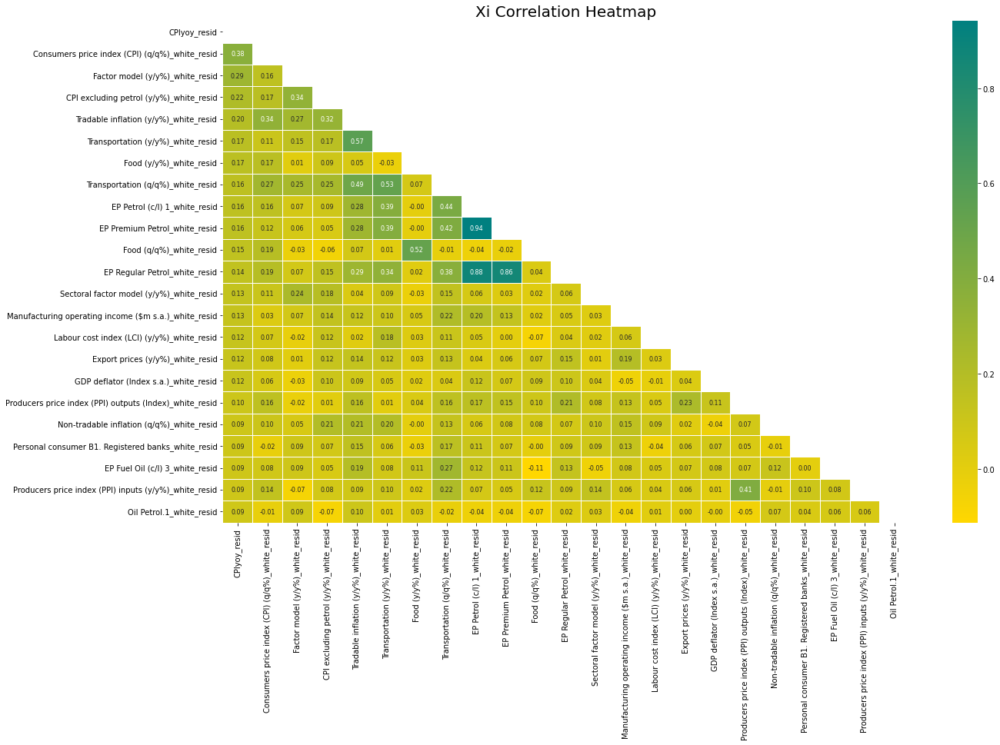

In [763]:
white_resids.rename(columns={'CPIyoy_white_resid': 'CPIyoy_resid'}, inplace=True)
white_resids

col_filt = get_column_filter(white_resids, 22, seasonal = False)

In [770]:
#now engineer the features
#first get best features
col_filt = list(col_filt)
to_remove = ['CPIyoy_resid', 'EP Premium Petrol_white_resid','EP Regular Petrol_white_resid']
col_filt = [item for item in col_filt if item not in to_remove]
col_filt = [s.replace("_white_resid", "") for s in col_filt]

X_selected_white = X_vars[col_filt] #filtering out the non-decomposed variables.
print(pd.Series(X_selected_white.columns))

0              Consumers price index (CPI) (q/q%)
1                             Factor model (y/y%)
2                     CPI excluding petrol (y/y%)
3                       Tradable inflation (y/y%)
4                           Transportation (y/y%)
5                                     Food (y/y%)
6                           Transportation (q/q%)
7                               EP Petrol (c/l) 1
8                                     Food (q/q%)
9                    Sectoral factor model (y/y%)
10       Manufacturing operating income ($m s.a.)
11                 Labour cost index (LCI) (y/y%)
12                           Export prices (y/y%)
13                      GDP deflator (Index s.a.)
14    Producers price index (PPI) outputs (Index)
15                  Non-tradable inflation (q/q%)
16         Personal consumer B1. Registered banks
17                            EP Fuel Oil (c/l) 3
18      Producers price index (PPI) inputs (y/y%)
19                                   Oil Petrol.1


### A taste of the Box Jenkins approach implemented:
I used this initially to find variables visually, then automated the process for feature engineering. 

[Code](#Feature-Selection)

The process is to view the auto coreelation plots for the variable to find the ARIMA configuration. Which I automated after a while to be selected by BIC score evaluated using SARIMAX. Fit the best config, get the residuals, convovle the y values to apply the same filter to the residuals. If the ACF is a straight line in the ACF of residuals plot, the process worked without a hitch, the input is stationary and there is 0 correlation between X and y. 
Next it performs cross correlation on all the lags. 
Shown in the correlation plot. In this examlpe we see lag 2 or 3 is best. 
Then it creates the laged variables as per the input, here I used 4 because I saw no need to lag by more than 4 quarters. Thes are then run through RFE against the un lagged variable to find the most informative lag. This is then returned. 

This whole process doens't work if the data is non-stationary, which can sometimes occur with rolling variables like rolling mean. And never with fourier transformed variables. Here the chosen lag is t-3 on tradable inflation y/y% and the residuals are a good fit to the Y residuals. 


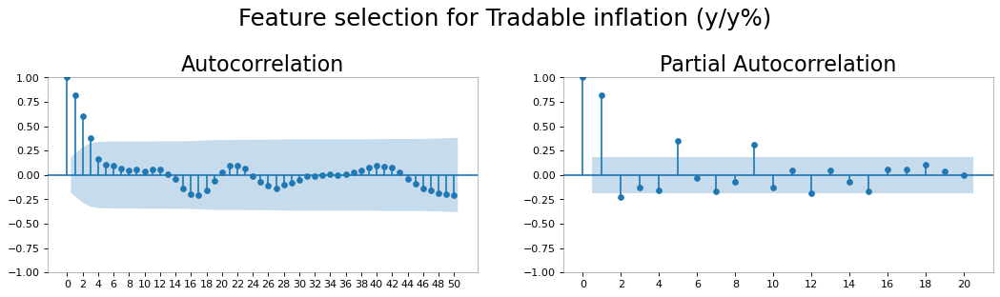

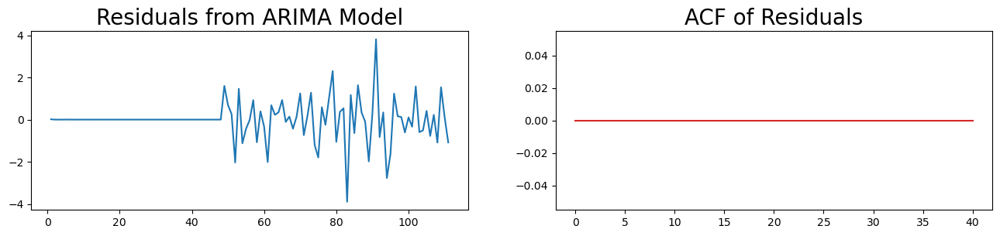

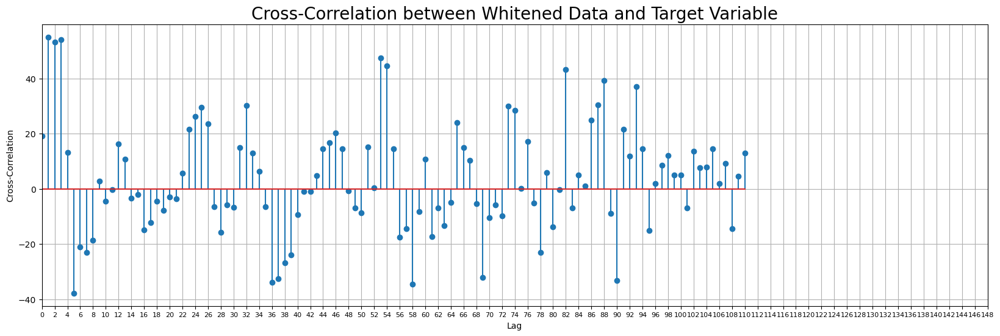

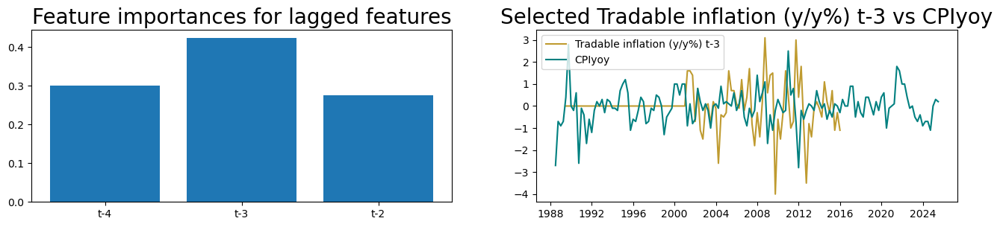

,Tradable inflation (y/y%) t-3
date,
1989-06-30,0.0
1989-09-30,0.0
1989-12-31,0.0
1990-03-31,0.0
1990-06-30,0.0
...,...
2014-12-31,-0.3
2015-03-31,0.7
2015-06-30,-1.1


In [47]:
timeseries_feature_selection(X_vars_train['Tradable inflation (y/y%)'], y_values, 1, 4, 4, 4, True)

## Task 2.3 Feature Engineering.
[Back to top](#Index) | [To section head](#TASK-2:-GRADIENT-BOOSTING-IN-CLASS-FORECASTING-COMPETITION) | [Code](#Feature-Engineering) | [To Template section](#Task-2:-Gradient-Boosting-In-Class-NZ-Inflation-Forecasting-Competition-(35-Marks))

For feature engineering it followed the following process on each of the variable sets selected above: seasonally decomposed residuals and pre whitened residuals):
1. Create features for all variables.
    * I had to wrangle X_change to remove infinty and - infinity values, replacing the former with the max value and the latter with  the minimum value. 
    
    
2. Pre whiten the features and find the best lagged variable version of the difference features using an ARIMA model. i.e the Box Jenkins approach. I turned this into an automated process identifying the best lagged variable using the BIC score and feature importance using a random forest to identify which lag has the highest importance. I only considered 4 lagg periods, because in economics there is very little information about measures a year prior that still matters. 


3. This returns a dataframe with each selected variable, their engineered features and the most informative lagged version of the feature and its engineered derivatives. there ends up being somewhere around 330 variables. 
    Note: percent change features get into exploding values when doing pre-whitening using ARIMA, so I did not pre-whiten these features in the same manner. 
    
    
4. Then I removed all features with low variance (as per the magnitude of their values). This removed a few features that I consider to not be worth it, as they provide too weak a signal to be informative. 


5. Re-run feature selection, taking the top variables only. 
    * The results can be seen the in correllation plot below. Where we see a decent spread of variables. Noclagged variables made it through to the top 30. 


6. Then perfrom RFE to pick the optimium set of features. 
    * At this point I split the data into the original train and test time periods in order ot ensure that the RFE is applied only to the training date range. Thereby reducing chances of data leakage
    * for the seasonally decomposed data, 29 variables were optimal. 
    * for the pre-whitened data, 27 were optimal



### Feature engineering on seasonally decomposed data

We are starting off with X_selected. This has 20 features which will get engineered. We will then need to apply the same transforms to the test data

In [717]:
def engineer_features(df, y):
    #create a bunch of features, then remove features with low variance
    #get rolling average, srolling sum, slope coefficients for 1 year
    X_roll_mean = roll_mean_features(df, 4)
    X_roll_mean = variance_selector(X_roll_mean, 3)

    #rolling sum
    X_roll_sum = roll_sum_features(df, 4)
    X_roll_sum = variance_selector(X_roll_sum, 10)

    #rolling standard deviation
    X_roll_sd = roll_sd_features(df, 4)
    X_roll_sd = variance_selector(X_roll_sd, 0.1)

    #expanding mean, sum and std
    X_expand = expand_features(df)
    X_expand = variance_selector(X_expand, 0.2)

    #slope coeffs
    X_slopes = slope_coeffs_features(df, 4)
    X_slopes = variance_selector(X_slopes, 0.3)

    # #%percent difference
    X_change = percent_change_features(df, 4)
    X_change = variance_selector(X_change, 50)
    X_change.replace([-np.inf], np.nanmin(X_change[X_change != -np.inf]), inplace=True)
    X_change.replace([np.inf], np.nanmax(X_change[X_change != np.inf]), inplace=True)
    X_change_white = pd.DataFrame(whiten(X_change), columns = X_change.columns).add_suffix('_whitened').set_index(y.index)

    # #fourier series
    X_fourier = fourier_features(df)
    X_fourier = X_fourier.set_index(y.index)
    # X_fourier = variance_selector(X_fourier, 0.01)

    #prewhiten all the variables except change and fourier. This function returns the most important pre-whitened features in each df.
    #use 4 ma and 4 ar because 4 quarters in a year. difference by 1 to make staitonary the variables. 
#     lagged_vars = create_whiten_lag(df, y, 1, 4, 4, 4)
#     lagged_roll_mean = create_whiten_lag(X_roll_mean, y, 1, 4, 4, 4)
#     lagged_roll_sum = create_whiten_lag(X_roll_sum, y, 1, 4, 4, 4)
#     lagged_roll_sd = create_whiten_lag(X_roll_sd, y, 1, 4, 4, 4)
#     lagged_expand = create_whiten_lag(X_expand, y, 1, 4, 4, 4)
#     lagged_slopes = create_whiten_lag(X_slopes, y, 1, 4, 4, 4)

#     # #all features 458 columns
#     X_engineered = pd.concat([df, lagged_vars, X_roll_mean, lagged_roll_mean, X_roll_sum, lagged_roll_sum, 
#                               X_roll_sd, lagged_roll_sd, X_expand, lagged_expand, X_slopes, lagged_slopes, 
#                               X_change, X_change_white, X_fourier], axis = 1)
#     X_engineered = X_engineered.fillna(0)
    
    return X_roll_mean, X_roll_sum, X_roll_sd, X_expand, X_slopes, X_change, X_change_white, X_fourier

In [753]:
X_roll_mean, X_roll_sum, X_roll_sd, X_expand, X_slopes, X_change, X_change_white, X_fourier = engineer_features(X_selected, y_train)


X_roll_mean_test, X_roll_sum_test, X_roll_sd_test, X_expand_test, X_slopes_test, X_change_test, X_change_white_test, X_fourier_test = engineer_features(X_vars_test, y_test) #issue with this decomposition error with too few rows

In [731]:
# Prewhiten X_train set
# lagged_vars = create_whiten_lag(X_selected, y_train, 1, 4, 4, 4)
# lagged_roll_mean = create_whiten_lag(X_roll_mean, y_train, 1, 4, 4, 4) #doesn't work
# lagged_roll_sum = create_whiten_lag(X_roll_sum, y_train, 1, 4, 4, 4) #doesn't like
# lagged_roll_sd = create_whiten_lag(X_roll_sd, y_train, 1, 4, 4, 4) # doesn't like
# lagged_expand = create_whiten_lag(X_expand, y_train, 1, 4, 4, 4) # doesn't like
# lagged_slopes = create_whiten_lag(X_slopes, y_train, 1, 4, 4, 4)

# whitened_X_roll_mean = pd.DataFrame(whiten(X_roll_mean), columns = X_roll_mean.columns).add_suffix('_whitened').set_index(y_train.index)
# whitened_X_roll_sum = pd.DataFrame(whiten(X_roll_sum), columns = X_roll_sum.columns).add_suffix('_whitened').set_index(y_train.index)
# whitened_X_roll_sd = pd.DataFrame(whiten(X_roll_sd), columns = X_roll_sd.columns).add_suffix('_whitened').set_index(y_train.index)
# whitened_X_expand = pd.DataFrame(whiten(X_expand), columns = X_expand.columns).add_suffix('_whitened').set_index(y_train.index)

#==================Test data
# Prewhiten X_test set
lagged_vars_test = create_whiten_lag(X_selected_test, y_test, 1, 4, 4, 4)
# lagged_roll_mean = create_whiten_lag(X_roll_mean, y_test, 1, 4, 4, 4) #doesn't work
# lagged_roll_sum = create_whiten_lag(X_roll_sum, y_test, 1, 4, 4, 4) #doesn't like
# lagged_roll_sd = create_whiten_lag(X_roll_sd, y_test, 1, 4, 4, 4) # doesn't like
# lagged_expand = create_whiten_lag(X_expand, y_test, 1, 4, 4, 4) # doesn't like
lagged_slopes_test = create_whiten_lag(X_slopes, y_test, 1, 4, 4, 4)

# whitened_X_roll_mean_test = pd.DataFrame(whiten(X_roll_mean_test), columns = X_roll_mean_test.columns).add_suffix('_whitened').set_index(y_test.index)
# whitened_X_roll_sum_test = pd.DataFrame(whiten(X_roll_sum_test), columns = X_roll_sum_test.columns).add_suffix('_whitened').set_index(y_test.index)
# whitened_X_roll_sd_test = pd.DataFrame(whiten(X_roll_sd_test), columns = X_roll_sd_test.columns).add_suffix('_whitened').set_index(y_test.index)
# whitened_X_expand_test = pd.DataFrame(whiten(X_expand_test), columns = X_expand_test.columns).add_suffix('_whitened').set_index(y_test.index)

In [736]:
X_train_engineered = pd.concat([X_selected, lagged_vars, X_roll_mean, whitened_X_roll_mean, X_roll_sum, whitened_X_roll_sum, X_roll_sd, whitened_X_roll_sd , X_expand, whitened_X_expand, X_change, X_change_white, X_fourier ], axis = 1)
# X_train_engineered #760 columns

X_test_engineered = pd.concat([X_selected_test, lagged_vars_test, X_roll_mean_test, whitened_X_roll_mean_test, X_roll_sum_test, whitened_X_roll_sum_test, X_roll_sd_test, whitened_X_roll_sd_test , X_expand_test, whitened_X_expand_test, X_change_test, X_change_white_test, X_fourier_test ], axis = 1)

#checkpoint
X_train_engineered.to_csv('X_train_engineered.csv', index = True)

X_test_engineered.to_csv('X_test_engineered.csv', index = True)

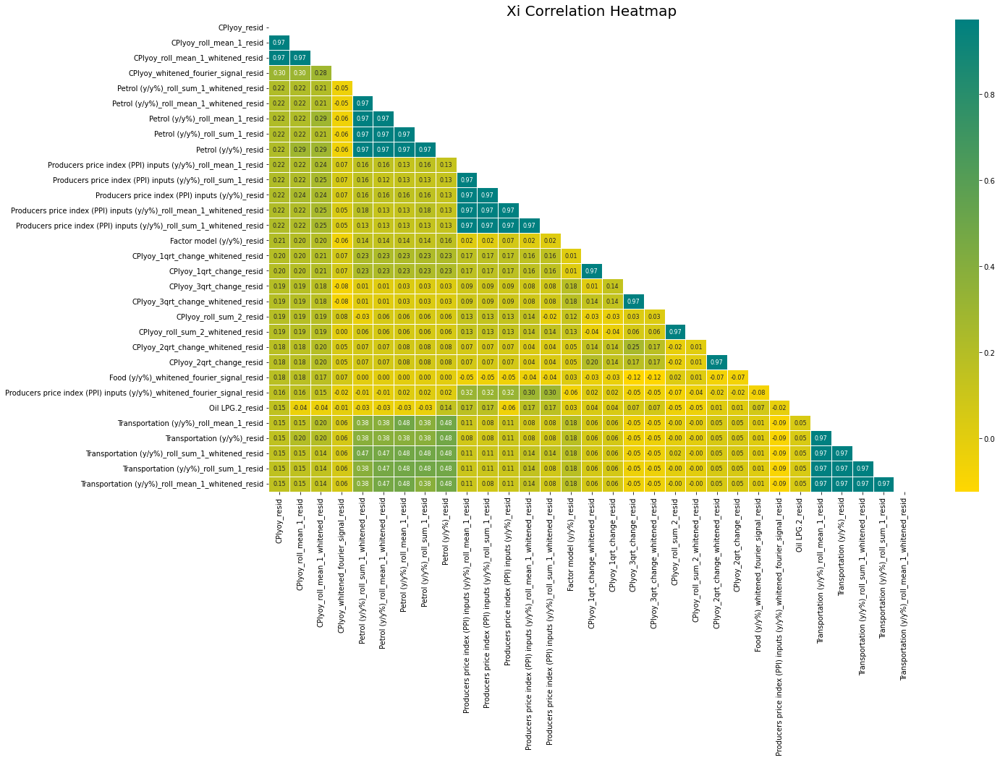

Index(['CPIyoy_resid', 'CPIyoy_roll_mean_1_resid',
       'CPIyoy_roll_mean_1_whitened_resid',
       'CPIyoy_whitened_fourier_signal_resid',
       'Petrol (y/y%)_roll_sum_1_whitened_resid',
       'Petrol (y/y%)_roll_mean_1_whitened_resid',
       'Petrol (y/y%)_roll_mean_1_resid', 'Petrol (y/y%)_roll_sum_1_resid',
       'Petrol (y/y%)_resid',
       'Producers price index (PPI) inputs (y/y%)_roll_mean_1_resid',
       'Producers price index (PPI) inputs (y/y%)_roll_sum_1_resid',
       'Producers price index (PPI) inputs (y/y%)_resid',
       'Producers price index (PPI) inputs (y/y%)_roll_mean_1_whitened_resid',
       'Producers price index (PPI) inputs (y/y%)_roll_sum_1_whitened_resid',
       'Factor model (y/y%)_resid', 'CPIyoy_1qrt_change_whitened_resid',
       'CPIyoy_1qrt_change_resid', 'CPIyoy_3qrt_change_resid',
       'CPIyoy_3qrt_change_whitened_resid', 'CPIyoy_roll_sum_2_resid',
       'CPIyoy_roll_sum_2_whitened_resid', 'CPIyoy_2qrt_change_whitened_resid',
       'CP

In [741]:
col_filt = get_column_filter(X_train_engineered, 30)
col_filt

In [762]:
print(pd.Series(col_filt2))

0                                                CPIyoy
1                                    CPIyoy_roll_mean_1
2                           CPIyoy_roll_mean_1_whitened
3                        CPIyoy_whitened_fourier_signal
4                     Petrol (y/y%)_roll_sum_1_whitened
5                    Petrol (y/y%)_roll_mean_1_whitened
6                             Petrol (y/y%)_roll_mean_1
7                              Petrol (y/y%)_roll_sum_1
8                                         Petrol (y/y%)
9     Producers price index (PPI) inputs (y/y%)_roll...
10    Producers price index (PPI) inputs (y/y%)_roll...
11            Producers price index (PPI) inputs (y/y%)
12    Producers price index (PPI) inputs (y/y%)_roll...
13    Producers price index (PPI) inputs (y/y%)_roll...
14                                  Factor model (y/y%)
15                          CPIyoy_1qrt_change_whitened
16                                   CPIyoy_1qrt_change
17                                   CPIyoy_3qrt

In [763]:
col_filt2 = list(col_filt)
to_remove = ['Producers price index (PPI) inputs (y/y%)_roll_sum_1_resid', 'Producers price index (PPI) inputs (y/y%)_roll_sum_1_whitened_resid'] #removed as failed to generate in X_test for some reason
col_filt2 = [item for item in col_filt2 if item not in to_remove]
col_filt2 = [s.replace("_resid", "") for s in col_filt2]
col_filt2.extend(['Food (y/y%)', 'Tradable inflation (y/y%)']) #add back these because I am sure they will be useful

X_top_train = X_train_engineered[col_filt2] #filtering out the non-decomposed variables.
X_top_test = X_test_engineered[col_filt2]
# print(pd.Series(X_selected.columns))

### RFE

In [767]:
X_top_train_trend, X_top_train_season, X_top_train_resid = seasonal_decompose_df(X_top_train, model = 'additive', period = 4)
X_top_test_trend, X_top_test_season, X_top_test_resid = seasonal_decompose_df(X_top_test, model = 'additive', period = 4)


Optimal number of features: 21
Selected features: ['CPIyoy_roll_mean_1_resid', 'CPIyoy_roll_mean_1_whitened_resid', 'CPIyoy_whitened_fourier_signal_resid', 'CPIyoy_1qrt_change_whitened_resid', 'CPIyoy_1qrt_change_resid', 'CPIyoy_3qrt_change_resid', 'CPIyoy_3qrt_change_whitened_resid', 'CPIyoy_roll_sum_2_resid', 'CPIyoy_roll_sum_2_whitened_resid', 'CPIyoy_2qrt_change_whitened_resid', 'CPIyoy_2qrt_change_resid', 'Food (y/y%)_whitened_fourier_signal_resid', 'Producers price index (PPI) inputs (y/y%)_whitened_fourier_signal_resid', 'Oil LPG.2_resid', 'Transportation (y/y%)_roll_mean_1_resid', 'Transportation (y/y%)_resid', 'Transportation (y/y%)_roll_sum_1_whitened_resid', 'Transportation (y/y%)_roll_sum_1_resid', 'Transportation (y/y%)_roll_mean_1_whitened_resid', 'Food (y/y%)_resid', 'Tradable inflation (y/y%)_resid']


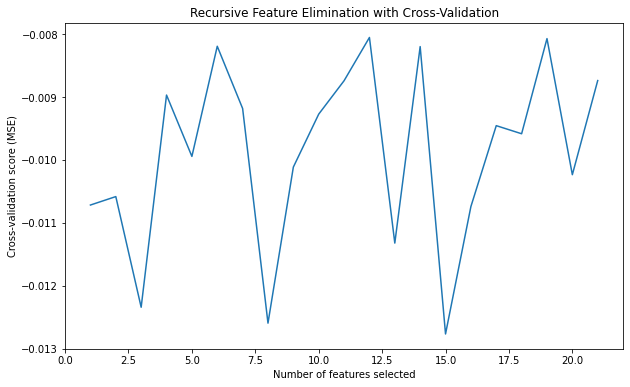

In [773]:
#no longer need CPIyoy for training or testing
X_top_train_resid.drop(columns = ['CPIyoy_resid'], inplace = True)
X_top_test_resid.drop(columns = ['CPIyoy_resid'], inplace = True)

# #RFE #try with residuals 
X_rfe = feature_selection(X_top_train_resid, y_trResid, 10) #fit to Y residuals

# # #now filter these variables to the model
X_train_resid = X_top_train_resid[X_rfe]
X_test_resid = X_top_test_resid[X_rfe]


In [777]:
rfe_filt = [s.replace("_resid", "") for s in X_rfe]
X_train = X_top_train[rfe_filt]
X_test = X_top_test[rfe_filt]

#Check point
X_train.to_csv('X_train.csv', index = True)
X_test.to_csv('X_test.csv', index = True)
X_train_resid.to_csv('X_train_resid.csv', index = True)
X_test_resid.to_csv('X_test_resid.csv', index = True)

Now we have two data frames. One, X_train is for the raw data of the selected variables. X_train_resid is for the residuals that we used to pick the features. With the same for the test data. 
Then, I remove any rolling mean of length 1, praticualry the CPIyoy rolling mean of 1, as this is the exact same as the target data. This removes data leakage from the mode. A further point to note, using rolling metrics of CPIyoy is not data leakage because I have kept the train and test splits separate for the engineering process. Therefore the training set can't include rolling points in the future relative to the point of prediction.

The final variables are:

In [55]:
X_train.drop(columns =['CPIyoy_roll_mean_1', 'CPIyoy_roll_mean_1_whitened','Transportation (y/y%)_roll_mean_1' ], inplace= True)
X_test.drop(columns =['CPIyoy_roll_mean_1', 'CPIyoy_roll_mean_1_whitened','Transportation (y/y%)_roll_mean_1' ], inplace = True)

X_train.drop(columns =['CPIyoy_roll_mean_1_resid', 'CPIyoy_roll_mean_1_whitened_resid','Transportation (y/y%)_roll_mean_1_resid' ], inplace= True)
X_test.drop(columns =['CPIyoy_roll_mean_1_resid', 'CPIyoy_roll_mean_1_whitened_resid','Transportation (y/y%)_roll_mean_1_resid' ], inplace = True)

In [94]:
pd.Series(X_train.columns)

0                  CPIyoy_whitened_fourier_signal_resid
1                     CPIyoy_1qrt_change_whitened_resid
2                              CPIyoy_1qrt_change_resid
3                              CPIyoy_3qrt_change_resid
4                     CPIyoy_3qrt_change_whitened_resid
5                               CPIyoy_roll_sum_2_resid
6                      CPIyoy_roll_sum_2_whitened_resid
7                     CPIyoy_2qrt_change_whitened_resid
8                              CPIyoy_2qrt_change_resid
9             Food (y/y%)_whitened_fourier_signal_resid
10    Producers price index (PPI) inputs (y/y%)_whit...
11                                      Oil LPG.2_resid
12                          Transportation (y/y%)_resid
13      Transportation (y/y%)_roll_sum_1_whitened_resid
14               Transportation (y/y%)_roll_sum_1_resid
15     Transportation (y/y%)_roll_mean_1_whitened_resid
16                                    Food (y/y%)_resid
17                      Tradable inflation (y/y%

## For Reference: Feature engineering on data pre-whitened by Auto configured ARIMA for reference:

The below section shows my approach on engineering and selecting variables using a different differencing approach. This was not used in the final model. 

[Click here to skip](#Task-2.4-Model-Fitting.)

Optimal number of features: 29
Selected features: ['CPIyoy_roll_mean_1_resid', 'CPIyoy_slope_2_resid', 'Tradable inflation (y/y%)_roll_mean_1_resid', 'Tradable inflation (y/y%)_resid', 'Transportation (y/y%)_resid', 'Transportation (y/y%)_roll_sum_1_resid', 'Transportation (y/y%)_roll_mean_1_resid', 'CPIyoy_slope_1_resid', 'CPIyoy_2qrt_change_whitened_resid', 'CPIyoy_2qrt_change_resid', 'Tradable inflation (y/y%)_slope_4_resid', 'CPIyoy_1qrt_change_resid', 'CPIyoy_1qrt_change_whitened_resid', 'Factor model (y/y%)_resid', 'CPIyoy_roll_sum_2_resid', 'CPIyoy_roll_mean_2_resid', 'Tradable inflation (y/y%)_slope_3_resid', 'EP Petrol (c/l) 1_slope_4_resid', 'Food (y/y%)_roll_mean_1_resid', 'Food (y/y%)_resid', 'EP Petrol (c/l) 1_4qrt_change_resid', 'EP Petrol (c/l) 1_4qrt_change_whitened_resid', 'Petrol (y/y%)_roll_mean_1_resid', 'Petrol (y/y%)_resid', 'Petrol (y/y%)_roll_sum_1_resid', 'Tradable inflation (y/y%)_slope_2_resid', 'Food (y/y%)_slope_2_resid', 'Transportation (y/y%)_slope_2_resi

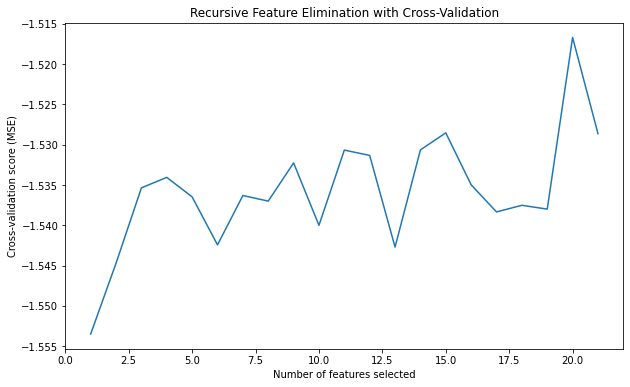

In [654]:
X_engineered_resid_top = X_engineered_resid[col_filt]
X_engineered_resid_top.drop(columns = ['CPIyoy_resid'], inplace = True)

# # #split X to train and test
# #use residuals for model
X_train5 = X_engineered_resid_top.loc[:'2015-12-31']

#RFE #try with residuals 
X_rfe = feature_selection(X_train5, y_train, 10)

#now fit these variables to the model
X_engineered_resid_rfe = X_engineered_resid_top[X_rfe]

X_train5 = X_engineered_resid_rfe.loc[:'2015-12-31']
X_test5 = X_engineered_resid_rfe.loc['2016-03-31':]

### Feature engineering on pre-whitened data

In [723]:
# #now engineer the features
# X_selected_white = pd.concat([y_values, X_selected_white], axis = 1) #add y vlaues in for feature engineering

# #create a bunch of features, then remove features with low variance
# #get rolling average, srolling sum, slope coefficients for 1 year
# X_roll_mean = roll_mean_features(X_selected_white, 4)
# X_roll_mean = variance_selector(X_roll_mean, 3)

# #rolling sum
# X_roll_sum = roll_sum_features(X_selected_white, 4)
# X_roll_sum = variance_selector(X_roll_sum, 10)

# #rolling standard deviation
# X_roll_sd = roll_sd_features(X_selected_white, 4)
# X_roll_sd = variance_selector(X_roll_sd, 0.1)

# #expanding mean, sum and std
# X_expand = expand_features(X_selected_white)
# X_expand = variance_selector(X_expand, 0.2)

# #slope coeffs
# X_slopes = slope_coeffs_features(X_selected_white, 4)
# X_slopes = variance_selector(X_slopes, 0.3)

# # #%percent difference
# X_change = percent_change_features(X_selected_white, 4)
# X_change = variance_selector(X_change, 50)
# X_change.replace([-np.inf], np.nanmin(X_change[X_change != -np.inf]), inplace=True)
# X_change.replace([np.inf], np.nanmax(X_change[X_change != np.inf]), inplace=True)
# X_change_white = pd.DataFrame(whiten(X_change), columns = X_change.columns).add_suffix('_whitened').set_index(y_values.index)

# # #fourier series
# X_fourier = fourier_features(X_selected_white)
# X_fourier = X_fourier.set_index(y_values.index)
# X_fourier = variance_selector(X_fourier, 0.01)

#prewhiten all the variables except change and fourier. This function returns the most important pre-whitened features in each df.
#use 4 ma and 4 ar because 4 quarters in a year. difference by 1 to make staitonary the variables. 
# lagged_vars = create_whiten_lag(X_selected_white, y_values, 1, 4, 4, 4)
# lagged_roll_mean = create_whiten_lag(X_roll_mean, y_values, 1, 4, 4, 4)
# lagged_roll_sum = create_whiten_lag(X_roll_sum, y_values, 1, 4, 4, 4)
# lagged_roll_sd = create_whiten_lag(X_roll_sd, y_values, 1, 4, 4, 4)
# lagged_expand = create_whiten_lag(X_expand, y_values, 1, 4, 4, 4)
# lagged_slopes = create_whiten_lag(X_slopes, y_values, 1, 4, 4, 4)

# #all features 458 columns
X_engineered = pd.concat([X_selected_white, lagged_vars, X_roll_mean, lagged_roll_mean, X_roll_sum, 
                          X_roll_sd, lagged_roll_sd, X_expand, lagged_expand, X_slopes, lagged_slopes, 
                          X_change, X_change_white, X_fourier], axis = 1)
X_engineered = X_engineered.fillna(0) 

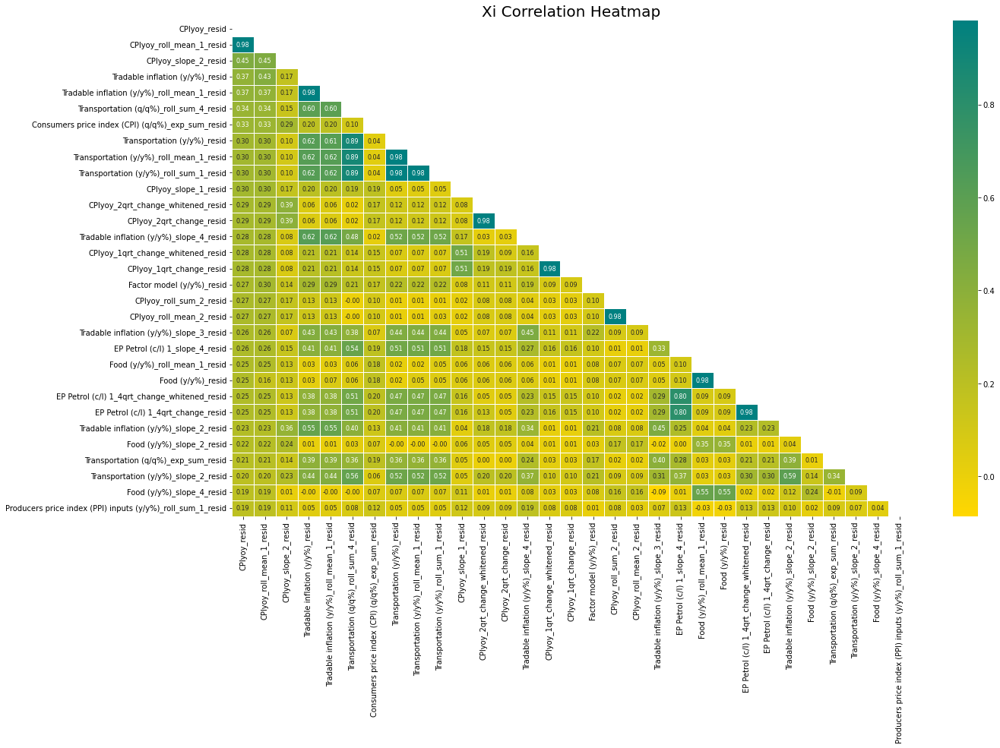

In [726]:
col_filt = get_column_filter(X_engineered, 30)

### RFE

Optimal number of features: 27
Selected features: ['CPIyoy_roll_mean_1_resid', 'CPIyoy_slope_2_resid', 'Tradable inflation (y/y%)_resid', 'Tradable inflation (y/y%)_roll_mean_1_resid', 'Transportation (q/q%)_roll_sum_4_resid', 'Consumers price index (CPI) (q/q%)_exp_sum_resid', 'Transportation (y/y%)_resid', 'Transportation (y/y%)_roll_mean_1_resid', 'Transportation (y/y%)_roll_sum_1_resid', 'CPIyoy_slope_1_resid', 'CPIyoy_2qrt_change_whitened_resid', 'CPIyoy_2qrt_change_resid', 'Tradable inflation (y/y%)_slope_4_resid', 'CPIyoy_1qrt_change_whitened_resid', 'Factor model (y/y%)_resid', 'CPIyoy_roll_sum_2_resid', 'CPIyoy_roll_mean_2_resid', 'Tradable inflation (y/y%)_slope_3_resid', 'EP Petrol (c/l) 1_slope_4_resid', 'Food (y/y%)_roll_mean_1_resid', 'Food (y/y%)_resid', 'EP Petrol (c/l) 1_4qrt_change_resid', 'Tradable inflation (y/y%)_slope_2_resid', 'Food (y/y%)_slope_2_resid', 'Transportation (q/q%)_exp_sum_resid', 'Transportation (y/y%)_slope_2_resid', 'Food (y/y%)_slope_4_resid']


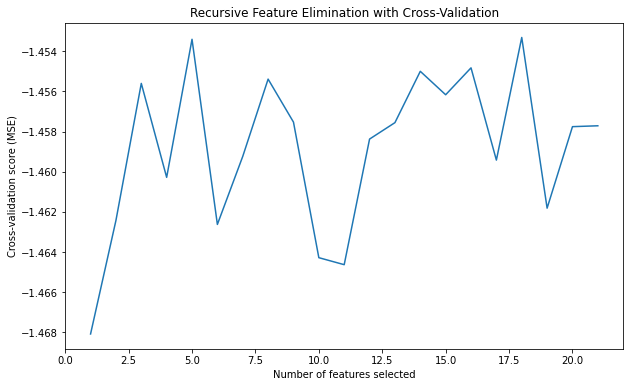

In [736]:
X_engineered_trend, X_engineered_season, X_engineered_resid = seasonal_decompose_df(X_engineered, model = 'additive', period = 4)

X_white_resid_top = X_engineered_resid[col_filt]
X_white_resid_top.drop(columns = ['CPIyoy_resid'], inplace = True)

# # #split X to train and test
# #use residuals for model
X_train_set = X_white_resid_top.loc[:'2015-12-31']

#RFE #try with residuals 
X_rfe = feature_selection(X_train_set, y_train, 10)

#now fit these variables to the model
X_white_resid_rfe = X_white_resid_top[X_rfe]

X_train6 = X_white_resid_rfe.loc[:'2015-12-31']
X_test6 = X_white_resid_rfe.loc['2016-03-31':]

## Task 2.4 Model Fitting.
[Back to top](#Index) | [To section head](#TASK-2:-GRADIENT-BOOSTING-IN-CLASS-FORECASTING-COMPETITION) | [Code](#Feature-Engineering) | [To Template section](#Task-2:-Gradient-Boosting-In-Class-NZ-Inflation-Forecasting-Competition-(35-Marks))

Before cracking into each model experiment, I will explain the methodlogy I followed. 
First, when I was testing everything I tried using raw data, with trend and seaosnality and the fit was terrible, I tohught. I then tried a piece-wise model where I predicted each component, seasonality, trend and residuals separately. Also terrible. Gradient boost predicts like a decision tree, and so the space of predicted values is constrained by the stump decisions. Resulting in repeating predictions. 

So instead I focused only using the residuals, i.e the white noise. If I could predict those then add the y training seasonality and trend back, I could get a model that is only looking at the unexplained portion of the CPIyoy variable. This resulted in really strong predictions. 

The model gets the data it needs to fit, decomposes them, then predict the residuals. The same goes for the test data. It breaks those down into parts and predicts the residuals only. The one draw back form this approach is that you really MUST perform validation on the model, because that is the only time it won't have access to the seasonal and trend components of the prediction data. 

If I had more time I would find a way to extend the prediction to seasonality and trend, reconstituting the prediction from each. I.e. predict a set of seasonal, trend and residual predictions each time. Perhaps I will save that for a thesis of some kind. As it stand I was able to do this for the prediction of quarter 3 2025. And as I see it, in the competition the data is present and I can use it. In real life I will be predicting one time step ahead. 

To avoid data leakage I removed from the data from RFE those variables that wouldn't be present in a real situation. 
These are the variable not followed by a number, as those with were shifted, expaned, rolled or otherwise engineered from prior data: 

**From the seasonally decomposed data**
* 'Tradable inflation (y/y%)_resid', 
* 'Transportation (y/y%)_resid', 
* 'Factor model (y/y%)_resid',
* 'Food (y/y%)_resid', 
* 'Petrol (y/y%)_resid', 

**From the pre-whitened data**
* 'Tradable inflation (y/y%)_resid', 
* 'Transportation (y/y%)_resid', 
* 'Factor model (y/y%)_resid', 
* 'Food (y/y%)_resid'

The best model end up having a train MSE of 0.0038 and test MSE of 0.0329. It was a Huber loss model with 200 estimators and learning rate of 0.3. Below is a summary table.

In [2]:
import pandas as pd

In [5]:
models = ['MSE Loss', 'MAE loss', 'Friedman MSE loss', 'Huber loss', 'Quantile loss', 'Inverse decay', 'Adaptive decay', 'Probabalistic decay']
trainMSE = [0.27, 0.22, 0.05, 0.02, 0.28, 0.08, 15.8, 0.03]
testMSE = [0.2, 0.32, 0.18, 0.29, 0.22, 0.1, 0.32, 0.22]
trainMAE = [0.34, 0.27, 0.17, 0.1, 0.35, 0.15, 2.47, 0.13]
testMAE = [0.3, 0.37, 0.26, 0.3, 0.32, 0.22, 0.5, 0.34]
trainMAPE = [1.2, 1.14, 1.11, 1.3, 1.56, 1.18, 19.69, 1.4]
testMAPE = [0.99, 1.91, 1.51, 1.68, 1.13, 0.98, 4.31, 1.84]

scores = pd.DataFrame(list(zip(models, trainMSE, testMSE, trainMAE, testMAE, trainMAPE, testMAPE)), columns = ['Models', 'Train MSE', 'Test MSE', 'Train MAE', 'Test MAE', 'Train MAPE', 'Test MAPE'])
scores


,Models,Train MSE,Test MSE,Train MAE,Test MAE,Train MAPE,Test MAPE
0,MSE Loss,0.27,0.20,0.34,0.30,1.20,0.99
1,MAE loss,0.22,0.32,0.27,0.37,1.14,1.91
2,Friedman MSE loss,0.05,0.18,0.17,0.26,1.11,1.51
3,Huber loss,0.02,0.29,0.10,0.30,1.30,1.68
4,Quantile loss,0.28,0.22,0.35,0.32,1.56,1.13
5,Inverse decay,0.08,0.10,0.15,0.22,1.18,0.98
6,Adaptive decay,15.80,0.32,2.47,0.50,19.69,4.31
7,Probabalistic decay,0.03,0.22,0.13,0.34,1.40,1.84


In [448]:
# X_train5.drop(columns = ['Tradable inflation (y/y%)_resid', 'Transportation (y/y%)_resid', 'Factor model (y/y%)_resid','Food (y/y%)_resid', 'Petrol (y/y%)_resid'], inplace = True)
# X_test5.drop(columns = ['Tradable inflation (y/y%)_resid', 'Transportation (y/y%)_resid', 'Factor model (y/y%)_resid','Food (y/y%)_resid', 'Petrol (y/y%)_resid'], inplace = True)

In [452]:
# X_train6.drop(columns = ['Tradable inflation (y/y%)_resid', 'Transportation (y/y%)_resid', 'Factor model (y/y%)_resid', 'Food (y/y%)_resid'], inplace =True)
# X_test6.drop(columns = ['Tradable inflation (y/y%)_resid', 'Transportation (y/y%)_resid', 'Factor model (y/y%)_resid', 'Food (y/y%)_resid'], inplace =True)

## Seasonally decomposed data model
The first model was the seasonally decomposed data. With this model, a learning rate of 0.3 three seems to do the trick. 
Resuling in a very good fit that is able to pick up the uptick at the end of the test data due to the increased variability the learning rate of 0.3 affords. 

Here the model learns the training data with MSE 0.0062. Very tight fit. With test MSE of 0.062. Nothing to complain about.
It is useful to note that with 100 estimators the prediction is only marginally better than with 50. 0.068, while the fit is much better. The model over fits the trianing data with many estimators, generalising only marginally better with more. So from here on out I will only use 50 estimators to cut down on computation time. 

This tight fit is due to using the residuals of the train and test data for the fit. If this is not done, the mode predictions, because they are decision stumps, become very 'either or'. I have taken care not to avoid data leakage in the engineering step ensuring that the training data was engineered without contamination from the test data, so I am satisifed that this is not the case. As I see enough variance in the fit and a lot of uncertainty at the end of the model.

In [67]:
# X_train = pd.read_csv('X_train_final.csv').set_index('date')
# X_test = pd.read_csv('X_test_final.csv').set_index('date')
# X_train= X_train.set_index(y_train.index)
# X_test= X_test.set_index(y_test.index)

In [39]:
#checkpoint
X_train = pd.read_csv('X_train_final.csv').set_index('date')
X_test = pd.read_csv('X_test_final.csv').set_index('date')

X_train= X_train.set_index(y_train.index)
X_test= X_test.set_index(y_test.index)

# X_train.drop(columns =['CPIyoy_roll_mean_1_resid', 'CPIyoy_roll_mean_1_whitened_resid','Transportation (y/y%)_roll_mean_1_resid' ], inplace= True)
# X_test.drop(columns =['CPIyoy_roll_mean_1_resid', 'CPIyoy_roll_mean_1_whitened_resid','Transportation (y/y%)_roll_mean_1_resid' ], inplace = True


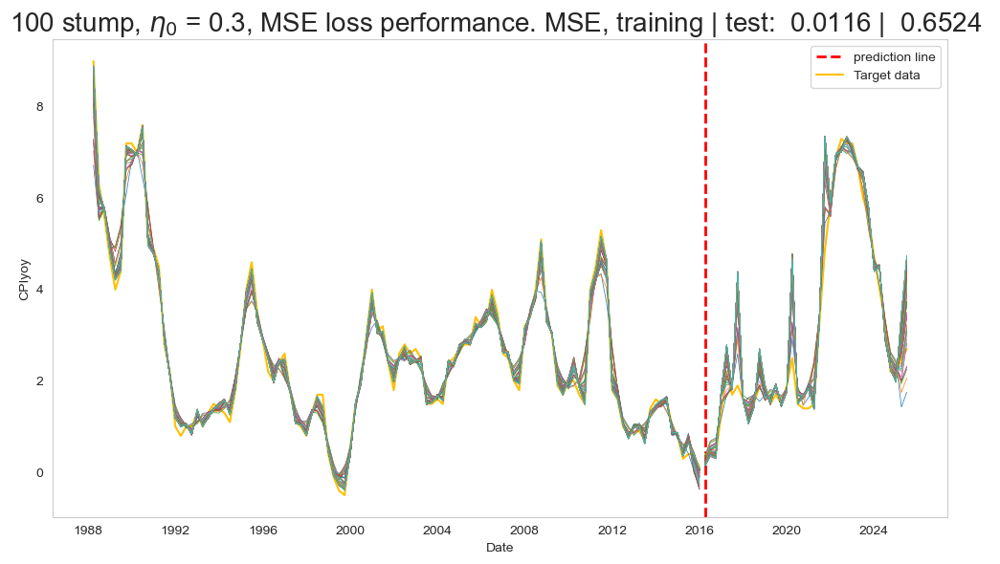

Train MSE: 0.011595230108444293 | Test MSE: 0.6524449804340621
Train MAE: 0.08418887719769279 | Test MAE: 0.4391578599393197
Train MAPE: 1.0997084206145968 | Test MAPE: 2.1467887948060462


In [73]:
model_1 = GBoost(classifier = 'stump', n_estimators = 100, learning_rate = 0.3, subsample= None, seed = 21, loss_function = 'MSE',
                timeseries = True, periods = 4)
model_1.fit(X_train, y_train)
m1_preds = model_1.predict(np.array(X_test))
model_1._timeseries_fit()
m1_ts_preds = model_1._timeseries_predict(y_test)
model_1._get_all_scores(np.array(y_train), np.array(y_test))

plt.figure(figsize=(10, 6))
timeseries_pred_plot(X_train, y_train, X_test, y_test, model_1)
plt.grid()
plt.show()

print(f"Train MSE: {metrics.mean_squared_error(model_1.y_resid, model_1.estimator_preds[-1])} | Test MSE: {metrics.mean_squared_error(model_1.y_resid_test, model_1.testing_preds[-1])}")
print(f"Train MAE: {metrics.mean_absolute_error(model_1.y_resid, model_1.estimator_preds[-1])} | Test MAE: {metrics.mean_absolute_error(model_1.y_resid_test, model_1.testing_preds[-1])}")
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(model_1.y_resid, model_1.estimator_preds[-1])} | Test MAPE: {metrics.mean_absolute_percentage_error(model_1.y_resid_test, model_1.testing_preds[-1])}")

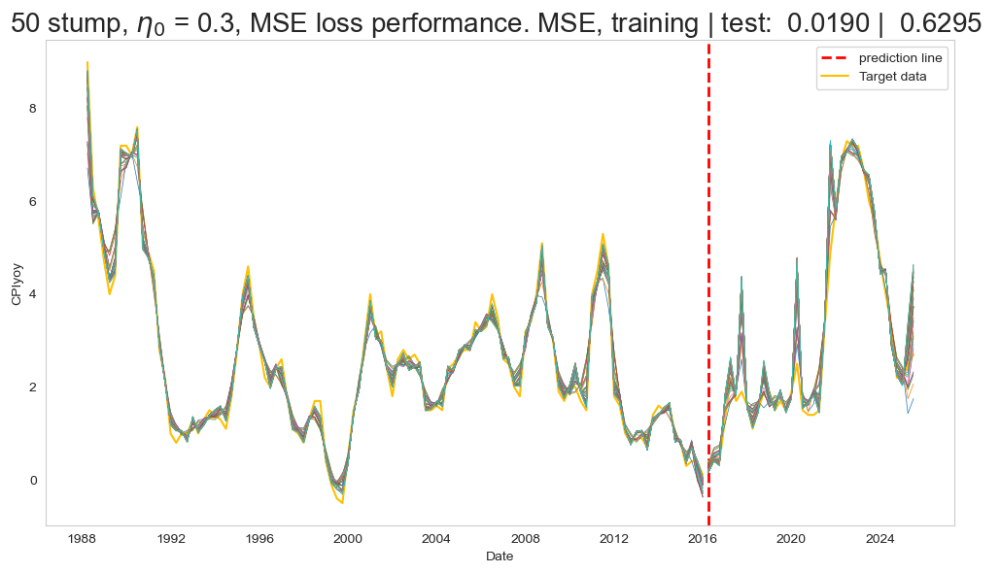

Train MSE: 0.01902255619184246 | Test MSE: 0.6294861259411364
Train MAE: 0.10796516073778735 | Test MAE: 0.4250213659562174
Train MAPE: 1.368726386766521 | Test MAPE: 2.0916507164065314


In [75]:
model_1 = GBoost(classifier = 'stump', n_estimators = 50, learning_rate = 0.3, subsample= None, seed = 21, loss_function = 'MSE',
                timeseries = True, periods = 4)
model_1.fit(X_train, y_train)
m1_preds = model_1.predict(np.array(X_test))
model_1._timeseries_fit()
m1_ts_preds = model_1._timeseries_predict(y_test)
model_1._get_all_scores(np.array(y_train), np.array(y_test))

plt.figure(figsize=(10, 6))
timeseries_pred_plot(X_train, y_train, X_test, y_test, model_1)
plt.grid()
plt.show()

print(f"Train MSE: {metrics.mean_squared_error(model_1.y_resid, model_1.estimator_preds[-1])} | Test MSE: {metrics.mean_squared_error(model_1.y_resid_test, model_1.testing_preds[-1])}")
print(f"Train MAE: {metrics.mean_absolute_error(model_1.y_resid, model_1.estimator_preds[-1])} | Test MAE: {metrics.mean_absolute_error(model_1.y_resid_test, model_1.testing_preds[-1])}")
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(model_1.y_resid, model_1.estimator_preds[-1])} | Test MAPE: {metrics.mean_absolute_percentage_error(model_1.y_resid_test, model_1.testing_preds[-1])}")

### Pre-whitened data model
Under the same configuration, only with different features, the pre-whitented model has a MSE of 0.0061 on training data, vs 0.1068 on training data. 

The model has learnt the training data very well, and generalises a bit more poorly to the test data. Still really well though! The general degredation makes me less concerned about data leakage. I am more convinced that the prewhitening process followed for this set of features was less able to create and select informative features. 

Unfortuately, from here on out this is a legacy model and data set. I can't recreate it due to a numpy update which I have been unable to roll back and which is required for the later XGBoost model code in task 3. So it is just was well that it was the worse model! However, a couple features got into the model that were not meant to be the first time round. This was CPIyoy rolling mean of 1, which is just the same as the CPIyoy. With that in, the model is very accurate. So this can be an example of data leakage, and what happens when it occurs. 

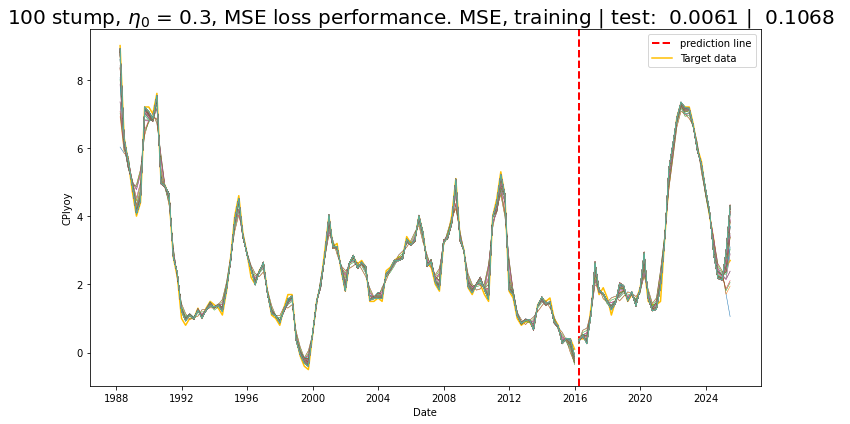

Train MSE: 0.006095424926140944 | Test MSE: 0.10679266077236567
Train MAE: 0.06217149346317642 | Test MAE: 0.18597530200133794
Train MAPE: 0.7195779331227757 | Test MAPE: 1.046073825035064


In [458]:
model_1v2 = GBoost(classifier = 'stump', n_estimators = 100, learning_rate = 0.3, subsample= None, seed = 21, loss_function = 'MSE',
                timeseries = True, periods = 4)
model_1v2.fit(X_train6, y_train)
m1v2_preds = model_1v2.predict(np.array(X_test6))
model_1v2._timeseries_fit()
m1v2_ts_preds = model_1v2._timeseries_predict(y_test)
model_1v2._get_all_scores(np.array(y_train), np.array(y_test))

plt.figure(figsize=(10, 6))
timeseries_pred_plot(X_train6, y_train, X_test6, y_test, model_1v2)
plt.show()

print(f"Train MSE: {metrics.mean_squared_error(model_1v2.y_resid, model_1v2.estimator_preds[-1])} | Test MSE: {metrics.mean_squared_error(model_1v2.y_resid_test, model_1v2.testing_preds[-1])}")
print(f"Train MAE: {metrics.mean_absolute_error(model_1v2.y_resid, model_1v2.estimator_preds[-1])} | Test MAE: {metrics.mean_absolute_error(model_1v2.y_resid_test, model_1v2.testing_preds[-1])}")
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(model_1v2.y_resid, model_1v2.estimator_preds[-1])} | Test MAPE: {metrics.mean_absolute_percentage_error(model_1v2.y_resid_test, model_1v2.testing_preds[-1])}")

### Note on model learning rate and variability

Both the above models are not really worth complaining about because the lines of fit for each iterator have enough variability in them that we can make them out individually. This is because the learning rate is higher. 0.3. The model is learning alot from the data, and the data has lots of variability within it, therefore the model is able to get some useful variance each round. If the learning rate is set to a conservative 0.001, the model learns to little to accout for variance inherent in the data. As shown below. It can't pick up the uptick at the end of the data. 

To give the devil his due, neither can the other models, not fully. They do have a frayed final prediction. This is good. It shows that the model is capable of predicting a value in the right zone. When I look at the frayed lines I think 'predict the mean of those lines as the next time step's prediction. Whereas, for the model below, I can see that it will plummet and predict a low value.

And here we have more evidence that leakage is not the culprit for the earlier predicition success. With a smllaer learning rate the MSE are wose. 0.2 roughly on train and test. Indicating that the model, with a larger learning rate is learning more from the fitting process. Doing what it says on the tin. It just so happens that this is helpful on this data, when it wasn't on the toy data in task 1. 

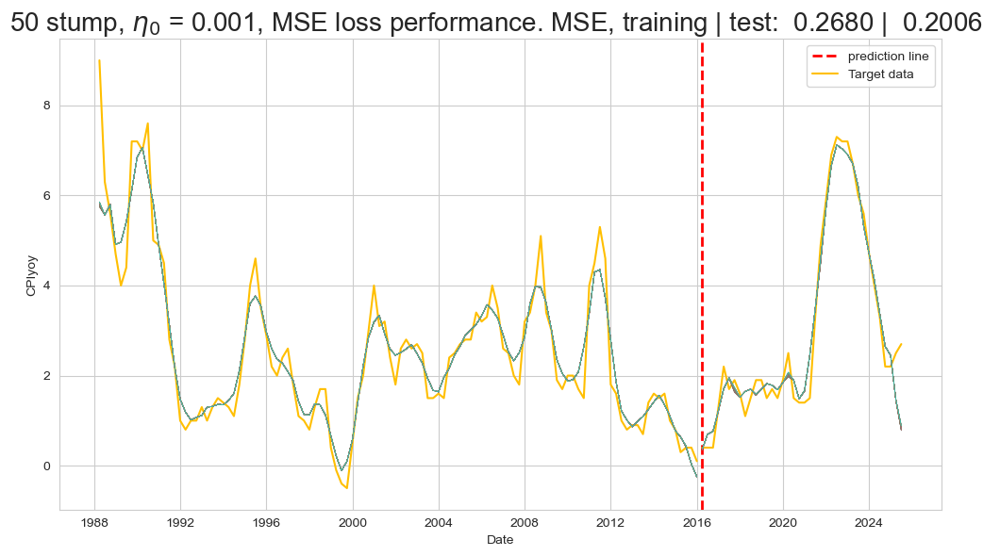

Train MSE: 0.26802560352294424 | Test MSE: 0.20055528334567962
Train MAE: 0.34344918836692356 | Test MAE: 0.3033212584319929
Train MAPE: 1.1656323484155249 | Test MAPE: 0.9921999700924912


In [76]:
model_ = GBoost(classifier = 'stump', n_estimators = 50, learning_rate = 0.001, subsample= None, seed = 21, loss_function = 'MSE',
                timeseries = True, periods = 4)

model_.fit(X_train, y_train)
model_preds = model_.predict(np.array(X_test))
model_._timeseries_fit()
model_ts_preds = model_._timeseries_predict(y_test)
model_._get_all_scores(np.array(y_train), np.array(y_test))

plt.figure(figsize=(10, 6))
timeseries_pred_plot(X_train, y_train, X_test, y_test, model_)
plt.show()

print(f"Train MSE: {metrics.mean_squared_error(model_.y_resid, model_.estimator_preds[-1])} | Test MSE: {metrics.mean_squared_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAE: {metrics.mean_absolute_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAE: {metrics.mean_absolute_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid_test, model_.testing_preds[-1])}")

#### 2.4.1 Model Experiments
[Back to top](#Index) | [To section head](#TASK-2:-GRADIENT-BOOSTING-IN-CLASS-FORECASTING-COMPETITION) | [To Template section](#Task-2:-Gradient-Boosting-In-Class-NZ-Inflation-Forecasting-Competition-(35-Marks))

Below I have run the model on each different loss function and a selection of decay functions. The best model was the friedman loss model with learning rate of 0.1 and a DART drop rate of 0.2. Resulting in training MSE of 0.05 and a test MSE of 0.19. Far and away the best. No decay model comes close. 
Huber loss was also very good because it adapts to use the linear or quadratic loss approximation based on the distance of the data point from the mean. It is robust ot outliers, and capable of capturing variation, unlike MAE. It has the best MAE, and MAPE too with, Having MSEs of 0.02 and 0.3. 

The Friedman MSE model results are:

* Train MSE: 0.04922321746852739 | Test MSE: 0.1783489740738291
* Train MAE: 0.1722436567824738 | Test MAE: 0.26101062319921536
* Train MAPE: 1.1144417830075573 | Test MAPE: 1.5113143688260613

This model also performed better on MAE and MAPE than the others. However, on these two latter measures the Huber loss was comparative with MAE of 0.3 and MAPE of 1.7. 
Quantile loss, interestingly, performed better than Huber still, with training MSE of 0.21. However, the prediction line trends down excessivly after the test data runs out, which doens't give me confidence in its ability to predict beyond the data. 

Before moving on I will mention the decay functions briefly. They aver each very interesting. 
Inverse time step is the best decay function for sure with MSEs of 0.07 and 0.1. However, it is not very good at predicting the uptick at the end of the test data. Being low, like the lower learning rate models. And this is a direct consequence of the same phenomenon we observed before. As the learning rate shrinks, the model loses variance. So I didn't choose it. 

Of note are the adaptive decay and probabalistic decay models. The adaptive has some whacky looking fits. It needs very few fits because the adaptive nature of it leads quickly to exploding values. One can run 200 fits and the errors become wild. However, the final posterior distribution is what we fit the test data on. And this can perform very well. Training MSE of 0.3. The training MSE was 15. This model was able to do this in 20 rounds. As the rounds increase the training MSE increases and the test MSE shrinks. Odd behaviour, but understandable when considering that it wasn't loads of variability in the training rounds to refine the best distribution for the fitting decay. 

While the probabalistic decay effectively fits a distribution of values on the test, resulting in fits on training data that are more representative of the probabilities of the data fits. With the final fit being around 0.2 on test data. Like inverse decay I didn't choose this model, because it had the whiff being unable to forecast one time step ahead well. 
Tough it did look like a 90's 3d image without the viewing glasses on. 

### Mean Average Error loss function

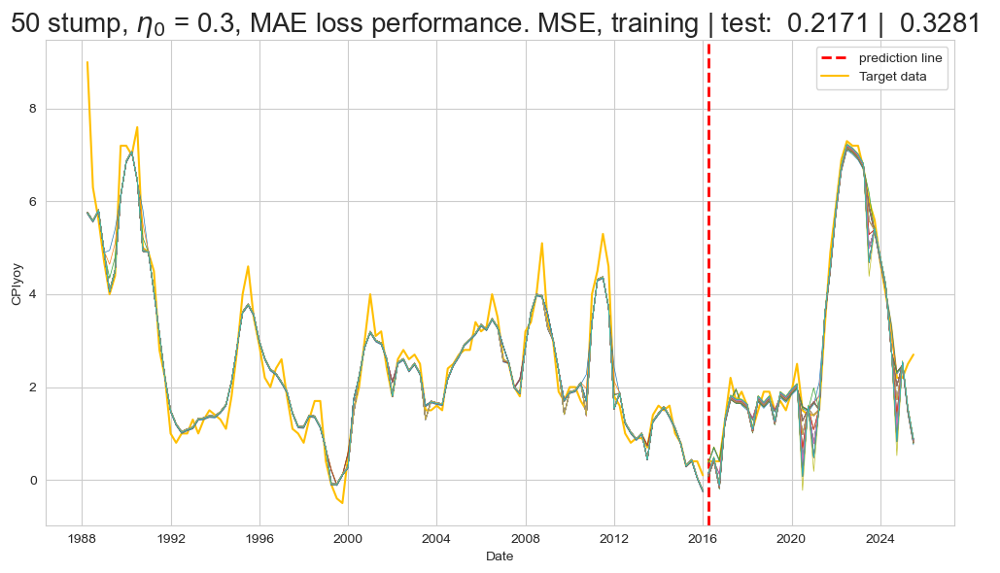

Train MSE: 0.217146652942027 | Test MSE: 0.3280940777971875
Train MAE: 0.27806244170304895 | Test MAE: 0.36620173188903243
Train MAPE: 1.1445880871016954 | Test MAPE: 1.9155030561118496


In [77]:
model_ = GBoost(classifier = 'stump', n_estimators = 50, learning_rate = 0.3, subsample= None, seed = 21, 
                   loss_function = 'MAE', drop_rate= 0.2,
                   timeseries = True, periods = 4)

model_.fit(X_train, y_train)
model_preds = model_.predict(np.array(X_test))
model_._timeseries_fit()
model_ts_preds = model_._timeseries_predict(y_test)
model_._get_all_scores(np.array(y_train), np.array(y_test))

plt.figure(figsize=(10, 6))
timeseries_pred_plot(X_train, y_train, X_test, y_test, model_)
plt.show()

print(f"Train MSE: {metrics.mean_squared_error(model_.y_resid, model_.estimator_preds[-1])} | Test MSE: {metrics.mean_squared_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAE: {metrics.mean_absolute_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAE: {metrics.mean_absolute_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid_test, model_.testing_preds[-1])}")

### FriedmanMSE Loss Function

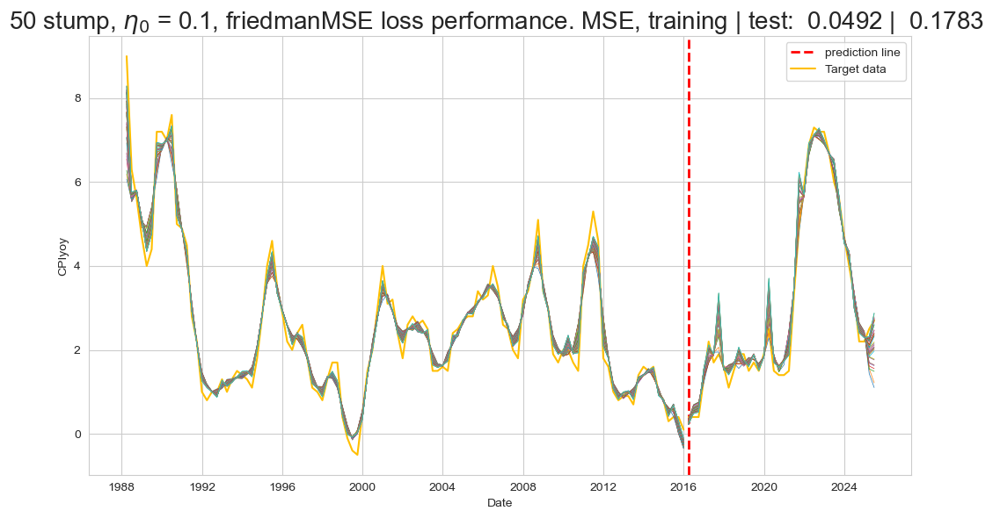

Train MSE: 0.04922321746852739 | Test MSE: 0.1783489740738291
Train MAE: 0.1722436567824738 | Test MAE: 0.26101062319921536
Train MAPE: 1.1144417830075573 | Test MAPE: 1.5113143688260613


In [89]:
model_ = GBoost(classifier = 'stump', n_estimators = 50, learning_rate = 0.1, subsample= None, seed = 21, 
                   loss_function = 'friedmanMSE', drop_rate= 0.2,
                   timeseries = True, periods = 4)

model_.fit(X_train, y_train)
model_preds = model_.predict(np.array(X_test))
model_._timeseries_fit()
model_ts_preds = model_._timeseries_predict(y_test)
model_._get_all_scores(np.array(y_train), np.array(y_test))

plt.figure(figsize=(10, 6))
timeseries_pred_plot(X_train, y_train, X_test, y_test, model_)
plt.show()

print(f"Train MSE: {metrics.mean_squared_error(model_.y_resid, model_.estimator_preds[-1])} | Test MSE: {metrics.mean_squared_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAE: {metrics.mean_absolute_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAE: {metrics.mean_absolute_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid_test, model_.testing_preds[-1])}")

### Huber Loss Function

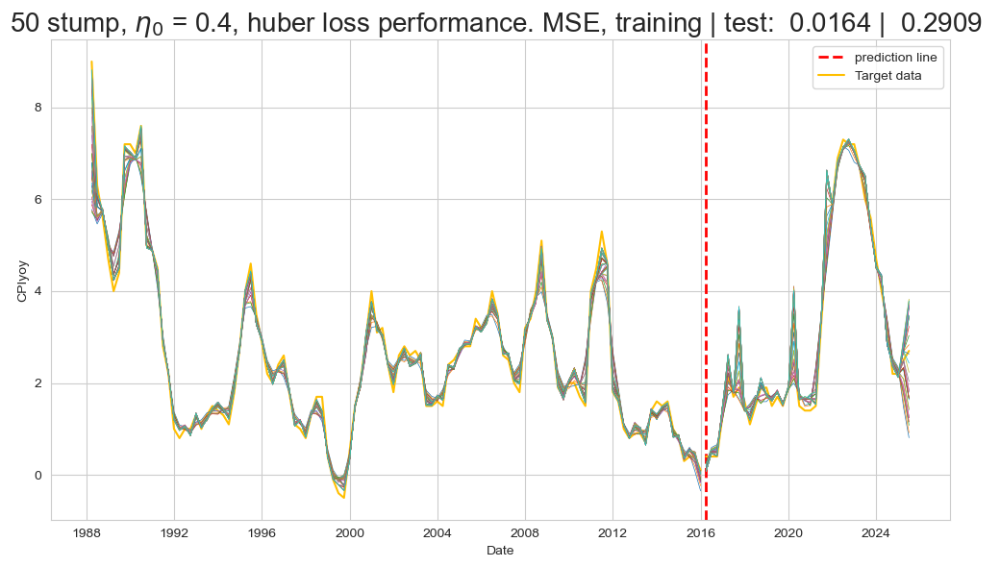

Train MSE: 0.01635229600948388 | Test MSE: 0.29085177371653725
Train MAE: 0.09893660982556875 | Test MAE: 0.30786058968704816
Train MAPE: 1.2806630767036038 | Test MAPE: 1.6786204954643116


In [80]:
model_ = GBoost(classifier = 'stump', n_estimators = 50, learning_rate = 0.4, subsample= None, seed = 21, 
                   loss_function = 'huber', drop_rate= 0.2,
                   timeseries = True, periods = 4)

model_.fit(X_train, y_train)
model_preds = model_.predict(np.array(X_test))
model_._timeseries_fit()
model_ts_preds = model_._timeseries_predict(y_test)
model_._get_all_scores(np.array(y_train), np.array(y_test))

plt.figure(figsize=(10, 6))
timeseries_pred_plot(X_train, y_train, X_test, y_test, model_)
plt.show()

print(f"Train MSE: {metrics.mean_squared_error(model_.y_resid, model_.estimator_preds[-1])} | Test MSE: {metrics.mean_squared_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAE: {metrics.mean_absolute_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAE: {metrics.mean_absolute_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid_test, model_.testing_preds[-1])}")

### Quantile loss function

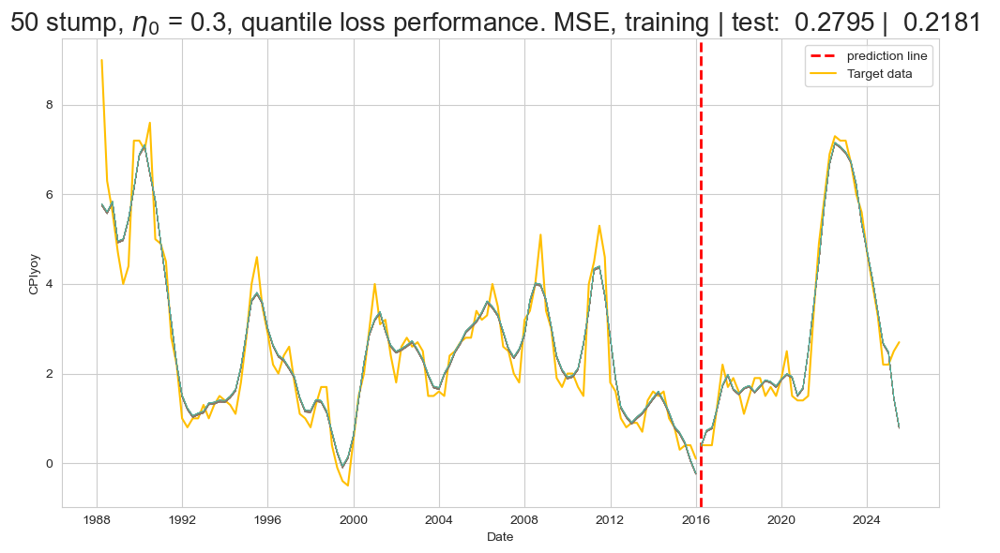

Train MSE: 0.27947370913769687 | Test MSE: 0.21808139319767572
Train MAE: 0.35621974389577893 | Test MAE: 0.318232538335871
Train MAPE: 1.5631733917089154 | Test MAPE: 1.133544528267102


In [81]:
model_ = GBoost(classifier = 'stump', n_estimators = 50, learning_rate = 0.3, subsample= None, seed = 21, 
                   loss_function = 'quantile', quantile = 0.5, drop_rate= 0.2,
                   timeseries = True, periods = 4)

model_.fit(X_train, y_train)
model_preds = model_.predict(np.array(X_test))
model_._timeseries_fit()
model_ts_preds = model_._timeseries_predict(y_test)
model_._get_all_scores(np.array(y_train), np.array(y_test))

plt.figure(figsize=(10, 6))
timeseries_pred_plot(X_train, y_train, X_test, y_test, model_)
plt.show()

print(f"Train MSE: {metrics.mean_squared_error(model_.y_resid, model_.estimator_preds[-1])} | Test MSE: {metrics.mean_squared_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAE: {metrics.mean_absolute_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAE: {metrics.mean_absolute_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid_test, model_.testing_preds[-1])}")

## Decay Functions

Best fitting distribution: weibull_min


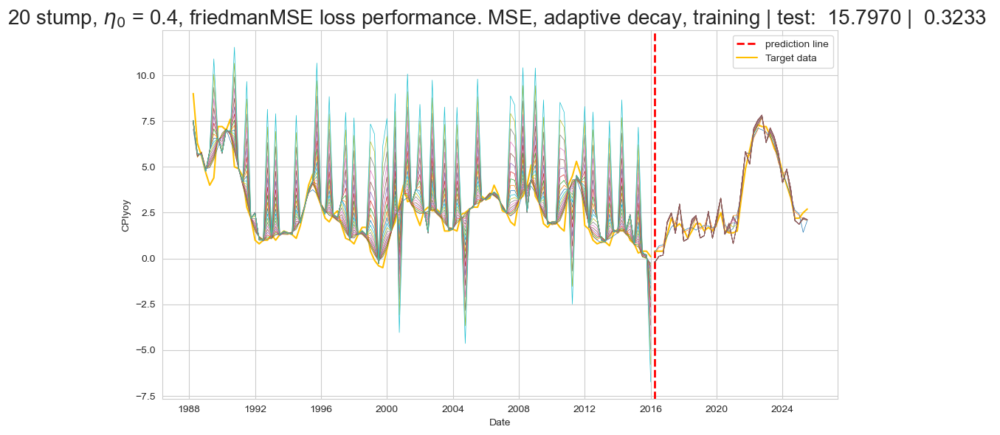

Train MSE: 15.796976599282265 | Test MSE: 0.3232964798780978
Train MAE: 2.4731946552594892 | Test MAE: 0.5086790104027418
Train MAPE: 19.696459373607578 | Test MAPE: 4.313292573164759


In [84]:
model_ = GBoost(classifier = 'stump', n_estimators = 20, learning_rate = 0.4, subsample= None, seed = 21,
                loss_function = 'friedmanMSE', drop_rate= 0.2,
                decay_function = 'adaptive',
                timeseries = True, periods = 4)

model_.fit(X_train, y_train)
model_preds = model_.predict(np.array(X_test))
model_._timeseries_fit()
model_ts_preds = model_._timeseries_predict(y_test)
model_._get_all_scores(np.array(y_train), np.array(y_test))

plt.figure(figsize=(10, 6))
timeseries_pred_plot(X_train, y_train, X_test, y_test, model_)
plt.show()

print(f"Train MSE: {metrics.mean_squared_error(model_.y_resid, model_.estimator_preds[-1])} | Test MSE: {metrics.mean_squared_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAE: {metrics.mean_absolute_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAE: {metrics.mean_absolute_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid_test, model_.testing_preds[-1])}")

### Inverse Time Step Decay

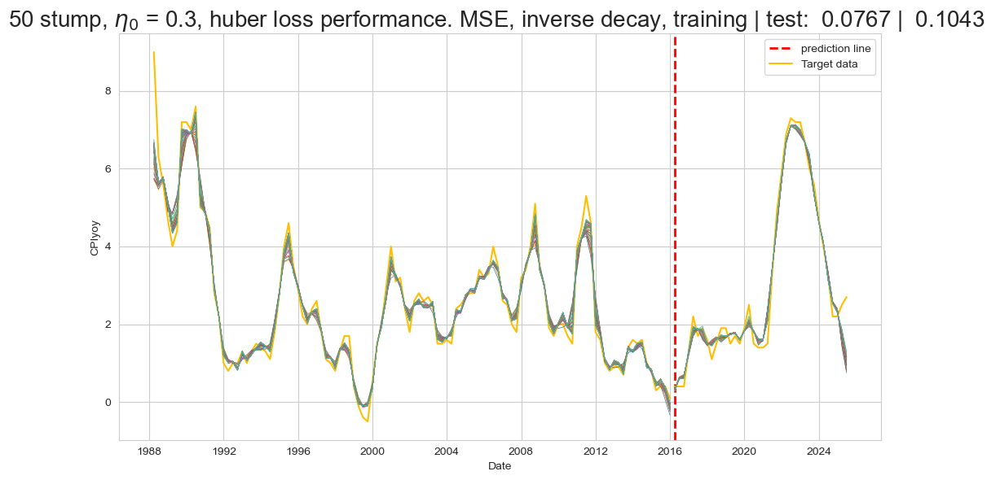

Train MSE: 0.07671629176374892 | Test MSE: 0.1042971676064986
Train MAE: 0.15471446511044862 | Test MAE: 0.2200375139939624
Train MAPE: 1.1800811382750573 | Test MAPE: 0.9812738526517284


In [85]:
model_ = GBoost(classifier = 'stump', n_estimators = 50, learning_rate = 0.3, subsample= None, seed = 21,
                loss_function = 'huber', drop_rate= 0.2,
                decay_function = 'inverse', decay = 0.1, decay_steps = 2, #25 steps
                timeseries = True, periods = 4)

model_.fit(X_train, y_train)
model_preds = model_.predict(np.array(X_test))
model_._timeseries_fit()
model_ts_preds = model_._timeseries_predict(y_test)
model_._get_all_scores(np.array(y_train), np.array(y_test))

plt.figure(figsize=(10, 6))
timeseries_pred_plot(X_train, y_train, X_test, y_test, model_)
plt.show()

print(f"Train MSE: {metrics.mean_squared_error(model_.y_resid, model_.estimator_preds[-1])} | Test MSE: {metrics.mean_squared_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAE: {metrics.mean_absolute_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAE: {metrics.mean_absolute_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid_test, model_.testing_preds[-1])}")

### Probabalistic - Beta Distribution
Using the following distribution:

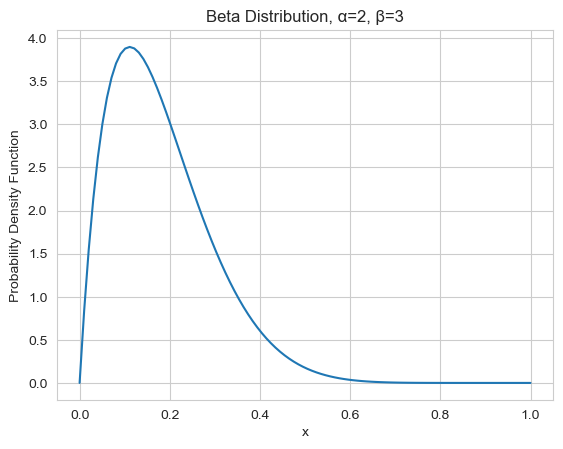

In [86]:
beta_dist = st.beta.pdf(np.linspace(0, 1, 100), 2, 9, loc= 0, scale = 1)
plot_pdf(beta_dist, 'Beta', 'α=2, β=3')
plt.show()

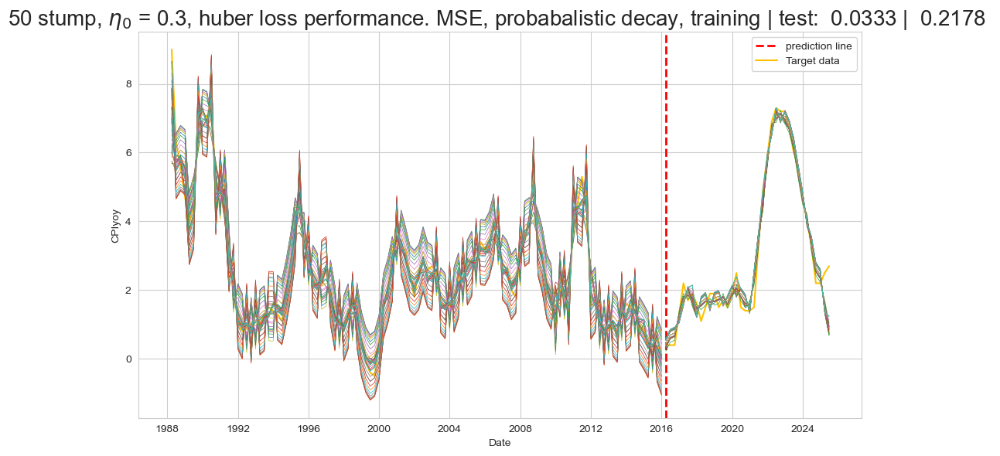

Train MSE: 0.03331536094510261 | Test MSE: 0.2178494090570069
Train MAE: 0.13780295353329386 | Test MAE: 0.3461462457318345
Train MAPE: 1.4104033174225168 | Test MAPE: 1.8429223351894133


In [87]:
model_ = GBoost(classifier = 'stump', n_estimators = 50, learning_rate = 0.3, subsample= None, seed = 21,
                loss_function = 'huber', drop_rate= 0.2,
                decay_function = 'probabalistic', distribution= beta_dist,
                timeseries = True, periods = 4)

model_.fit(X_train, y_train)
model_preds = model_.predict(np.array(X_test))
model_._timeseries_fit()
model_ts_preds = model_._timeseries_predict(y_test)
model_._get_all_scores(np.array(y_train), np.array(y_test))

plt.figure(figsize=(10, 6))
timeseries_pred_plot(X_train, y_train, X_test, y_test, model_)
plt.show()

print(f"Train MSE: {metrics.mean_squared_error(model_.y_resid, model_.estimator_preds[-1])} | Test MSE: {metrics.mean_squared_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAE: {metrics.mean_absolute_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAE: {metrics.mean_absolute_error(model_.y_resid_test, model_.testing_preds[-1])}")
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid, model_.estimator_preds[-1])} | Test MAPE: {metrics.mean_absolute_percentage_error(model_.y_resid_test, model_.testing_preds[-1])}")

## Task 2.5. Grid Search
[Back to top](#Index) | [To section head](#TASK-2:-GRADIENT-BOOSTING-IN-CLASS-FORECASTING-COMPETITION) | [To Template section](#Task-2:-Gradient-Boosting-In-Class-NZ-Inflation-Forecasting-Competition-(35-Marks))

I then took the Huber loss model and ran it through a grid search. I do not recommend it. It takes a very long time. The end result is that no improvement is really better than 0.3 learning rate and 0.2 drop rate. Which is how I found the models above. Here this is showing that one can run the grid search if one has a pathological need to wait. 


In [112]:
# #run this at your own peril. Close to 
# search_grid = {'learning_rate': [0.3, 0.2],
#               'loss_function': ['MSE', 'friedmanMSE', 'MAE', 'huber'],
#               'decay': [0.2, 0.1],
# #               'decay_function': ['exponential', 'exponential2', 'gradient', 'logistic', 'linear'],
# #               'distribution': [],
# #               'decay_steps': [1, 2, 3, 4], #for step dea
# #               'power': [1, 2, 3, 4], #only for power decay
#               'validation_fraction': [None, 0.2],
#               'patience': [5],
#               'tolerance': [0.01],
#               'drop_rate': [0.2]}

# #need to set up seprate frid search for adaptive, probabalisti, step and invrse

# # search_grid = {'learning_rate': [0.3, 0.01]}

# model = GBoost(classifier = 'stump', n_estimators = 50, loss_function = 'MSE', timeseries = True, periods = 4, seed = 21)

# tscv = TimeSeriesSplit(n_splits = 5)

# gridsearch = GridSearchCV(estimator = model, cv = tscv, param_grid = search_grid)
# gridsearch.fit(X_train6, y_train)

# print("Best parameters:", gridsearch.best_params_)

## Task 2.6. Final Model 
[Back to top](#Index) | [To section head](#TASK-2:-GRADIENT-BOOSTING-IN-CLASS-FORECASTING-COMPETITION) | [To Template section](#Task-2:-Gradient-Boosting-In-Class-NZ-Inflation-Forecasting-Competition-(35-Marks))

After all that, it turned out that the initial decomoposed residual feature set was best. Above I used the ARIMA whitened data. The difference wasn't much, and their performance under parameter sets was mcuh of a muchness. The only difference as a slight improvment on the MSE score. Below, the best paramter set is fit to the train5 data with its 29 columns.

It uses 50 estimators, a drop rate of 0.2 and a learning rate of 0.1 with Friedman MSE loss. 
The MSE is 0.05 and 0.178 on training and testing data respectively. 

The model has very closely fit the training data, performing a bit worse on test data. Overall, generalising well. 

In [50]:
# X_train5 = pd.read_csv('X_train5.csv').set_index('date')
# X_test5 = pd.read_csv('X_test5.csv').set_index('date')

X_train = pd.read_csv('X_train.csv').set_index('date')
X_test = pd.read_csv('X_test.csv').set_index('date')

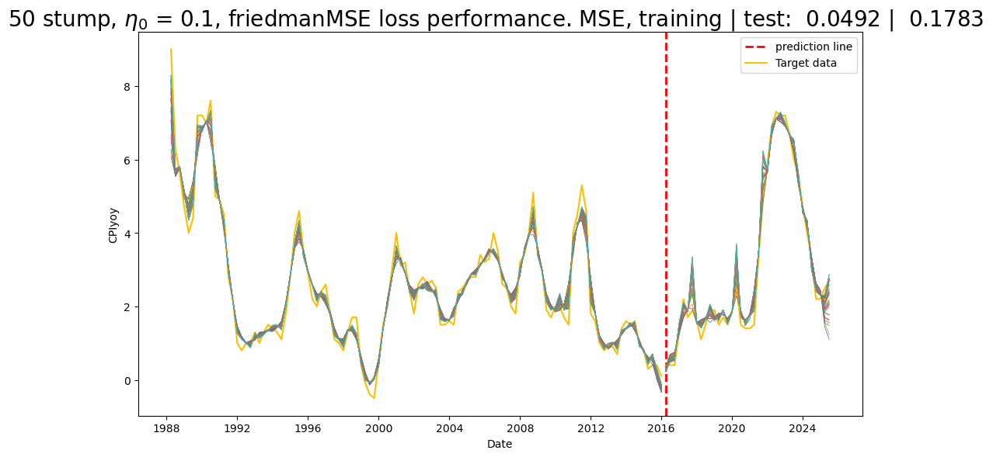

Train MSE: 0.04922321746852739 | Test MSE: 0.1783489740738291
Train MAE: 0.1722436567824738 | Test MAE: 0.26101062319921536
Train MAPE: 1.1144417830075573 | Test MAPE: 1.5113143688260613


In [48]:
best_model = GBoost(classifier = 'stump', n_estimators = 50, learning_rate = 0.1, subsample= None, seed = 21, 
                   loss_function = 'friedmanMSE', drop_rate= 0.2,
                   timeseries = True, periods = 4)

best_model.fit(X_train, y_train)
best_model_preds = best_model.predict(np.array(X_test))
best_model._timeseries_fit()
best_model_ts_preds = best_model._timeseries_predict(y_test)
best_model._get_all_scores(np.array(y_train), np.array(y_test))

plt.figure(figsize=(10, 6))
timeseries_pred_plot(X_train, y_train, X_test, y_test, best_model)
plt.show()

print(f"Train MSE: {metrics.mean_squared_error(best_model.y_resid, best_model.estimator_preds[-1])} | Test MSE: {metrics.mean_squared_error(best_model.y_resid_test, best_model.testing_preds[-1])}")
print(f"Train MAE: {metrics.mean_absolute_error(best_model.y_resid, best_model.estimator_preds[-1])} | Test MAE: {metrics.mean_absolute_error(best_model.y_resid_test, best_model.testing_preds[-1])}")
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(best_model.y_resid, best_model.estimator_preds[-1])} | Test MAPE: {metrics.mean_absolute_percentage_error(best_model.y_resid_test, best_model.testing_preds[-1])}")

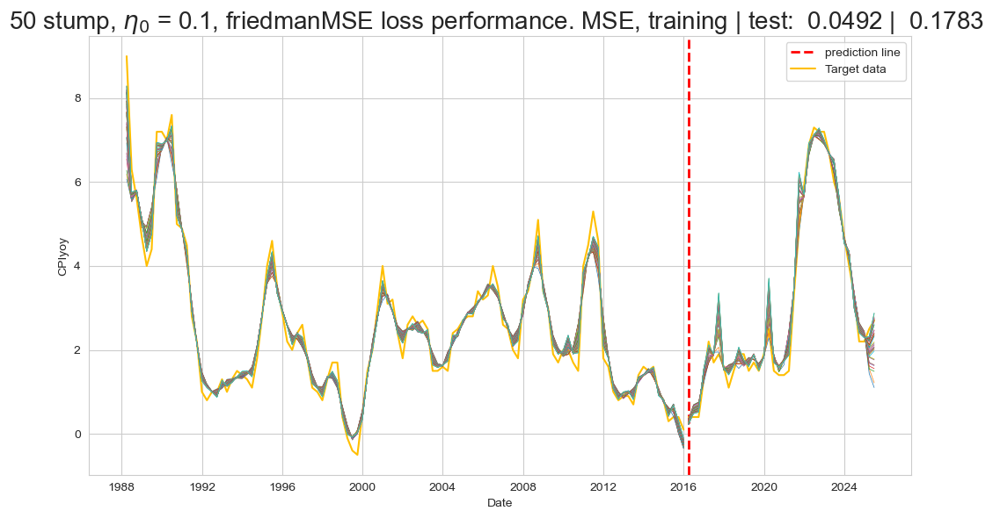

Train MSE: 0.04922321746852739 | Test MSE: 0.1783489740738291
Train MAE: 0.1722436567824738 | Test MAE: 0.26101062319921536
Train MAPE: 1.1144417830075573 | Test MAPE: 1.5113143688260613


In [93]:
best_model = GBoost(classifier = 'stump', n_estimators = 50, learning_rate = 0.1, subsample= None, seed = 21, 
                   loss_function = 'friedmanMSE', drop_rate= 0.2,
                   timeseries = True, periods = 4)

best_model.fit(X_train, y_train)
best_model_preds = best_model.predict(np.array(X_test))
best_model._timeseries_fit()
best_model_ts_preds = best_model._timeseries_predict(y_test)
best_model._get_all_scores(np.array(y_train), np.array(y_test))

plt.figure(figsize=(10, 6))
timeseries_pred_plot(X_train, y_train, X_test, y_test, best_model)
plt.show()

print(f"Train MSE: {metrics.mean_squared_error(best_model.y_resid, best_model.estimator_preds[-1])} | Test MSE: {metrics.mean_squared_error(best_model.y_resid_test, best_model.testing_preds[-1])}")
print(f"Train MAE: {metrics.mean_absolute_error(best_model.y_resid, best_model.estimator_preds[-1])} | Test MAE: {metrics.mean_absolute_error(best_model.y_resid_test, best_model.testing_preds[-1])}")
print(f"Train MAPE: {metrics.mean_absolute_percentage_error(best_model.y_resid, best_model.estimator_preds[-1])} | Test MAPE: {metrics.mean_absolute_percentage_error(best_model.y_resid_test, best_model.testing_preds[-1])}")

## Task 2.7. Walk Forward Validation
[Back to top](#Index) | [To section head](#TASK-2:-GRADIENT-BOOSTING-IN-CLASS-FORECASTING-COMPETITION) | [Code](#Timeseries-Validation) | [To Template section](#Task-2:-Gradient-Boosting-In-Class-NZ-Inflation-Forecasting-Competition-(35-Marks))

Taking the best model, I performed walk forward validation on it to see how it performs under simulated real conditions. I used a sliding window approach, testing twelve folds. The results hold up.

Earlier I mentioned that it is important at this point to take the mean of the prediction lines with this model for its prediction. This is waht I have done here. Each set of lines is a possible prediction. The model is refining itself, but I want to use the variation in the range of predictions for the model to make a better prediction of the unseen time step. I am at heart a Bayesian...

Below we see that the walking forward sliding window is getting better in each slide forward. I trained twelve windows for brevityThe red point indicates the prediction and the black indicates the tru value. There are times where the model performs poorly. Validations 3 to 6. Then it converges and performs very well as it reaches the prediciton line, which is when the test data runs out. This is very nice to see because the training window is fixed. The model converges as it slides from window 8 to 11 (9 to 12 zero not inclusive). Which I show in the convergence plot below the training windows plot. 

Here is another time to point out that the model is not indicating evidence of data leakage as the fit improves as the data plateaus. Being worse when the data is around a big hump. More variance in the underlying processes not entirely captured in the chosen features leading to poorer predictions. 

The test MSE becomes even better than the un-validated model. Final validation MSE being 0.02. When we look at tit slide we see it makes some crazy predictions at earleir times, converging to better performance as the window slides forward. 
A cracking good model if I do say so myself!

In [104]:
test_model = GBoost(classifier = 'stump', n_estimators = 50, learning_rate = 0.1, subsample= None, seed = 21, 
                   loss_function = 'friedmanMSE', drop_rate= 0.2,
                   timeseries = True, periods = 4)

Best_CV = TimeSeriesCV(test_model, X_train, y_train, len(y_train), 100, 1 )

In [105]:
Best_CV.fit(X_train, y_train)

Window 0 complete: 1988-03-31 00:00:00 to 2012-12-31 00:00:00
Window 1 complete: 1988-06-30 00:00:00 to 2013-03-31 00:00:00
Window 2 complete: 1988-09-30 00:00:00 to 2013-06-30 00:00:00
Window 3 complete: 1988-12-31 00:00:00 to 2013-09-30 00:00:00
Window 4 complete: 1989-03-31 00:00:00 to 2013-12-31 00:00:00
Window 5 complete: 1989-06-30 00:00:00 to 2014-03-31 00:00:00
Window 6 complete: 1989-09-30 00:00:00 to 2014-06-30 00:00:00
Window 7 complete: 1989-12-31 00:00:00 to 2014-09-30 00:00:00
Window 8 complete: 1990-03-31 00:00:00 to 2014-12-31 00:00:00
Window 9 complete: 1990-06-30 00:00:00 to 2015-03-31 00:00:00
Window 10 complete: 1990-09-30 00:00:00 to 2015-06-30 00:00:00
Window 11 complete: 1990-12-31 00:00:00 to 2015-09-30 00:00:00


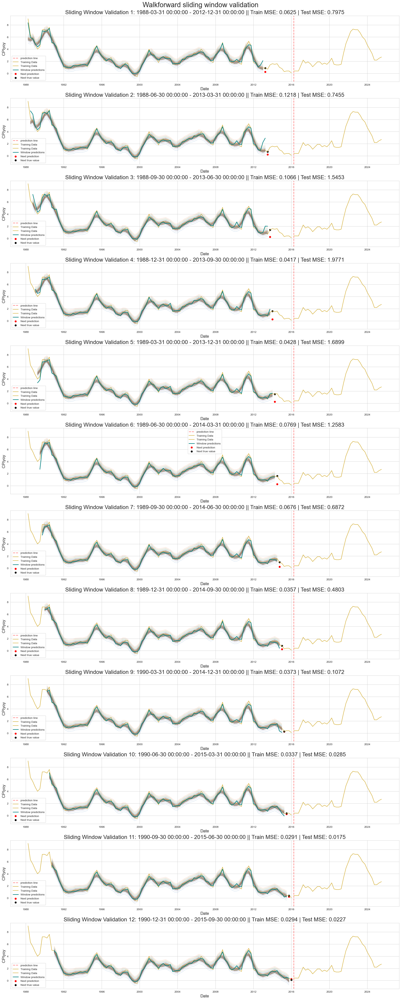

In [108]:
fig, ax = plt.subplots(nrows=12, ncols=1, figsize=(20, 50), constrained_layout=True)

for i in range(len(Best_CV.windows_train)):
    ax[i] = validation_plot(Best_CV, y_train, y_test, i, ax = ax[i])

plt.suptitle('Walkforward sliding window validation', size = 25)
plt.show()

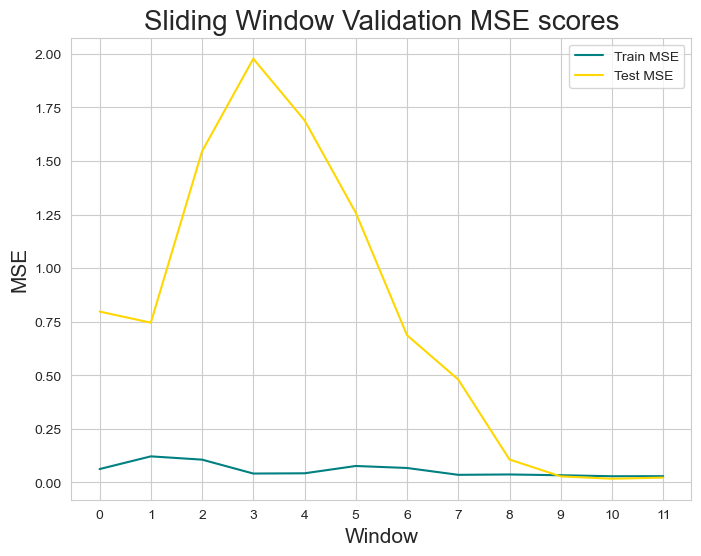

In [109]:
plt.figure(figsize=(8, 6))
plt.plot(Best_CV.CV_mse_train_list, label = 'Train MSE', color = 'teal')
plt.plot(Best_CV.CV_mse_test_list, label = 'Test MSE', color = 'gold')
plt.xlabel('Window', size = 15)
plt.ylabel('MSE', size = 15)
plt.title('Sliding Window Validation MSE scores', size =20)
plt.xticks(np.arange(0,12,1))
plt.legend()
plt.show()

## Task 2.8. File Output
[Back to top](#Index) | [To section head](#TASK-2:-GRADIENT-BOOSTING-IN-CLASS-FORECASTING-COMPETITION) | [To Template section](#Task-2:-Gradient-Boosting-In-Class-NZ-Inflation-Forecasting-Competition-(35-Marks))

In [56]:
(best_model.timeseries_pred_test[-1])

array([0.24310347, 0.47967603, 0.51420079, 1.54344549, 2.1222296 ,
       1.90429348, 3.36045031, 1.57784939, 1.40228412, 1.618033  ,
       2.06945183, 1.76031018, 1.60128282, 1.88584838, 1.50835853,
       1.826952  , 3.7125002 , 1.7020508 , 1.58407214, 1.73190337,
       1.86990022, 3.43644264, 6.23691686, 5.70339987, 6.93758889,
       7.12282452, 7.29427065, 7.01244708, 6.68493448, 6.4866403 ,
       5.6634651 , 4.54247049, 4.32223256, 2.99155873, 2.40170079,
       2.28433779, 2.32495334, 2.88008976])

In [59]:
X_train.to_csv('X_train_final.csv', index = True)
X_test.to_csv('X_test_final.csv', index = True)

predictions = pd.DataFrame(best_model.timeseries_pred_test[-1], columns = ['CPIyoy_pred']).set_index(y_test.index)
predictions.to_csv("20001249_y_pred.csv", index= True)

## Task 2.9. Forecast Q3 2025
[Back to top](#Index) | [To section head](#TASK-2:-GRADIENT-BOOSTING-IN-CLASS-FORECASTING-COMPETITION) | [To Template section](#Task-2:-Gradient-Boosting-In-Class-NZ-Inflation-Forecasting-Competition-(35-Marks))

make a next test set with the previous prediction as the y value, then re-predict using the test X data. 
need to somehow carry the x data forward

do a lead on the y_data for test by one time step.

For this I am going to merge the triaining and test data into one data set. Train the model on everything and then predict one data point. To get the new X values I will interpolate forward one step. I am not going to split hairs about the method. As the question here is simply 'can you do it?'.

The process is quite invovled, due to the timeseries format of the data. In short:
1. I join the test and training data together (because in a real situation I'd have all the data). 
2. Add one more row for the next quarter 2025-09-30. 
3. Impute the X variables values using a rolling mean of 4 periods (anything less and the values imputed are simply the last period values, and I didn't see much point to use more than 4 periods)
4. Split off the last row. 
5. Fit the best model on the data.
6. Predict the next value. 
7. Reconstitute the prediction using the seasonlly decomposed components of the y values. 
8. Add the reconstituted predicted value to the y values. 
9. Run step 7 and 8 again. Optional. I did this because the first reconstitution uses NULL values for trend and season, and I wanted to get some data in there for some season and trend for the predicted value. 

This results in a predicted CPIyoy value of 2.23. Which is close the to the projected estiamte of 2.3 of Tradingeconomics.com (2025). We will see what the value really is when it comes out. 

In [111]:
#join DF and get same timestamp index
X_train_fc = pd.concat([X_train, X_test]).set_index(y_values.index)
y_train_fc = y_values.copy() #for training
fc_data = pd.concat([y_values,X_train_fc], axis = 1)

#reindex and add new row.
new_index = pd.date_range(start = '1988-03-31', periods = 151, freq = 'Q')
fc_data = fc_data.reindex(new_index)

#drop y values
X_train_fc = fc_data.drop('CPIyoy', axis=1)

#rolling mean for new value, this is to avoid using the same data as the previous row which results in the same prediction
rolling_mean = X_train_fc.rolling(window=4, center=True, min_periods=1).mean()
rolling_mean.tail(10)

#drop last row of X_train
X_train_fc.drop(index = X_train_fc.index[-1], axis = 0, inplace = True)

#get the last value for test data
X_test_fc = pd.DataFrame(rolling_mean.iloc[-1]).T
X_test_fc

,CPIyoy_whitened_fourier_signal_resid,CPIyoy_1qrt_change_whitened_resid,CPIyoy_1qrt_change_resid,CPIyoy_3qrt_change_resid,CPIyoy_3qrt_change_whitened_resid,CPIyoy_roll_sum_2_resid,CPIyoy_roll_sum_2_whitened_resid,CPIyoy_2qrt_change_whitened_resid,CPIyoy_2qrt_change_resid,Food (y/y%)_whitened_fourier_signal_resid,Producers price index (PPI) inputs (y/y%)_whitened_fourier_signal_resid,Oil LPG.2_resid,Transportation (y/y%)_resid,Transportation (y/y%)_roll_sum_1_whitened_resid,Transportation (y/y%)_roll_sum_1_resid,Transportation (y/y%)_roll_mean_1_whitened_resid,Food (y/y%)_resid,Tradable inflation (y/y%)_resid
2025-09-30,0.382576,0.707866,32.191911,49.107971,0.429539,2.366243,0.556482,0.602293,55.671126,0.439739,0.19184,0.040958,3.746128,0.659556,3.746128,0.659556,6.24683,3.901826


In [112]:
FC_model = GBoost(classifier = 'stump', n_estimators = 50, learning_rate = 0.1, subsample= None, seed = 21, 
                   loss_function = 'friedmanMSE', drop_rate= 0.2, timeseries = True, periods = 4)

FC_model.fit(X_train_fc, y_values)
FC_model_preds = FC_model.predict(np.array(X_test_fc))
FC_model._timeseries_fit()
# best_model_ts_preds = best_model._timeseries_predict(y_test)

In [113]:
# Now I have to get the seasonal and trend components of the test data. First get the prediction
#add to y values for plotting
y_fc = y_values.reindex(new_index)
#Get seasonal components
fc_trend, fc_season, fc_resid = seasonal_decompose_df(y_fc, model = 'additive', period = 4)
#recompose prediction
y_pred_fc = FC_model_preds + np.array(fc_trend.iloc[-1]) + np.array(fc_season.iloc[-1])
#add to new df
y_fc.iloc[-1] = y_pred_fc

#now the data is in, do it again. Optional step. I choose to do it because the first prediction is made with the last row of NaN seasonal and trend components
fc_trend, fc_season, fc_resid = seasonal_decompose_df(y_fc, model = 'additive', period = 4)
y_pred_fc = FC_model_preds + np.array(fc_trend.iloc[-1]) + np.array(fc_season.iloc[-1])
# y_pred_fc

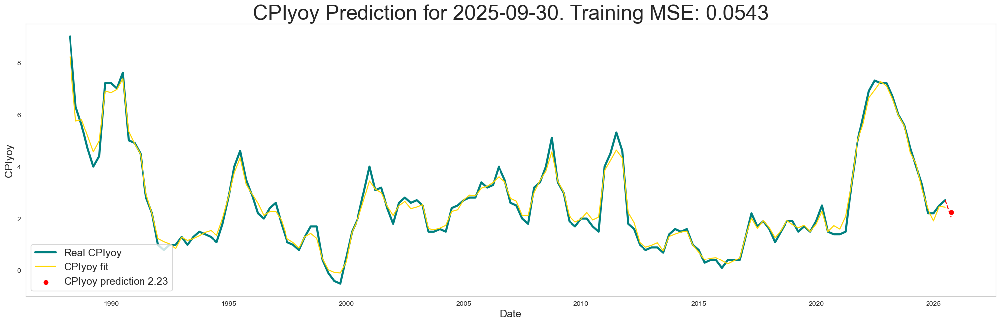

In [114]:
# y_pred_fc = FC_model_preds + np.array(fc_trend.iloc[-1]) + np.array(fc_season.iloc[-1])
y_pred_date = X_test_fc.index.strftime('%Y-%m-%d')

plt.figure(figsize=(20, 6)) 

plt.plot(y_values, color = 'teal', label = 'Real CPIyoy', linewidth= 3)
plt.plot(y_values.index, FC_model.timeseries_pred_train[-1], color = 'gold', label = 'CPIyoy fit')
plt.scatter(X_test_fc.index, y_pred_fc, color = 'red', label = f'CPIyoy prediction {y_pred_fc[0]:.2f}')
plt.plot(y_fc.iloc[-2:], linestyle = '--', color = 'red')
plt.tight_layout()
plt.legend(fontsize = 15, loc = 'lower left')
plt.grid()
plt.ylabel('CPIyoy', size = 15)
plt.xlabel('Date', size = 15)
plt.title(f'CPIyoy Prediction for {y_pred_date[0]}. Training MSE: {FC_model.score_history[-1]:.4f}', size = 30)

plt.show()


# Task 3: EXPERIMENTATION USING A RANGE OF ALGORITHMS
[Back to top](#Index) | [To Template Section](#Task-3:-NZ-Inflation-Forecasting-Competition-Using-a-Range-of-Algorithms-(10-Marks))

* [3.1. Model Comparison](#Task-3.1.-Model-Comparison)
* [3.2. Grid Search](#Task-3.2.-Grid-search)
* [3.3. Model Validation](#Task-3.3.-Model-Validation)
* [3.4 Other models](#Task-3.4-Other-models)

For this quesiton I will try the same data set as used with the best model above on CatBoost, XGBoost, SKLearn's gradient boost and LightGBM. I also have my own XGBoost implementation I will try. Each of these will be fit, predicted and validated, albeit, with far fewer estimators and a smaller validation set.

Before gion further, the scores of the models trained and fit are shown below. I do not show the models prior to grid search to keep things cleaner. We can see that XG boost and CatBoost are the best, while the other forecastng models from the darts package do poorly. Because they do not fit the whole data, nly the y_value. It is good to see that my custom models out perform them.

In [1]:
import xgboost as xgb
import lightgbm as LGBM
import catboost as cat

In [60]:
models = ['Sk gradient boost', 'my gradient boost', 'XGBoost', 'My XGboost', 'CatBoost', 'LGBM', 'Exponential Smoothing', 'Naive Forecast', 'Regression Ensemble']
Train_score = [metrics.mean_squared_error(sk_GB_gridS_fit, y_trResid), 
               best_model.score_history[-1], 
               metrics.mean_squared_error(XGB_gridS_fit, y_trResid),
               metrics.mean_squared_error(y_train, myXG_gridS.estimator_preds[-1] + y_trSeason.CPIyoy_seasonal + y_trTrend.CPIyoy_trend),
               metrics.mean_squared_error(CAT_gridS_fit, y_trResid), 
               metrics.mean_squared_error(LGBM_gridS_fit, y_trResid),None, None ,None]

Test_score = [metrics.mean_squared_error(sk_GB_gridS_pred, y_tsResid), 
              metrics.mean_squared_error(best_model.testing_preds[-1], y_tsResid),
              metrics.mean_squared_error(XGB_gridS_pred, y_tsResid),
             metrics.mean_squared_error(myXG_gridS_pred, y_tsResid), 
              metrics.mean_squared_error(CAT_gridS_pred, y_tsResid),
             metrics.mean_squared_error(LGBM_gridS_pred, y_tsResid), 
              24.42, 
              11.74, 
              5.38 ]

task3_scores = pd.DataFrame({'Models': models, 'Train MSE': Train_score, 'Test MSE': Test_score})
task3_scores

,Models,Train MSE,Test MSE
0,Sk gradient boost,0.073900,0.057206
1,my gradient boost,0.049223,0.178349
2,XGBoost,0.003014,0.066999
3,My XGboost,0.188213,0.162619
4,CatBoost,0.002875,0.058573
5,LGBM,0.055192,0.078441
6,Exponential Smoothing,NaN,24.420000
7,Naive Forecast,NaN,11.740000
8,Regression Ensemble,NaN,5.380000


## Task 3.1. Model Comparison
[Back to top](#Index) | [To section head](#Task-3:-EXPERIMENTATION-USING-A-RANGE-OF-ALGORITHMS) | [To Template Section](#Task-3:-NZ-Inflation-Forecasting-Competition-Using-a-Range-of-Algorithms-(10-Marks))

On a basic model comparison, what we see is that the other implementations are comparable, and better than my implementation. Not particualrly to be expected, given I am an ametuer, but my model is comparable.
My XGBoost implementation is also comparable with test MSE of 0.04 a smidge better than LGBM and Catboost at 0.06 and 0.05 respectively 

In [44]:
sk_GB = GradientBoostingRegressor(loss = 'squared_error', learning_rate=0.3, n_estimators=50, criterion='friedman_mse', max_depth = 1)
sk_GB.fit(X_train, y_trResid)
sk_GB_pred = sk_GB.predict(X_test)
sk_GB_fit = sk_GB.predict(X_train)

XGboost = xgb.XGBRegressor(n_estimators  = 50, eta = 0.3, max_depth = 6, seed= 21)
XGboost.fit(X_train, y_trResid)
XGboost_pred = XGboost.predict(X_test)
XGboost_fit = XGboost.predict(X_train)

CatBoost = cat.CatBoostRegressor(iterations = 50, learning_rate = 0.3, loss_function = 'RMSE', depth = 10, 
                                 bootstrap_type='Bayesian', verbose = False)
CatBoost.fit(X_train, y_trResid)
CatBoost_pred = CatBoost.predict(X_test)
CatBoost_fit = CatBoost.predict(X_train)

my_XG = GBoost(classifier = 'Xtreme', n_estimators = 50, loss_function = 'friedmanMSE', learning_rate = 0.01, max_depth = 4,
              base_prediction = y_trResid.mean(), colsample_bynode = 0.3, min_child_weight = 0.1, 
              timeseries = True, periods = 4)
my_XG.fit(X_train, y_train)
my_XG_pred = my_XG.predict(np.array(X_test))
# my_XG._timeseries_fit()
# my_XG_ts_preds = my_XG._timeseries_predict(y_test)

LGBMmodel = LGBM.LGBMRegressor(seed = 21, learning_rate = 0.3,n_estimators =50, max_depth =10, objective ='huber', verbosity = -1 )
LGBMmodel.fit(X_train, y_trResid)
LGBM_pred = LGBMmodel.predict(X_test)
LGBM_fit = LGBMmodel.predict(X_train)

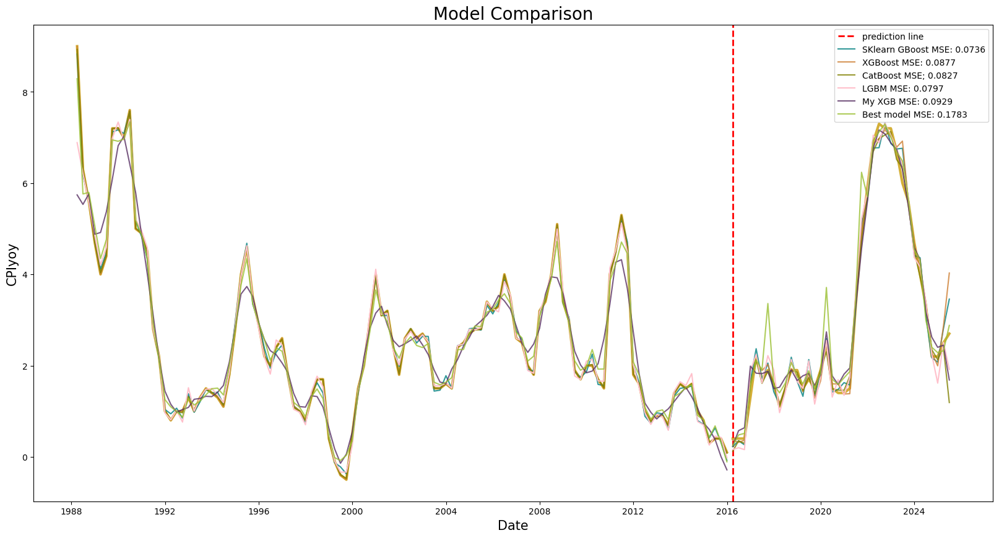

In [45]:
v_line = mdates.date2num(dt.datetime.strptime('2016-03-31', '%Y-%m-%d'))

plt.figure(figsize=(20, 10)) 


plt.plot(y_train, color = '#D4AF37', linewidth=3)
plt.plot(y_test, color = '#D4AF37', linewidth=3)
plt.axvline(x=v_line, color='red', linestyle='--', linewidth=2, label = 'prediction line')

#Sklearn
plt.plot(y_test.index, (sk_GB_pred + y_tsSeason.CPIyoy_seasonal + y_tsTrend.CPIyoy_trend), color = 'teal', label = f'SKlearn GBoost MSE: {metrics.mean_squared_error(sk_GB_pred, y_tsResid):.4f}', alpha = 0.8)
plt.plot(y_train.index, (sk_GB_fit + y_trSeason.CPIyoy_seasonal + y_trTrend.CPIyoy_trend), color = 'teal', alpha = 0.8)
#XGboost
plt.plot(y_test.index, (XGboost_pred + y_tsSeason.CPIyoy_seasonal + y_tsTrend.CPIyoy_trend), color = '#CD7F32', label = f'XGBoost MSE: {metrics.mean_squared_error(XGboost_pred, y_tsResid):.4f}', alpha = 0.8)
plt.plot(y_train.index, (XGboost_fit + y_trSeason.CPIyoy_seasonal + y_trTrend.CPIyoy_trend), color = '#CD7F32', alpha = 0.8)
#CatBoost
plt.plot(y_test.index, (CatBoost_pred + y_tsSeason.CPIyoy_seasonal + y_tsTrend.CPIyoy_trend), color = 'olive', label = f'CatBoost MSE; {metrics.mean_squared_error(CatBoost_pred, y_tsResid):.4f}', alpha = 0.8)
plt.plot(y_train.index, (CatBoost_fit + y_trSeason.CPIyoy_seasonal + y_trTrend.CPIyoy_trend), color = 'olive', alpha = 0.8)
#LGBM
plt.plot(y_test.index, (LGBM_pred + y_tsSeason.CPIyoy_seasonal + y_tsTrend.CPIyoy_trend), color = 'pink', label = f'LGBM MSE: {metrics.mean_squared_error(LGBM_pred, y_tsResid):.4f}', alpha = 1)
plt.plot(y_train.index, (LGBM_fit + y_trSeason.CPIyoy_seasonal + y_trTrend.CPIyoy_trend), color = 'pink', alpha = 1)
#My XGBoost
plt.plot(y_test.index, (my_XG_pred + y_tsSeason.CPIyoy_seasonal + y_tsTrend.CPIyoy_trend), color = '#593163', label = f'My XGB MSE: {metrics.mean_squared_error(my_XG_pred, y_tsResid):.4f}', alpha = 0.8)
plt.plot(y_train.index, (my_XG.estimator_preds[-1] + y_trSeason.CPIyoy_seasonal + y_trTrend.CPIyoy_trend), color = '#593163', alpha = 0.8)
#Best model
plt.plot(y_test.index, (best_model.testing_preds[-1] + y_tsSeason.CPIyoy_seasonal + y_tsTrend.CPIyoy_trend), color = '#9AC032', label = f'Best model MSE: {metrics.mean_squared_error(best_model.testing_preds[-1], y_tsResid):.4f}', alpha = 0.8)
plt.plot(y_train.index, (best_model.estimator_preds[-1] + y_trSeason.CPIyoy_seasonal + y_trTrend.CPIyoy_trend), color = '#9AC032', alpha = 0.8)

plt.ylabel('CPIyoy', size = 15)
plt.xlabel('Date', size = 15)
plt.title('Model Comparison', size = 20)
plt.legend(fontsize = 10)
plt.show()

## Task 3.2. Grid search
[Back to top](#Index) | [To section head](#Task-3:-EXPERIMENTATION-USING-A-RANGE-OF-ALGORITHMS) | [To Template Section](#Task-3:-NZ-Inflation-Forecasting-Competition-Using-a-Range-of-Algorithms-(10-Marks))

Next we perform grid search on each model. Except the best_model which has already had this process done on it. I used a targeted grid search to save time and sanity. The results are similar to the basic model. SKlearn worsened to 0.02 from 0.02. XGboost got only a little better.
Cat boost improved from 0.05 to 0.02. LGBM stayed at 0.06, but slightly worse at the third dp. My XG boost got worse, up to 0.14, due to my grid search having more depth as I chose to see what happened with more depth than earlier. This is a difference between my implementaiton and others. My implementation prefers shalllower trees for this data, as the first fit had depth 4 and was comparable to depth 10 of the other fits. 

In [46]:
tscv = TimeSeriesSplit(n_splits = 5)

In [47]:
#SKlearn GB
GB_search_grid = {'learning_rate': [0.3, 0.2, 0.01],
              'loss': ['squared_error', 'huber'],
              'validation_fraction': [None, 0.2],
              'n_iter_no_change': [5],
              'min_impurity_decrease': [0.1, 0.01],
              'tol': [0.001]}

skGB_model = GradientBoostingRegressor(max_depth = 1, n_estimators = 50, random_state = 21)

skGB_gridsearch = GridSearchCV(estimator = skGB_model, cv = tscv, param_grid = GB_search_grid)
skGB_gridsearch.fit(X_train, y_trResid)

print("Best parameters:", skGB_gridsearch.best_params_)

sk_GB_gridS = GradientBoostingRegressor(**skGB_gridsearch.best_params_, max_depth = 1, n_estimators = 50, random_state = 21)
sk_GB_gridS.fit(X_train, y_trResid)
sk_GB_gridS_pred = sk_GB_gridS.predict(X_test)
sk_GB_gridS_fit = sk_GB_gridS.predict(X_train)

Best parameters: {'learning_rate': 0.2, 'loss': 'huber', 'min_impurity_decrease': 0.1, 'n_iter_no_change': 5, 'tol': 0.001, 'validation_fraction': 0.2}


In [48]:
#XGboost
XGB_search_grid = {'eta': [0.3, 0.2, 0.01],
#               'loss': ['squared_error', 'huber'],
              'min_child_weight': [0.5, 1.3],
               'max_depth': [3, 6, 9],
               'alpha' : [0.1, 0.3],
               'lambda':[0.1, 0.3],
              'objective': ['reg:pseudohubererror', 'reg:squarederror']}

XGB_model = xgb.XGBRegressor(n_estimators = 50, random_state = 21)

XGB_gridsearch = GridSearchCV(estimator = XGB_model, cv = tscv, param_grid = XGB_search_grid)
XGB_gridsearch.fit(X_train, y_trResid)

print("Best parameters:", XGB_gridsearch.best_params_)

XGB_gridS = xgb.XGBRegressor(**XGB_gridsearch.best_params_, n_estimators = 50, random_state = 21)
XGB_gridS.fit(X_train, y_trResid)
XGB_gridS_pred = XGB_gridS.predict(X_test)
XGB_gridS_fit = XGB_gridS.predict(X_train)

Best parameters: {'alpha': 0.3, 'eta': 0.2, 'lambda': 0.1, 'max_depth': 3, 'min_child_weight': 0.5, 'objective': 'reg:squarederror'}


In [49]:
#CatBoost
CAT_search_grid = {'learning_rate': [0.3, 0.2, 0.01],
              'loss_function': ['RMSE', 'Huber'],
              'l2_leaf_reg': [0.5, 1],
               'depth': [3, 6, 9],
               'bootstrap_type' : ['Bayesian', 'MVS']}

CAT_model = cat.CatBoostRegressor(iterations = 50, random_state = 21)

CAT_gridsearch = GridSearchCV(estimator = XGB_model, cv = tscv, param_grid = CAT_search_grid)
CAT_gridsearch.fit(X_train, y_trResid)

print("Best parameters:", CAT_gridsearch.best_params_)

CAT_gridS = cat.CatBoostRegressor(**CAT_gridsearch.best_params_, iterations = 50, random_state = 21, verbose = False)
CAT_gridS.fit(X_train, y_trResid)
CAT_gridS_pred = CAT_gridS.predict(X_test)
CAT_gridS_fit = CAT_gridS.predict(X_train)

Best parameters: {'bootstrap_type': 'Bayesian', 'depth': 3, 'l2_leaf_reg': 0.5, 'learning_rate': 0.3, 'loss_function': 'RMSE'}


In [50]:
# #LGBM
LGBM_search_grid = {'learning_rate': [0.3, 0.2, 0.01],
                   'boosting': ['gbdt', 'dart'],
#               'objective': ['reg:squarederror', 'reg:pseudohubererror'],#got loads of errors 
               'depth': [3, 6, 9],
               'extra_trees' : [True, False],
              'lambda_l1':[0, 1],
              'lambda_l2':[0, 1],
                  'drop_rate':[0.2, 0.1]}

LGBM_model = LGBM.LGBMRegressor(iterations = 50, random_state = 21, verbosity = -1, boost_from_average = True)

LGBM_gridsearch = GridSearchCV(estimator = XGB_model, cv = tscv, param_grid = LGBM_search_grid)
LGBM_gridsearch.fit(X_train, y_trResid)

print("Best parameters:", LGBM_gridsearch.best_params_) #note need to transcribe these, regression objective is default

LGBM_gridS = LGBM.LGBMRegressor(iterations = 50, random_state = 21, verbosity = -1, boost_from_average = True, boosting= 'gbdt', depth= 3, drop_rate= 0.2, extra_trees= True, lambda_l1=0, lambda_l2= 0, learning_rate= 0.2)
LGBM_gridS.fit(X_train, y_trResid)
LGBM_gridS_pred = LGBM_gridS.predict(X_test)
LGBM_gridS_fit = LGBM_gridS.predict(X_train)

Best parameters: {'boosting': 'gbdt', 'depth': 3, 'drop_rate': 0.2, 'extra_trees': True, 'lambda_l1': 0, 'lambda_l2': 0, 'learning_rate': 0.3}


In [51]:
#My XGBoost
MyXG_search_grid = {'learning_rate': [0.01],
               'max_depth': [10, 15],
              'colsample_bynode':[0.3, 0.5],
                  'drop_rate':[0.2, 0.1],
                   'min_child_weight': [0.1, 0.3]}

myXG_model = GBoost(n_estimators = 50, seed = 21, base_prediction = y_trResid.mean())

myXG_gridsearch = GridSearchCV(estimator = XGB_model, cv = tscv, param_grid = MyXG_search_grid)
myXG_gridsearch.fit(X_train, y_trResid)

print("Best parameters:", myXG_gridsearch.best_params_) #note need to transcribe these, regression objective is default

myXG_gridS = GBoost(seed= 21, n_estimators = 50, base_prediction = y_trResid.mean(), **myXG_gridsearch.best_params_, decay = 0.001, decay_function = 'inverse', decay_steps=5)
myXG_gridS.fit(np.array(X_train), np.array(y_trResid))
myXG_gridS_pred = myXG_gridS.predict(np.array(X_test))
# myXG_gridS_fit = myXG_gridS.predict(X_train5)

Best parameters: {'colsample_bynode': 0.5, 'drop_rate': 0.2, 'learning_rate': 0.01, 'max_depth': 10, 'min_child_weight': 0.1}


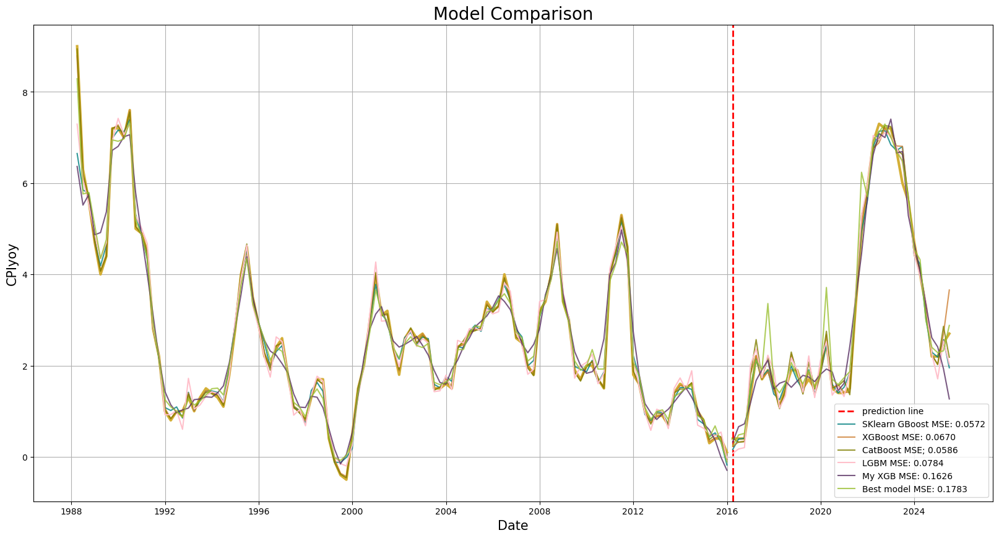

In [52]:
v_line = mdates.date2num(dt.datetime.strptime('2016-03-31', '%Y-%m-%d'))

plt.figure(figsize=(20, 10)) 

plt.plot(y_train, color = '#D4AF37', linewidth=3)
plt.plot(y_test, color = '#D4AF37', linewidth=3)
plt.axvline(x=v_line, color='red', linestyle='--', linewidth=2, label = 'prediction line')

#Sklearn
plt.plot(y_test.index, (sk_GB_gridS_pred + y_tsSeason.CPIyoy_seasonal + y_tsTrend.CPIyoy_trend), color = 'teal', label = f'SKlearn GBoost MSE: {metrics.mean_squared_error(sk_GB_gridS_pred, y_tsResid):.4f}', alpha = 0.8)
plt.plot(y_train.index, (sk_GB_gridS_fit + y_trSeason.CPIyoy_seasonal + y_trTrend.CPIyoy_trend), color = 'teal', alpha = 0.8)
#XGboost
plt.plot(y_test.index, (XGB_gridS_pred + y_tsSeason.CPIyoy_seasonal + y_tsTrend.CPIyoy_trend), color = '#CD7F32', label = f'XGBoost MSE: {metrics.mean_squared_error(XGB_gridS_pred, y_tsResid):.4f}', alpha = 0.8)
plt.plot(y_train.index, (XGB_gridS_fit + y_trSeason.CPIyoy_seasonal + y_trTrend.CPIyoy_trend), color = '#CD7F32', alpha = 0.8)
#CatBoost
plt.plot(y_test.index, (CAT_gridS_pred + y_tsSeason.CPIyoy_seasonal + y_tsTrend.CPIyoy_trend), color = 'olive', label = f'CatBoost MSE; {metrics.mean_squared_error(CAT_gridS_pred, y_tsResid):.4f}', alpha = 0.8)
plt.plot(y_train.index, (CAT_gridS_fit + y_trSeason.CPIyoy_seasonal + y_trTrend.CPIyoy_trend), color = 'olive', alpha = 0.8)
#LGBM
plt.plot(y_test.index, (LGBM_gridS_pred + y_tsSeason.CPIyoy_seasonal + y_tsTrend.CPIyoy_trend), color = 'pink', label = f'LGBM MSE: {metrics.mean_squared_error(LGBM_gridS_pred, y_tsResid):.4f}', alpha = 1)
plt.plot(y_train.index, (LGBM_gridS_fit + y_trSeason.CPIyoy_seasonal + y_trTrend.CPIyoy_trend), color = 'pink', alpha = 1)
#My XGBoost
plt.plot(y_test.index, (myXG_gridS_pred + y_tsSeason.CPIyoy_seasonal + y_tsTrend.CPIyoy_trend), color = '#593163', label = f'My XGB MSE: {metrics.mean_squared_error(myXG_gridS_pred, y_tsResid):.4f}', alpha = 0.8)
plt.plot(y_train.index, (myXG_gridS.estimator_preds[-1] + y_trSeason.CPIyoy_seasonal + y_trTrend.CPIyoy_trend), color = '#593163', alpha = 0.8)
# #Best model
plt.plot(y_test.index, (best_model.testing_preds[-1] + y_tsSeason.CPIyoy_seasonal + y_tsTrend.CPIyoy_trend), color = '#9AC032', label = f'Best model MSE: {metrics.mean_squared_error(best_model.testing_preds[-1], y_tsResid):.4f}', alpha = 0.8)
plt.plot(y_train.index, (best_model.estimator_preds[-1] + y_trSeason.CPIyoy_seasonal + y_trTrend.CPIyoy_trend), color = '#9AC032', alpha = 0.8)

plt.ylabel('CPIyoy', size = 15)
plt.xlabel('Date', size = 15)
plt.title('Model Comparison', size = 20)
plt.legend(fontsize = 10)
plt.grid()
plt.show()

## Task 3.3. Model Validation
[Back to top](#Index) | [To section head](#Task-3:-EXPERIMENTATION-USING-A-RANGE-OF-ALGORITHMS) | [Code](#Timeseries-Validation) | [To Template Section](#Task-3:-NZ-Inflation-Forecasting-Competition-Using-a-Range-of-Algorithms-(10-Marks))

Here I validate each model. Looking at the models we can see varied behaviour. From the XGBoost's linear traininig MSE shooting up to 0.2, to more convergent behaviour like my XG boost model and light GBM. I have snuck in one more model, the adaptive boost decay on the XG model. Purely out of curiosity. These models are all quite good, even the adaptive boost one, with an MSE of 1 for the final validation set. Not good by comparison to it's peers, but it does get to 0 around window 7. In general all the models seem to fit pretty well. 

We see that the on validation windows the models perform more reasonably in the testing MSE. XGB's last testing MSE is 0.2. My XGB implementation is more consistent, registering MSEs around 0.15 often, give or take, ending around 0.02. Wihle the adaptive XGBoost I snuck in for comparison has a final MSE of 0.4.

To round this section off we will look at a few plots of the validation. We see that, like the best model from task 2, the model gets better towards the last validations. partly because the model may be laerning better, but partly because the trend is plateauing coming up to 2016. A little bit of NZ economic history, Bill English was an criminally good finance minister, albeit a lacklustre PM personality. That plateau period is in and follows his tenure. While the decaline from 1988 to 2002 was during the tenure of Don Brash as head of the Reserve Bank. He implemented inflation targetting, which was ground breaking at the time. Perhaps the single most important, least spoken about and not followed act of monetary policy ever. The final crystalisation of Milton Friedman's monetarism. Prompty done away with after his tenure. Which resulted in a rise thereafter. 

Anyway, because of the implementations of the out of the box models and my custom ones, the OOTB models don't show the bands of all fits. My XGboost validations do, and these are very thin. Much smoother than the OOTB xgboost. As a comparison is is interesting to see that my implementations have missed the extreme peaks, not being as variable as the best gradient boost model which had variation enough to capture them. While the OOTB models fit remarkable perfectly. The adaptive boost is a nice contrast, because it hasa tendency to predict poorly the next time step. When coupled with XGBoost it performs much differently due to the boost trees which result in smaller gradients for eac point, so it doens't get all the needed variability from the data as it did with gradient boost. It need variance to get a wide posterior distribution for more accurate fits, but it does well regardless.

The overall excellent performance of these models is in large part due to the selected features. Consisting of CPI lagged variables, food, transportation, tradable inflation and petrol prices. These all have strong signals to CPI, explaining the white noise very well. Over all, the XGBoost model is by far the best model. Reaching MSEs of 0.0002, which are highly suspect, but which I can't reason my way out of, given the methodolgy I followed, so I will need to accept the performance.  Which is no surprise given XGBoost's reputation. 


In [55]:
SK_CV = TimeSeriesCV_OOTB(sk_GB, X_train, y_train, len(y_train), 100, 1 )
SK_CV.fit(X_train, y_train)

XGB_CV = TimeSeriesCV_OOTB(XGboost, X_train, y_train, len(y_train), 100, 1 )
XGB_CV.fit(X_train, y_train)

CAT_CV = TimeSeriesCV_OOTB(CAT_gridS, X_train, y_train, len(y_train), 100, 1 )
CAT_CV.fit(X_train, y_train)

LGBM_CV = TimeSeriesCV_OOTB(LGBM_gridS, X_train, y_train, len(y_train), 100, 1 )
LGBM_CV.fit(X_train, y_train)

my_XG = GBoost(classifier = 'Xtreme', n_estimators = 50, loss_function = 'friedmanMSE', learning_rate = 0.01, max_depth = 4,
              base_prediction = y_trResid.mean(), colsample_bynode = 0.3, min_child_weight = 0.1, drop_rate = 0.2, 
              timeseries = True, periods = 4)

myXG_CV = TimeSeriesCV(my_XG, X_train, y_train, len(y_train), 100, 1 )
myXG_CV.fit(X_train, y_train)

#sneaking in one more
adaptive = GBoost(classifier = 'Xtreme', n_estimators = 20, loss_function = 'friedmanMSE', learning_rate = 0.3, max_depth = 2,
              base_prediction = y_trResid.mean(), colsample_bynode = 0.3, min_child_weight = 0.1, drop_rate = 0.2, decay = 'adaptive',
              timeseries = True, periods = 4)

adaptive_CV = TimeSeriesCV(adaptive, X_train, y_train, len(y_train), 100, 1 )
adaptive_CV.fit(X_train, y_train)

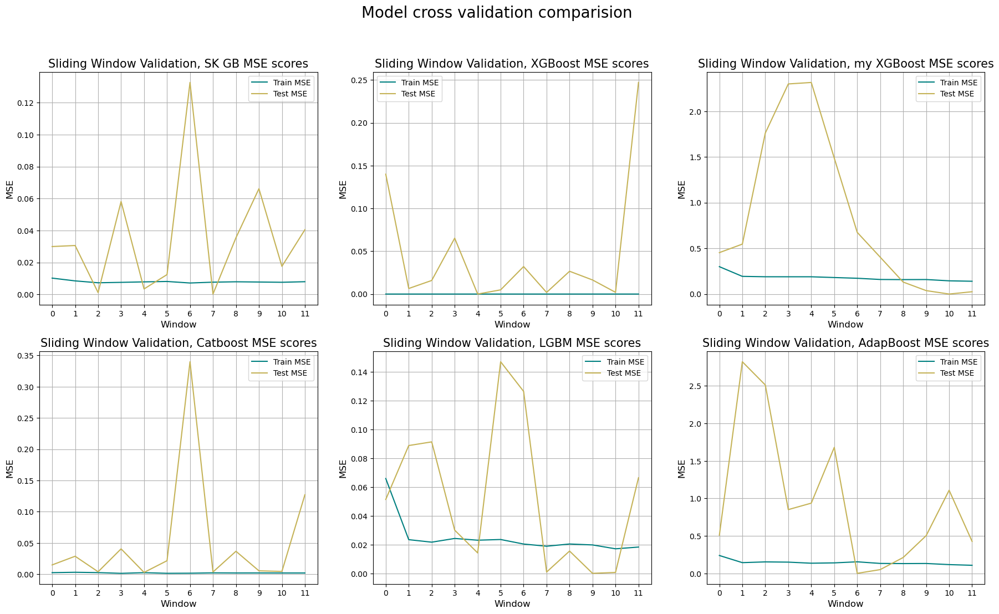

In [56]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(22, 12))
ax[0][0] = timeseries_convergence_plot(SK_CV, 'SK GB', ax = ax[0][0])
ax[0][1] = timeseries_convergence_plot(XGB_CV, 'XGBoost', ax = ax[0][1])
ax[0][2] = timeseries_convergence_plot(myXG_CV, 'my XGBoost', ax = ax[0][2])
ax[1][0] = timeseries_convergence_plot(CAT_CV, 'Catboost', ax = ax[1][0])
ax[1][1] = timeseries_convergence_plot(LGBM_CV, 'LGBM', ax = ax[1][1])
ax[1][2] = timeseries_convergence_plot(adaptive_CV, 'AdapBoost', ax = ax[1][2])
plt.suptitle('Model cross validation comparision', size = 20)
plt.show()

### XGBoost

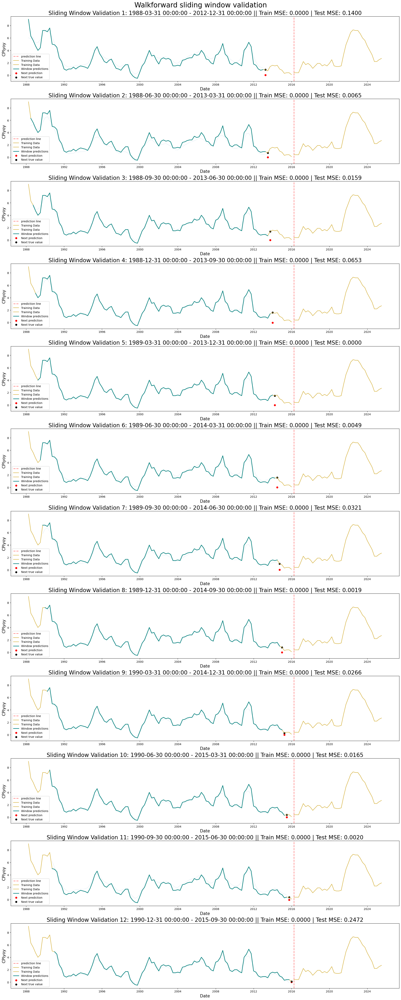

In [57]:
fig, ax = plt.subplots(nrows=12, ncols=1, figsize=(20, 50), constrained_layout=True)

for i in range(len(XGB_CV.windows_train)):
    ax[i] = validation_plot(XGB_CV, y_train, y_test, i, ax = ax[i])

plt.suptitle('Walkforward sliding window validation', size = 25)
plt.show()

### My XGB

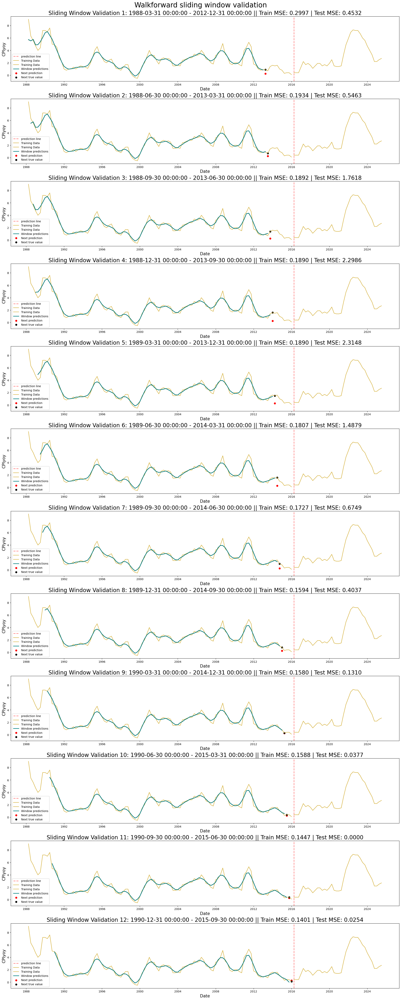

In [58]:
fig, ax = plt.subplots(nrows=12, ncols=1, figsize=(20, 50), constrained_layout=True)

for i in range(len(myXG_CV.windows_train)):
    ax[i] = validation_plot(myXG_CV, y_train, y_test, i, ax = ax[i])

plt.suptitle('Walkforward sliding window validation', size = 25)
plt.show()

### Adaptive Boost

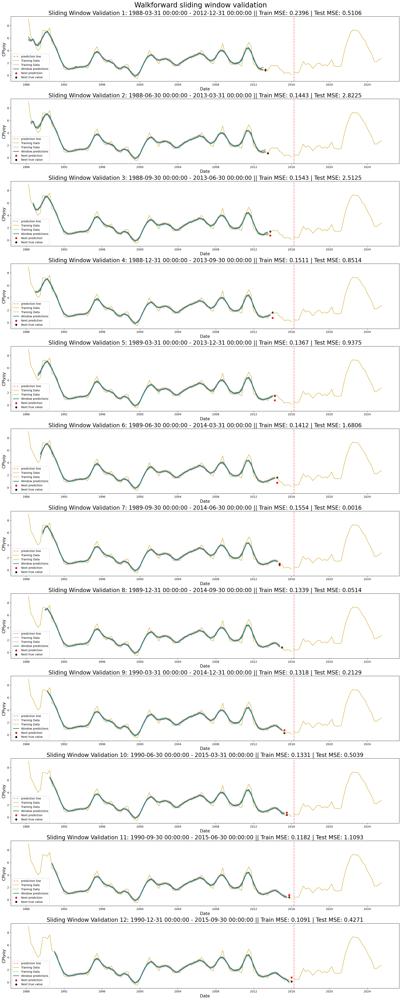

In [59]:
fig, ax = plt.subplots(nrows=12, ncols=1, figsize=(20, 50), constrained_layout=True)

for i in range(len(adaptive_CV.windows_train)):
    ax[i] = validation_plot(adaptive_CV, y_train, y_test, i, ax = ax[i])

plt.suptitle('Walkforward sliding window validation', size = 25)
plt.show()

## Task 3.4 Other models
[Back to top](#Index) | [To section head](#Task-3:-EXPERIMENTATION-USING-A-RANGE-OF-ALGORITHMS) | [To Template Section](#Task-3:-NZ-Inflation-Forecasting-Competition-Using-a-Range-of-Algorithms-(10-Marks))

Here I try out three models from the darts package for comparison with previous models. Exponential smoothing, naive forecast and regression ensemble. They models are very poor at fitting the data as they only learn from the y training set. 

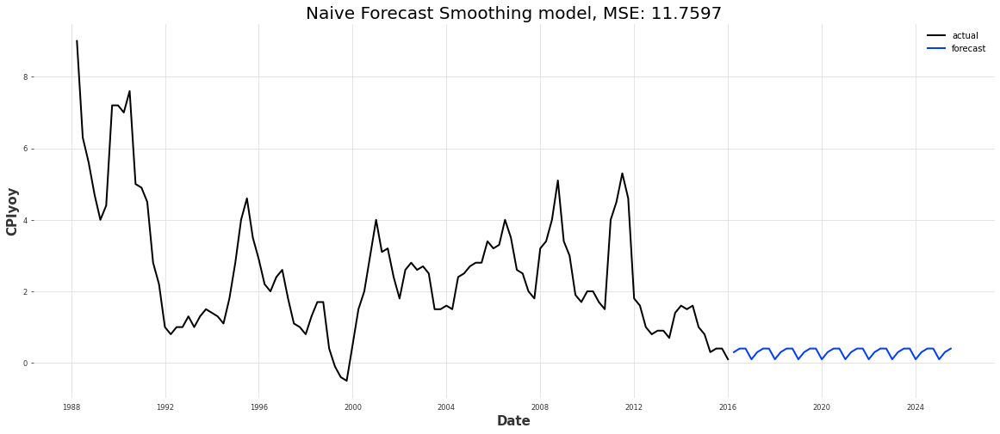

In [920]:
from darts.models import NaiveSeasonal, ExponentialSmoothing, Prophet
from darts import TimeSeries

y_data = TimeSeries.from_dataframe(y_train)
y_test_series = TimeSeries.from_dataframe(y_test)

naive_model = NaiveSeasonal(K=4)  # Initialize with seasonal period K=1
naive_model.fit(y_data)            
naive_forecast = naive_model.predict(n=38)  #38 rows in test data

nf_pred = naive_forecast.values()

plt.figure(figsize=(20, 8)) 

y_data.plot(label='actual')
naive_forecast.plot(label='forecast', low_quantile=0.05, high_quantile=0.95)
plt.title(f'Naive Forecast Smoothing model, MSE: {metrics.mean_squared_error(y_test, nf_pred):.4f}', size = 20)
plt.ylabel('CPIyoy', size =15)
plt.legend()
plt.xlabel('Date', size = 15)
plt.show()

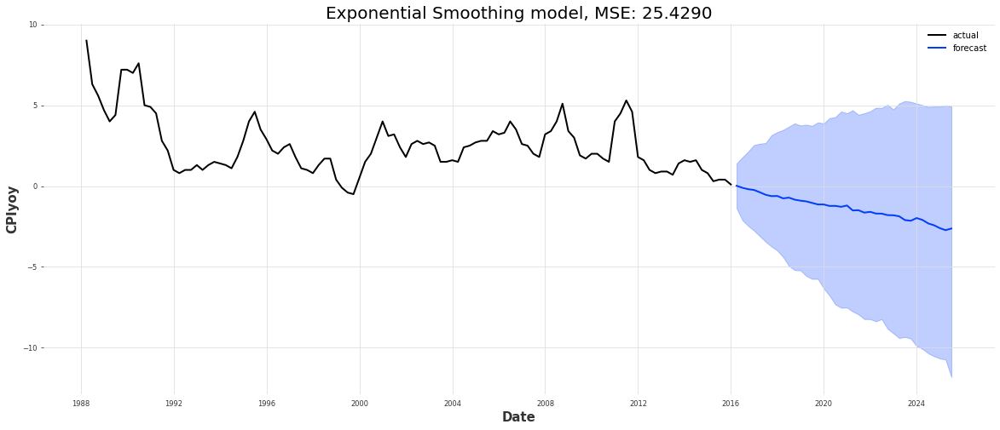

In [921]:
exp_model = ExponentialSmoothing()
exp_model.fit(y_data)

# Make a prediction for the length of the validation series
prediction = exp_model.predict(len(y_test), num_samples=500)
exp_pred = prediction.values()

plt.figure(figsize=(20, 8)) 

y_data.plot(label='actual')
prediction.plot(label='forecast', low_quantile=0.05, high_quantile=0.95)
plt.title(f'Exponential Smoothing model, MSE: {metrics.mean_squared_error(y_test, exp_pred):.4f}', size = 20)
plt.ylabel('CPIyoy', size =15)
plt.legend()
plt.xlabel('Date', size = 15)
plt.show()

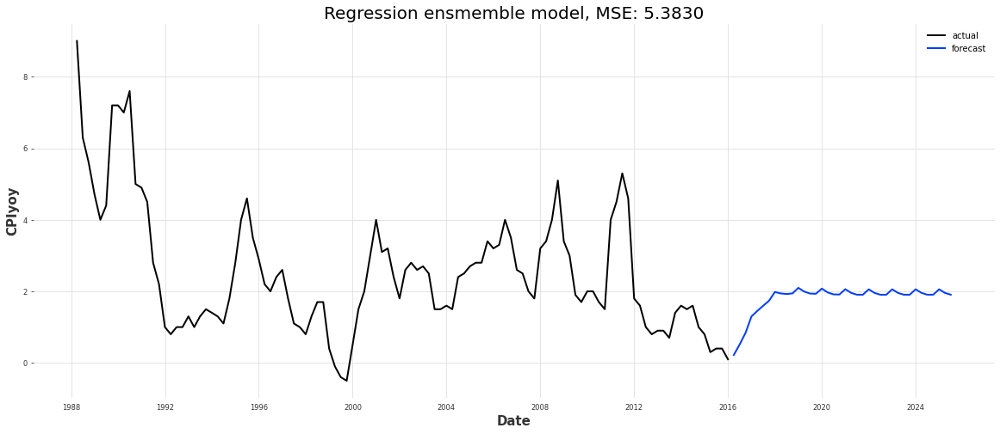

In [922]:
from darts.models import RegressionEnsembleModel, NaiveSeasonal, LinearRegressionModel

reg_model = RegressionEnsembleModel(
    forecasting_models = [
        NaiveSeasonal(K=4),
        LinearRegressionModel(lags=4)
    ],
    regression_train_n_points=20
)
reg_model.fit(y_data)
reg_pred = reg_model.predict(38)

plt.figure(figsize=(20, 8)) 

y_data.plot(label='actual')
reg_pred.plot(label='forecast', low_quantile=0.05, high_quantile=0.95)
plt.title(f'Regression ensmemble model, MSE: {metrics.mean_squared_error(y_test, reg_pred.values()):.4f}', size = 20)
plt.ylabel('CPIyoy', size =15)
plt.legend()
plt.xlabel('Date', size = 15)
plt.show()

# TASK 4: AWS TECHNOLOGY USAGE
[Back to top](#Index) | [To Template section](#Task-4:-AWS-Technology-Usage-(15-Marks))

* [4.1. Sage Maker](#Task-4.1.-Sage-Maker:)
* [4.2. S3 Bucket](#Task-4.2.-S3-Bucket:)
* [4.3. Model Hosting](#Task-4.3.-Model-Hosting:)

## Task 4.1. Sage Maker:
[Back to top](#Index) | [To section head](#TASK-4:-AWS-TECHNOLOGY-USAGE) | [To Template section](#Task-4:-AWS-Technology-Usage-(15-Marks))


Here is shown the use of sagemaker to fit and predict CPI using sklearn's gradient boost.
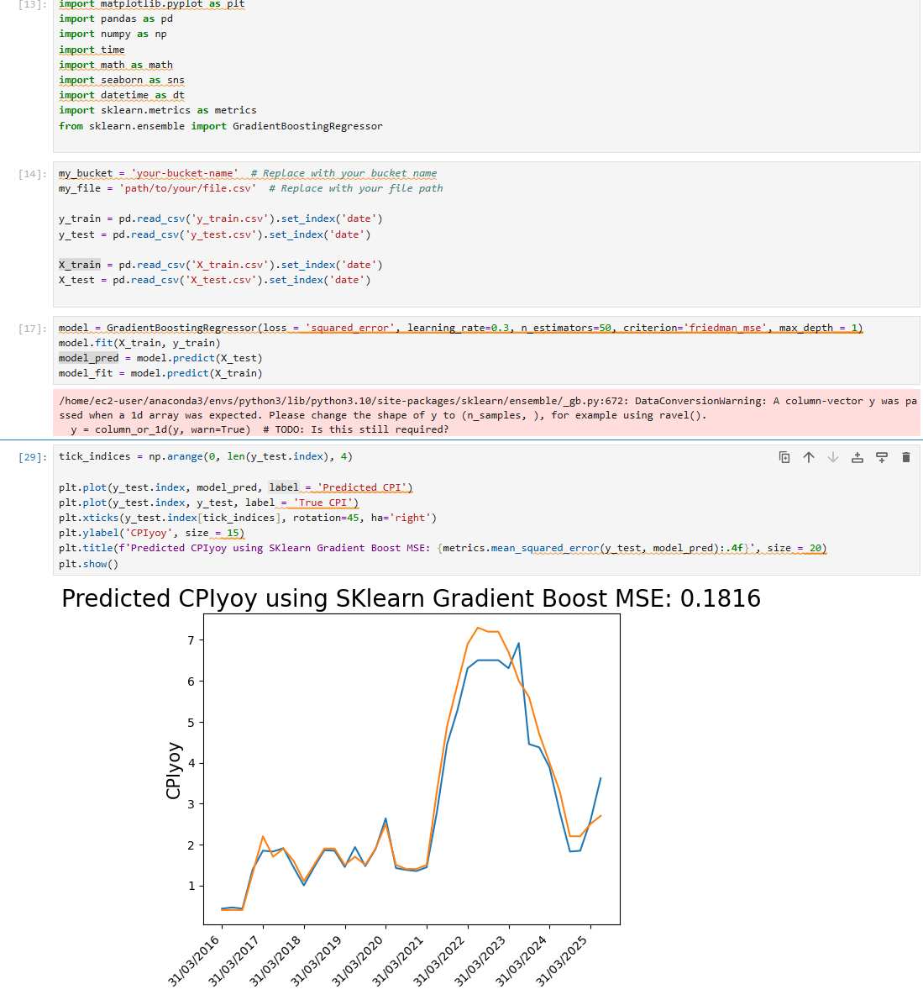

## Task 4.2. S3 Bucket:
[Back to top](#Index) | [To section head](#TASK-4:-AWS-TECHNOLOGY-USAGE) | [To Template section](#Task-4:-AWS-Technology-Usage-(15-Marks))

Here I show the use of S3 for the data.
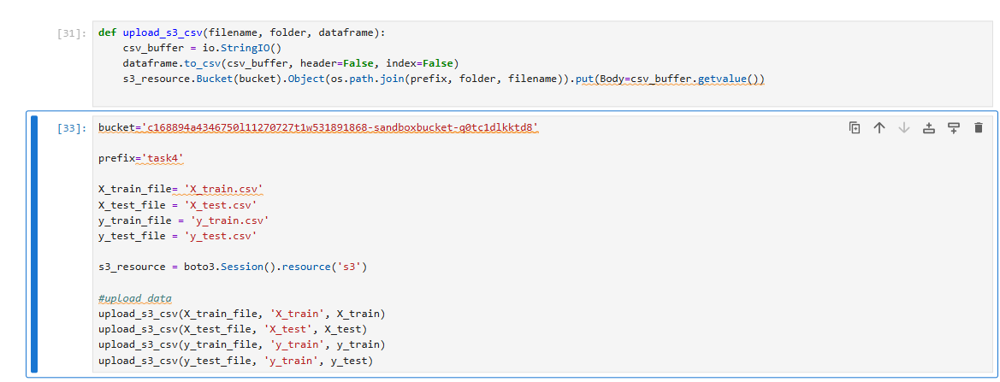

## Task 4.3. Model Hosting:
[Back to top](#Index) | [To section head](#TASK-4:-AWS-TECHNOLOGY-USAGE) | [To Template section](#Task-4:-AWS-Technology-Usage-(15-Marks))

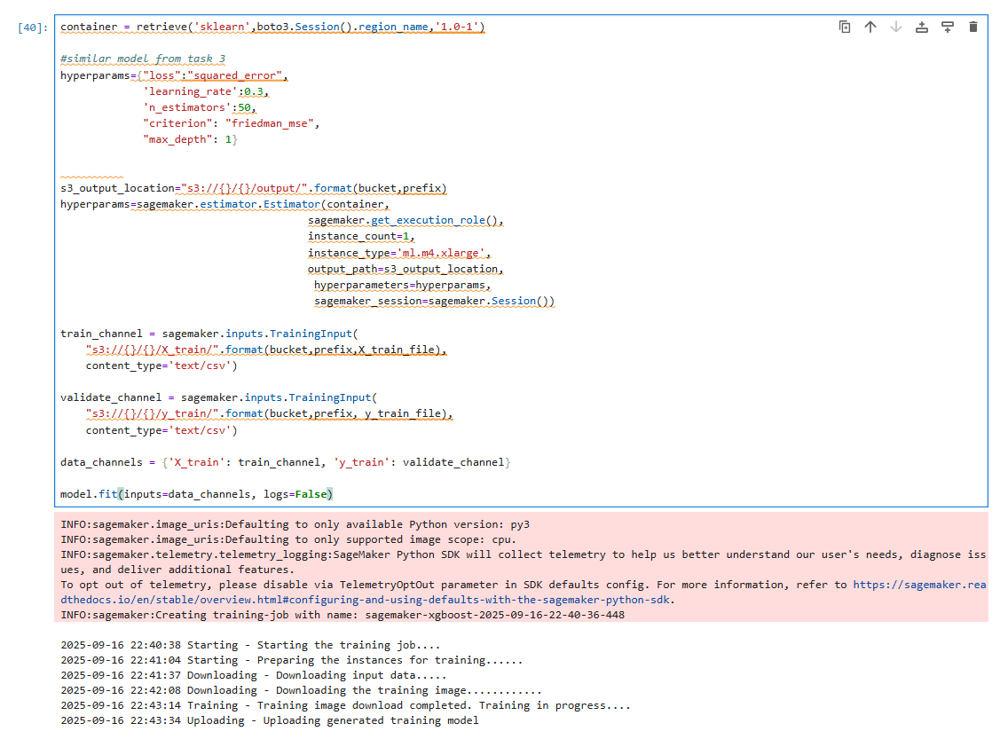

# Bibliography
[Back to top](#Index) | 

the beauty of simple models is that they assume little. By assuming little, they combine the variability caused by many processes into one single error term. This is why a simple poisson distribtion of murders and the time between them in the UK can accurately predict when murder are going to happen (The art of statistics). When we get too many features or too complex machines they are not so easily generalisable because they have far too much specific error. 
Looking at economics is similar to looking at murder (no I am not a socialist). Typically, GDP will truck along, but every now and again there is a shock. These shocks are external to the data, external to GDP. Trying to predict them off the same data set is madness. Rather, one would want to know the time between shocks. Then, estimate their size, and figure out the range of impacts. Making decisions accordingly. We see that GDP returns to form after a shock. We see this in MAE models. Perhaps this is some good research for a PhD?

using GEV or GDP or poisson dists to predict spikes in data

Bloom, T. (2021). *BetaBoost*. https://github.com/tblume1992/BetaBoost/tree/master/BetaBoost

Bowers, M. (2022, May 7). *XGBoost from Scratch*. https://randomrealizations.com/posts/xgboost-from-scratch/

Friedman, J.H. (1999). Stochastic Gradient Boosting. *Computational Statistics & Data Analysis*. 38(4), 367-378. https://www.researchgate.net/publication/222573328_Stochastic_Gradient_Boosting

Friedman, J.H. (2000). Greedy Function Approximation: A Gradient Boosting Machine. *The Annals of Statistics*. 29(5), 1189-1232. https://www.researchgate.net/publication/2424824_Greedy_Function_Approximation_A_Gradient_Boosting_Machine

Trading Economics. (2025). *New Zealand Inflation Rate*. Accessed 16/09/2025. https://tradingeconomics.com/new-zealand/inflation-cpi

Data and the data generating process are not separate. And in some types of data, there are many processes at play. Different processes result in defferent data for different reasons. And so, overfitting to some processes, as with the tree model, can lead to poor fitting to the data when another process takes the wheel. 